# Job 0 - Verificación de Fuentes RWA


In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# Flags propios del notebook
PROBAR_DEFILLAMA: bool = True
PROBAR_RWA_XYZ: bool = True
PROBAR_COINGECKO: bool = True
PROBAR_COINMETRICS: bool = True


# 2. Imports"""

import datetime
import os
import time
from typing import Any

import pandas as pd
import requests


from google.colab import drive
drive.mount('/content/drive')

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")
ARCHIVO_SALIDA: str = os.path.join(
    DIR_REPORTES, "rwa_viabilidad.csv"
)
ARCHIVO_PROTOCOLOS: str = os.path.join(


    DIR_REPORTES, "rwa_protocolos_defillama.csv"
)

TIMEOUT: int = 40
PAUSA: float = 1.5          # segundos entre requests (rate limit)
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_VERIFICACION: str = HOY
MAX_FECHA_RECIENTE: str = "2026-06-01"  # umbral mínimo de max_fecha

# --- Endpoints base ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"          # /{slug}
LLAMA_CHAIN_TVL: str = f"{LLAMA_BASE}/v2/historicalChainTvl"
LLAMA_STABLE: str = "https://stablecoins.llama.fi"
COINGECKO_BASE: str = "https://api.coingecko.com/api/v3"
CM_BASE: str = (
    "https://community-api.coinmetrics.io"
    "/v4/timeseries/asset-metrics"
)

# Candidatos de API pública de RWA.xyz (se prueban en orden).
# Si ninguno responde sin key → NO DISPONIBLE (no inventar).
RWA_XYZ_CANDIDATOS: list[str] = [
    "https://api.rwa.xyz/v1/assets",
    "https://api.rwa.xyz/assets",
    "https://app.rwa.xyz/api/assets",
    "https://www.rwa.xyz/api/assets",
]

# Categoría DeFiLlama que agrupa la tokenización de RWA
CATEGORIA_RWA: str = "RWA"

# Redes de interés del proyecto (nombres DeFiLlama)
REDES_INTERES: list[str] = [
    "Stellar",
    "XRPL",
    "Ripple",
    "Ethereum",
    "Solana",
    "Polygon",
    "Avalanche",
    "Aptos",
    "Arbitrum",
    "Algorand",
    "Hedera",
]

# Cuántos protocolos RWA (por TVL) se verifican en detalle
N_PROTOCOLOS_MUESTRA: int = 8

# Stablecoin RWA ya validada en fases previas (USDY)
USDY_STABLECOIN_ID: int = 129
CHAINS_STABLECOIN: list[str] = ["Ethereum", "Solana", "Aptos"]

# Categorías CoinGecko candidatas para RWA
CG_CATEGORIAS: list[str] = [
    "real-world-assets-rwa",
    "tokenized-treasury-bills",
    "tokenized-gold",
]

# Tokens RWA de muestra: símbolo → (pista de nombre, tipo activo)
CG_TOKENS_RWA: dict[str, tuple[str, str]] = {
    "USDY": ("ondo", "treasuries"),
    "OUSG": ("ondo", "treasuries"),
    "PAXG": ("paxos", "oro"),
    "XAUT": ("tether", "oro"),
}

# Assets RWA en CoinMetrics Community (símbolo → tipo activo)
CM_ASSETS_RWA: dict[str, str] = {
    "paxg": "oro",
    "usdy": "treasuries",
}
CM_METRICS_RWA: list[str] = ["SplyCur", "CapMrktCurUSD"]

"""# 4. Funciones"""


def probar_endpoint(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> dict[str, Any]:
    """
    Realiza una request GET real y registra el resultado.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima.

    Returns:
        Dict con claves: ok (bool), status (int|None),
        data (JSON parseado o None), error (str|None).
    """
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            try:
                data = r.json()
            except Exception:
                data = None
            return {
                "ok": True,
                "status": r.status_code,
                "data": data,
                "error": None,
            }
        return {
            "ok": False,
            "status": r.status_code,
            "data": None,
            "error": f"HTTP {r.status_code}",
        }
    except requests.Timeout:
        return {
            "ok": False, "status": None,
            "data": None, "error": "timeout",
        }
    except requests.RequestException as e:
        return {
            "ok": False, "status": None,
            "data": None, "error": str(e),
        }


def probar_fuente(
    nombre: str,
    url: str,
    params: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """
    Prueba genérica de una fuente: hace la request y describe
    de forma superficial si la respuesta parece o no una serie.

    Se usa para fuentes sin parser dedicado (exploración).

    Args:
        nombre: Nombre legible de la fuente.
        url: Endpoint a probar.
        params: Query parameters opcionales.

    Returns:
        Dict con ok, status, n_obs, min_fecha, max_fecha,
        tiene_serie_temporal, granularidad, error.
    """
    if DEBUG:
        print(f"[DEBUG] probar_fuente: {nombre} -> {url}")
    res = probar_endpoint(url, params)
    salida: dict[str, Any] = {
        "nombre": nombre,
        "ok": res["ok"],
        "status": res["status"],
        "n_obs": 0,
        "min_fecha": "s/d",
        "max_fecha": "s/d",
        "tiene_serie_temporal": False,
        "granularidad": "s/d",
        "error": res["error"],
    }
    if not res["ok"]:
        return salida
    data = res.get("data")
    fechas = _extraer_fechas(data)
    salida["n_obs"] = len(fechas)
    if fechas:
        fechas_ord = sorted(fechas)
        salida["min_fecha"], salida["max_fecha"] = _rango_fechas(
            fechas_ord
        )
        salida["tiene_serie_temporal"] = len(fechas_ord) > 1
        salida["granularidad"] = _inferir_granularidad(fechas_ord)
    else:
        salida["granularidad"] = "puntual (sin serie)"
    return salida


def _extraer_fechas(data: Any) -> list[str]:
    """
    Busca en una respuesta JSON una lista de observaciones con
    campo de fecha y devuelve esas fechas en ISO.

    Reconoce claves 'date', 'time', 'timestamp' y valores
    epoch (int/str numérico) o fecha ISO.

    Args:
        data: JSON ya parseado.

    Returns:
        Lista de fechas ISO (YYYY-MM-DD); vacía si no aplica.
    """
    candidatos: list[Any] = []
    if isinstance(data, list):
        candidatos = data
    elif isinstance(data, dict):
        for clave in ("data", "results", "chart", "chart_data",
                      "items", "series"):
            valor = data.get(clave)
            if isinstance(valor, list) and valor:
                candidatos = valor
                break
    fechas: list[str] = []
    for obs in candidatos:
        if not isinstance(obs, dict):
            continue
        for clave in ("date", "time", "timestamp"):
            if clave in obs:
                fecha = _a_fecha_iso(obs[clave])
                if fecha:
                    fechas.append(fecha)
                break
    return fechas


def _a_fecha_iso(valor: Any) -> str | None:
    """
    Normaliza un valor de fecha (epoch seg/ms o string ISO) a
    fecha ISO YYYY-MM-DD.

    Args:
        valor: Epoch numérico o cadena de fecha.

    Returns:
        Fecha ISO o None si no se pudo interpretar.
    """
    try:
        if isinstance(valor, (int, float)):
            segundos = float(valor)
            if segundos > 1e11:      # epoch en milisegundos
                segundos = segundos / 1000.0
            return datetime.datetime.utcfromtimestamp(
                segundos
            ).date().isoformat()
        if isinstance(valor, str):
            if valor.isdigit():
                return _a_fecha_iso(int(valor))
            return valor[:10]
    except Exception:
        return None
    return None


def _rango_fechas(fechas: list[str]) -> tuple[str, str]:
    """Extrae min y max de una lista de fechas ISO (YYYY-MM-DD)."""
    validas = sorted(f for f in fechas if f and f != "nan")
    if not validas:
        return "s/d", "s/d"
    return validas[0], validas[-1]


def _inferir_granularidad(fechas: list[str]) -> str:
    """
    Infiere la granularidad de una serie por el espaciado modal
    entre observaciones consecutivas.

    Args:
        fechas: Fechas ISO ordenadas ascendentemente.

    Returns:
        "diaria" | "semanal" | "mensual" | "cada N días" |
        "puntual (sin serie)" | "desconocida"
    """
    if len(fechas) < 2:
        return "puntual (sin serie)"
    diffs: list[int] = []
    for anterior, actual in zip(fechas, fechas[1:]):
        try:
            d1 = datetime.date.fromisoformat(anterior)
            d2 = datetime.date.fromisoformat(actual)
        except Exception:
            continue
        delta = abs((d2 - d1).days)
        if delta > 0:
            diffs.append(delta)
    if not diffs:
        return "desconocida"
    modal = max(set(diffs), key=diffs.count)
    if modal == 1:
        return "diaria"
    if modal == 7:
        return "semanal"
    if 28 <= modal <= 31:
        return "mensual"
    return f"cada {modal} días"


def registro_estandar(
    fuente: str,
    endpoint: str,
    ok: bool,
    red: str = "TODAS",
    tipo_activo: str = "TODOS",
    desglose_red: bool = False,
    desglose_tipo: bool = False,
    granularidad: str = "s/d",
    min_fecha: str = "s/d",
    max_fecha: str = "s/d",
    n_obs: int = 0,
    motivo: str = "",
) -> dict[str, Any]:
    """
    Construye un registro de verificación en formato estándar.

    Args:
        fuente: Nombre de la fuente/serie verificada.
        endpoint: URL efectivamente probada.
        ok: Si la API respondió con datos utilizables.
        red: Red/chain de la fila ("TODAS" si es agregado,
            "N/D" si la fuente no desagrega).
        tipo_activo: Tipo de activo RWA de la fila.
        desglose_red: Si la fuente permite desagregar por red.
        desglose_tipo: Si permite desagregar por tipo de activo.
        granularidad: Granularidad observada de la serie.
        min_fecha: Primera fecha observada (ISO).
        max_fecha: Última fecha observada (ISO).
        n_obs: Número de observaciones.
        motivo: Evidencia o motivo de la limitación.

    Returns:
        Dict con el registro estándar.
    """
    return {
        "fuente": fuente,
        "red": red,
        "tipo_activo": tipo_activo,
        "endpoint": endpoint,
        "ok": ok,
        "desglose_red": desglose_red,
        "desglose_tipo": desglose_tipo,
        "granularidad": granularidad,
        "min_fecha": min_fecha,
        "max_fecha": max_fecha,
        "n_obs": n_obs,
        "motivo": motivo,
        "fecha_verificacion": FECHA_VERIFICACION,
    }


# ── DeFiLlama ─────────────────────────────────────────────────────


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama con su
    TVL actual, chains y tags (tipo de activo declarado).

    Returns:
        DataFrame con columnas: slug, name, category, tags,
        chains, tvl, n_chains. Vacío si el endpoint falla.
    """
    if DEBUG:
        print(f"[DEBUG] DeFiLlama /protocols (categoría "
              f"'{CATEGORIA_RWA}') ...")
    res = probar_endpoint(LLAMA_PROTOCOLS)
    if not res["ok"] or not isinstance(res.get("data"), list):
        if DEBUG:
            print(f"[DEBUG]   falló /protocols: {res['error']}")
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    for proto in res["data"]:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        chains = proto.get("chains") or []
        tags = proto.get("tags") or []
        filas.append({
            "slug": proto.get("slug", ""),
            "name": proto.get("name", ""),
            "category": proto.get("category", ""),
            "tags": ",".join(str(t) for t in tags),
            "chains": ",".join(str(c) for c in chains),
            "n_chains": len(chains),
            "tvl": proto.get("tvl") or 0.0,
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl", ascending=False)
        df = df.reset_index(drop=True)
    return df


def serie_tvl_protocolo(slug: str) -> dict[str, Any]:
    """
    Trae la serie histórica de TVL de un protocolo DeFiLlama,
    desglosada por chain.

    Args:
        slug: Slug del protocolo (ej. "blackrock-buidl").

    Returns:
        Dict con claves: ok (bool), endpoint (str),
        error (str|None), tags (list[str]),
        series (dict chain → dict fecha_iso → usd).
    """
    url = f"{LLAMA_PROTOCOL}/{slug}"
    res = probar_endpoint(url)
    salida: dict[str, Any] = {
        "ok": False,
        "endpoint": url,
        "error": res["error"],
        "tags": [],
        "series": {},
    }
    if not res["ok"] or not isinstance(res.get("data"), dict):
        return salida
    data: dict[str, Any] = res["data"]
    salida["tags"] = [
        str(t) for t in (data.get("tags") or [])
    ]
    chain_tvls = data.get("chainTvls") or {}
    if not isinstance(chain_tvls, dict):
        return salida
    series: dict[str, dict[str, float]] = {}
    for chain, contenido in chain_tvls.items():
        # Se excluyen agregados derivados (borrowed, staking, ...)
        if "-" in str(chain):
            continue
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl") or []
        if not isinstance(observaciones, list):
            continue
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha_iso(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            # Si hay más de una obs por día, queda la última
            por_fecha[fecha] = float(valor)
        if por_fecha:
            series[str(chain)] = por_fecha
    salida["series"] = series
    salida["ok"] = bool(series)
    return salida


def verificar_protocolo_rwa(
    slug: str,
    nombre: str,
    tags: str,
) -> list[dict[str, Any]]:
    """
    Verifica la serie histórica de TVL por chain de un protocolo
    RWA concreto: una fila por (protocolo, chain).

    Args:
        slug: Slug del protocolo en DeFiLlama.
        nombre: Nombre legible del protocolo.
        tags: Tags declarados (tipo de activo), separados por coma.

    Returns:
        Lista de registros estándar (una por chain con datos).
    """
    fuente = f"DeFiLlama/protocolo/{nombre}"
    if DEBUG:
        print(f"[DEBUG] {fuente} (slug={slug}) ...")
    resultado = serie_tvl_protocolo(slug)
    tipo = tags or "s/d"
    if not resultado["ok"]:
        motivo = (
            f"sin serie por chain: {resultado['error'] or 'chainTvls vacío'}"
        )
        return [registro_estandar(
            fuente=fuente, endpoint=resultado["endpoint"],
            ok=False, red="N/D", tipo_activo=tipo,
            motivo=motivo,
        )]
    registros: list[dict[str, Any]] = []
    for chain, por_fecha in resultado["series"].items():
        fechas = sorted(por_fecha.keys())
        min_f, max_f = _rango_fechas(fechas)
        registros.append(registro_estandar(
            fuente=fuente,
            endpoint=resultado["endpoint"],
            ok=True,
            red=chain,
            tipo_activo=tipo,
            desglose_red=True,
            desglose_tipo=bool(resultado["tags"]),
            granularidad=_inferir_granularidad(fechas),
            min_fecha=min_f, max_fecha=max_f,
            n_obs=len(fechas),
            motivo=(
                "chainTvls[chain].tvl: serie de "
                "totalLiquidityUSD"
            ),
        ))
    return registros


def agregar_series_por_chain(
    series_protocolos: list[tuple[str, dict[str, dict[str, float]]]],
) -> dict[str, dict[str, float]]:
    """
    Suma las series de TVL de varios protocolos RWA por chain,
    para construir la señal agregada "valor RWA tokenizado por red".

    Args:
        series_protocolos: Lista de (nombre_protocolo, series),
            donde series es dict chain → dict fecha → usd.

    Returns:
        Dict chain → dict fecha_iso → usd agregado.
    """
    agregado: dict[str, dict[str, float]] = {}
    for _, series in series_protocolos:
        for chain, por_fecha in series.items():
            destino = agregado.setdefault(chain, {})
            for fecha, valor in por_fecha.items():
                destino[fecha] = destino.get(fecha, 0.0) + valor
    return agregado


def agregar_series_por_tipo(
    series_por_tipo: list[tuple[str, dict[str, dict[str, float]]]],
) -> dict[str, dict[str, float]]:
    """
    Suma las series de TVL de varios protocolos RWA por tipo de
    activo (tag declarado en DeFiLlama), agregando todas sus chains.

    Args:
        series_por_tipo: Lista de (tipo_activo, series), donde
            series es dict chain → dict fecha → usd.

    Returns:
        Dict tipo_activo → dict fecha_iso → usd agregado.
    """
    agregado: dict[str, dict[str, float]] = {}
    for tipo, series in series_por_tipo:
        destino = agregado.setdefault(tipo or "s/d", {})
        for _, por_fecha in series.items():
            for fecha, valor in por_fecha.items():
                destino[fecha] = destino.get(fecha, 0.0) + valor
    return agregado


def registros_desde_agregado(
    fuente: str,
    endpoint: str,
    agregado: dict[str, dict[str, float]],
    dimension: str,
    motivo: str,
) -> list[dict[str, Any]]:
    """
    Convierte un agregado (clave → serie) en registros estándar.

    Args:
        fuente: Nombre de la fuente/serie agregada.
        endpoint: Endpoint del que provienen los datos.
        agregado: Dict clave → dict fecha_iso → valor.
        dimension: "red" o "tipo"; define en qué columna va la
            clave del agregado.
        motivo: Evidencia asociada a la construcción.

    Returns:
        Lista de registros estándar, uno por clave.
    """
    registros: list[dict[str, Any]] = []
    for clave, por_fecha in agregado.items():
        fechas = sorted(por_fecha.keys())
        min_f, max_f = _rango_fechas(fechas)
        registros.append(registro_estandar(
            fuente=fuente,
            endpoint=endpoint,
            ok=bool(fechas),
            red=clave if dimension == "red" else "TODAS",
            tipo_activo=clave if dimension == "tipo" else "TODOS",
            desglose_red=(dimension == "red"),
            desglose_tipo=(dimension == "tipo"),
            granularidad=_inferir_granularidad(fechas),
            min_fecha=min_f, max_fecha=max_f,
            n_obs=len(fechas),
            motivo=motivo,
        ))
    return registros


def verificar_llama_chain_tvl(chain: str) -> dict[str, Any]:
    """
    Verifica el TVL histórico total de una chain en DeFiLlama.

    Es TVL DeFi total, NO específico de RWA: sirve como
    denominador/contexto, no como señal de tokenización.

    Args:
        chain: Nombre de la chain en DeFiLlama (ej. "Stellar").

    Returns:
        Registro estándar.
    """
    url = f"{LLAMA_CHAIN_TVL}/{chain}"
    fuente = f"DeFiLlama/chainTVL/{chain}"
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    res = probar_endpoint(url)
    if not res["ok"] or not isinstance(res.get("data"), list):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="N/D",
            motivo=f"endpoint error: {res['error']}",
        )
    fechas = sorted(
        f for f in (
            _a_fecha_iso(o.get("date"))
            for o in res["data"] if isinstance(o, dict)
        ) if f
    )
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="N/D", motivo="respuesta sin fechas",
        )
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True, red=chain,
        tipo_activo="N/D",
        desglose_red=True, desglose_tipo=False,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            "TVL DeFi total de la chain (contexto/denominador); "
            "NO es específico de RWA"
        ),
    )


def verificar_stablecoin_rwa_por_chain(
    stablecoin_id: int,
    chain: str,
    etiqueta: str,
) -> dict[str, Any]:
    """
    Verifica la serie diaria de circulación de una stablecoin RWA
    en una chain (endpoint ya validado en fases previas).

    Args:
        stablecoin_id: Id de la stablecoin en DeFiLlama.
        chain: Chain a consultar (ej. "Ethereum").
        etiqueta: Nombre legible del token (ej. "USDY").

    Returns:
        Registro estándar.
    """
    url = f"{LLAMA_STABLE}/stablecoincharts/{chain}"
    params: dict[str, Any] = {"stablecoin": stablecoin_id}
    fuente = f"DeFiLlama/stablecoin/{etiqueta}"
    if DEBUG:
        print(f"[DEBUG] {fuente} en {chain} ...")
    res = probar_endpoint(url, params)
    if not res["ok"] or not isinstance(res.get("data"), list):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="treasuries",
            motivo=f"endpoint error: {res['error']}",
        )
    fechas: list[str] = []
    for obs in res["data"]:
        if not isinstance(obs, dict):
            continue
        fecha = _a_fecha_iso(obs.get("date"))
        if fecha:
            fechas.append(fecha)
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red=chain,
            tipo_activo="treasuries",
            motivo="sin observaciones para esa chain/stablecoin",
        )
    fechas = sorted(fechas)
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True, red=chain,
        tipo_activo="treasuries",
        desglose_red=True, desglose_tipo=True,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            f"stablecoincharts/{chain}?stablecoin="
            f"{stablecoin_id}: circulación diaria"
        ),
    )


# ── RWA.xyz ───────────────────────────────────────────────────────


def verificar_rwa_xyz() -> dict[str, Any]:
    """
    Prueba los candidatos de API pública de RWA.xyz.

    Si ninguno responde 200 con datos (típicamente requiere key
    o no expone API abierta), se registra NO DISPONIBLE con el
    detalle de lo probado. No se inventan endpoints.

    Returns:
        Registro estándar.
    """
    fuente = "RWA.xyz"
    intentos: list[str] = []
    for url in RWA_XYZ_CANDIDATOS:
        prueba = probar_fuente(fuente, url)
        intentos.append(
            f"{url} → {prueba['status'] or prueba['error']}"
        )
        if prueba["ok"] and prueba["n_obs"] > 0:
            return registro_estandar(
                fuente=fuente, endpoint=url, ok=True,
                red="N/D", tipo_activo="N/D",
                desglose_red=False, desglose_tipo=False,
                granularidad=prueba["granularidad"],
                min_fecha=prueba["min_fecha"],
                max_fecha=prueba["max_fecha"],
                n_obs=prueba["n_obs"],
                motivo=(
                    "respondió con datos; revisar manualmente "
                    "el esquema para desgloses"
                ),
            )
        time.sleep(PAUSA)
    return registro_estandar(
        fuente=fuente, endpoint=RWA_XYZ_CANDIDATOS[0], ok=False,
        red="N/D", tipo_activo="N/D",
        motivo=(
            "sin API pública accesible sin key. Probados: "
            + " | ".join(intentos)
        ),
    )


# ── CoinGecko ─────────────────────────────────────────────────────


def verificar_coingecko_categorias() -> list[dict[str, Any]]:
    """
    Verifica el market cap por categoría RWA en CoinGecko.

    /coins/categories devuelve un SNAPSHOT (market cap actual),
    sin historia: se registra explícitamente como tal.

    Returns:
        Lista de registros estándar (uno por categoría buscada).
    """
    url = f"{COINGECKO_BASE}/coins/categories"
    if DEBUG:
        print("[DEBUG] CoinGecko /coins/categories ...")
    res = probar_endpoint(url)
    registros: list[dict[str, Any]] = []
    if not res["ok"] or not isinstance(res.get("data"), list):
        for categoria in CG_CATEGORIAS:
            registros.append(registro_estandar(
                fuente=f"CoinGecko/categoria/{categoria}",
                endpoint=url, ok=False, red="N/D",
                tipo_activo=categoria,
                motivo=f"endpoint error: {res['error']}",
            ))
        return registros
    por_id: dict[str, dict[str, Any]] = {
        str(c.get("id", "")): c
        for c in res["data"] if isinstance(c, dict)
    }
    for categoria in CG_CATEGORIAS:
        info = por_id.get(categoria)
        if info is None:
            registros.append(registro_estandar(
                fuente=f"CoinGecko/categoria/{categoria}",
                endpoint=url, ok=False, red="N/D",
                tipo_activo=categoria,
                motivo="categoría inexistente en la respuesta",
            ))
            continue
        mcap = info.get("market_cap")
        registros.append(registro_estandar(
            fuente=f"CoinGecko/categoria/{categoria}",
            endpoint=url, ok=True, red="N/D",
            tipo_activo=categoria,
            desglose_red=False, desglose_tipo=True,
            granularidad="puntual (sin serie)",
            n_obs=1,
            motivo=(
                f"SNAPSHOT: market_cap actual = {mcap}; "
                "sin historia por API"
            ),
        ))
    return registros


def _buscar_coingecko_id(
    simbolo: str,
    nombre_pista: str = "",
) -> str | None:
    """
    Busca el id canónico de CoinGecko para un símbolo.

    Args:
        simbolo: Símbolo exacto (ej. "OUSG").
        nombre_pista: Keyword del nombre para desambiguar.

    Returns:
        El id (str) o None si no se encontró.
    """
    url = f"{COINGECKO_BASE}/search"
    res = probar_endpoint(url, {"query": simbolo})
    if not res["ok"]:
        return None
    coins: list[dict] = (res.get("data") or {}).get("coins", [])
    s_up = simbolo.upper()
    candidatos = [
        c for c in coins
        if str(c.get("symbol", "")).upper() == s_up
    ]
    if not candidatos:
        return None
    if len(candidatos) == 1 or not nombre_pista:
        return str(candidatos[0].get("id", ""))
    pista = nombre_pista.lower()
    filtrados = [
        c for c in candidatos
        if pista in str(c.get("name", "")).lower()
    ]
    return str((filtrados or candidatos)[0].get("id", ""))


def verificar_coingecko_token_rwa(
    simbolo: str,
    nombre_pista: str,
    tipo_activo: str,
) -> dict[str, Any]:
    """
    Verifica la serie histórica de market cap de un token RWA en
    CoinGecko (proxy del valor tokenizado, agregado entre redes).

    Args:
        simbolo: Símbolo del token (ej. "PAXG").
        nombre_pista: Keyword del emisor para desambiguar.
        tipo_activo: Tipo de activo subyacente (ej. "oro").

    Returns:
        Registro estándar.
    """
    fuente = f"CoinGecko/token/{simbolo}"
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    cg_id = _buscar_coingecko_id(simbolo, nombre_pista)
    if not cg_id:
        return registro_estandar(
            fuente=fuente, endpoint=f"{COINGECKO_BASE}/search",
            ok=False, red="N/D", tipo_activo=tipo_activo,
            motivo=f"no se encontró id para símbolo {simbolo}",
        )
    time.sleep(PAUSA)
    url = f"{COINGECKO_BASE}/coins/{cg_id}/market_chart"
    params: dict[str, Any] = {
        "vs_currency": "usd",
        "days": "365",
        "interval": "daily",
    }
    res = probar_endpoint(url, params)
    if not res["ok"] or not isinstance(res.get("data"), dict):
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red="N/D",
            tipo_activo=tipo_activo,
            motivo=f"market_chart error: {res['error']}",
        )
    puntos = res["data"].get("market_caps") or []
    fechas: list[str] = []
    for punto in puntos:
        if isinstance(punto, list) and punto:
            fecha = _a_fecha_iso(punto[0])
            if fecha:
                fechas.append(fecha)
    if not fechas:
        return registro_estandar(
            fuente=fuente, endpoint=url, ok=False, red="N/D",
            tipo_activo=tipo_activo,
            motivo="market_caps vacío",
        )
    fechas = sorted(fechas)
    min_f, max_f = _rango_fechas(fechas)
    return registro_estandar(
        fuente=fuente, endpoint=url, ok=True,
        red="N/D", tipo_activo=tipo_activo,
        desglose_red=False, desglose_tipo=True,
        granularidad=_inferir_granularidad(fechas),
        min_fecha=min_f, max_fecha=max_f, n_obs=len(fechas),
        motivo=(
            f"id={cg_id}; market_cap diario agregado entre redes "
            "(no desagrega por chain)"
        ),
    )


# ── CoinMetrics ───────────────────────────────────────────────────


def verificar_coinmetrics_rwa(
    asset: str,
    tipo_activo: str,
) -> dict[str, Any]:
    """
    Verifica si CoinMetrics Community expone supply / market cap
    diario de un token RWA.

    Args:
        asset: Símbolo del asset en CoinMetrics (ej. "paxg").
        tipo_activo: Tipo de activo subyacente.

    Returns:
        Registro estándar.
    """
    fuente = f"CoinMetrics/{asset.upper()}"
    params: dict[str, Any] = {
        "assets": asset,
        "metrics": ",".join(CM_METRICS_RWA),
        "frequency": "1d",
        "start_time": VENTANA_INICIO,
        "end_time": HOY,
        "page_size": 5000,
    }
    if DEBUG:
        print(f"[DEBUG] {fuente} ...")
    res = probar_endpoint(CM_BASE, params)
    if not res["ok"]:
        return registro_estandar(
            fuente=fuente, endpoint=CM_BASE, ok=False,
            red="N/D", tipo_activo=tipo_activo,
            motivo=f"endpoint error: {res['error']}",
        )
    observaciones: list[dict] = (
        (res.get("data") or {}).get("data", [])
    )
    if not observaciones:
        return registro_estandar(
            fuente=fuente, endpoint=CM_BASE, ok=False,
            red="N/D", tipo_activo=tipo_activo,
            motivo=(
                "sin datos para el asset/métricas en la ventana "
                "(asset posiblemente fuera de Community API)"
            ),
        )
    fechas = sorted(
        str(o.get("time", ""))[:10] for o in observaciones
    )
    min_f, max_f = _rango_fechas(fechas)
    metricas_con_datos = [
        m for m in CM_METRICS_RWA
        if any(o.get(m) not in (None, "") for o in observaciones)
    ]
    return registro_estandar(
        fuente=fuente, endpoint=CM_BASE, ok=True,
        red="N/D", tipo_activo=tipo_activo,
        desglose_red=False, desglose_tipo=True,
        granularidad="diaria",
        min_fecha=min_f, max_fecha=max_f,
        n_obs=len(observaciones),
        motivo=(
            "métricas con datos: "
            f"{','.join(metricas_con_datos) or 'ninguna'}"
        ),
    )


# ── Matriz de viabilidad ──────────────────────────────────────────


def construir_matriz_viabilidad(
    registros: list[dict[str, Any]],
) -> pd.DataFrame:
    """
    Construye el DataFrame de viabilidad con criterios V1..V5 y
    veredicto por fila (fuente × red × tipo de activo).

    Criterios:
        V1_tiene_api     : la API responde y devuelve datos.
        V2_desglose_red  : desagrega por red/chain.
        V3_desglose_tipo : desagrega por tipo de activo.
        V4_serie_temporal: hay historia con frecuencia regular
                           ≤ mensual (alineable a diaria).
        V5_cobertura     : min_fecha <= VENTANA_INICIO y
                           max_fecha >= MAX_FECHA_RECIENTE.

    Veredicto:
        ENTRA         : V1 ∧ V4 ∧ V5 ∧ (V2 ∨ V3)
        ENTRA_PARCIAL : V1 ∧ V4 ∧ V5 ∧ ¬V2 ∧ ¬V3
        NO ENTRA      : V1 pero falla V4 o V5
        NO DISPONIBLE : ¬V1

    Args:
        registros: Lista de registros estándar.

    Returns:
        DataFrame con una fila por registro.
    """
    frecuencias_ok: set[str] = {"diaria", "semanal", "mensual"}
    filas: list[dict[str, Any]] = []
    for reg in registros:
        v1: bool = bool(reg["ok"])
        gran: str = str(reg.get("granularidad", ""))
        v2: bool = bool(reg.get("desglose_red", False))
        v3: bool = bool(reg.get("desglose_tipo", False))
        v4: bool = gran in frecuencias_ok and int(
            reg.get("n_obs", 0)
        ) > 1
        min_ok = (
            reg.get("min_fecha") not in ("s/d", "", None)
            and str(reg["min_fecha"]) <= VENTANA_INICIO
        )
        max_ok = (
            reg.get("max_fecha") not in ("s/d", "", None)
            and str(reg["max_fecha"]) >= MAX_FECHA_RECIENTE
        )
        v5: bool = bool(min_ok and max_ok)

        razones: list[str] = []
        if not v1:
            veredicto = "NO DISPONIBLE"
        elif v4 and v5:
            veredicto = "ENTRA" if (v2 or v3) else "ENTRA_PARCIAL"
            if veredicto == "ENTRA_PARCIAL":
                razones.append("sin desglose por red ni por tipo")
        else:
            veredicto = "NO ENTRA"
            if not v4:
                razones.append(
                    f"granularidad '{gran}': no es serie "
                    "temporal alineable a diaria"
                )
            if not min_ok:
                razones.append(
                    f"min_fecha '{reg.get('min_fecha')}' "
                    f"> {VENTANA_INICIO}"
                )
            if not max_ok:
                razones.append(
                    f"max_fecha '{reg.get('max_fecha')}' "
                    f"< {MAX_FECHA_RECIENTE}"
                )
        motivo_final = " | ".join(
            filter(None, [str(reg.get("motivo", ""))]
                   + razones)
        )
        filas.append({
            "fuente": reg["fuente"],
            "red": reg.get("red", "N/D"),
            "tipo_activo": reg.get("tipo_activo", "N/D"),
            "V1_tiene_api": v1,
            "V2_desglose_red": v2,
            "V3_desglose_tipo": v3,
            "V4_serie_temporal": v4,
            "V5_cobertura": v5,
            "veredicto": veredicto,
            "endpoint": reg["endpoint"],
            "granularidad": gran,
            "min_fecha": reg.get("min_fecha", "s/d"),
            "max_fecha": reg.get("max_fecha", "s/d"),
            "n_obs": reg.get("n_obs", 0),
            "motivo": motivo_final,
            "fecha_verificacion": reg["fecha_verificacion"],
        })
    return pd.DataFrame(filas)


def registro_de_excepcion(
    fuente: str,
    endpoint: str,
    error: Exception,
) -> dict[str, Any]:
    """
    Envuelve una excepción inesperada como registro NO DISPONIBLE.

    Args:
        fuente: Nombre de la fuente que falló.
        endpoint: Endpoint asociado.
        error: Excepción capturada.

    Returns:
        Registro estándar con ok=False.
    """
    return registro_estandar(
        fuente=fuente, endpoint=endpoint, ok=False,
        red="N/D", tipo_activo="N/D",
        motivo=f"excepción inesperada: {error}",
    )


"""# 5. Proceso"""

resultados: list[dict[str, Any]] = []
protocolos_rwa: pd.DataFrame = pd.DataFrame()

# ── 5.a DeFiLlama: catálogo de protocolos RWA ─────────────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.a Protocolos RWA en DeFiLlama ===")
    try:
        protocolos_rwa = listar_protocolos_rwa()
    except Exception as _e:
        protocolos_rwa = pd.DataFrame()
        resultados.append(registro_de_excepcion(
            "DeFiLlama/protocols", LLAMA_PROTOCOLS, _e
        ))
    if protocolos_rwa.empty:
        resultados.append(registro_estandar(
            fuente="DeFiLlama/protocols",
            endpoint=LLAMA_PROTOCOLS, ok=False,
            motivo=(
                "no se pudo listar protocolos de categoría "
                f"'{CATEGORIA_RWA}'"
            ),
        ))
    elif DEBUG:
        print(
            f"[DEBUG] protocolos RWA hallados: "
            f"{len(protocolos_rwa)}"
        )
        print(
            protocolos_rwa[
                ["name", "tags", "n_chains", "tvl"]
            ].head(15).to_string(index=False)
        )
        _redes = sorted({
            c for fila in protocolos_rwa["chains"]
            for c in str(fila).split(",") if c
        })
        print(f"[DEBUG] chains presentes en RWA: {len(_redes)}")
        print(f"[DEBUG] {', '.join(_redes)}")
        _tags = sorted({
            t for fila in protocolos_rwa["tags"]
            for t in str(fila).split(",") if t
        })
        print(f"[DEBUG] tags (tipos de activo): {', '.join(_tags)}")
        _interes = [
            r for r in REDES_INTERES if r in _redes
        ]
        print(f"[DEBUG] redes de interés cubiertas: {_interes}")

# ── 5.b Series históricas por chain de los mayores RWA ────────────

series_muestra: list[tuple[str, dict[str, dict[str, float]]]] = []
series_con_tipo: list[tuple[str, dict[str, dict[str, float]]]] = []

if PROBAR_DEFILLAMA and not protocolos_rwa.empty:
    if DEBUG:
        print(
            "\n[DEBUG] === 5.b Series históricas por chain "
            f"(muestra de {N_PROTOCOLOS_MUESTRA}) ==="
        )
    muestra = protocolos_rwa.head(N_PROTOCOLOS_MUESTRA)
    for _, _fila in muestra.iterrows():
        _slug = str(_fila["slug"])
        _nombre = str(_fila["name"])
        _tags = str(_fila["tags"])
        try:
            resultados.extend(
                verificar_protocolo_rwa(_slug, _nombre, _tags)
            )
            _detalle = serie_tvl_protocolo(_slug)
            if _detalle["ok"]:
                series_muestra.append((_nombre, _detalle["series"]))
                series_con_tipo.append((_tags, _detalle["series"]))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"DeFiLlama/protocolo/{_nombre}",
                f"{LLAMA_PROTOCOL}/{_slug}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.c Agregados RWA por red y por tipo de activo ────────────────

if series_muestra:
    if DEBUG:
        print("\n[DEBUG] === 5.c Agregados RWA por red y tipo ===")
    try:
        _agg_red = agregar_series_por_chain(series_muestra)
        resultados.extend(registros_desde_agregado(
            fuente="DeFiLlama/RWA_agregado_por_red",
            endpoint=f"{LLAMA_PROTOCOL}/{{slug}} (chainTvls)",
            agregado=_agg_red,
            dimension="red",
            motivo=(
                "suma de TVL de los "
                f"{len(series_muestra)} mayores protocolos RWA "
                "por chain"
            ),
        ))
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "DeFiLlama/RWA_agregado_por_red", LLAMA_PROTOCOL, _e
        ))
    try:
        _agg_tipo = agregar_series_por_tipo(series_con_tipo)
        resultados.extend(registros_desde_agregado(
            fuente="DeFiLlama/RWA_agregado_por_tipo",
            endpoint=f"{LLAMA_PROTOCOL}/{{slug}} (tags+chainTvls)",
            agregado=_agg_tipo,
            dimension="tipo",
            motivo=(
                "suma de TVL por tag declarado (tipo de activo), "
                "agregando todas las chains"
            ),
        ))
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "DeFiLlama/RWA_agregado_por_tipo", LLAMA_PROTOCOL, _e
        ))

# ── 5.d Stablecoin RWA ya validada (USDY) por chain ───────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.d USDY por chain (fuente base) ===")
    for _chain in CHAINS_STABLECOIN:
        try:
            resultados.append(verificar_stablecoin_rwa_por_chain(
                USDY_STABLECOIN_ID, _chain, "USDY"
            ))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                "DeFiLlama/stablecoin/USDY",
                f"{LLAMA_STABLE}/stablecoincharts/{_chain}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.e TVL total por chain (contexto, no RWA) ────────────────────

if PROBAR_DEFILLAMA:
    if DEBUG:
        print("\n[DEBUG] === 5.e TVL total por chain (contexto) ===")
    for _chain in ["Stellar", "Ethereum"]:
        try:
            resultados.append(verificar_llama_chain_tvl(_chain))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"DeFiLlama/chainTVL/{_chain}",
                f"{LLAMA_CHAIN_TVL}/{_chain}", _e,
            ))
        time.sleep(PAUSA)

# ── 5.f RWA.xyz ───────────────────────────────────────────────────

if PROBAR_RWA_XYZ:
    if DEBUG:
        print("\n[DEBUG] === 5.f RWA.xyz ===")
    try:
        resultados.append(verificar_rwa_xyz())
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "RWA.xyz", RWA_XYZ_CANDIDATOS[0], _e
        ))

# ── 5.g CoinGecko: categorías y tokens RWA ────────────────────────

if PROBAR_COINGECKO:
    if DEBUG:
        print("\n[DEBUG] === 5.g CoinGecko ===")
    try:
        resultados.extend(verificar_coingecko_categorias())
    except Exception as _e:
        resultados.append(registro_de_excepcion(
            "CoinGecko/categorias",
            f"{COINGECKO_BASE}/coins/categories", _e,
        ))
    time.sleep(PAUSA)
    for _simbolo, (_pista, _tipo) in CG_TOKENS_RWA.items():
        try:
            resultados.append(verificar_coingecko_token_rwa(
                _simbolo, _pista, _tipo
            ))
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"CoinGecko/token/{_simbolo}",
                f"{COINGECKO_BASE}/coins", _e,
            ))
        time.sleep(PAUSA)

# ── 5.h CoinMetrics: supply de tokens RWA ─────────────────────────

if PROBAR_COINMETRICS:
    if DEBUG:
        print("\n[DEBUG] === 5.h CoinMetrics ===")
    for _asset, _tipo in CM_ASSETS_RWA.items():
        try:
            resultados.append(
                verificar_coinmetrics_rwa(_asset, _tipo)
            )
        except Exception as _e:
            resultados.append(registro_de_excepcion(
                f"CoinMetrics/{_asset.upper()}", CM_BASE, _e
            ))
        time.sleep(PAUSA)

# ── 5.i Matriz de viabilidad ──────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.i Matriz de viabilidad RWA ===")

matriz: pd.DataFrame = construir_matriz_viabilidad(resultados)

if DEBUG and not matriz.empty:
    pd.set_option("display.max_colwidth", 45)
    pd.set_option("display.width", 160)
    _cols = [
        "fuente", "red", "tipo_activo",
        "V1_tiene_api", "V2_desglose_red", "V3_desglose_tipo",
        "V4_serie_temporal", "V5_cobertura",
        "veredicto", "granularidad",
        "min_fecha", "max_fecha", "n_obs",
    ]
    print("\n[DEBUG] Matriz de viabilidad:")
    print(matriz[_cols].to_string(index=False))

# ── 5.j Resumen: qué series RWA son construibles ──────────────────

if not matriz.empty:
    entran: pd.DataFrame = matriz[
        matriz["veredicto"].isin(["ENTRA", "ENTRA_PARCIAL"])
    ]
    print("\n[RWA] === Series RWA construibles ===")
    print(f"[RWA] Fecha de verificación: {FECHA_VERIFICACION}")
    print(
        f"[RWA] Ventana exigida: {VENTANA_INICIO} → "
        f"{MAX_FECHA_RECIENTE} (mín.) / {HOY}"
    )
    for _veredicto, _grupo in matriz.groupby("veredicto"):
        print(f"\n[RWA] {_veredicto} ({len(_grupo)} filas):")
        for _, _fila in _grupo.iterrows():
            print(
                f"  - {_fila['fuente']} | red={_fila['red']} "
                f"| tipo={_fila['tipo_activo']} "
                f"| {_fila['granularidad']} "
                f"| {_fila['min_fecha']}→{_fila['max_fecha']} "
                f"| n={_fila['n_obs']}"
            )
            print(f"      endpoint: {_fila['endpoint']}")
            if _fila["motivo"]:
                print(f"      motivo:   {_fila['motivo']}")

    print("\n[RWA] === Alcance sugerido para la adquisición ===")
    _por_red = entran[entran["V2_desglose_red"]]
    _redes_ok = sorted(set(_por_red["red"]) - {"TODAS", "N/D"})
    print(
        f"[RWA] Redes con serie RWA construible "
        f"({len(_redes_ok)}): {', '.join(_redes_ok) or 'ninguna'}"
    )
    _por_tipo = entran[entran["V3_desglose_tipo"]]
    _tipos_ok = sorted(set(_por_tipo["tipo_activo"]) - {"TODOS",
                                                        "N/D"})
    print(
        f"[RWA] Tipos de activo con serie construible "
        f"({len(_tipos_ok)}): {', '.join(_tipos_ok) or 'ninguna'}"
    )
    _redes_interes_ok = [r for r in REDES_INTERES
                         if r in _redes_ok]
    print(
        f"[RWA] Redes de interés del proyecto cubiertas: "
        f"{', '.join(_redes_interes_ok) or 'ninguna'}"
    )
    print(f"[RWA] Total de filas verificadas: {len(matriz)}")
else:
    print("\n[RWA] Sin registros: ninguna fuente pudo verificarse.")

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    matriz.to_csv(ARCHIVO_SALIDA, index=False)
    if DEBUG:
        print(f"\n[DEBUG] guardado: {ARCHIVO_SALIDA}")
    if not protocolos_rwa.empty:
        protocolos_rwa.to_csv(ARCHIVO_PROTOCOLOS, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_PROTOCOLOS}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — reporte solo en memoria")

Mounted at /content/drive

[DEBUG] === 5.a Protocolos RWA en DeFiLlama ===
[DEBUG] DeFiLlama /protocols (categoría 'RWA') ...
[DEBUG] protocolos RWA hallados: 187
              name                              tags  n_chains          tvl
      Ethena USDtb                    Treasury Bills         1 4.768066e+08
                Re                Other Fixed Income         4 4.651652e+08
              Huma                    Private Credit         4 3.748096e+08
    Anemoy Capital                    Treasury Bills         3 3.299681e+08
              OnRe                                           1 2.954656e+08
            USD AI                    Private Credit         1 2.662246e+08
         OpenTrade                Other Fixed Income         3 2.450805e+08
      Plume Vaults Treasury Bills,Money Market Funds         5 2.293429e+08
               R25                Money Market Funds         2 1.882786e+08
      RealT Tokens                       Real Estate         1 1.550559e+08
T

/tmp/ipykernel_9149/3589627068.py:270: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  return datetime.datetime.utcfromtimestamp(


[DEBUG] DeFiLlama/protocolo/Re (slug=re) ...
[DEBUG] DeFiLlama/protocolo/Huma (slug=huma) ...
[DEBUG] DeFiLlama/protocolo/Anemoy Capital (slug=anemoy-capital) ...
[DEBUG] DeFiLlama/protocolo/OnRe (slug=onre) ...
[DEBUG] DeFiLlama/protocolo/USD AI (slug=usd-ai) ...
[DEBUG] DeFiLlama/protocolo/OpenTrade (slug=opentrade) ...
[DEBUG] DeFiLlama/protocolo/Plume Vaults (slug=plume-vaults) ...

[DEBUG] === 5.c Agregados RWA por red y tipo ===

[DEBUG] === 5.d USDY por chain (fuente base) ===
[DEBUG] DeFiLlama/stablecoin/USDY en Ethereum ...
[DEBUG] DeFiLlama/stablecoin/USDY en Solana ...
[DEBUG] DeFiLlama/stablecoin/USDY en Aptos ...

[DEBUG] === 5.e TVL total por chain (contexto) ===
[DEBUG] DeFiLlama/chainTVL/Stellar ...
[DEBUG] DeFiLlama/chainTVL/Ethereum ...

[DEBUG] === 5.f RWA.xyz ===
[DEBUG] probar_fuente: RWA.xyz -> https://api.rwa.xyz/v1/assets
[DEBUG] probar_fuente: RWA.xyz -> https://api.rwa.xyz/assets
[DEBUG] probar_fuente: RWA.xyz -> https://app.rwa.xyz/api/assets
[DEBUG] probar_f

# Job 1 - Adquisición base

In [ ]:
"""# Job 1.a - Adquisición base"""

# 1. Configuración


DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import datetime
import os
import time
from typing import Any

import numpy as np
import pandas as pd
import requests

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_diarias.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas.csv"
)
ARCHIVO_COBERTURA: str = os.path.join(
    DIR_REPORTES, "cobertura_series.csv"
)

# Ruta de main para verificación cruzada (solo lectura)
MAIN_DIR: str = "/content/drive/MyDrive/Tesis/main"
MAIN_DIARIAS: str = os.path.join(
    MAIN_DIR, "data", "processed", "series_diarias.csv"
)

TIMEOUT: int = 30
PAUSA: float = 1.5
VENTANA_INICIO: str = "2026-01-01"
HISTORIA_INICIO: str = "2020-01-01"

# ── Fecha de corte ──────────────────────────────────────────
# La corrida original de main produjo 220 filas (2026-01-01 →
# 2026-08-08). Para mantener comparabilidad, la grilla de
# expansion se corta en esta fecha, no en HOY.
FECHA_CORTE: str = "2026-08-08"

HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# FRED API key (Colab userdata o variable de entorno)
try:
    from google.colab import userdata as _ud  # type: ignore
    FRED_API_KEY: str = _ud.get("FRED_API_KEY") or ""
except Exception:
    FRED_API_KEY = os.environ.get("FRED_API_KEY", "")

# --- Endpoints base ---
CM_BASE: str = (
    "https://community-api.coinmetrics.io"
    "/v4/timeseries/asset-metrics"
)
LLAMA_STABLE: str = "https://stablecoins.llama.fi"
FRED_OBS: str = (
    "https://api.stlouisfed.org/fred/series/observations"
)
ECB_BASE: str = (
    "https://data-api.ecb.europa.eu/service/data"
)
COINGECKO_BASE: str = "https://api.coingecko.com/api/v3"

# Redes de pago ENTRA en Fase 1 (asset CM → nombre legible)
CM_REDES: dict[str, str] = {
    "xlm": "Stellar",
    "xrp": "XRP",
    "algo": "Algorand",
}

# Métricas CoinMetrics → sufijo de columna
CM_METRICAS: dict[str, str] = {
    "TxCnt": "txcnt",
    "FeeTotNtv": "feetot",
    "AdrActCnt": "adract",
}

# DeFiLlama USDY (id=129, confirmado en Fase 1) dejó de resolver:
# el id ya no existe en /stablecoins y no hay símbolo "USDY" en
# el catálogo actual (verificado 2026-10-25). Se reemplaza por
# CoinGecko, que sí mantiene el token activo.
COINGECKO_USDY_ID: str = "ondo-us-dollar-yield"

# FRED y ECB
FRED_STLFSI4_ID: str = "STLFSI4"
ECB_CISS_KEY: str = "D.U2.Z0Z.4F.EC.SS_CIN.IDX"

"""# 4. Funciones"""


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    """
    GET HTTP con manejo aislado de errores.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima.

    Returns:
        Objeto Python (dict/list) parseado del JSON,
        o None si la request falla o devuelve != 200.
    """
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            return r.json()
        if DEBUG:
            print(
                f"[DEBUG] HTTP {r.status_code}: "
                f"{url[:55]}"
            )
        return None
    except requests.Timeout:
        if DEBUG:
            print(f"[DEBUG] timeout: {url[:55]}")
        return None
    except requests.RequestException as e:
        if DEBUG:
            print(f"[DEBUG] request error: {e}")
        return None


def adquirir_coinmetrics(
    asset: str,
    metricas: dict[str, str],
    inicio: str = VENTANA_INICIO,
    fin: str = FECHA_CORTE,
) -> pd.DataFrame:
    """
    Descarga series de métricas diarias de CoinMetrics
    Community API para un asset dado.

    Args:
        asset: Símbolo del asset en CoinMetrics (ej. "xlm").
        metricas: Dict {nombre_cm: sufijo_col}.
        inicio: Fecha de inicio ISO.
        fin: Fecha de fin ISO.

    Returns:
        DataFrame con DatetimeIndex y columnas float por métrica.
        Vacío si falla la request.
    """
    params: dict[str, Any] = {
        "assets": asset,
        "metrics": ",".join(metricas.keys()),
        "frequency": "1d",
        "start_time": inicio,
        "end_time": fin,
        "page_size": 5000,
    }
    data = get_json(CM_BASE, params)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] CoinMetrics {asset}: request fallida")
        return pd.DataFrame()

    registros: list[dict] = data.get("data", [])
    if not registros:
        if DEBUG:
            print(
                f"[DEBUG] CoinMetrics {asset}: "
                "sin registros en la ventana"
            )
        return pd.DataFrame()

    filas: list[dict] = []
    for r in registros:
        fila: dict[str, Any] = {
            "fecha": r.get("time", "")[:10]
        }
        for m in metricas:
            val = r.get(m)
            try:
                fila[m] = (
                    float(val)
                    if val not in (None, "") else None
                )
            except (ValueError, TypeError):
                fila[m] = None
        filas.append(fila)

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()

    if DEBUG:
        for m in metricas:
            n = (
                int(df[m].notna().sum())
                if m in df.columns else 0
            )
            print(
                f"[DEBUG] CoinMetrics {asset}/{m}: {n} obs"
            )
    return df


def adquirir_usdy_supply(
    coingecko_id: str,
    dias: int = 365,
) -> pd.DataFrame:
    """
    Descarga la serie histórica de supply de USDY, estimada
    desde CoinGecko (market_cap / price) por día.

    DeFiLlama retiró/renombró el id de stablecoin que se usaba
    antes (129): ya no existe en /stablecoins y no hay ningún
    símbolo "USDY" en el catálogo actual (verificado 2026-10-25,
    HTTP 200 con body vacío para ?stablecoin=129). CoinGecko sí
    mantiene el token activo bajo el id "ondo-us-dollar-yield".

    Args:
        coingecko_id: ID de CoinGecko (ver COINGECKO_USDY_ID).
        dias: Días de historia a pedir (máx. 365 en plan free).

    Returns:
        DataFrame con DatetimeIndex y columna 'supply' (float).
        Vacío si falla.
    """
    url = (
        f"{COINGECKO_BASE}/coins/{coingecko_id}/market_chart"
        f"?vs_currency=usd&days={dias}&interval=daily"
    )
    data = get_json(url)
    if not isinstance(data, dict):
        if DEBUG:
            print(
                "[DEBUG] CoinGecko USDY: "
                "respuesta vacía o inválida"
            )
        return pd.DataFrame()

    precios: list = data.get("prices", [])
    caps: list = data.get("market_caps", [])
    if not precios or not caps:
        if DEBUG:
            print(
                "[DEBUG] CoinGecko USDY: "
                "sin 'prices' o 'market_caps' en la respuesta"
            )
        return pd.DataFrame()

    precio_por_ts: dict[int, float] = {
        int(ts): float(val) for ts, val in precios
    }

    filas: list[dict] = []
    for ts, mcap in caps:
        ts = int(ts)
        precio = precio_por_ts.get(ts)
        if not precio:
            continue
        fecha = datetime.datetime.fromtimestamp(
            ts / 1000, tz=datetime.timezone.utc
        ).date().isoformat()
        try:
            supply_val = float(mcap) / precio
        except (ValueError, TypeError, ZeroDivisionError):
            supply_val = None
        filas.append({"fecha": fecha, "supply": supply_val})

    if not filas:
        return pd.DataFrame()

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = (
        df.set_index("fecha")
        .sort_index()
        .groupby(level=0)
        .last()
    )
    if DEBUG:
        n_ok = int(df["supply"].notna().sum())
        print(
            f"[DEBUG] CoinGecko USDY: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def adquirir_fred(
    series_id: str,
    inicio: str = HISTORIA_INICIO,
) -> pd.DataFrame:
    """
    Descarga una serie de FRED desde 'inicio'.

    Args:
        series_id: ID de la serie FRED (ej. "STLFSI4").
        inicio: Fecha de inicio de la descarga (ISO).

    Returns:
        DataFrame con DatetimeIndex y columna 'value' (float).
        Vacío si falla o si FRED_API_KEY no está configurada.
    """
    if not FRED_API_KEY:
        if DEBUG:
            print("[DEBUG] FRED: FRED_API_KEY no configurada")
        return pd.DataFrame()

    params: dict[str, Any] = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": inicio,
    }
    data = get_json(FRED_OBS, params)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: request fallida")
        return pd.DataFrame()

    obs: list[dict] = data.get("observations", [])
    if not obs:
        if DEBUG:
            print(
                f"[DEBUG] FRED {series_id}: "
                "sin observaciones (¿serie no existe?)"
            )
        return pd.DataFrame()

    filas: list[dict] = []
    for o in obs:
        val = o.get("value", ".")
        try:
            fval = (
                float(val) if val not in (".", "") else None
            )
        except (ValueError, TypeError):
            fval = None
        filas.append({
            "fecha": o.get("date", ""),
            "value": fval,
        })

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        n_ok = int(df["value"].notna().sum())
        print(
            f"[DEBUG] FRED {series_id}: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def adquirir_ecb_ciss(clave: str) -> pd.DataFrame:
    """
    Descarga el CISS de la zona euro desde ECB Data Portal
    en formato SDMX-JSON.

    Args:
        clave: Clave SDMX de la serie.

    Returns:
        DataFrame con DatetimeIndex y columna 'value' (float).
        Vacío si falla el parseo.
    """
    url = f"{ECB_BASE}/CISS/{clave}"
    params: dict[str, Any] = {
        "format": "jsondata",
        "startPeriod": HISTORIA_INICIO,
    }
    data = get_json(url, params)
    if data is None:
        if DEBUG:
            print("[DEBUG] ECB CISS: request fallida")
        return pd.DataFrame()

    try:
        dims_obs: list[dict] = (
            data["structure"]["dimensions"]["observation"]
        )
        time_dim: dict = next(
            d for d in dims_obs if d["id"] == "TIME_PERIOD"
        )
        time_values: list[dict] = time_dim["values"]
        series_dict: dict = data["dataSets"][0]["series"]
        serie_key: str = next(iter(series_dict))
        obs_dict: dict = (
            series_dict[serie_key]["observations"]
        )
        filas: list[dict] = []
        for k, v in obs_dict.items():
            idx = int(k)
            if idx >= len(time_values):
                continue
            fecha = time_values[idx]["id"]
            raw = v[0] if v else None
            try:
                fval = float(raw) if raw is not None else None
            except (ValueError, TypeError):
                fval = None
            filas.append({"fecha": fecha, "value": fval})

        if not filas:
            return pd.DataFrame()

        df = pd.DataFrame(filas)
        df["fecha"] = pd.to_datetime(df["fecha"])
        df = df.set_index("fecha").sort_index()
        if DEBUG:
            n_ok = int(df["value"].notna().sum())
            print(
                f"[DEBUG] ECB CISS: {n_ok} obs "
                f"({df.index.min().date()} → "
                f"{df.index.max().date()})"
            )
        return df
    except (
        KeyError, StopIteration, TypeError, IndexError
    ) as e:
        if DEBUG:
            print(f"[DEBUG] ECB CISS parse error: {e}")
        return pd.DataFrame()


def construir_grilla(
    inicio: str,
    fin: str,
) -> pd.DatetimeIndex:
    """
    Construye un índice de fechas DIARIO continuo (calendario).

    Args:
        inicio: Fecha de inicio ISO (ej. "2026-01-01").
        fin: Fecha de fin ISO (ej. "2026-08-08").

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_serie(
    serie_full: pd.Series,
    grilla: pd.DatetimeIndex,
) -> tuple[pd.Series, pd.Series]:
    """
    Alinea una serie a la grilla diaria usando ffill documentado.

    Args:
        serie_full: Serie con historia completa, DatetimeIndex.
        grilla: Grilla diaria destino.

    Returns:
        (serie_alineada, mascara_ffill).
    """
    if serie_full.empty:
        return (
            pd.Series(dtype=float, index=grilla),
            pd.Series(False, index=grilla, dtype=bool),
        )

    inicio_ext = min(serie_full.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    s_ext = serie_full.reindex(grilla_ext).ffill()

    s_ventana = s_ext.reindex(grilla)

    s_directo = serie_full.reindex(grilla)
    mascara_ffill: pd.Series = (
        s_directo.isna() & s_ventana.notna()
    )
    return s_ventana, mascara_ffill


def calcular_cobertura(
    df: pd.DataFrame,
    mascaras: dict[str, pd.Series],
    fecha_extraccion: str,
) -> pd.DataFrame:
    """
    Calcula cobertura de cada columna del dataset alineado.

    Args:
        df: Dataset alineado con grilla diaria.
        mascaras: Dict col → máscara_ffill booleana.
        fecha_extraccion: Fecha de extracción (ISO).

    Returns:
        DataFrame con una fila por columna.
    """
    filas: list[dict] = []
    for col in df.columns:
        serie = df[col]
        mask = mascaras.get(
            col, pd.Series(False, index=df.index)
        )
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_real = int((~mask & serie.notna()).sum())
        n_ffill = int(mask.sum())
        pct_ffill = (
            round(n_ffill / n_total * 100, 1)
            if n_total > 0 else 0.0
        )
        fechas_val = serie.dropna()
        if len(fechas_val) > 0:
            min_f = fechas_val.index.min().date().isoformat()
            max_f = fechas_val.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "columna": col,
            "n_total": n_total,
            "n_real": n_real,
            "n_ffill": n_ffill,
            "n_nulo": n_nulo,
            "pct_ffill": pct_ffill,
            "min_fecha": min_f,
            "max_fecha": max_f,
            "fecha_extraccion": fecha_extraccion,
        })
    return pd.DataFrame(filas)


def verificar_contra_main(
    df_expansion: pd.DataFrame,
) -> None:
    """
    Compara el dataset generado contra el de main (si existe).

    Solo lectura sobre main. Imprime un resumen de máximo 5
    líneas con shape, columnas, rango de fechas y diferencias
    de valores.

    Args:
        df_expansion: Dataset recién generado por este notebook.
    """
    if not os.path.exists(MAIN_DIARIAS):
        if DEBUG:
            print(
                "[DEBUG] Verificación: main/series_diarias.csv "
                "no encontrado — se omite"
            )
        return

    try:
        df_main = pd.read_csv(
            MAIN_DIARIAS, parse_dates=["fecha"],
        )
        df_main = df_main.set_index("fecha").sort_index()
    except Exception as e:
        if DEBUG:
            print(
                f"[DEBUG] Verificación: error leyendo main: {e}"
            )
        return

    print("\n[VERIF] Comparación expansion vs main:")
    print(
        f"[VERIF]   shape: expansion={df_expansion.shape} "
        f"main={df_main.shape}"
    )

    cols_exp = set(df_expansion.columns)
    cols_main = set(df_main.columns)
    solo_exp = cols_exp - cols_main
    solo_main = cols_main - cols_exp
    if solo_exp or solo_main:
        print(
            f"[VERIF]   cols solo expansion: "
            f"{sorted(solo_exp) or '—'} | "
            f"solo main: {sorted(solo_main) or '—'}"
        )
    else:
        print("[VERIF]   columnas: idénticas")

    rango_exp = (
        f"{df_expansion.index.min().date()} → "
        f"{df_expansion.index.max().date()}"
    )
    rango_main = (
        f"{df_main.index.min().date()} → "
        f"{df_main.index.max().date()}"
    )
    print(
        f"[VERIF]   rango: expansion={rango_exp} "
        f"main={rango_main}"
    )

    comunes = sorted(cols_exp & cols_main)
    if comunes:
        idx_comun = df_expansion.index.intersection(
            df_main.index
        )
        if len(idx_comun) > 0:
            diffs: list[str] = []
            for col in comunes:
                a = df_expansion.loc[idx_comun, col]
                b = df_main.loc[idx_comun, col]
                mask_ambos = a.notna() & b.notna()
                if not mask_ambos.any():
                    continue
                max_diff = float(
                    (a[mask_ambos] - b[mask_ambos]).abs().max()
                )
                if max_diff > 1e-6:
                    diffs.append(f"{col}(Δmax={max_diff:.6f})")
            if diffs:
                print(
                    f"[VERIF]   diffs (tol>1e-6): "
                    f"{', '.join(diffs[:5])}"
                )
            else:
                print(
                    "[VERIF]   valores: idénticos dentro de "
                    "tolerancia (1e-6)"
                )
        else:
            print("[VERIF]   sin fechas en común para comparar")


"""# 5. Proceso"""

# Historia completa por columna (pre-alineación)
series_full: dict[str, pd.Series] = {}
# Log de descarga por columna
log_descarga: list[dict] = []

# ── 1.a CoinMetrics: Stellar, XRP, Algorand ──────────────────────

if DEBUG:
    print("\n[DEBUG] === Redes de pago (CoinMetrics) ===")

for _asset, _nombre in CM_REDES.items():
    try:
        _df_cm = adquirir_coinmetrics(_asset, CM_METRICAS)
        for _m_cm, _sufijo in CM_METRICAS.items():
            _col = f"onchain_{_asset}_{_sufijo}"
            if (
                not _df_cm.empty
                and _m_cm in _df_cm.columns
                and _df_cm[_m_cm].notna().any()
            ):
                series_full[_col] = _df_cm[_m_cm]
                _n = int(_df_cm[_m_cm].notna().sum())
                log_descarga.append({
                    "fuente": "CoinMetrics",
                    "columna": _col,
                    "ok": True,
                    "n_obs": _n,
                    "nota": "",
                })
            else:
                log_descarga.append({
                    "fuente": "CoinMetrics",
                    "columna": _col,
                    "ok": False,
                    "n_obs": 0,
                    "nota": "métrica no disponible, omitida",
                })
                if DEBUG:
                    print(
                        f"[DEBUG] {_col}: "
                        "sin datos → columna omitida"
                    )
    except Exception as _e:
        if DEBUG:
            print(
                f"[DEBUG] Error CoinMetrics/"
                f"{_asset}: {_e}"
            )
        for _sfx in CM_METRICAS.values():
            log_descarga.append({
                "fuente": "CoinMetrics",
                "columna": f"onchain_{_asset}_{_sfx}",
                "ok": False,
                "n_obs": 0,
                "nota": f"excepción: {_e}",
            })
    time.sleep(PAUSA)

# ── 1.b CoinGecko: Ondo USDY ────────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === RWA: Ondo USDY (CoinGecko) ===")

_col_usdy: str = "rwa_usdy_supply"
try:
    _df_usdy = adquirir_usdy_supply(COINGECKO_USDY_ID)
    if not _df_usdy.empty and _df_usdy["supply"].notna().any():
        series_full[_col_usdy] = _df_usdy["supply"]
        log_descarga.append({
            "fuente": "CoinGecko",
            "columna": _col_usdy,
            "ok": True,
            "n_obs": int(_df_usdy["supply"].notna().sum()),
            "nota": f"coingecko_id={COINGECKO_USDY_ID}",
        })
    else:
        log_descarga.append({
            "fuente": "CoinGecko",
            "columna": _col_usdy,
            "ok": False,
            "n_obs": 0,
            "nota": "respuesta vacía",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] Error CoinGecko USDY: {_e}")
    log_descarga.append({
        "fuente": "CoinGecko",
        "columna": _col_usdy,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })
time.sleep(PAUSA)

# ── 1.c FRED: STLFSI4 (EE.UU.) ───────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === Macro EE.UU.: FRED STLFSI4 ===")

_col_stlfsi: str = "macro_eeuu_stlfsi"
try:
    _df_stlfsi = adquirir_fred(FRED_STLFSI4_ID)
    if (
        not _df_stlfsi.empty
        and _df_stlfsi["value"].notna().any()
    ):
        series_full[_col_stlfsi] = _df_stlfsi["value"]
        log_descarga.append({
            "fuente": "FRED",
            "columna": _col_stlfsi,
            "ok": True,
            "n_obs": int(_df_stlfsi["value"].notna().sum()),
            "nota": "semanal → ffill en grilla diaria",
        })
    else:
        log_descarga.append({
            "fuente": "FRED",
            "columna": _col_stlfsi,
            "ok": False,
            "n_obs": 0,
            "nota": "sin datos o FRED_API_KEY ausente",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] Error FRED STLFSI4: {_e}")
    log_descarga.append({
        "fuente": "FRED",
        "columna": _col_stlfsi,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })
time.sleep(PAUSA)

# ── 1.d ECB: CISS (Zona Euro) ─────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === Macro Zona Euro: ECB CISS ===")

_col_ciss: str = "macro_euro_ciss"
try:
    _df_ciss = adquirir_ecb_ciss(ECB_CISS_KEY)
    if (
        not _df_ciss.empty
        and _df_ciss["value"].notna().any()
    ):
        series_full[_col_ciss] = _df_ciss["value"]
        log_descarga.append({
            "fuente": "ECB",
            "columna": _col_ciss,
            "ok": True,
            "n_obs": int(_df_ciss["value"].notna().sum()),
            "nota": f"clave={ECB_CISS_KEY}",
        })
    else:
        log_descarga.append({
            "fuente": "ECB",
            "columna": _col_ciss,
            "ok": False,
            "n_obs": 0,
            "nota": "respuesta vacía o error de parseo",
        })
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] Error ECB CISS: {_e}")
    log_descarga.append({
        "fuente": "ECB",
        "columna": _col_ciss,
        "ok": False,
        "n_obs": 0,
        "nota": f"excepción: {_e}",
    })

# ── 2. Log de descarga ─────────────────────────────────────────────

df_log: pd.DataFrame = pd.DataFrame(log_descarga)

if DEBUG:
    _n_ok = int(df_log["ok"].sum()) if not df_log.empty else 0
    print(
        f"\n[DEBUG] Series descargadas OK: "
        f"{_n_ok}/{len(df_log)}"
    )

# ── 3. Grilla diaria y alineación ─────────────────────────────────

if DEBUG:
    print(
        f"\n[DEBUG] === Alineación a grilla diaria ==="
    )
    print(
        f"[DEBUG] Ventana: {VENTANA_INICIO} → {FECHA_CORTE} "
        f"(FECHA_CORTE fija, no HOY={HOY})"
    )

grilla: pd.DatetimeIndex = construir_grilla(
    VENTANA_INICIO, FECHA_CORTE
)
mascaras: dict[str, pd.Series] = {}
df_diarias: pd.DataFrame = pd.DataFrame(index=grilla)
df_diarias.index.name = "fecha"

for _col, _serie in series_full.items():
    try:
        _s_al, _mask = alinear_serie(_serie, grilla)
        df_diarias[_col] = _s_al
        mascaras[_col] = _mask
        if DEBUG:
            _nr = int((~_mask & _s_al.notna()).sum())
            _nf = int(_mask.sum())
            print(
                f"[DEBUG] {_col}: "
                f"{_nr} reales, {_nf} ffill"
            )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] Error alineando {_col}: {_e}")

if DEBUG:
    print(
        f"[DEBUG] df_diarias: {df_diarias.shape} — "
        f"{df_diarias.index.min().date()} → "
        f"{df_diarias.index.max().date()}"
    )

# ── 4. Series largas (historia completa pre-ventana) ──────────────

_ts_ventana = pd.Timestamp(VENTANA_INICIO)
_cols_largas: list[str] = [
    col for col, s in series_full.items()
    if not s[s.index < _ts_ventana].empty
]
df_largas: pd.DataFrame = (
    pd.DataFrame({c: series_full[c] for c in _cols_largas})
    if _cols_largas else pd.DataFrame()
)

if DEBUG:
    if not df_largas.empty:
        print(
            f"\n[DEBUG] Series largas: {len(_cols_largas)} cols, "
            f"{df_largas.shape}"
        )
    else:
        print("\n[DEBUG] Sin series con historia pre-ventana")

# ── 5. Cobertura ──────────────────────────────────────────────────

cobertura: pd.DataFrame = calcular_cobertura(
    df_diarias, mascaras, FECHA_EXTRACCION
)

if DEBUG:
    print(
        f"\n[DEBUG] Cobertura: {len(cobertura)} cols registradas"
    )

# ── 6. Verificación cruzada contra main ──────────────────────────

verificar_contra_main(df_diarias)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)

    df_diarias.to_csv(ARCHIVO_DIARIAS)
    if DEBUG:
        print(f"\n[DEBUG] guardado: {ARCHIVO_DIARIAS}")

    if not df_largas.empty:
        df_largas.to_csv(ARCHIVO_LARGAS)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_LARGAS}")
    elif DEBUG:
        print("[DEBUG] df_largas vacío, no se guarda")

    cobertura.to_csv(ARCHIVO_COBERTURA, index=False)
    if DEBUG:
        print(f"[DEBUG] guardado: {ARCHIVO_COBERTURA}")
elif DEBUG:
    print(
        "\n[DEBUG] SAVE_DATA=False — "
        "datos solo en memoria"
    )


[DEBUG] === Redes de pago (CoinMetrics) ===
[DEBUG] CoinMetrics xlm/TxCnt: 220 obs
[DEBUG] CoinMetrics xlm/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics xlm/AdrActCnt: 220 obs
[DEBUG] CoinMetrics xrp/TxCnt: 220 obs
[DEBUG] CoinMetrics xrp/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics xrp/AdrActCnt: 220 obs
[DEBUG] CoinMetrics algo/TxCnt: 220 obs
[DEBUG] CoinMetrics algo/FeeTotNtv: 220 obs
[DEBUG] CoinMetrics algo/AdrActCnt: 220 obs

[DEBUG] === RWA: Ondo USDY (CoinGecko) ===
[DEBUG] CoinGecko USDY: 365 obs (2025-10-26 → 2026-10-25)

[DEBUG] === Macro EE.UU.: FRED STLFSI4 ===
[DEBUG] FRED STLFSI4: 355 obs (2020-01-03 → 2026-10-16)

[DEBUG] === Macro Zona Euro: ECB CISS ===
[DEBUG] ECB CISS: 1785 obs (2020-01-01 → 2026-10-22)

[DEBUG] Series descargadas OK: 12/12

[DEBUG] === Alineación a grilla diaria ===
[DEBUG] Ventana: 2026-01-01 → 2026-08-08 (FECHA_CORTE fija, no HOY=2026-10-25)
[DEBUG] onchain_xlm_txcnt: 220 reales, 0 ffill
[DEBUG] onchain_xlm_feetot: 220 reales, 0 ffill
[DEBUG] onchain_xlm_adr

# Job 2 - Inventario y preselección de series RWA


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] === 5.0 Ventana de análisis ===
[DEBUG] dataset base: (220, 12) — 2026-01-01 → 2026-08-08

[DEBUG] === 5.1 PARTE 1: catálogo de protocolos ===
[DEBUG] /protocols → categoría 'RWA'
[DEBUG] protocolos RWA: 187
[DEBUG] TVL catálogo: 4,138,824,485 USD
[DEBUG] protocolos con serie: 129/187
[DEBUG] nivel protocolo: (187, 11)
[DEBUG] nivel protocolo×red: (51, 9)

[DEBUG] === 5.2 Series candidatas ===
[DEBUG] candidatas construidas: 70 (red=56, tipo=13, total=1)
                              serie dimension                    categoria   tvl_actual  n_dias_historia  cobertura_ventana  min_fecha
                   rwa_total_global     total                       global 4522355637.0             2013             1.0000 2021-04-22
                   rwa_red_ethereum       red                     Ethereum 1989549208.0             2013             1.0000 2021-04-2

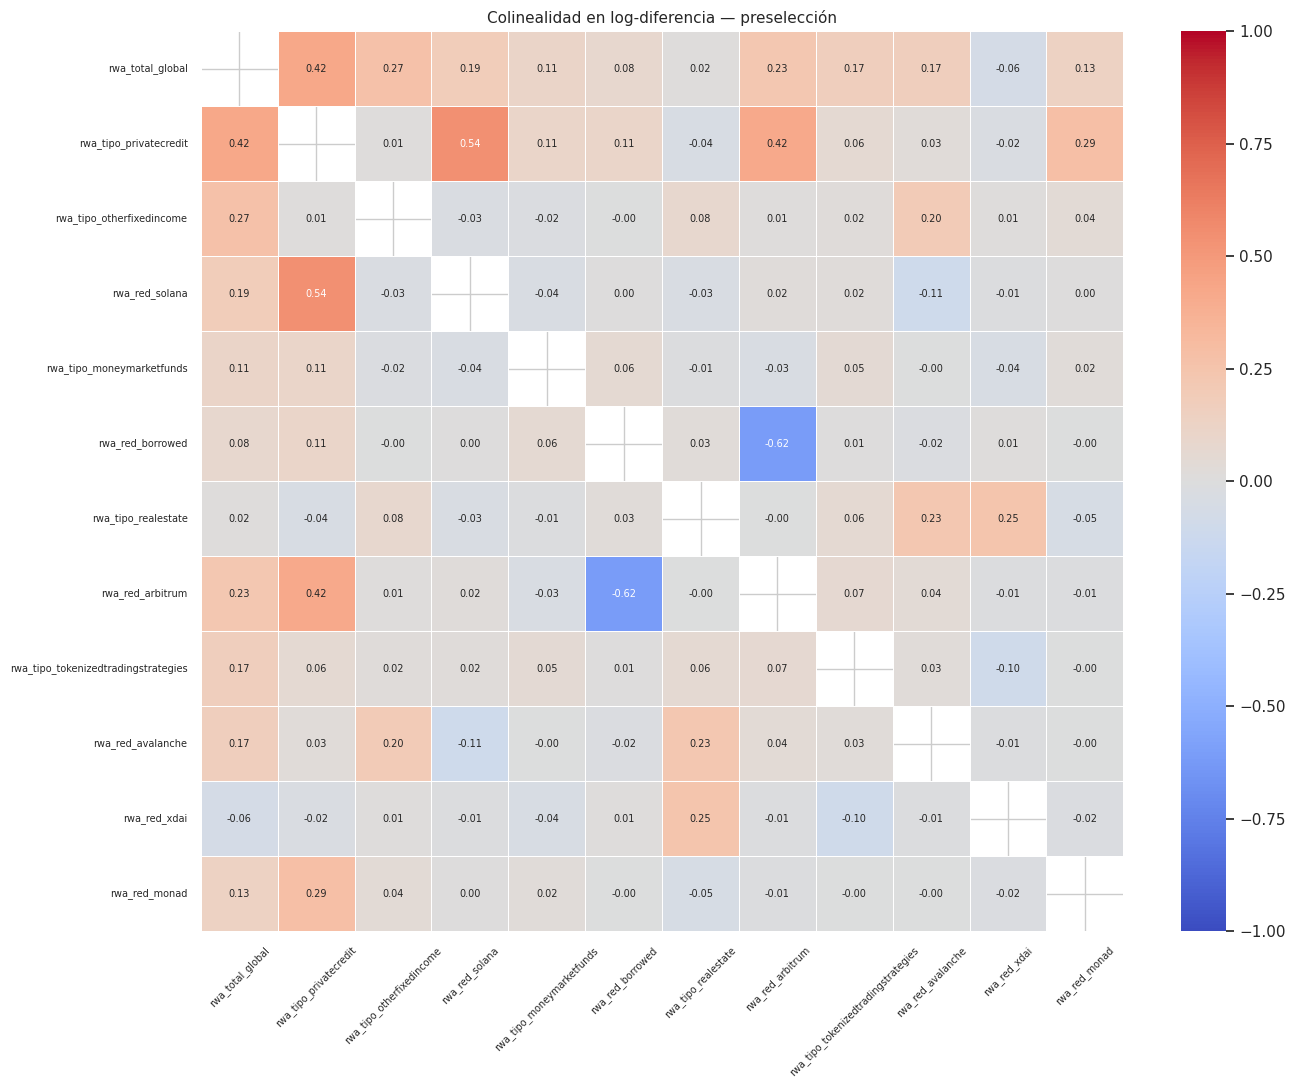


[RWA] === Preselección propuesta (a validar) ===
[RWA] fecha de extracción: 2026-10-25
[RWA] ventana: 2026-01-01 → 2026-08-08
[RWA] umbrales — TVL mín: 100,000,000 USD | colinealidad: |corr| log-dif > 0.85 | cobertura mín: 80%

[RWA] SELECCIONADAS (12):
  - rwa_total_global: representante de su cluster; eje=total:global; TVL=4,522,355,637 USD; historia=2013 días; cobertura ventana=100%
  - rwa_tipo_privatecredit: representante de su cluster; eje=tipo:Private Credit; TVL=1,201,055,546 USD; historia=1930 días; cobertura ventana=100%
  - rwa_tipo_otherfixedincome: representante de su cluster; eje=tipo:Other Fixed Income; TVL=734,726,978 USD; historia=1650 días; cobertura ventana=100%
  - rwa_red_solana: representante de su cluster; eje=red:Solana; TVL=593,773,347 USD; historia=1614 días; cobertura ventana=100%
  - rwa_tipo_moneymarketfunds: representante de su cluster; eje=tipo:Money Market Funds; TVL=486,386,760 USD; historia=1076 días; cobertura ventana=100%
  - rwa_red_borrowed: repre

In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# Límite de protocolos a descargar (None = todos los RWA).
# Solo para pruebas rápidas; en la corrida real dejar None.
LIMITE_PROTOCOLOS: int | None = None

# 2. Imports

import datetime
import os
import time
import warnings
from typing import Any

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

# Lectura: dataset base validado (carpeta 'expansion')
BASE_DIR_XP: str = "/content/drive/MyDrive/Tesis/expansion"
ARCHIVO_DIARIAS_XP: str = os.path.join(
    BASE_DIR_XP, "data", "processed", "series_diarias.csv"
)

# Escritura: reportes de la expansión
BASE_DIR_EXP: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_REPORTES: str = os.path.join(
    BASE_DIR_EXP, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_inventario_rwa"
)

TIMEOUT: int = 40
PAUSA: float = 1.0
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# --- Endpoints (validados en 00d) ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"
CATEGORIA_RWA: str = "RWA"

# ── Umbrales de decisión (ajustables y documentados) ─────────
# TVL mínimo para que una candidata sea considerada: por debajo
# de esto la serie es ruido estadístico, no señal.
UMBRAL_TVL_MIN: float = 100e6          # 100 M USD

# |corr| en log-dif por encima del cual dos candidatas se
# consideran redundantes (mismo cluster, una representante).
UMBRAL_COLINEAL: float = 0.85

# Cobertura mínima de la ventana 2026 para entrar al análisis
# de colinealidad (fracción de días de la grilla con dato).
COBERTURA_MIN: float = 0.80

# Tamaño objetivo de la preselección.
PRESEL_MIN: int = 8
PRESEL_MAX: int = 12

# Observaciones mínimas para que una correlación sea creíble.
N_MIN_CORR: int = 30

# Nivel protocolo×red: cuántos protocolos mayores se detallan.
N_PROTOCOLOS_DETALLE: int = 20

# Chains "sintéticas" de DeFiLlama a excluir del eje red: las
# claves de chainTvls que contienen "-" son agregados derivados
# (borrowed, staking, pool2), no redes.
MARCA_AGREGADO: str = "-"

# Nombre de la serie de contexto (total global).
COL_TOTAL: str = "rwa_total_global"

sns.set_theme(style="whitegrid", palette="muted")

"""# 4. Funciones"""


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    """
    GET HTTP con manejo aislado de errores.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima.

    Returns:
        JSON parseado, o None si falla o status != 200.
    """
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            return r.json()
        if DEBUG:
            print(f"[DEBUG] HTTP {r.status_code}: {url[:60]}")
        return None
    except requests.Timeout:
        if DEBUG:
            print(f"[DEBUG] timeout: {url[:60]}")
        return None
    except requests.RequestException as e:
        if DEBUG:
            print(f"[DEBUG] request error: {e}")
        return None


def _a_fecha(valor: Any) -> str | None:
    """
    Convierte un epoch (segundos o ms) a fecha ISO UTC.

    Args:
        valor: Epoch numérico o cadena numérica.

    Returns:
        Fecha ISO (YYYY-MM-DD) o None si no se pudo interpretar.
    """
    try:
        segundos = float(valor)
    except (TypeError, ValueError):
        return None
    if segundos > 1e11:
        segundos = segundos / 1000.0
    try:
        return datetime.datetime.fromtimestamp(
            segundos, tz=datetime.timezone.utc
        ).date().isoformat()
    except (OverflowError, OSError, ValueError):
        return None


def _slug_col(texto: str) -> str:
    """
    Normaliza un nombre de chain o tag a sufijo de columna.

    Args:
        texto: Nombre original (ej. "Treasury Bills").

    Returns:
        Sufijo en snake_case alfanumérico (ej. "treasurybills").
    """
    limpio = "".join(
        c.lower() if c.isalnum() else " " for c in texto
    )
    return "".join(limpio.split())


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama.

    Returns:
        DataFrame con slug, name, tags, chains, n_chains y tvl,
        ordenado por TVL descendente. Vacío si el endpoint falla.
    """
    if DEBUG:
        print(
            f"[DEBUG] /protocols → categoría '{CATEGORIA_RWA}'"
        )
    data = get_json(LLAMA_PROTOCOLS)
    if not isinstance(data, list) or not data:
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    vistos: set[str] = set()
    for proto in data:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        slug = str(proto.get("slug") or "")
        if not slug or slug in vistos:
            continue                  # dedupe defensivo
        vistos.add(slug)
        chains = [str(c) for c in (proto.get("chains") or [])]
        filas.append({
            "slug": slug,
            "name": str(proto.get("name") or slug),
            "tags": [str(t) for t in (proto.get("tags") or [])],
            "chains": chains,
            "n_chains": len(chains),
            "tvl_actual": float(proto.get("tvl") or 0.0),
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl_actual", ascending=False)
        df = df.reset_index(drop=True)
    return df


def descargar_series_protocolo(
    slug: str,
) -> dict[str, pd.Series]:
    """
    Descarga la serie histórica de TVL de un protocolo,
    desglosada por chain.

    Toma chainTvls[chain]["tvl"] (lista de {date,
    totalLiquidityUSD}) y excluye las claves derivadas. Si un
    día trae más de una observación, queda la última.

    Args:
        slug: Slug del protocolo en DeFiLlama.

    Returns:
        Dict chain → pd.Series (DatetimeIndex, float64).
    """
    data = get_json(f"{LLAMA_PROTOCOL}/{slug}")
    if not isinstance(data, dict):
        return {}
    chain_tvls = data.get("chainTvls")
    if not isinstance(chain_tvls, dict):
        return {}
    series: dict[str, pd.Series] = {}
    for chain, contenido in chain_tvls.items():
        nombre_chain = str(chain)
        if MARCA_AGREGADO in nombre_chain:
            continue
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl")
        if not isinstance(observaciones, list):
            continue
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            try:
                por_fecha[fecha] = float(valor)
            except (TypeError, ValueError):
                continue
        if not por_fecha:
            continue
        serie = pd.Series(por_fecha, dtype="float64")
        serie.index = pd.to_datetime(serie.index)
        series[nombre_chain] = serie.sort_index()
    return series


def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a diaria continua dentro de SU rango
    observado, propagando con ffill. No extrapola.

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria entre su primera y última observación.
    """
    if serie.empty:
        return serie
    grilla = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla).ffill()


def agregar_series(componentes: list[pd.Series]) -> pd.Series:
    """
    Suma varias series de TVL en una serie agregada diaria.

    Cada componente se densifica dentro de su propio rango
    (ffill) y aporta 0 fuera de él: un protocolo que todavía no
    existía no tiene valor tokenizado. El agregado arranca el
    primer día con dato de algún componente; antes no existe
    (no se hace back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        Serie agregada diaria (float64). Vacía si no hay datos.
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype="float64")
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla, dtype="float64")
    for serie in validos:
        densa = _densificar(serie).reindex(grilla).fillna(0.0)
        total = total.add(densa, fill_value=0.0)
    total.index.name = "fecha"
    return total.astype("float64")


def construir_candidatas(
    series_protocolos: dict[str, dict[str, pd.Series]],
    tags_por_slug: dict[str, list[str]],
) -> tuple[dict[str, pd.Series], pd.DataFrame]:
    """
    Construye TODAS las series agregadas candidatas: por red,
    por tipo de activo y total global.

    Args:
        series_protocolos: slug → {chain → serie de TVL}.
        tags_por_slug: slug → lista de tags (tipo de activo).

    Returns:
        (series, meta):
          series: nombre_columna → serie agregada.
          meta  : DataFrame con dimension, categoria y
                  n_protocolos de cada candidata.
    """
    series: dict[str, pd.Series] = {}
    meta: list[dict[str, Any]] = []

    # --- Eje RED: todas las chains con presencia RWA ---
    chains = sorted({
        chain
        for por_chain in series_protocolos.values()
        for chain in por_chain
    })
    for chain in chains:
        componentes = [
            por_chain[chain]
            for por_chain in series_protocolos.values()
            if chain in por_chain
        ]
        agregada = agregar_series(componentes)
        if agregada.empty:
            continue
        col = f"rwa_red_{_slug_col(chain)}"
        series[col] = agregada
        meta.append({
            "serie": col,
            "dimension": "red",
            "categoria": chain,
            "n_protocolos": len(componentes),
        })

    # --- Eje TIPO: todos los tags declarados ---
    tags = sorted({
        t
        for slug in series_protocolos
        for t in tags_por_slug.get(slug, [])
    })
    for tag in tags:
        componentes = [
            serie
            for slug, por_chain in series_protocolos.items()
            if tag in tags_por_slug.get(slug, [])
            for serie in por_chain.values()
        ]
        n_proto = len([
            slug for slug in series_protocolos
            if tag in tags_por_slug.get(slug, [])
        ])
        agregada = agregar_series(componentes)
        if agregada.empty:
            continue
        col = f"rwa_tipo_{_slug_col(tag)}"
        series[col] = agregada
        meta.append({
            "serie": col,
            "dimension": "tipo",
            "categoria": tag,
            "n_protocolos": n_proto,
        })

    # --- TOTAL global (contexto/control) ---
    componentes_total = [
        serie
        for por_chain in series_protocolos.values()
        for serie in por_chain.values()
    ]
    agregada_total = agregar_series(componentes_total)
    if not agregada_total.empty:
        series[COL_TOTAL] = agregada_total
        meta.append({
            "serie": COL_TOTAL,
            "dimension": "total",
            "categoria": "global",
            "n_protocolos": len(series_protocolos),
        })
    return series, pd.DataFrame(meta)


def construir_grilla(inicio: str, fin: str) -> pd.DatetimeIndex:
    """
    Grilla diaria continua (calendario, UTC).

    Args:
        inicio: Fecha ISO de inicio.
        fin: Fecha ISO de fin.

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_a_ventana(
    serie: pd.Series,
    grilla: pd.DatetimeIndex,
) -> pd.Series:
    """
    Alinea una serie a la grilla de la ventana con ffill.

    Sin interpolación y sin back-fill: si la serie nace después
    del inicio de la ventana, esos días quedan NaN.

    Args:
        serie: Serie de historia completa.
        grilla: Grilla diaria destino.

    Returns:
        Serie sobre la grilla (float64).
    """
    if serie.empty:
        return pd.Series(dtype="float64", index=grilla)
    inicio_ext = min(serie.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    alineada = serie.reindex(grilla_ext).ffill().reindex(grilla)
    alineada.index.name = "fecha"
    return alineada.astype("float64")


def atributos_candidata(
    col: str,
    serie_full: pd.Series,
    serie_ventana: pd.Series,
    grilla: pd.DatetimeIndex,
) -> dict[str, Any]:
    """
    Calcula los atributos de inventario de una candidata.

    Args:
        col: Nombre de la serie.
        serie_full: Historia completa.
        serie_ventana: Serie alineada a la ventana.
        grilla: Grilla de la ventana.

    Returns:
        Dict con TVL actual, historia, cobertura y fechas.
    """
    con_dato = serie_ventana.dropna()
    cobertura = (
        len(con_dato) / len(grilla) if len(grilla) else 0.0
    )
    return {
        "serie": col,
        "tvl_actual": (
            float(serie_full.iloc[-1])
            if not serie_full.empty else 0.0
        ),
        "tvl_max": (
            float(serie_full.max())
            if not serie_full.empty else 0.0
        ),
        "min_fecha": (
            serie_full.index.min().date().isoformat()
            if not serie_full.empty else "s/d"
        ),
        "max_fecha": (
            serie_full.index.max().date().isoformat()
            if not serie_full.empty else "s/d"
        ),
        "n_dias_historia": int(len(serie_full)),
        "n_dias_ventana": int(len(con_dato)),
        "cobertura_ventana": round(float(cobertura), 4),
        "inicia_en_ventana": bool(
            not serie_full.empty
            and serie_full.index.min() > grilla.min()
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    }


def log_diferencias(df: pd.DataFrame) -> pd.DataFrame:
    """
    Log-diferencia de las columnas estrictamente positivas.

    Las columnas con ceros o negativos se omiten: no se fuerza
    el logaritmo ni se desplaza la serie (sería inventar dato).

    Args:
        df: Dataset de niveles.

    Returns:
        DataFrame de log-diferencias.
    """
    datos: dict[str, pd.Series] = {}
    for col in df.columns:
        s = df[col].dropna()
        if s.empty or not bool((s > 0).all()):
            if DEBUG:
                print(f"[DEBUG] {col}: no positiva — sin log_dif")
            continue
        datos[col] = np.log(df[col]).diff()
    return pd.DataFrame(datos, index=df.index)


def pares_colineales(
    corr: pd.DataFrame,
    umbral: float,
) -> pd.DataFrame:
    """
    Lista los pares de series con |corr| por encima del umbral.

    Args:
        corr: Matriz de correlación.
        umbral: Umbral de |corr|.

    Returns:
        DataFrame con serie_a, serie_b y corr, de mayor a menor.
    """
    filas: list[dict[str, Any]] = []
    cols = list(corr.columns)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            valor = corr.loc[a, b]
            if pd.isna(valor):
                continue
            if abs(float(valor)) > umbral:
                filas.append({
                    "serie_a": a,
                    "serie_b": b,
                    "corr": round(float(valor), 4),
                })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.reindex(
            df["corr"].abs().sort_values(ascending=False).index
        ).reset_index(drop=True)
    return df


def clusters_colinealidad(
    corr: pd.DataFrame,
    umbral: float,
) -> dict[str, int]:
    """
    Agrupa series en clusters de redundancia.

    Dos series quedan en el mismo cluster si |corr| > umbral;
    la relación se propaga transitivamente (union-find), de modo
    que un grupo redundante queda representado por un único id.

    Args:
        corr: Matriz de correlación en log-diferencia.
        umbral: Umbral de |corr|.

    Returns:
        Dict serie → id de cluster (int).
    """
    cols = list(corr.columns)
    padre: dict[str, str] = {c: c for c in cols}

    def buscar(x: str) -> str:
        while padre[x] != x:
            padre[x] = padre[padre[x]]
            x = padre[x]
        return x

    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            valor = corr.loc[a, b]
            if pd.isna(valor) or abs(float(valor)) <= umbral:
                continue
            ra, rb = buscar(a), buscar(b)
            if ra != rb:
                padre[ra] = rb

    raices = sorted({buscar(c) for c in cols})
    id_por_raiz = {r: i for i, r in enumerate(raices)}
    return {c: id_por_raiz[buscar(c)] for c in cols}


def elegir_representante(
    candidatas: pd.DataFrame,
) -> str:
    """
    Elige la representante de un cluster.

    Criterio: mayor TVL actual; a igualdad de TVL, mayor
    historia (más días de serie).

    Args:
        candidatas: Filas del inventario de un mismo cluster.

    Returns:
        Nombre de la serie representante.
    """
    ordenadas = candidatas.sort_values(
        ["tvl_actual", "n_dias_historia"], ascending=False
    )
    return str(ordenadas.iloc[0]["serie"])


def preseleccionar(
    inventario: pd.DataFrame,
    clusters: dict[str, int],
    presel_min: int = PRESEL_MIN,
    presel_max: int = PRESEL_MAX,
) -> pd.DataFrame:
    """
    Propone el subconjunto diverso y no redundante.

    Algoritmo:
      1. De cada cluster de colinealidad se conserva UNA
         representante (mayor TVL, desempate por historia); las
         demás quedan marcadas REDUNDANTE con su representante.
      2. Entre las representantes se alterna la selección entre
         el eje TIPO y el eje RED, tomando en cada turno la de
         mayor TVL disponible. Así el subconjunto cubre
         dinámicas distintas (refugio soberano, oro, crédito
         privado, equity) y varias redes, en vez de llenarse con
         las mayores de un solo eje.
      3. El total global entra primero como serie de contexto,
         salvo que haya quedado en el mismo cluster que una
         componente: en ese caso el paso 1 ya lo resolvió y no
         se duplica el anidamiento.
      4. El corte es presel_max; si hay menos representantes que
         presel_min se reporta el faltante.

    Args:
        inventario: Inventario filtrado (pasa tamaño+cobertura).
        clusters: Serie → id de cluster.
        presel_min: Tamaño mínimo deseado.
        presel_max: Tamaño máximo del subconjunto.

    Returns:
        DataFrame con estado ("SELECCIONADA"/"REDUNDANTE"/
        "NO_SELECCIONADA"), representada_por y justificacion.
    """
    base = inventario.copy()
    base["cluster"] = base["serie"].map(clusters)
    base["estado"] = "NO_SELECCIONADA"
    base["representada_por"] = ""
    base["justificacion"] = ""

    # 1. Representante por cluster
    representantes: list[str] = []
    for cid, grupo in base.groupby("cluster", dropna=False):
        rep = elegir_representante(grupo)
        representantes.append(rep)
        for _, fila in grupo.iterrows():
            nombre = str(fila["serie"])
            if nombre == rep:
                continue
            idx = index_serie(base, nombre)
            base.loc[idx, "estado"] = "REDUNDANTE"
            base.loc[idx, "representada_por"] = rep
            base.loc[idx, "justificacion"] = (
                f"|corr| log-dif > {UMBRAL_COLINEAL} con el "
                f"cluster {cid}; representada por {rep}"
            )

    # 2. Selección alternando ejes, por TVL descendente
    reps = base[base["serie"].isin(representantes)]
    pool_total = [
        s for s in reps.loc[
            reps["dimension"] == "total", "serie"
        ]
    ]
    def _pool(dim: str) -> list[str]:
        sub = reps[reps["dimension"] == dim]
        sub = sub.sort_values("tvl_actual", ascending=False)
        return [str(s) for s in sub["serie"]]

    pool_tipo = _pool("tipo")
    pool_red = _pool("red")
    seleccion: list[str] = []
    seleccion.extend(pool_total[:1])
    turno_tipo = True
    while len(seleccion) < presel_max and (pool_tipo or pool_red):
        pool = pool_tipo if turno_tipo else pool_red
        if not pool:
            pool = pool_red if turno_tipo else pool_tipo
        if not pool:
            break
        seleccion.append(pool.pop(0))
        turno_tipo = not turno_tipo

    # 3. Marcado y justificación
    for nombre in seleccion:
        idx = index_serie(base, nombre)
        fila = base.loc[idx]
        base.loc[idx, "estado"] = "SELECCIONADA"
        base.loc[idx, "justificacion"] = (
            f"representante de su cluster; eje="
            f"{fila['dimension']}:{fila['categoria']}; "
            f"TVL={fila['tvl_actual']:,.0f} USD; "
            f"historia={fila['n_dias_historia']} días; "
            f"cobertura ventana="
            f"{fila['cobertura_ventana'] * 100:.0f}%"
        )
    no_sel = (
        (base["estado"] == "NO_SELECCIONADA")
        & (base["serie"].isin(representantes))
    )
    base.loc[no_sel, "justificacion"] = (
        f"no redundante, pero fuera del corte de {presel_max} "
        "por menor TVL en su eje"
    )
    return base


def index_serie(df: pd.DataFrame, nombre: str) -> Any:
    """
    Devuelve el índice de la fila de una serie del inventario.

    Args:
        df: Inventario.
        nombre: Nombre de la serie.

    Returns:
        Índice de pandas de esa fila.
    """
    return df.index[df["serie"] == nombre][0]


def heatmap_colinealidad(
    corr: pd.DataFrame,
    titulo: str,
    fname: str,
) -> None:
    """
    Heatmap de la matriz de colinealidad.

    Args:
        corr: Matriz de correlación.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    if corr.empty:
        if DEBUG:
            print(f"[DEBUG] {titulo}: matriz vacía")
        return
    lado = max(6.0, 0.9 * len(corr.columns) + 3.0)
    fig, ax = plt.subplots(figsize=(lado, lado * 0.8))
    mask = np.zeros_like(corr.values, dtype=bool)
    np.fill_diagonal(mask, True)
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f",
        cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax,
        annot_kws={"size": 7}, linewidths=0.4,
    )
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    plt.tight_layout()
    if SAVE_DATA:
        os.makedirs(DIR_FIGURAS, exist_ok=True)
        ruta = os.path.join(DIR_FIGURAS, fname)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")
    plt.show()
    plt.close()


"""# 5. Proceso"""

# ── 5.0 Ventana de análisis (del dataset base de 'expansion') ─────
if DEBUG:
    print("\n[DEBUG] === 5.0 Ventana de análisis ===")

ventana_inicio: str = VENTANA_INICIO
ventana_fin: str = HOY
try:
    df_base = pd.read_csv(
        ARCHIVO_DIARIAS_XP,
        parse_dates=["fecha"],
        index_col="fecha",
    )
    ventana_inicio = df_base.index.min().date().isoformat()
    ventana_fin = df_base.index.max().date().isoformat()
    if DEBUG:
        print(
            f"[DEBUG] dataset base: {df_base.shape} — "
            f"{ventana_inicio} → {ventana_fin}"
        )
except Exception as _exc:
    if DEBUG:
        print(
            f"[DEBUG] no se pudo leer el dataset base "
            f"({_exc}); se usa {VENTANA_INICIO} → {HOY}"
        )

grilla: pd.DatetimeIndex = construir_grilla(
    ventana_inicio, ventana_fin
)

# ── 5.1 PARTE 1: inventario de protocolos ────────────────────
if DEBUG:
    print("\n[DEBUG] === 5.1 PARTE 1: catálogo de protocolos ===")

protocolos: pd.DataFrame = listar_protocolos_rwa()
if protocolos.empty:
    raise RuntimeError(
        "No se pudo listar protocolos RWA en DeFiLlama: "
        "sin catálogo no hay inventario posible."
    )
if LIMITE_PROTOCOLOS is not None:
    protocolos = protocolos.head(LIMITE_PROTOCOLOS)

if DEBUG:
    print(f"[DEBUG] protocolos RWA: {len(protocolos)}")
    print(
        f"[DEBUG] TVL catálogo: "
        f"{protocolos['tvl_actual'].sum():,.0f} USD"
    )

series_protocolos: dict[str, dict[str, pd.Series]] = {}
for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    try:
        _series = descargar_series_protocolo(_slug)
    except Exception as _e:
        _series = {}
        if DEBUG:
            print(f"[DEBUG] error en {_slug}: {_e}")
    if _series:
        series_protocolos[_slug] = _series
    time.sleep(PAUSA)

if DEBUG:
    print(
        f"[DEBUG] protocolos con serie: "
        f"{len(series_protocolos)}/{len(protocolos)}"
    )

# Nivel PROTOCOLO: atributos de historia
filas_proto: list[dict[str, Any]] = []
for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    _por_chain = series_protocolos.get(_slug, {})
    _todas = list(_por_chain.values())
    _inicio = (
        min(s.index.min() for s in _todas) if _todas else None
    )
    _fin = (
        max(s.index.max() for s in _todas) if _todas else None
    )
    filas_proto.append({
        "slug": _slug,
        "name": str(_fila["name"]),
        "tags": ",".join(_fila["tags"]),
        "chains": ",".join(_fila["chains"]),
        "n_chains": int(_fila["n_chains"]),
        "tvl_actual": float(_fila["tvl_actual"]),
        "con_serie": bool(_todas),
        "min_fecha": (
            _inicio.date().isoformat() if _inicio else "s/d"
        ),
        "max_fecha": (
            _fin.date().isoformat() if _fin else "s/d"
        ),
        "n_dias_historia": (
            int((_fin - _inicio).days) + 1
            if _inicio is not None and _fin is not None else 0
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
df_protocolos: pd.DataFrame = pd.DataFrame(filas_proto)

# Nivel PROTOCOLO × RED (solo los mayores, para no inflar)
filas_pr: list[dict[str, Any]] = []
for _, _fila in df_protocolos.head(N_PROTOCOLOS_DETALLE).iterrows():
    _slug = str(_fila["slug"])
    for _chain, _serie in series_protocolos.get(_slug, {}).items():
        filas_pr.append({
            "slug": _slug,
            "name": _fila["name"],
            "chain": _chain,
            "tags": _fila["tags"],
            "tvl_ultimo": float(_serie.iloc[-1]),
            "min_fecha": _serie.index.min().date().isoformat(),
            "max_fecha": _serie.index.max().date().isoformat(),
            "n_obs": int(len(_serie)),
            "fecha_extraccion": FECHA_EXTRACCION,
        })
df_proto_red: pd.DataFrame = pd.DataFrame(filas_pr)

if DEBUG:
    print(f"[DEBUG] nivel protocolo: {df_protocolos.shape}")
    print(f"[DEBUG] nivel protocolo×red: {df_proto_red.shape}")

# ── 5.2 Series agregadas candidatas ──────────────────────────
if DEBUG:
    print("\n[DEBUG] === 5.2 Series candidatas ===")

tags_por_slug: dict[str, list[str]] = {
    str(f["slug"]): list(f["tags"])
    for _, f in protocolos.iterrows()
}

series_candidatas, df_meta = construir_candidatas(
    series_protocolos, tags_por_slug
)

if DEBUG:
    print(
        f"[DEBUG] candidatas construidas: "
        f"{len(series_candidatas)} "
        f"(red={int((df_meta['dimension'] == 'red').sum())}, "
        f"tipo={int((df_meta['dimension'] == 'tipo').sum())}, "
        f"total=1)"
    )

# Alineación a la ventana y atributos de inventario
series_ventana: dict[str, pd.Series] = {}
filas_inv: list[dict[str, Any]] = []
for _col, _serie in series_candidatas.items():
    _alineada = alinear_a_ventana(_serie, grilla)
    series_ventana[_col] = _alineada
    filas_inv.append(
        atributos_candidata(_col, _serie, _alineada, grilla)
    )

inventario: pd.DataFrame = pd.DataFrame(filas_inv)
inventario = inventario.merge(df_meta, on="serie", how="left")
inventario = inventario.sort_values(
    "tvl_actual", ascending=False
).reset_index(drop=True)

df_niveles: pd.DataFrame = pd.DataFrame(
    series_ventana, index=grilla
)

if DEBUG:
    _inv_cols = [
        "serie", "dimension", "categoria", "tvl_actual",
        "n_dias_historia", "cobertura_ventana", "min_fecha",
    ]
    print(inventario[_inv_cols].head(30).to_string(index=False))

# ── 5.3 PARTE 2: filtro por tamaño y cobertura ───────────────
if DEBUG:
    print("\n[DEBUG] === 5.3 PARTE 2: filtro tamaño/cobertura ===")

inventario["pasa_tamano"] = (
    inventario["tvl_actual"] >= UMBRAL_TVL_MIN
)
inventario["pasa_cobertura"] = (
    inventario["cobertura_ventana"] >= COBERTURA_MIN
)
inventario["motivo_descarte"] = ""
inventario.loc[~inventario["pasa_tamano"], "motivo_descarte"] = (
    f"TVL < {UMBRAL_TVL_MIN:,.0f} USD (ruido estadístico)"
)
_sin_cob = (
    inventario["pasa_tamano"] & ~inventario["pasa_cobertura"]
)
inventario.loc[_sin_cob, "motivo_descarte"] = (
    f"cobertura de ventana < {COBERTURA_MIN:.0%} "
    "(serie nace dentro de la ventana; no se rellena)"
)

candidatas_ok: list[str] = inventario.loc[
    inventario["pasa_tamano"] & inventario["pasa_cobertura"],
    "serie",
].tolist()

if DEBUG:
    print(
        f"[DEBUG] pasan tamaño: "
        f"{int(inventario['pasa_tamano'].sum())}/"
        f"{len(inventario)}"
    )
    print(
        f"[DEBUG] pasan tamaño+cobertura: {len(candidatas_ok)}"
    )
    _desc = inventario[inventario["motivo_descarte"] != ""]
    if not _desc.empty:
        print("[DEBUG] descartadas (primeras 20):")
        print(
            _desc[["serie", "tvl_actual", "motivo_descarte"]]
            .head(20).to_string(index=False)
        )

# ── 5.4 PARTE 3: colinealidad en log-diferencia ──────────────
if DEBUG:
    print("\n[DEBUG] === 5.4 PARTE 3: colinealidad log-dif ===")

corr_logdif: pd.DataFrame = pd.DataFrame()
df_pares: pd.DataFrame = pd.DataFrame()
clusters: dict[str, int] = {}
try:
    df_ld = log_diferencias(df_niveles[candidatas_ok])
    # Solo series con suficientes observaciones para correlar
    _validas = [
        c for c in df_ld.columns
        if df_ld[c].notna().sum() >= N_MIN_CORR
        and float(df_ld[c].std()) > 0
    ]
    _descartadas_n = [
        c for c in df_ld.columns if c not in _validas
    ]
    if DEBUG and _descartadas_n:
        print(
            f"[DEBUG] sin n suficiente para correlacionar "
            f"(<{N_MIN_CORR}): {_descartadas_n}"
        )
    corr_logdif = df_ld[_validas].corr(method="pearson")
    df_pares = pares_colineales(corr_logdif, UMBRAL_COLINEAL)
    clusters = clusters_colinealidad(
        corr_logdif, UMBRAL_COLINEAL
    )
    if DEBUG:
        print(
            f"[DEBUG] matriz log-dif: {corr_logdif.shape} | "
            f"pares |corr|>{UMBRAL_COLINEAL}: {len(df_pares)}"
        )
        if not df_pares.empty:
            print(df_pares.head(20).to_string(index=False))
        _n_clusters = len(set(clusters.values()))
        print(
            f"[DEBUG] clusters de redundancia: {_n_clusters} "
            f"sobre {len(clusters)} series"
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] PARTE 3 falló: {_exc}")

# ── 5.5 PARTE 4: preselección por diversidad ─────────────────
if DEBUG:
    print("\n[DEBUG] === 5.5 PARTE 4: preselección ===")

preseleccion: pd.DataFrame = pd.DataFrame()
try:
    inv_ok = inventario[
        inventario["serie"].isin(clusters.keys())
    ].reset_index(drop=True)
    preseleccion = preseleccionar(
        inv_ok, clusters, PRESEL_MIN, PRESEL_MAX
    )
    _sel = preseleccion[
        preseleccion["estado"] == "SELECCIONADA"
    ]["serie"].tolist()
    if len(_sel) < PRESEL_MIN and DEBUG:
        print(
            f"[DEBUG] AVISO: solo {len(_sel)} series no "
            f"redundantes disponibles (mínimo deseado "
            f"{PRESEL_MIN}): revisar UMBRAL_TVL_MIN o "
            "UMBRAL_COLINEAL"
        )
    if _sel and not corr_logdif.empty:
        heatmap_colinealidad(
            corr_logdif.loc[_sel, _sel],
            "Colinealidad en log-diferencia — preselección",
            "colinealidad_preseleccion_logdif.png",
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] PARTE 4 falló: {_exc}")

# ── 5.6 Reporte de decisión ──────────────────────────────────
print("\n[RWA] === Preselección propuesta (a validar) ===")
print(f"[RWA] fecha de extracción: {FECHA_EXTRACCION}")
print(f"[RWA] ventana: {ventana_inicio} → {ventana_fin}")
print(
    f"[RWA] umbrales — TVL mín: {UMBRAL_TVL_MIN:,.0f} USD | "
    f"colinealidad: |corr| log-dif > {UMBRAL_COLINEAL} | "
    f"cobertura mín: {COBERTURA_MIN:.0%}"
)
if preseleccion.empty:
    print("[RWA] sin preselección disponible")
else:
    _sel = preseleccion[preseleccion["estado"] == "SELECCIONADA"]
    _red = preseleccion[preseleccion["estado"] == "REDUNDANTE"]
    _no = preseleccion[
        preseleccion["estado"] == "NO_SELECCIONADA"
    ]
    print(f"\n[RWA] SELECCIONADAS ({len(_sel)}):")
    for _, _f in _sel.iterrows():
        print(f"  - {_f['serie']}: {_f['justificacion']}")
    print(f"\n[RWA] REDUNDANTES ({len(_red)}):")
    for _, _f in _red.iterrows():
        print(
            f"  - {_f['serie']} → representada por "
            f"{_f['representada_por']}"
        )
    if not _no.empty:
        print(f"\n[RWA] FUERA DEL CORTE ({len(_no)}):")
        for _, _f in _no.iterrows():
            print(f"  - {_f['serie']}: {_f['justificacion']}")
    _tipos = sorted(set(_sel.loc[
        _sel["dimension"] == "tipo", "categoria"
    ]))
    _redes = sorted(set(_sel.loc[
        _sel["dimension"] == "red", "categoria"
    ]))
    print(
        f"\n[RWA] diversidad — tipos: {_tipos or 'ninguno'}"
    )
    print(f"[RWA] diversidad — redes: {_redes or 'ninguna'}")
print(
    "\n[RWA] NOTA: los tags de tipo NO son exclusivos; las "
    "series por tipo no particionan el total global. El "
    "anidamiento se controla por correlación empírica en "
    "log-dif, no por aritmética de sumas."
)
print(
    "[RWA] Esta es una PROPUESTA: la decisión del set final "
    "queda a criterio del autor sobre este reporte."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    _guardados: list[str] = []

    if not inventario.empty:
        _ruta = os.path.join(DIR_REPORTES, "inventario_rwa.csv")
        inventario.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_protocolos.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "inventario_rwa_protocolos.csv"
        )
        df_protocolos.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_proto_red.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "inventario_rwa_proto_red.csv"
        )
        df_proto_red.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not corr_logdif.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "colinealidad_rwa_logdif.csv"
        )
        corr_logdif.to_csv(_ruta)
        _guardados.append(_ruta)

    if not df_pares.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "colinealidad_rwa_pares.csv"
        )
        df_pares.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not preseleccion.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "preseleccion_rwa.csv"
        )
        preseleccion.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")

# Job 3 - Adquisición de series RWA

In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# Une las series RWA al dataset diario existente (left join).
UNIR_A_DATASET: bool = True
# Límite de protocolos a descargar (None = todos los RWA).
# Solo para pruebas rápidas; en la corrida real dejar None.
LIMITE_PROTOCOLOS: int | None = None

# 2. Imports

import datetime
import os
import time
from typing import Any

import pandas as pd
import requests

from google.colab import drive
drive.mount('/content/drive')

# 3. Paths y Constantes

# Lectura: dataset base validado (carpeta 'expansion')
BASE_DIR_XP: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED_XP: str = os.path.join(
    BASE_DIR_XP, "data", "processed"
)

# Escritura: todo lo nuevo va a la expansión
BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(BASE_DIR, "outputs", "reportes")

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED_XP, "series_diarias.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED_XP, "series_largas.csv"
)
ARCHIVO_RWA: str = os.path.join(
    DIR_PROCESSED, "series_rwa.csv"
)
ARCHIVO_RWA_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_rwa_largas.csv"
)
ARCHIVO_DIARIAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_COBERTURA: str = os.path.join(
    DIR_REPORTES, "cobertura_rwa.csv"
)

TIMEOUT: int = 40
PAUSA: float = 1.0            # segundos entre requests
VENTANA_INICIO: str = "2026-01-01"
HOY: str = datetime.date.today().isoformat()
FECHA_EXTRACCION: str = HOY

# --- Endpoints base (validados en 00d) ---
LLAMA_BASE: str = "https://api.llama.fi"
LLAMA_PROTOCOLS: str = f"{LLAMA_BASE}/protocols"
LLAMA_PROTOCOL: str = f"{LLAMA_BASE}/protocol"       # /{slug}

CATEGORIA_RWA: str = "RWA"

# GRUPO 1 — columna → chains DeFiLlama que la componen.
# "XRPL EVM" es la sidechain EVM de XRPL: se suma a Ripple por
# ser la misma red del modelo. Quitarla de la lista si se quiere
# el XRPL nativo puro.
REDES_OBJETIVO: dict[str, list[str]] = {
    "rwa_red_stellar": ["Stellar"],
    "rwa_red_ripple": ["Ripple", "XRPL EVM"],
    "rwa_red_algorand": ["Algorand"],
}

# GRUPO 2 — columna → tags DeFiLlama (nombres exactos del API).
TIPOS_OBJETIVO: dict[str, list[str]] = {
    "rwa_tipo_treasurybills": ["Treasury Bills"],
    "rwa_tipo_commodities": ["Commodities"],
    "rwa_tipo_privatecredit": ["Private Credit"],
    "rwa_tipo_stocksetfs": ["Stocks & ETFs"],
}

# GRUPO 3 — contexto.
COL_TOTAL: str = "rwa_total_global"

# Orden final de columnas del dataset RWA.
COLUMNAS_RWA: list[str] = (
    list(REDES_OBJETIVO) + list(TIPOS_OBJETIVO) + [COL_TOTAL]
)

# Sufijos de chainTvls que son agregados derivados, no chains
# reales (borrowed, staking, pool2, ...). Se excluyen.
MARCA_AGREGADO: str = "-"

"""# 4. Funciones"""


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    """
    GET HTTP con manejo aislado de errores.

    Args:
        url: URL del endpoint.
        params: Query parameters opcionales.
        timeout: Segundos de espera máxima.

    Returns:
        Objeto Python (dict/list) parseado del JSON, o None si
        la request falla o devuelve status != 200.
    """
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            return r.json()
        if DEBUG:
            print(f"[DEBUG] HTTP {r.status_code}: {url[:60]}")
        return None
    except requests.Timeout:
        if DEBUG:
            print(f"[DEBUG] timeout: {url[:60]}")
        return None
    except requests.RequestException as e:
        if DEBUG:
            print(f"[DEBUG] request error: {e}")
        return None


def _a_fecha(valor: Any) -> str | None:
    """
    Convierte un timestamp epoch (segundos o ms) a fecha ISO UTC.

    Args:
        valor: Epoch numérico o cadena numérica.

    Returns:
        Fecha ISO (YYYY-MM-DD) o None si no se pudo interpretar.
    """
    try:
        segundos = float(valor)
    except (TypeError, ValueError):
        return None
    if segundos > 1e11:           # epoch en milisegundos
        segundos = segundos / 1000.0
    try:
        return datetime.datetime.fromtimestamp(
            segundos, tz=datetime.timezone.utc
        ).date().isoformat()
    except (OverflowError, OSError, ValueError):
        return None


def listar_protocolos_rwa() -> pd.DataFrame:
    """
    Lista los protocolos de categoría RWA en DeFiLlama.

    Returns:
        DataFrame con columnas slug, name, tags (list[str]),
        chains (list[str]) y tvl, ordenado por TVL descendente.
        Vacío si el endpoint falla.
    """
    if DEBUG:
        print(
            f"[DEBUG] /protocols → categoría '{CATEGORIA_RWA}'"
        )
    data = get_json(LLAMA_PROTOCOLS)
    if not isinstance(data, list) or not data:
        if DEBUG:
            print("[DEBUG] /protocols: respuesta vacía o inválida")
        return pd.DataFrame()
    filas: list[dict[str, Any]] = []
    vistos: set[str] = set()
    for proto in data:
        if not isinstance(proto, dict):
            continue
        if proto.get("category") != CATEGORIA_RWA:
            continue
        slug = str(proto.get("slug") or "")
        if not slug or slug in vistos:
            continue          # dedupe: no contar dos veces
        vistos.add(slug)
        filas.append({
            "slug": slug,
            "name": str(proto.get("name") or slug),
            "tags": [str(t) for t in (proto.get("tags") or [])],
            "chains": [
                str(c) for c in (proto.get("chains") or [])
            ],
            "tvl": float(proto.get("tvl") or 0.0),
        })
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values("tvl", ascending=False)
        df = df.reset_index(drop=True)
    return df


def descargar_series_protocolo(
    slug: str,
) -> dict[str, pd.Series]:
    """
    Descarga la serie histórica de TVL de un protocolo,
    desglosada por chain.

    Toma chainTvls[chain]["tvl"], que es una lista de
    {date, totalLiquidityUSD}. Excluye las claves derivadas
    (las que contienen "-": borrowed, staking, pool2, ...).
    Si un día trae más de una observación, queda la última.

    Args:
        slug: Slug del protocolo en DeFiLlama.

    Returns:
        Dict chain → pd.Series (DatetimeIndex diario, float).
        Vacío si la descarga falla o no hay chainTvls.
    """
    data = get_json(f"{LLAMA_PROTOCOL}/{slug}")
    if not isinstance(data, dict):
        return {}
    chain_tvls = data.get("chainTvls")
    if not isinstance(chain_tvls, dict):
        return {}
    series: dict[str, pd.Series] = {}
    for chain, contenido in chain_tvls.items():
        nombre_chain = str(chain)
        if MARCA_AGREGADO in nombre_chain:
            continue
        if not isinstance(contenido, dict):
            continue
        observaciones = contenido.get("tvl")
        if not isinstance(observaciones, list):
            continue
        por_fecha: dict[str, float] = {}
        for obs in observaciones:
            if not isinstance(obs, dict):
                continue
            fecha = _a_fecha(obs.get("date"))
            valor = obs.get("totalLiquidityUSD")
            if fecha is None or valor is None:
                continue
            try:
                por_fecha[fecha] = float(valor)
            except (TypeError, ValueError):
                continue
        if not por_fecha:
            continue
        serie = pd.Series(por_fecha, dtype=float)
        serie.index = pd.to_datetime(serie.index)
        series[nombre_chain] = serie.sort_index()
    return series


def _densificar(serie: pd.Series) -> pd.Series:
    """
    Lleva una serie a frecuencia diaria continua dentro de su
    propio rango observado, propagando con ffill.

    NO extrapola fuera del rango observado: antes de la primera
    y después de la última observación la serie no existe (NaN).

    Args:
        serie: Serie con DatetimeIndex ordenado.

    Returns:
        Serie diaria continua entre su min y su max observados.
    """
    if serie.empty:
        return serie
    grilla_propia = pd.date_range(
        start=serie.index.min(), end=serie.index.max(), freq="D"
    )
    return serie.reindex(grilla_propia).ffill()


def agregar_series(
    componentes: list[pd.Series],
) -> tuple[pd.Series, pd.DatetimeIndex]:
    """
    Suma varias series de TVL (una por protocolo/chain) en una
    serie agregada diaria.

    Criterio de agregación:
      - Cada componente se densifica a diaria dentro de SU rango
        observado (ffill), sin extrapolar.
      - Fuera de ese rango el componente aporta 0: un protocolo
        que todavía no existía (o que dejó de reportar) no tiene
        valor tokenizado. Esto NO es relleno inventado.
      - El agregado empieza el primer día en que ALGÚN componente
        tiene observación; antes de esa fecha no existe (se deja
        fuera de la serie, sin back-fill).

    Args:
        componentes: Series de TVL a sumar.

    Returns:
        (serie_agregada, fechas_reales):
          serie_agregada : suma diaria desde el primer día con
                           datos hasta el último.
          fechas_reales  : fechas con observación DIRECTA de al
                           menos un componente (para la máscara
                           de ffill posterior).
    """
    validos = [s for s in componentes if not s.empty]
    if not validos:
        return pd.Series(dtype=float), pd.DatetimeIndex([])
    inicio = min(s.index.min() for s in validos)
    fin = max(s.index.max() for s in validos)
    grilla = pd.date_range(start=inicio, end=fin, freq="D")
    total = pd.Series(0.0, index=grilla)
    for serie in validos:
        densa = _densificar(serie)
        total = total.add(
            densa.reindex(grilla).fillna(0.0), fill_value=0.0
        )
    fechas_reales = pd.DatetimeIndex(
        sorted({fecha for s in validos for fecha in s.index})
    )
    total.index.name = "fecha"
    return total, fechas_reales


def registrar_serie(
    columna: str,
    componentes: list[pd.Series],
    n_protocolos: int,
    descripcion: str,
    destino_series: dict[str, pd.Series],
    destino_fechas: dict[str, pd.DatetimeIndex],
    destino_detalle: list[dict[str, Any]],
) -> None:
    """
    Agrega los componentes de una serie y la registra en los
    contenedores del proceso.

    Si la agregación no devuelve datos, la serie NO se registra
    (no se rellena con ceros) y queda anotada como fallida en el
    detalle.

    Args:
        columna: Nombre de la columna destino.
        componentes: Series de TVL a sumar.
        n_protocolos: Cuántos protocolos aportan a la serie.
        descripcion: Evidencia de cómo se construyó la serie.
        destino_series: Dict columna → serie agregada.
        destino_fechas: Dict columna → fechas con dato directo.
        destino_detalle: Lista de registros de detalle.
    """
    agregada, reales = agregar_series(componentes)
    if agregada.empty:
        if DEBUG:
            print(f"[DEBUG] {columna}: SIN DATOS — se omite")
        destino_detalle.append({
            "serie": columna,
            "n_protocolos": n_protocolos,
            "ok": False,
            "descripcion": descripcion,
            "min_fecha_origen": "s/d",
            "max_fecha_origen": "s/d",
            "fecha_extraccion": FECHA_EXTRACCION,
        })
        return
    destino_series[columna] = agregada
    destino_fechas[columna] = reales
    destino_detalle.append({
        "serie": columna,
        "n_protocolos": n_protocolos,
        "ok": True,
        "descripcion": descripcion,
        "min_fecha_origen": (
            agregada.index.min().date().isoformat()
        ),
        "max_fecha_origen": (
            agregada.index.max().date().isoformat()
        ),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
    if DEBUG:
        print(
            f"[DEBUG] {columna}: {n_protocolos} protocolos, "
            f"{len(agregada)} días "
            f"({agregada.index.min().date()} → "
            f"{agregada.index.max().date()}), "
            f"último = {agregada.iloc[-1]:,.0f} USD"
        )


def construir_grilla(inicio: str, fin: str) -> pd.DatetimeIndex:
    """
    Construye un índice de fechas DIARIO continuo (calendario).

    Incluye fines de semana. Convención UTC.

    Args:
        inicio: Fecha de inicio ISO.
        fin: Fecha de fin ISO.

    Returns:
        DatetimeIndex con freq="D" y name="fecha".
    """
    return pd.date_range(
        start=inicio, end=fin, freq="D", name="fecha"
    )


def alinear_serie(
    serie_full: pd.Series,
    fechas_reales: pd.DatetimeIndex,
    grilla: pd.DatetimeIndex,
) -> tuple[pd.Series, pd.Series]:
    """
    Alinea una serie de historia completa a la grilla de la
    ventana de análisis usando ffill documentado.

    NO se interpola y NO se hace back-fill: si la serie empieza
    después del inicio de la ventana, los días previos quedan
    NaN (el activo no existía; rellenarlos sería inventar dato).

    Usa la historia previa a la ventana, si existe, para que el
    ffill funcione desde el primer día de la grilla.

    Args:
        serie_full: Serie con historia completa, DatetimeIndex.
        fechas_reales: Fechas con observación directa de origen.
        grilla: Grilla diaria destino (ventana de análisis).

    Returns:
        (serie_alineada, mascara_ffill):
          serie_alineada : valores sobre la grilla.
          mascara_ffill  : True donde el valor vino de ffill.
    """
    vacia = pd.Series(dtype=float, index=grilla)
    sin_mask = pd.Series(False, index=grilla, dtype=bool)
    if serie_full.empty:
        return vacia, sin_mask

    inicio_ext = min(serie_full.index.min(), grilla.min())
    grilla_ext = pd.date_range(
        start=inicio_ext, end=grilla.max(), freq="D"
    )
    s_ext = serie_full.reindex(grilla_ext).ffill()
    s_ventana = s_ext.reindex(grilla)
    s_ventana.index.name = "fecha"

    # Directo = la fecha de la grilla tiene observación de origen
    directo = pd.Series(
        grilla.isin(fechas_reales), index=grilla, dtype=bool
    )
    mascara_ffill: pd.Series = (~directo) & s_ventana.notna()
    return s_ventana, mascara_ffill


def calcular_cobertura(
    df: pd.DataFrame,
    mascaras: dict[str, pd.Series],
    fecha_extraccion: str,
) -> pd.DataFrame:
    """
    Calcula la cobertura de cada columna del dataset alineado.

    Métricas por columna:
      n_total  : días en la grilla.
      n_real   : observaciones directas (sin ffill).
      n_ffill  : días rellenados por ffill.
      n_nulo   : días sin valor (NaN, típicamente al inicio si
                 la serie nace después de VENTANA_INICIO).
      pct_ffill: porcentaje de días rellenados.

    Args:
        df: Dataset alineado a la grilla diaria.
        mascaras: Dict columna → máscara_ffill booleana.
        fecha_extraccion: Fecha de extracción (ISO).

    Returns:
        DataFrame con una fila por columna.
    """
    filas: list[dict[str, Any]] = []
    for col in df.columns:
        serie = df[col]
        mask = mascaras.get(
            col, pd.Series(False, index=df.index)
        )
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_real = int((~mask & serie.notna()).sum())
        n_ffill = int(mask.sum())
        pct_ffill = (
            round(n_ffill / n_total * 100, 1)
            if n_total > 0 else 0.0
        )
        con_valor = serie.dropna()
        if len(con_valor) > 0:
            min_f = con_valor.index.min().date().isoformat()
            max_f = con_valor.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "serie": col,
            "n_total": n_total,
            "n_real": n_real,
            "n_ffill": n_ffill,
            "n_nulo": n_nulo,
            "pct_ffill": pct_ffill,
            "min_fecha": min_f,
            "max_fecha": max_f,
            "fecha_extraccion": fecha_extraccion,
        })
    return pd.DataFrame(filas)


def leer_dataset(ruta: str) -> pd.DataFrame:
    """
    Lee un dataset existente indexado por "fecha".

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame con DatetimeIndex "fecha", o vacío si el
        archivo no existe o no se puede leer.
    """
    if not os.path.exists(ruta):
        if DEBUG:
            print(f"[DEBUG] no existe: {ruta}")
        return pd.DataFrame()
    try:
        df = pd.read_csv(ruta, index_col="fecha")
        df.index = pd.to_datetime(df.index)
        df.index.name = "fecha"
        return df
    except Exception as e:
        if DEBUG:
            print(f"[DEBUG] error leyendo {ruta}: {e}")
        return pd.DataFrame()


def unir_por_fecha(
    df_base: pd.DataFrame,
    df_nuevo: pd.DataFrame,
    como: str = "left",
) -> tuple[pd.DataFrame, list[str]]:
    """
    Une columnas nuevas a un dataset existente por índice fecha,
    sin tocar las columnas ya presentes.

    Las columnas que ya existen en df_base se OMITEN (no se
    sobrescribe el dataset validado) y se devuelven como
    conflictos para su reporte.

    Args:
        df_base: Dataset existente (índice fecha).
        df_nuevo: Columnas nuevas (índice fecha).
        como: Tipo de join ("left" para la grilla del base,
            "outer" para conservar toda la historia).

    Returns:
        (df_unido, columnas_omitidas).
    """
    conflictos = [
        c for c in df_nuevo.columns if c in df_base.columns
    ]
    aportadas = [
        c for c in df_nuevo.columns if c not in conflictos
    ]
    df_unido = df_base.join(df_nuevo[aportadas], how=como)
    df_unido.index.name = "fecha"
    return df_unido, conflictos


"""# 5. Proceso"""

# ── 5.a Catálogo de protocolos RWA ────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.a Catálogo de protocolos RWA ===")
    print(f"[DEBUG] fecha de extracción: {FECHA_EXTRACCION}")

protocolos: pd.DataFrame = listar_protocolos_rwa()

if protocolos.empty:
    raise RuntimeError(
        "No se pudo listar protocolos RWA en DeFiLlama: "
        "sin catálogo no hay adquisición posible."
    )

if LIMITE_PROTOCOLOS is not None:
    protocolos = protocolos.head(LIMITE_PROTOCOLOS)

if DEBUG:
    print(f"[DEBUG] protocolos RWA: {len(protocolos)}")
    print(
        f"[DEBUG] TVL total catálogo: "
        f"{protocolos['tvl'].sum():,.0f} USD"
    )

# ── 5.b Descarga de series por protocolo (una pasada) ─────────────

if DEBUG:
    print("\n[DEBUG] === 5.b Descarga de series por protocolo ===")

# slug → {chain → serie}
series_protocolos: dict[str, dict[str, pd.Series]] = {}
log_descarga: list[dict[str, Any]] = []

for _, _fila in protocolos.iterrows():
    _slug = str(_fila["slug"])
    _nombre = str(_fila["name"])
    try:
        _series = descargar_series_protocolo(_slug)
    except Exception as _e:
        _series = {}
        if DEBUG:
            print(f"[DEBUG] error en {_slug}: {_e}")
    if _series:
        series_protocolos[_slug] = _series
    log_descarga.append({
        "slug": _slug,
        "name": _nombre,
        "ok": bool(_series),
        "n_chains": len(_series),
        "tags": ",".join(_fila["tags"]),
        "fecha_extraccion": FECHA_EXTRACCION,
    })
    time.sleep(PAUSA)

df_log: pd.DataFrame = pd.DataFrame(log_descarga)

if DEBUG:
    _n_ok = int(df_log["ok"].sum())
    print(
        f"[DEBUG] protocolos con serie: {_n_ok}/{len(df_log)}"
    )
    _fallidos = df_log.loc[~df_log["ok"], "slug"].tolist()
    if _fallidos:
        print(
            f"[DEBUG] sin serie ({len(_fallidos)}): "
            f"{', '.join(_fallidos[:12])}"
        )

# ── 5.c Construcción de las 8 series ──────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.c Construcción de las 8 series ===")

# Mapa slug → tags, para la agregación por tipo de activo
tags_por_slug: dict[str, list[str]] = {
    str(f["slug"]): list(f["tags"])
    for _, f in protocolos.iterrows()
}

series_full: dict[str, pd.Series] = {}
fechas_reales: dict[str, pd.DatetimeIndex] = {}
detalle_series: list[dict[str, Any]] = []


# GRUPO 1 — por red
for _columna, _chains in REDES_OBJETIVO.items():
    try:
        _componentes: list[pd.Series] = []
        _slugs_red: set[str] = set()
        for _slug, _por_chain in series_protocolos.items():
            for _chain in _chains:
                _serie_chain = _por_chain.get(_chain)
                if _serie_chain is not None:
                    _componentes.append(_serie_chain)
                    _slugs_red.add(_slug)
        registrar_serie(
            _columna, _componentes, len(_slugs_red),
            f"suma de chainTvls[{'/'.join(_chains)}] "
            "de los protocolos categoría RWA",
            series_full, fechas_reales, detalle_series,
        )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] error construyendo {_columna}: {_e}")

# GRUPO 2 — por tipo de activo (todas las chains del protocolo)
for _columna, _tags in TIPOS_OBJETIVO.items():
    try:
        _componentes = []
        _slugs_tipo: set[str] = set()
        for _slug, _por_chain in series_protocolos.items():
            _tags_proto = tags_por_slug.get(_slug, [])
            if not any(t in _tags_proto for t in _tags):
                continue
            _slugs_tipo.add(_slug)
            _componentes.extend(_por_chain.values())
        registrar_serie(
            _columna, _componentes, len(_slugs_tipo),
            f"suma de TVL (todas las chains) de protocolos con "
            f"tag {'/'.join(_tags)}",
            series_full, fechas_reales, detalle_series,
        )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] error construyendo {_columna}: {_e}")

# GRUPO 3 — total global
try:
    _componentes = [
        _s for _por_chain in series_protocolos.values()
        for _s in _por_chain.values()
    ]
    registrar_serie(
        COL_TOTAL, _componentes, len(series_protocolos),
        "suma de TVL de todos los protocolos categoría RWA "
        "en todas sus chains",
        series_full, fechas_reales, detalle_series,
    )
except Exception as _e:
    if DEBUG:
        print(f"[DEBUG] error construyendo {COL_TOTAL}: {_e}")

df_detalle: pd.DataFrame = pd.DataFrame(detalle_series)

# ── 5.d Alineación a la grilla diaria de la ventana ───────────────

if DEBUG:
    print("\n[DEBUG] === 5.d Alineación a grilla diaria ===")
    print(f"[DEBUG] ventana: {VENTANA_INICIO} → {HOY}")

grilla: pd.DatetimeIndex = construir_grilla(VENTANA_INICIO, HOY)
mascaras: dict[str, pd.Series] = {}
df_rwa: pd.DataFrame = pd.DataFrame(index=grilla)
df_rwa.index.name = "fecha"

for _columna in COLUMNAS_RWA:
    _serie_full = series_full.get(_columna)
    if _serie_full is None:
        if DEBUG:
            print(
                f"[DEBUG] {_columna}: sin datos de origen — "
                "columna OMITIDA (no se rellena)"
            )
        continue
    try:
        _alineada, _mask = alinear_serie(
            _serie_full, fechas_reales[_columna], grilla
        )
    except Exception as _e:
        if DEBUG:
            print(f"[DEBUG] error alineando {_columna}: {_e}")
        continue
    if _alineada.notna().sum() == 0:
        if DEBUG:
            print(
                f"[DEBUG] {_columna}: sin valores dentro de la "
                "ventana — columna OMITIDA"
            )
        continue
    df_rwa[_columna] = _alineada
    mascaras[_columna] = _mask
    if DEBUG:
        _n_nulo = int(_alineada.isna().sum())
        print(
            f"[DEBUG] {_columna}: "
            f"{int((~_mask & _alineada.notna()).sum())} reales, "
            f"{int(_mask.sum())} ffill, {_n_nulo} NaN"
        )
        if _n_nulo > 0:
            _primer_valor = _alineada.dropna().index.min()
            print(
                f"[DEBUG]   ATENCIÓN: la serie nace el "
                f"{_primer_valor.date()}, después de "
                f"{VENTANA_INICIO}. Se dejan {_n_nulo} NaN al "
                "inicio (sin back-fill)."
            )

# ── 5.e Historia completa (series largas) ─────────────────────────

df_rwa_largas: pd.DataFrame = (
    pd.DataFrame(
        {c: series_full[c] for c in COLUMNAS_RWA
         if c in series_full}
    )
    if series_full else pd.DataFrame()
)
if not df_rwa_largas.empty:
    df_rwa_largas.index.name = "fecha"

if DEBUG:
    if df_rwa_largas.empty:
        print("\n[DEBUG] sin historia RWA para series largas")
    else:
        print(
            f"\n[DEBUG] series largas RWA: "
            f"{df_rwa_largas.shape} "
            f"({df_rwa_largas.index.min().date()} → "
            f"{df_rwa_largas.index.max().date()})"
        )

# ── 5.f Reporte de cobertura ──────────────────────────────────────

if DEBUG:
    print("\n[DEBUG] === 5.f Cobertura de las series RWA ===")

cobertura: pd.DataFrame = calcular_cobertura(
    df_rwa, mascaras, FECHA_EXTRACCION
)

if DEBUG and not cobertura.empty:
    pd.set_option("display.max_colwidth", 30)
    pd.set_option("display.width", 130)
    _cob_cols = [
        "serie", "n_total", "n_real", "n_ffill", "n_nulo",
        "pct_ffill", "min_fecha", "max_fecha",
    ]
    print(cobertura[_cob_cols].to_string(index=False))

# ── 5.g Unión al dataset existente ────────────────────────────────

df_diarias_ext: pd.DataFrame = pd.DataFrame()
df_largas_ext: pd.DataFrame = pd.DataFrame()

if UNIR_A_DATASET and not df_rwa.empty:
    if DEBUG:
        print("\n[DEBUG] === 5.g Unión al dataset existente ===")
    df_diarias_base: pd.DataFrame = leer_dataset(ARCHIVO_DIARIAS)
    if df_diarias_base.empty:
        if DEBUG:
            print(
                "[DEBUG] series_diarias.csv no disponible: no se "
                "genera series_diarias_ext.csv (no se inventa base)"
            )
    else:
        df_diarias_ext, _conflictos = unir_por_fecha(
            df_diarias_base, df_rwa, como="left"
        )
        if DEBUG:
            print(
                f"[DEBUG] base {df_diarias_base.shape} + RWA "
                f"{df_rwa.shape} → ext {df_diarias_ext.shape}"
            )
            if _conflictos:
                print(
                    "[DEBUG] columnas ya existentes NO "
                    f"sobrescritas: {_conflictos}"
                )
            _fuera = int(
                (~df_rwa.index.isin(df_diarias_base.index)).sum()
            )
            if _fuera:
                print(
                    f"[DEBUG] {_fuera} días de la grilla RWA "
                    "quedan fuera del índice del dataset base "
                    "(left join)"
                )

    df_largas_base: pd.DataFrame = leer_dataset(ARCHIVO_LARGAS)
    if not df_largas_base.empty and not df_rwa_largas.empty:
        df_largas_ext, _conf_largas = unir_por_fecha(
            df_largas_base, df_rwa_largas, como="outer"
        )
        if DEBUG:
            print(
                f"[DEBUG] largas {df_largas_base.shape} + RWA "
                f"{df_rwa_largas.shape} → ext "
                f"{df_largas_ext.shape}"
            )
            if _conf_largas:
                print(
                    "[DEBUG] columnas largas NO sobrescritas: "
                    f"{_conf_largas}"
                )

# ── 5.h Resumen ───────────────────────────────────────────────────

print("\n[RWA] === Resumen de adquisición ===")
print(f"[RWA] fecha de extracción: {FECHA_EXTRACCION}")
print(f"[RWA] ventana: {VENTANA_INICIO} → {HOY}")
print(
    f"[RWA] series solicitadas: {len(COLUMNAS_RWA)} | "
    f"construidas: {len(df_rwa.columns)}"
)
_faltantes = [c for c in COLUMNAS_RWA if c not in df_rwa.columns]
if _faltantes:
    print(f"[RWA] OMITIDAS (sin dato, no rellenadas): {_faltantes}")
if not df_detalle.empty:
    for _, _fila_det in df_detalle.iterrows():
        print(
            f"[RWA] {_fila_det['serie']}: "
            f"{_fila_det['n_protocolos']} protocolos — "
            f"{_fila_det['descripcion']}"
        )
print(
    "[RWA] NOTA: adopción incipiente (RWA en Stellar ~ago-2025, "
    "en Ripple ~jun-2025): dinámica dominada por crecimiento "
    "estructural, no por respuesta a estrés."
)
print(
    "[RWA] NOTA: los tags de tipo no son exclusivos; las series "
    "por tipo no suman rwa_total_global."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)

    if not df_rwa.empty:
        df_rwa.to_csv(ARCHIVO_RWA)
        if DEBUG:
            print(f"\n[DEBUG] guardado: {ARCHIVO_RWA}")
    elif DEBUG:
        print("\n[DEBUG] df_rwa vacío, no se guarda")

    if not df_rwa_largas.empty:
        df_rwa_largas.to_csv(ARCHIVO_RWA_LARGAS)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_RWA_LARGAS}")

    if not df_diarias_ext.empty:
        df_diarias_ext.to_csv(ARCHIVO_DIARIAS_EXT)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_DIARIAS_EXT}")

    if not df_largas_ext.empty:
        df_largas_ext.to_csv(ARCHIVO_LARGAS_EXT)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_LARGAS_EXT}")

    if not cobertura.empty:
        cobertura.to_csv(ARCHIVO_COBERTURA, index=False)
        if DEBUG:
            print(f"[DEBUG] guardado: {ARCHIVO_COBERTURA}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] === 5.a Catálogo de protocolos RWA ===
[DEBUG] fecha de extracción: 2026-10-25
[DEBUG] /protocols → categoría 'RWA'
[DEBUG] protocolos RWA: 187
[DEBUG] TVL total catálogo: 4,138,950,420 USD

[DEBUG] === 5.b Descarga de series por protocolo ===
[DEBUG] protocolos con serie: 129/187
[DEBUG] sin serie (58): tinlake, ondo-yield-assets, aktionariat, matrixdock-stbt, openeden-tbill, backedfi, digift, circle-usyc, anzen-v1, dinari, invesco-ustb, gold-dao

[DEBUG] === 5.c Construcción de las 8 series ===
[DEBUG] rwa_red_stellar: 3 protocolos, 243 días (2026-02-25 → 2026-10-25), último = 6,890,940 USD
[DEBUG] rwa_red_ripple: SIN DATOS — se omite
[DEBUG] rwa_red_algorand: 4 protocolos, 1544 días (2022-08-04 → 2026-10-25), último = 105,479,569 USD
[DEBUG] rwa_tipo_treasurybills: 27 protocolos, 2013 días (2021-04-22 → 2026-10-25), último = 1,406,625,651 USD
[DEB

# Job 3 - EDA: Caracterización de las series RWA

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] cargado: (220, 19) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_diarias_ext.csv
[DEBUG] dataset: (220, 19)
[DEBUG] ventana: 2026-01-01 → 2026-08-08
[DEBUG] RWA presentes: ['rwa_red_stellar', 'rwa_tipo_commodities', 'rwa_tipo_privatecredit', 'rwa_total_global']
[DEBUG] RWA AUSENTES: ['rwa_red_ripple', 'rwa_tipo_treasuries']
[DEBUG] on-chain presentes: 10/10
[DEBUG] cargado: (2357, 10) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_largas_ext.csv

[DEBUG] === BLOQUE 1: descriptiva RWA ===
                 serie                     etiqueta   n  n_nulo        media       desvio          min          max     cv    skew  min_fecha  max_fecha
       rwa_red_stellar        RWA Stellar (TVL USD) 165    55.0 3.847476e+06 5.120268e+05    2274598.0    4167829.0 0.1331 -2.3922 2026-02-25 2026-08-08
        rwa_red_ripple         

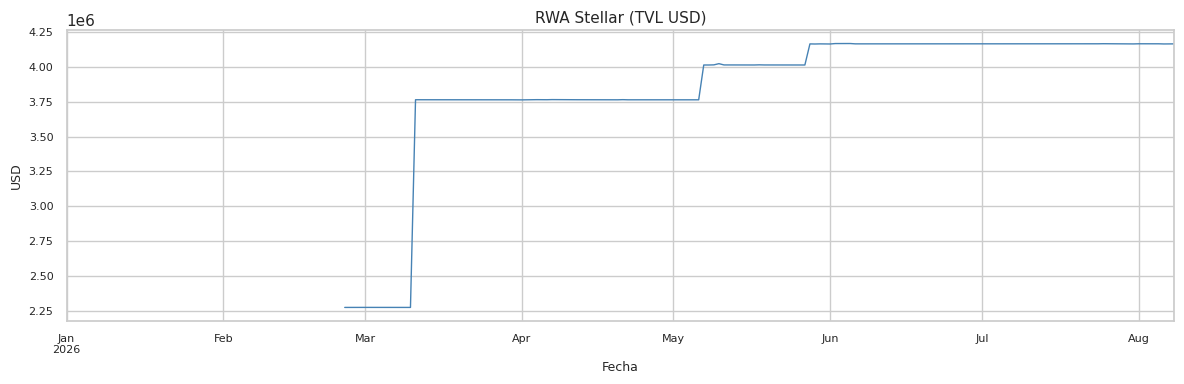

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_commodities.png


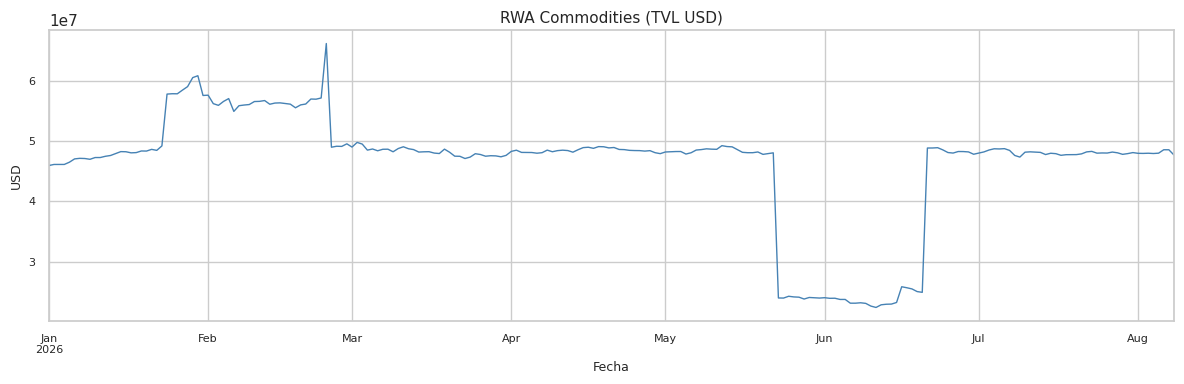

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_tipo_privatecredit.png


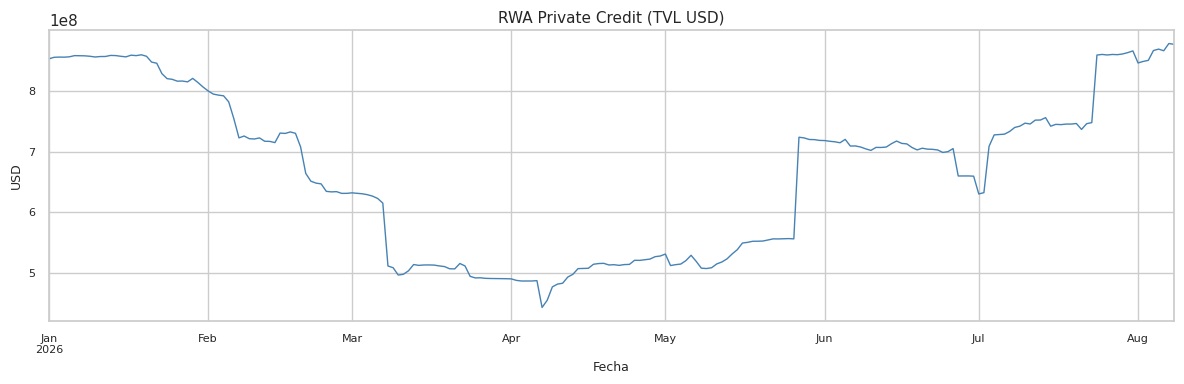

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/serie_rwa_total_global.png


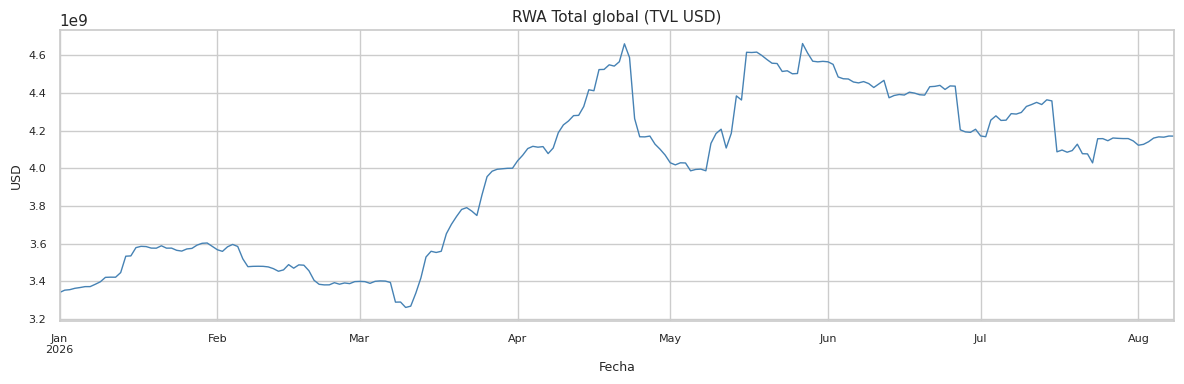

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/rwa_tipos_comparado.png


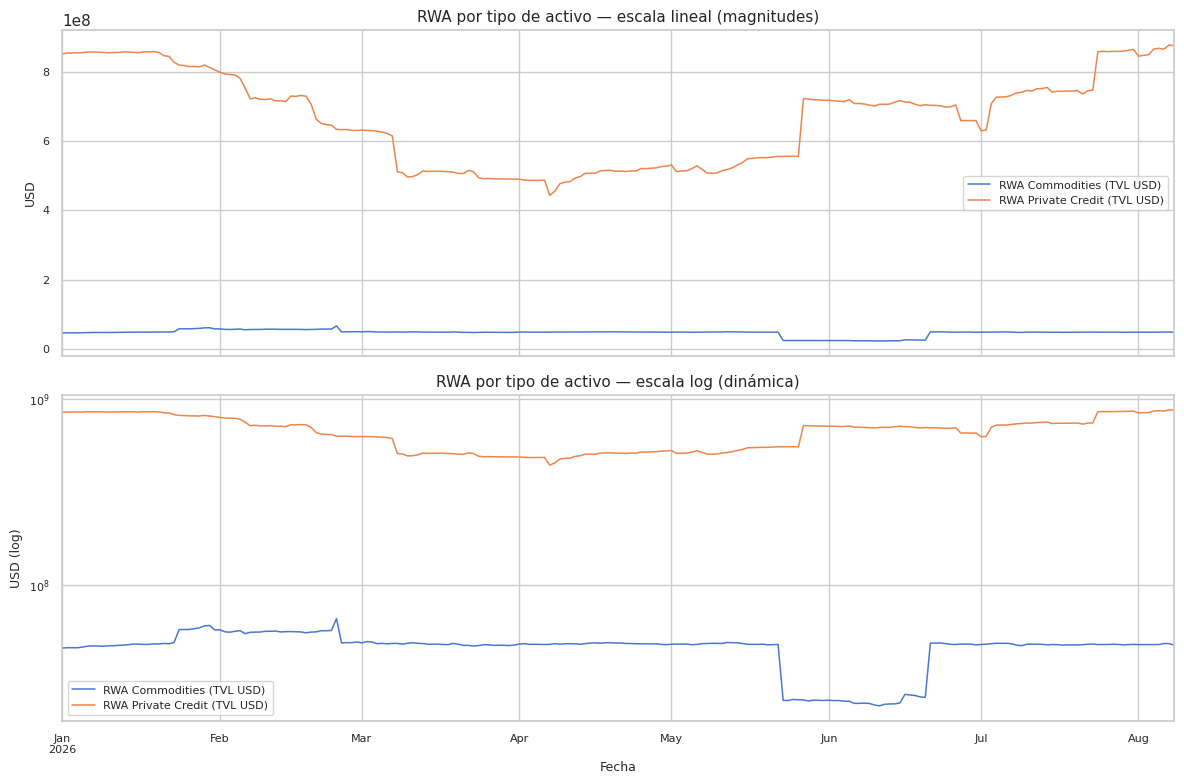


[DEBUG] === BLOQUE 3: ADF y transformación ===
[DEBUG] rwa_red_stellar larga: 243 obs (2026-02-25 → 2026-10-25)
[DEBUG] rwa_red_ripple sin historia larga: solo ADF de ventana
[DEBUG] rwa_tipo_treasuries sin historia larga: solo ADF de ventana
[DEBUG] rwa_tipo_commodities larga: 1526 obs (2022-08-22 → 2026-10-25)
[DEBUG] rwa_tipo_privatecredit larga: 1930 obs (2021-07-14 → 2026-10-25)
[DEBUG] rwa_total_global larga: 2013 obs (2021-04-22 → 2026-10-25)
                       serie  fuente  transf    n  adf_stat  p_valor             veredicto potencia
       RWA Stellar (TVL USD) ventana   nivel  164   -3.0904   0.0273 estacionaria (p<0.05)       ok
       RWA Stellar (TVL USD) ventana  1a_dif  163  -12.8122   0.0000 estacionaria (p<0.01)       ok
       RWA Stellar (TVL USD) ventana log_dif  163  -12.8005   0.0000 estacionaria (p<0.01)       ok
   RWA Commodities (TVL USD) ventana   nivel  219   -2.1795   0.2138       no estacionaria       ok
   RWA Commodities (TVL USD) ventana  1a_dif 

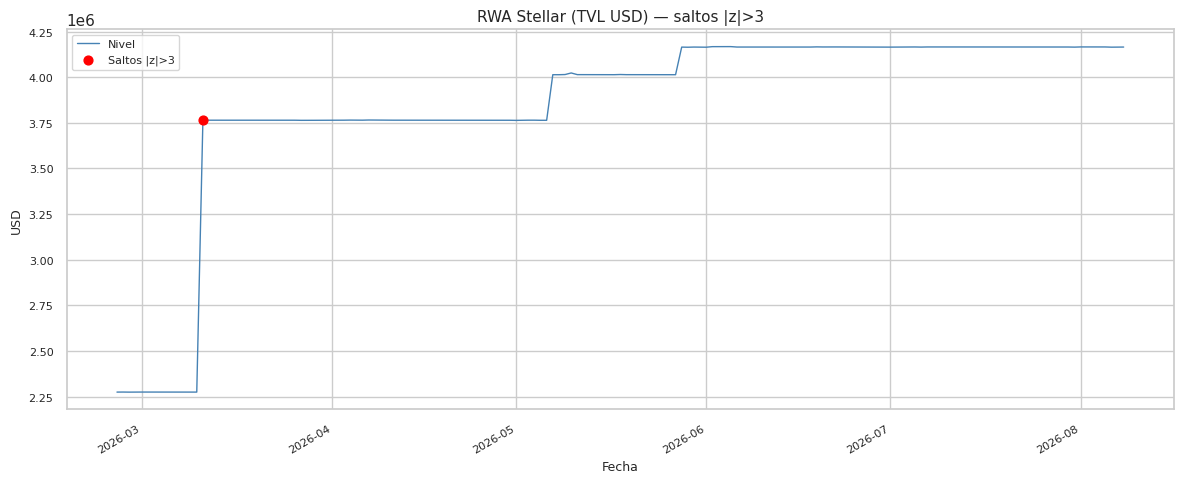

[DEBUG] rwa_red_stellar: 1 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/saltos_rwa_tipo_commodities.png


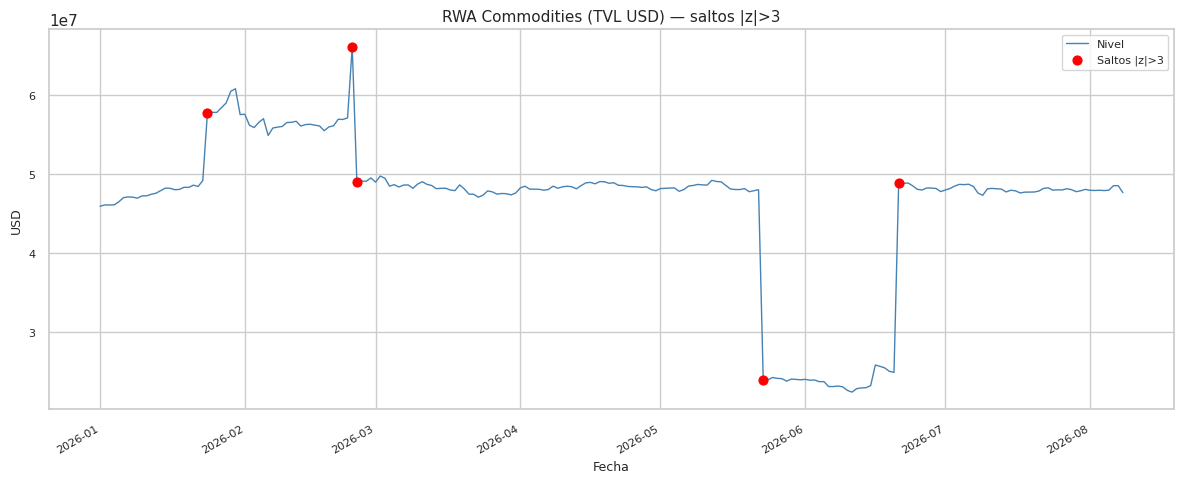

[DEBUG] rwa_tipo_commodities: 5 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/saltos_rwa_tipo_privatecredit.png


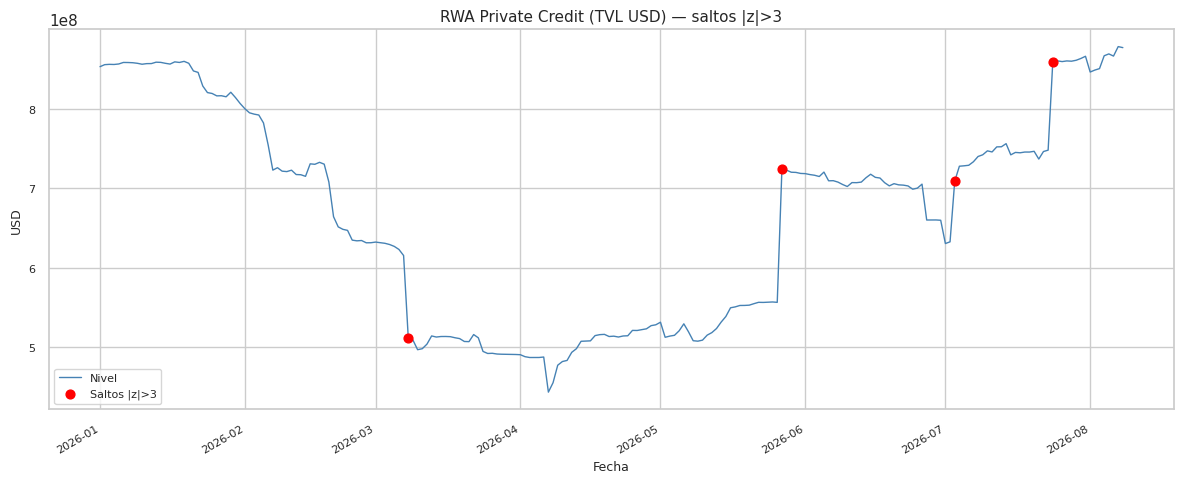

[DEBUG] rwa_tipo_privatecredit: 4 saltos
[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/saltos_rwa_total_global.png


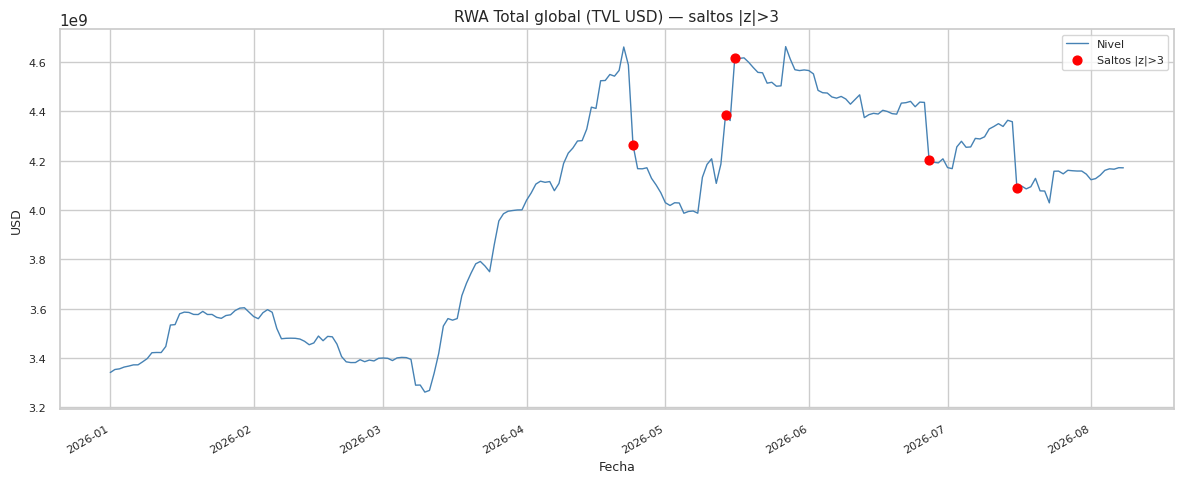

[DEBUG] rwa_total_global: 5 saltos
     fecha                  serie        valor   valor_prev    delta_abs  delta_pct   z_score
2026-03-11        rwa_red_stellar    3764603.0    2274781.0    1489822.0  65.492986 12.490480
2026-01-24   rwa_tipo_commodities   57771040.0   49189631.0    8581409.0  17.445565  3.122056
2026-02-24   rwa_tipo_commodities   66141927.0   57127523.0    9014404.0  15.779441  3.279733
2026-02-25   rwa_tipo_commodities   48975032.0   66141927.0  -17166895.0 -25.954634 -6.254249
2026-05-23   rwa_tipo_commodities   24014964.0   48042108.0  -24027144.0 -50.012676 -8.752425
2026-06-21   rwa_tipo_commodities   48840825.0   24947547.0   23893278.0  95.774057  8.697909
2026-03-08 rwa_tipo_privatecredit  511636253.0  615173480.0 -103537227.0 -16.830574 -5.689410
2026-05-27 rwa_tipo_privatecredit  723677808.0  556283566.0  167394242.0  30.091531  9.182664
2026-07-03 rwa_tipo_privatecredit  708653275.0  632400066.0   76253209.0  12.057748  4.179716
2026-07-24 rwa_tipo_priva

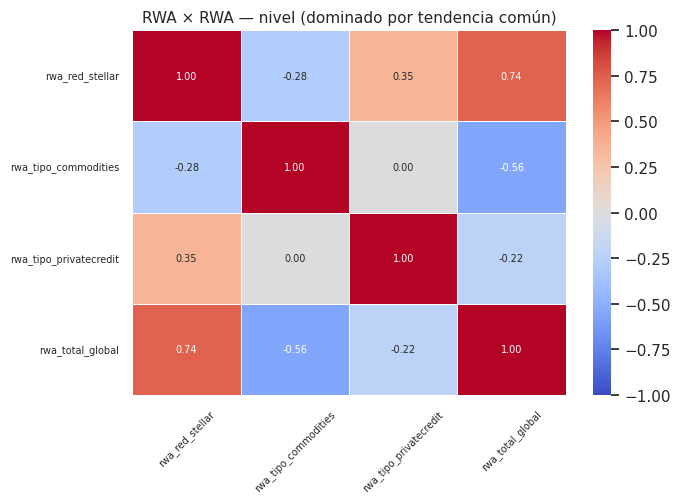

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_logdif.png


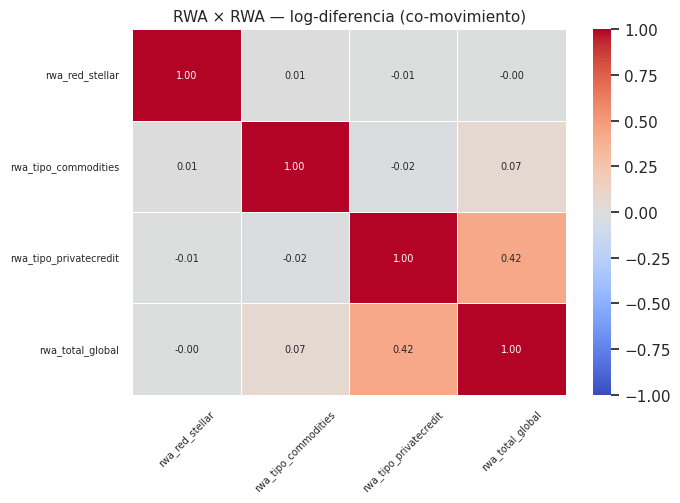

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_onchain_nivel.png


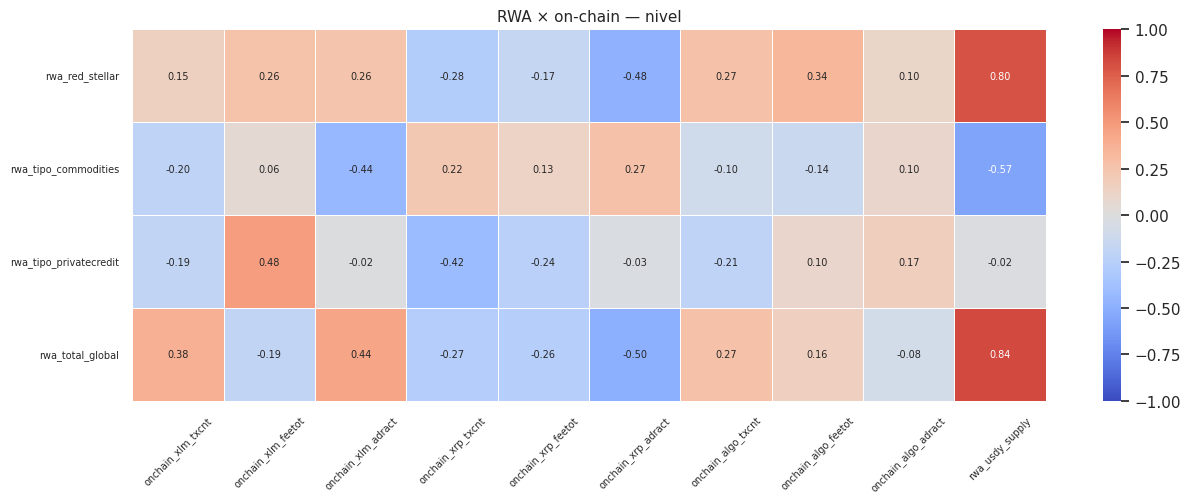

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_eda_rwa/corr_rwa_onchain_logdif.png


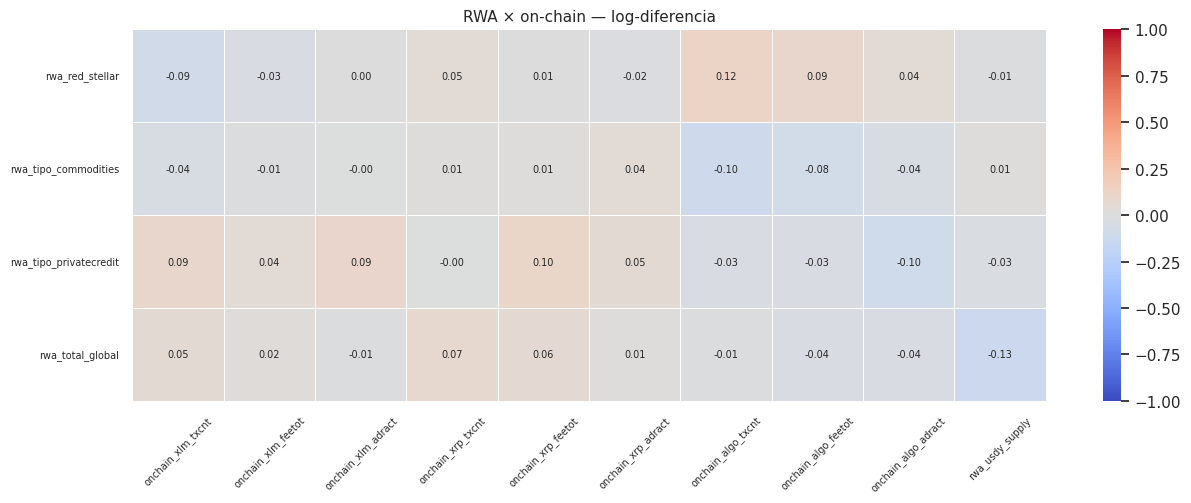

[DEBUG] correlaciones registradas: 112 pares
[DEBUG] pares de mayor |corr|:
        bloque  base                serie_a              serie_b    corr
rwa_vs_onchain nivel       rwa_total_global      rwa_usdy_supply  0.8356
rwa_vs_onchain nivel        rwa_red_stellar      rwa_usdy_supply  0.7993
    rwa_vs_rwa nivel       rwa_total_global      rwa_red_stellar  0.7403
    rwa_vs_rwa nivel        rwa_red_stellar     rwa_total_global  0.7403
rwa_vs_onchain nivel   rwa_tipo_commodities      rwa_usdy_supply -0.5681
    rwa_vs_rwa nivel   rwa_tipo_commodities     rwa_total_global -0.5555
    rwa_vs_rwa nivel       rwa_total_global rwa_tipo_commodities -0.5555
rwa_vs_onchain nivel       rwa_total_global   onchain_xrp_adract -0.4980
rwa_vs_onchain nivel rwa_tipo_privatecredit   onchain_xlm_feetot  0.4794
rwa_vs_onchain nivel        rwa_red_stellar   onchain_xrp_adract -0.4783
rwa_vs_onchain nivel       rwa_total_global   onchain_xlm_adract  0.4412
rwa_vs_onchain nivel   rwa_tipo_commodities   on

In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import os
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

try:
    from statsmodels.tsa.stattools import adfuller
    _HAS_STATSMODELS: bool = True
except ImportError:
    _HAS_STATSMODELS = False

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_eda_rwa"
)

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)

# --- Bloque RWA nuevo (6 series) ---
COLS_RWA_RED: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
]
COLS_RWA_TIPO: list[str] = [
    "rwa_tipo_treasuries",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
]
COL_RWA_TOTAL: str = "rwa_total_global"
COLS_RWA: list[str] = (
    COLS_RWA_RED + COLS_RWA_TIPO + [COL_RWA_TOTAL]
)

# --- Bloque on-chain existente (9 métricas + USDY previa) ---
COLS_ONCHAIN: list[str] = [
    "onchain_xlm_txcnt", "onchain_xlm_feetot",
    "onchain_xlm_adract",
    "onchain_xrp_txcnt", "onchain_xrp_feetot",
    "onchain_xrp_adract",
    "onchain_algo_txcnt", "onchain_algo_feetot",
    "onchain_algo_adract",
]
COL_USDY: str = "rwa_usdy_supply"
COLS_BLOQUE_ONCHAIN: list[str] = COLS_ONCHAIN + [COL_USDY]

ETIQUETAS: dict[str, str] = {
    "rwa_red_stellar": "RWA Stellar (TVL USD)",
    "rwa_red_ripple": "RWA Ripple/XRPL (TVL USD)",
    "rwa_tipo_treasuries": "RWA Treasuries (TVL USD)",
    "rwa_tipo_commodities": "RWA Commodities (TVL USD)",
    "rwa_tipo_privatecredit": "RWA Private Credit (TVL USD)",
    "rwa_total_global": "RWA Total global (TVL USD)",
    "onchain_xlm_txcnt": "XLM — Txs/día",
    "onchain_xlm_feetot": "XLM — Fees/día",
    "onchain_xlm_adract": "XLM — Addr./día",
    "onchain_xrp_txcnt": "XRP — Txs/día",
    "onchain_xrp_feetot": "XRP — Fees/día",
    "onchain_xrp_adract": "XRP — Addr./día",
    "onchain_algo_txcnt": "ALGO — Txs/día",
    "onchain_algo_feetot": "ALGO — Fees/día",
    "onchain_algo_adract": "ALGO — Addr./día",
    "rwa_usdy_supply": "USDY Supply (USD)",
}

ADF_ALPHA: float = 0.05
UMBRAL_SALTO_Z: float = 3.0
N_MIN_ADF: int = 15          # mínimo de obs. para correr ADF
N_POTENCIA_ADF: int = 50     # bajo esto, potencia reducida

# Orden de preferencia de transformación. La log-diferencia va
# antes que la 1ª diferencia: en series de adopción con
# crecimiento multiplicativo, la tasa de crecimiento es la
# lectura económica correcta y estabiliza la varianza.
ORDEN_TRANSF: list[str] = ["nivel", "log_dif", "1a_dif"]

sns.set_theme(style="whitegrid", palette="muted")

"""# 4. Funciones"""


def cargar_series(ruta: str) -> pd.DataFrame:
    """
    Carga un CSV de series con índice fecha (DatetimeIndex).

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame indexado por fecha.
    """
    df = pd.read_csv(
        ruta, parse_dates=["fecha"], index_col="fecha"
    )
    if DEBUG:
        print(f"[DEBUG] cargado: {df.shape} — {ruta}")
    return df


def estadistica_descriptiva(
    df: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Estadísticas básicas (n, media, std, min, max, CV, skew).

    Args:
        df: Dataset con las series en columnas.
        cols: Columnas a describir.

    Returns:
        DataFrame con una fila por serie.
    """
    filas: list[dict] = []
    for col in cols:
        s = (
            df[col].dropna()
            if col in df.columns
            else pd.Series(dtype=float)
        )
        if s.empty:
            filas.append({"serie": col, "n": 0})
            continue
        media = float(s.mean())
        cv = s.std() / media if media != 0 else float("nan")
        filas.append({
            "serie": col,
            "etiqueta": ETIQUETAS.get(col, col),
            "n": int(s.notna().sum()),
            "n_nulo": int(df[col].isna().sum()),
            "media": round(media, 4),
            "desvio": round(float(s.std()), 4),
            "min": round(float(s.min()), 4),
            "max": round(float(s.max()), 4),
            "cv": round(float(cv), 4),
            "skew": round(float(s.skew()), 4),
            "min_fecha": s.index.min().date().isoformat(),
            "max_fecha": s.index.max().date().isoformat(),
        })
    return pd.DataFrame(filas)


def _guardar_fig(ruta: str) -> None:
    """Guarda la figura activa a disco si SAVE_DATA=True."""
    if SAVE_DATA:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")


def plot_serie_simple(
    serie: pd.Series,
    titulo: str,
    fname: str,
) -> None:
    """
    Línea temporal simple para una serie.

    Args:
        serie: Serie con DatetimeIndex.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    fig, ax = plt.subplots(figsize=(12, 4))
    serie.plot(ax=ax, lw=1.0, color="steelblue")
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("Fecha", fontsize=9)
    ax.set_ylabel("USD", fontsize=9)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def plot_tipos_comparado(
    df: pd.DataFrame,
    cols: list[str],
    fname: str = "rwa_tipos_comparado.png",
) -> None:
    """
    Compara en un mismo eje las series por tipo de activo, para
    ver magnitudes relativas.

    Dibuja dos paneles: escala lineal (magnitudes absolutas) y
    escala logarítmica (dinámica relativa, legible cuando los
    órdenes de magnitud difieren).

    Args:
        df: Dataset con las series.
        cols: Columnas de tipo de activo a comparar.
        fname: Nombre del archivo PNG.
    """
    presentes = [c for c in cols if c in df.columns]
    if not presentes:
        if DEBUG:
            print("[DEBUG] sin columnas de tipo para comparar")
        return
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    for col in presentes:
        etq = ETIQUETAS.get(col, col)
        df[col].plot(ax=axes[0], lw=1.1, label=etq)
        positivos = df[col].where(df[col] > 0)
        positivos.plot(ax=axes[1], lw=1.1, label=etq)
    axes[0].set_title(
        "RWA por tipo de activo — escala lineal (magnitudes)",
        fontsize=11,
    )
    axes[0].set_ylabel("USD", fontsize=9)
    axes[0].legend(fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_title(
        "RWA por tipo de activo — escala log (dinámica)",
        fontsize=11,
    )
    axes[1].set_ylabel("USD (log)", fontsize=9)
    axes[1].set_xlabel("Fecha", fontsize=9)
    axes[1].legend(fontsize=8)
    for ax in axes:
        ax.tick_params(labelsize=8)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def _veredicto_adf(p: float) -> str:
    """Clasifica el resultado ADF según significancia."""
    if p < 0.01:
        return "estacionaria (p<0.01)"
    if p < 0.05:
        return "estacionaria (p<0.05)"
    if p < 0.10:
        return "borderline (p<0.10)"
    return "no estacionaria"


def _adf_una(
    s: pd.Series,
    nombre: str,
    transf: str,
    fuente: str,
) -> dict:
    """
    Corre ADF sobre una transformación concreta de la serie.

    Args:
        s: Serie ya transformada.
        nombre: Nombre de la serie original.
        transf: "nivel" | "1a_dif" | "log_dif".
        fuente: "ventana" (grilla 2026) | "larga" (historia).

    Returns:
        Dict con serie, fuente, transf, n, adf_stat, p_valor,
        veredicto y aviso de potencia.
    """
    sc = s.dropna()
    base: dict = {
        "serie": nombre,
        "fuente": fuente,
        "transf": transf,
        "n": int(len(sc)),
        "adf_stat": None,
        "p_valor": None,
        "veredicto": "n/a",
        "potencia": "",
    }
    if len(sc) < N_MIN_ADF:
        base["veredicto"] = f"n<{N_MIN_ADF} ({len(sc)})"
        return base
    if float(sc.std()) == 0:
        base["veredicto"] = "constante"
        return base
    try:
        stat, pval, _, nobs, *_ = adfuller(sc, autolag="AIC")
        base["adf_stat"] = round(float(stat), 4)
        base["p_valor"] = round(float(pval), 4)
        base["n"] = int(nobs)
        base["veredicto"] = _veredicto_adf(float(pval))
        base["potencia"] = (
            f"n<{N_POTENCIA_ADF}: potencia reducida"
            if int(nobs) < N_POTENCIA_ADF else "ok"
        )
    except Exception as exc:
        base["veredicto"] = f"error: {exc}"
    return base


def adf_serie(
    serie: pd.Series,
    nombre: str,
    fuente: str,
) -> list[dict]:
    """
    ADF en nivel, 1ª diferencia y log-diferencia.

    La log-diferencia solo se calcula si la serie es
    estrictamente positiva en todo su recorrido; si tiene ceros
    o negativos se registra "n/a" en lugar de forzar el cálculo.

    Args:
        serie: Serie a testear (sin transformar).
        nombre: Nombre de la serie.
        fuente: "ventana" o "larga".

    Returns:
        Lista de 3 dicts (uno por transformación).
    """
    if not _HAS_STATSMODELS:
        return [{
            "serie": nombre,
            "fuente": fuente,
            "transf": "—",
            "n": 0,
            "adf_stat": None,
            "p_valor": None,
            "veredicto": "statsmodels no disponible",
            "potencia": "",
        }]
    resultados: list[dict] = []
    resultados.append(
        _adf_una(serie, nombre, "nivel", fuente)
    )
    resultados.append(
        _adf_una(serie.diff(), nombre, "1a_dif", fuente)
    )
    s_pos = serie.dropna()
    if not s_pos.empty and (s_pos > 0).all():
        log_dif = np.log(serie).diff()
        resultados.append(
            _adf_una(log_dif, nombre, "log_dif", fuente)
        )
    else:
        resultados.append({
            "serie": nombre,
            "fuente": fuente,
            "transf": "log_dif",
            "n": 0,
            "adf_stat": None,
            "p_valor": None,
            "veredicto": "n/a (valores ≤ 0)",
            "potencia": "",
        })
    return resultados


def _es_estacionaria(fila: pd.Series) -> bool:
    """
    Indica si una fila de la tabla ADF pasa el umbral ADF_ALPHA.

    Args:
        fila: Fila con columna p_valor.

    Returns:
        True si p_valor < ADF_ALPHA.
    """
    pval = fila.get("p_valor")
    return pval is not None and not pd.isna(pval) and (
        float(pval) < ADF_ALPHA
    )


def elegir_transformacion(
    df_adf: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Decide la transformación estacionaria de cada serie.

    Criterio:
      - Se prioriza la evidencia de la serie LARGA (más
        observaciones ⇒ más potencia del ADF). Si no hay serie
        larga para esa columna, se usa la ventana diaria.
      - Dentro de esa fuente se toma la primera transformación
        de ORDEN_TRANSF que resulte estacionaria a ADF_ALPHA:
        nivel → log_dif → 1a_dif. La log-diferencia precede a la
        1ª diferencia por ser la tasa de crecimiento, lectura
        económica correcta en series de adopción.
      - Si ninguna transformación resulta estacionaria, se
        registra "ninguna" y se deja anotado: la serie NO entra
        al modelo sin tratamiento adicional.

    Args:
        df_adf: Tabla ADF larga (serie, fuente, transf, p_valor).
        cols: Series a resolver.

    Returns:
        DataFrame con serie, fuente_decision, transf_elegida,
        p_valor, n, veredicto y nota.
    """
    filas: list[dict] = []
    for col in cols:
        etiqueta = ETIQUETAS.get(col, col)
        sub = df_adf[df_adf["serie"] == etiqueta]
        if sub.empty:
            filas.append({
                "serie": col,
                "etiqueta": etiqueta,
                "fuente_decision": "s/d",
                "transf_elegida": "s/d",
                "p_valor": None,
                "n": 0,
                "nota": "sin resultados ADF",
            })
            continue
        elegida: dict | None = None
        for fuente in ("larga", "ventana"):
            sub_f = sub[sub["fuente"] == fuente]
            if sub_f.empty:
                continue
            for transf in ORDEN_TRANSF:
                cand = sub_f[sub_f["transf"] == transf]
                if cand.empty:
                    continue
                fila_c = cand.iloc[0]
                if _es_estacionaria(fila_c):
                    elegida = {
                        "fuente_decision": fuente,
                        "transf_elegida": transf,
                        "p_valor": fila_c["p_valor"],
                        "n": fila_c["n"],
                        "nota": str(fila_c["potencia"]),
                    }
                    break
            if elegida is not None:
                break
        if elegida is None:
            filas.append({
                "serie": col,
                "etiqueta": etiqueta,
                "fuente_decision": "—",
                "transf_elegida": "ninguna",
                "p_valor": None,
                "n": 0,
                "nota": (
                    "ninguna transformación resultó estacionaria "
                    f"a alpha={ADF_ALPHA}: no usar sin "
                    "tratamiento adicional"
                ),
            })
            continue
        filas.append({
            "serie": col,
            "etiqueta": etiqueta,
            **elegida,
        })
    return pd.DataFrame(filas)


def detectar_saltos(
    serie: pd.Series,
    nombre: str,
    umbral_z: float = UMBRAL_SALTO_Z,
) -> pd.DataFrame:
    """
    Detecta variaciones diarias anómalas en una serie de TVL.

    Mismo criterio que la detección de saltos de USDY en la
    Fase 3: z sobre la variación diaria absoluta. Sirve para
    identificar mint/redención y altas de emisores.

    Trabaja ÚNICAMENTE sobre la Series numérica (diff /
    pct_change / z-score); la fecha queda como índice compartido
    y se convierte en columna al final con reset_index(). Así se
    evita la mezcla DateTime64/Float64 que dispara el error de
    dtype promotion en pandas >= 2.x.

    Args:
        serie: Serie de nivel con DatetimeIndex.
        nombre: Nombre de la serie (columna 'serie').
        umbral_z: Umbral de |z| para marcar salto.

    Returns:
        DataFrame con fecha, serie, valor, valor_prev,
        delta_abs, delta_pct, z_score. Vacío si no hay saltos.
    """
    # Serie numérica pura: sin fechas dentro de los cálculos
    s = pd.to_numeric(serie, errors="coerce").dropna()
    s = s.astype("float64")
    if len(s) < 3:
        return pd.DataFrame()
    delta = s.diff()                       # variación absoluta
    delta_pct = s.pct_change() * 100.0     # variación %
    media_d = float(delta.mean())
    std_d = float(delta.std())
    if std_d == 0 or pd.isna(std_d):
        return pd.DataFrame()
    z = (delta - media_d) / std_d
    mask = z.abs() > umbral_z
    if not bool(mask.any()):
        return pd.DataFrame()
    # Todas las columnas son float64 y comparten el DatetimeIndex
    df_sal = pd.DataFrame({
        "valor": s[mask].astype("float64"),
        "valor_prev": s.shift(1)[mask].astype("float64"),
        "delta_abs": delta[mask].astype("float64"),
        "delta_pct": delta_pct[mask].astype("float64"),
        "z_score": z[mask].astype("float64"),
    })
    df_sal.index = pd.DatetimeIndex(df_sal.index, name="fecha")
    # La fecha pasa a columna recién acá, ya fuera del cálculo
    df_sal = df_sal.reset_index()
    df_sal.insert(1, "serie", nombre)
    return df_sal


def umbral_texto(umbral: float) -> str:
    """Formatea el umbral de z para las leyendas."""
    return f"{umbral:.0f}"


def plot_serie_con_saltos(
    serie: pd.Series,
    saltos: pd.DataFrame,
    titulo: str,
    fname: str,
) -> None:
    """
    Trayectoria de una serie con los saltos destacados.

    Dibuja con arrays explícitos (index.to_numpy() y
    to_numpy(dtype="float64")) en lugar de Series.plot(): así
    matplotlib recibe fechas y valores por separado y no
    intenta promover DateTime64 contra Float64.

    Args:
        serie: Serie de nivel con DatetimeIndex.
        saltos: Salida de detectar_saltos para esa serie.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.
    """
    s = pd.to_numeric(serie, errors="coerce")
    fechas = s.index.to_numpy()
    valores = s.to_numpy(dtype="float64")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        fechas, valores,
        color="steelblue", lw=1.0, label="Nivel",
    )
    if not saltos.empty and "valor" in saltos.columns:
        x_saltos = pd.to_datetime(saltos["fecha"]).to_numpy()
        y_saltos = saltos["valor"].to_numpy(dtype="float64")
        ax.scatter(
            x_saltos, y_saltos,
            color="red", zorder=5, s=40,
            label=f"Saltos |z|>{umbral_texto(UMBRAL_SALTO_Z)}",
        )
    ax.set_title(titulo, fontsize=11)
    ax.set_ylabel("USD", fontsize=9)
    ax.set_xlabel("Fecha", fontsize=9)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    fig.autofmt_xdate()
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()


def matriz_correlacion(
    df: pd.DataFrame,
    filas: list[str],
    columnas: list[str],
    titulo: str,
    fname: str,
) -> pd.DataFrame:
    """
    Correlación de Pearson entre dos bloques de series y su
    heatmap. Admite matriz cuadrada (filas == columnas) o
    rectangular (RWA × on-chain).

    Excluye series ausentes o de varianza cero. La correlación
    se calcula por pares (pairwise), sin descartar filas
    completas por un NaN aislado.

    Args:
        df: Dataset con las series.
        filas: Series del eje vertical.
        columnas: Series del eje horizontal.
        titulo: Título de la figura.
        fname: Nombre del archivo PNG.

    Returns:
        DataFrame de correlación (filas × columnas).
    """
    def _validas(cols: list[str]) -> list[str]:
        return [
            c for c in cols
            if c in df.columns
            and df[c].notna().sum() > 2
            and float(df[c].std()) > 0
        ]

    f_ok = _validas(filas)
    c_ok = _validas(columnas)
    if not f_ok or not c_ok:
        if DEBUG:
            print(f"[DEBUG] {titulo}: sin columnas válidas")
        return pd.DataFrame()
    corr_full = df[list(dict.fromkeys(f_ok + c_ok))].corr(
        method="pearson"
    )
    corr = corr_full.loc[f_ok, c_ok]
    ancho = max(6.0, 1.0 * len(c_ok) + 3.0)
    alto = max(4.0, 0.8 * len(f_ok) + 2.0)
    fig, ax = plt.subplots(figsize=(ancho, alto))
    sns.heatmap(
        corr, annot=True, fmt=".2f", cmap="coolwarm",
        center=0, vmin=-1, vmax=1, ax=ax,
        annot_kws={"size": 7}, linewidths=0.4,
    )
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    plt.tight_layout()
    _guardar_fig(os.path.join(DIR_FIGURAS, fname))
    plt.show()
    plt.close()
    return corr


def corr_a_largo(
    corr: pd.DataFrame,
    bloque: str,
    base: str,
) -> pd.DataFrame:
    """
    Pasa una matriz de correlación a formato largo, para poder
    apilar bloques y bases distintas en un único CSV.

    Args:
        corr: Matriz de correlación.
        bloque: "rwa_vs_rwa" | "rwa_vs_onchain".
        base: "nivel" | "log_dif".

    Returns:
        DataFrame con bloque, base, serie_a, serie_b, corr.
    """
    if corr.empty:
        return pd.DataFrame()
    largo = (
        corr.stack()
        .rename("corr")
        .reset_index()
    )
    largo.columns = ["serie_a", "serie_b", "corr"]
    largo.insert(0, "base", base)
    largo.insert(0, "bloque", bloque)
    largo["corr"] = largo["corr"].round(4)
    return largo


def log_diferencias(
    df: pd.DataFrame,
    cols: list[str],
) -> pd.DataFrame:
    """
    Construye el DataFrame de log-diferencias de las columnas
    estrictamente positivas.

    Las columnas con ceros o negativos se omiten (no se fuerza
    el logaritmo ni se desplaza la serie: sería inventar dato).

    Args:
        df: Dataset de niveles.
        cols: Columnas a transformar.

    Returns:
        DataFrame de log-diferencias.
    """
    datos: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        s = df[col].dropna()
        if s.empty or not bool((s > 0).all()):
            if DEBUG:
                print(
                    f"[DEBUG] {col}: no positiva — sin log_dif"
                )
            continue
        datos[col] = np.log(df[col]).diff()
    return pd.DataFrame(datos, index=df.index)


"""# 5. Proceso"""

# ── Carga de datos ──────────────────────────────────────────
try:
    df = cargar_series(ARCHIVO_DIARIAS)
except Exception as _exc:
    raise RuntimeError(
        f"Error cargando {ARCHIVO_DIARIAS}: {_exc}"
    ) from _exc

cols_rwa_presentes: list[str] = [
    c for c in COLS_RWA if c in df.columns
]
cols_onchain_presentes: list[str] = [
    c for c in COLS_BLOQUE_ONCHAIN if c in df.columns
]

if DEBUG:
    print(f"[DEBUG] dataset: {df.shape}")
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()}"
    )
    print(f"[DEBUG] RWA presentes: {cols_rwa_presentes}")
    _faltan = [c for c in COLS_RWA if c not in df.columns]
    if _faltan:
        print(f"[DEBUG] RWA AUSENTES: {_faltan}")
    print(
        f"[DEBUG] on-chain presentes: "
        f"{len(cols_onchain_presentes)}/"
        f"{len(COLS_BLOQUE_ONCHAIN)}"
    )

try:
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    df_lrg = None
    if DEBUG:
        print(f"[DEBUG] series_largas_ext no cargado: {_exc}")

# ── Bloque 1: descriptiva ───────────────────────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 1: descriptiva RWA ===")
df_desc = pd.DataFrame()
try:
    df_desc = estadistica_descriptiva(df, COLS_RWA)
    if DEBUG:
        print(df_desc.to_string(index=False))
        print(
            "[DEBUG] CV alto + skew alto = serie con nivel "
            "creciente, coherente con adopción incipiente."
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Bloque 1 falló: {_exc}")

# ── Bloque 2: series en el tiempo ───────────────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 2: series en el tiempo ===")
try:
    for _col in cols_rwa_presentes:
        plot_serie_simple(
            df[_col],
            ETIQUETAS.get(_col, _col),
            f"serie_{_col}.png",
        )
    plot_tipos_comparado(df, COLS_RWA_TIPO)
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Bloque 2 falló: {_exc}")

# ── Bloque 3: ADF (ventana + serie larga) ───────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 3: ADF y transformación ===")
df_adf = pd.DataFrame()
df_transf = pd.DataFrame()
try:
    resultados_adf: list[dict] = []

    # 3.a Ventana diaria 2026 (n corto ⇒ poca potencia)
    for _col in cols_rwa_presentes:
        _nombre = ETIQUETAS.get(_col, _col)
        try:
            resultados_adf.extend(
                adf_serie(df[_col], _nombre, "ventana")
            )
        except Exception as _e:
            if DEBUG:
                print(f"[DEBUG] ADF ventana {_col}: {_e}")

    # 3.b Serie larga (más observaciones ⇒ más potencia)
    if df_lrg is not None:
        for _col in COLS_RWA:
            if _col not in df_lrg.columns:
                if DEBUG:
                    print(
                        f"[DEBUG] {_col} sin historia larga: "
                        "solo ADF de ventana"
                    )
                continue
            _serie_lrg = df_lrg[_col].dropna()
            if _serie_lrg.empty:
                continue
            _nombre = ETIQUETAS.get(_col, _col)
            if DEBUG:
                print(
                    f"[DEBUG] {_col} larga: {len(_serie_lrg)} "
                    f"obs ({_serie_lrg.index.min().date()} → "
                    f"{_serie_lrg.index.max().date()})"
                )
            try:
                resultados_adf.extend(
                    adf_serie(_serie_lrg, _nombre, "larga")
                )
            except Exception as _e:
                if DEBUG:
                    print(f"[DEBUG] ADF larga {_col}: {_e}")

    df_adf = pd.DataFrame(resultados_adf)
    if DEBUG and not df_adf.empty:
        _adf_cols = [
            "serie", "fuente", "transf", "n",
            "adf_stat", "p_valor", "veredicto", "potencia",
        ]
        print(df_adf[_adf_cols].to_string(index=False))

    # 3.c Transformación elegida por serie
    df_transf = elegir_transformacion(df_adf, COLS_RWA)
    if DEBUG and not df_transf.empty:
        print("\n[DEBUG] Transformación elegida por serie:")
        print(df_transf.to_string(index=False))

except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Bloque 3 falló: {_exc}")

# ── Bloque 4: saltos |z|>3 ──────────────────────────────────
# ── Bloque 4: saltos |z|>3 ──────────────────────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUE 4: saltos por serie ===")
df_saltos = pd.DataFrame()
try:
    _bloques_saltos: list[pd.DataFrame] = []
    for _col in cols_rwa_presentes:
        try:
            _sal = detectar_saltos(
                df[_col], _col, UMBRAL_SALTO_Z
            )
        except Exception as _e:
            _sal = pd.DataFrame()
            if DEBUG:
                print(f"[DEBUG] saltos {_col}: {_e}")
        if not _sal.empty:
            _bloques_saltos.append(_sal)
        plot_serie_con_saltos(
            df[_col],
            _sal,
            f"{ETIQUETAS.get(_col, _col)} — saltos "
            f"|z|>{umbral_texto(UMBRAL_SALTO_Z)}",
            f"saltos_{_col}.png",
        )
        if DEBUG:
            print(f"[DEBUG] {_col}: {len(_sal)} saltos")
    if _bloques_saltos:
        df_saltos = pd.concat(
            _bloques_saltos, ignore_index=True
        )
        df_saltos = df_saltos.sort_values(
            ["serie", "fecha"]
        ).reset_index(drop=True)
        if DEBUG:
            print(df_saltos.to_string(index=False))
            print(
                "[DEBUG] Los saltos son candidatos a eventos de "
                "mint/redención o alta de emisor, NO a respuesta "
                "a estrés: verificar caso por caso."
            )
    elif DEBUG:
        print("[DEBUG] sin saltos por encima del umbral")
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Bloque 4 falló: {_exc}")

# ── Bloques 5 y 6: correlaciones ────────────────────────────
if DEBUG:
    print("\n[DEBUG] === BLOQUES 5-6: correlaciones ===")
df_corr = pd.DataFrame()
try:
    _piezas_corr: list[pd.DataFrame] = []

    # Log-diferencias: lectura interpretable (sin tendencia)
    df_ld = log_diferencias(
        df, cols_rwa_presentes + cols_onchain_presentes
    )
    _ld_rwa = [c for c in cols_rwa_presentes if c in df_ld]
    _ld_onchain = [
        c for c in cols_onchain_presentes if c in df_ld
    ]

    # Bloque 5: RWA × RWA
    _corr_rwa_nivel = matriz_correlacion(
        df, cols_rwa_presentes, cols_rwa_presentes,
        "RWA × RWA — nivel (dominado por tendencia común)",
        "corr_rwa_nivel.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_rwa_nivel, "rwa_vs_rwa", "nivel")
    )
    _corr_rwa_ld = matriz_correlacion(
        df_ld, _ld_rwa, _ld_rwa,
        "RWA × RWA — log-diferencia (co-movimiento)",
        "corr_rwa_logdif.png",
    )
    _piezas_corr.append(
        corr_a_largo(_corr_rwa_ld, "rwa_vs_rwa", "log_dif")
    )

    # Bloque 6: RWA × on-chain (9 métricas + USDY previa)
    _corr_mix_nivel = matriz_correlacion(
        df, cols_rwa_presentes, cols_onchain_presentes,
        "RWA × on-chain — nivel",
        "corr_rwa_onchain_nivel.png",
    )
    _piezas_corr.append(
        corr_a_largo(
            _corr_mix_nivel, "rwa_vs_onchain", "nivel"
        )
    )
    _corr_mix_ld = matriz_correlacion(
        df_ld, _ld_rwa, _ld_onchain,
        "RWA × on-chain — log-diferencia",
        "corr_rwa_onchain_logdif.png",
    )
    _piezas_corr.append(
        corr_a_largo(
            _corr_mix_ld, "rwa_vs_onchain", "log_dif"
        )
    )

    _piezas_corr = [p for p in _piezas_corr if not p.empty]
    if _piezas_corr:
        df_corr = pd.concat(_piezas_corr, ignore_index=True)
    if DEBUG and not df_corr.empty:
        print(
            "[DEBUG] correlaciones registradas: "
            f"{len(df_corr)} pares"
        )
        _fuera_diag = df_corr[
            df_corr["serie_a"] != df_corr["serie_b"]
        ]
        _top = _fuera_diag.reindex(
            _fuera_diag["corr"].abs().sort_values(
                ascending=False
            ).index
        ).head(12)
        print("[DEBUG] pares de mayor |corr|:")
        print(_top.to_string(index=False))
        print(
            "[DEBUG] RECORDATORIO: la correlación alta entre "
            "tipos y total es esperable por construcción (tags "
            "no exclusivos), no es un hallazgo."
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Bloques 5-6 fallaron: {_exc}")

# ── Resumen: insumo para el modelo ──────────────────────────
print("\n[RWA] === Transformación por serie (insumo modelo) ===")
if df_transf.empty:
    print("[RWA] sin decisión de transformación disponible")
else:
    for _, _f in df_transf.iterrows():
        print(
            f"[RWA] {_f['serie']}: {_f['transf_elegida']} "
            f"(fuente={_f['fuente_decision']}, "
            f"p={_f['p_valor']}, n={_f['n']}) {_f['nota']}"
        )
    _sin_transf = df_transf[
        df_transf["transf_elegida"].isin(["ninguna", "s/d"])
    ]["serie"].tolist()
    if _sin_transf:
        print(
            f"[RWA] SIN transformación estacionaria: "
            f"{_sin_transf} — no usar sin tratamiento adicional."
        )
print(
    "[RWA] NOTA: adopción incipiente — la dinámica de estas "
    "series está dominada por crecimiento estructural, no por "
    "respuesta a estrés. Interpretar en consecuencia."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    _guardados: list[str] = []

    if not df_desc.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "eda_rwa_descriptiva.csv"
        )
        df_desc.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_adf.empty:
        _ruta = os.path.join(DIR_REPORTES, "eda_rwa_adf.csv")
        df_adf.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_transf.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "eda_rwa_transformacion.csv"
        )
        df_transf.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_saltos.empty:
        _ruta = os.path.join(
            DIR_REPORTES, "eda_rwa_saltos.csv"
        )
        df_saltos.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if not df_corr.empty:
        _ruta = os.path.join(DIR_REPORTES, "eda_rwa_corr.csv")
        df_corr.to_csv(_ruta, index=False)
        _guardados.append(_ruta)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")

# Job 4 - Relaciones temporales: RWA vs. estrés financiero

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[DEBUG] cargado: (220, 19) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_diarias_ext.csv
[DEBUG] cargado: (2357, 10) — /content/drive/MyDrive/Tesis/expansion/data/processed/series_largas_ext.csv

[DEBUG] ══ RECORTE DE VENTANA ══
[DEBUG] motivo: artefacto de DeFiLlama en rwa_red_ripple entre 2026-08-02 y 2026-08-05 (protocolo que aparece y desaparece del reporte; no es actividad real)
[DEBUG] rwa_red_ripple ausente del dataset
[DEBUG] recorte <= 2026-07-31: 220 → 212 filas (8 descartadas)
[DEBUG] ventana de análisis: 2026-01-01 → 2026-07-31 (212 días, 19 columnas)

[DEBUG] ══ PISTA A: DIARIA (RWA vs ΔCISS) ══
[DEBUG] A: rwa_red_ripple ausente — se omite
[DEBUG] A-x RWA-Stellar*: 156 obs
[DEBUG] A-x RWA-Algorand*: 211 obs
[DEBUG] A-x RWA-Treasuries*: 211 obs
[DEBUG] A-x RWA-Commodities*: 211 obs
[DEBUG] A-x RWA-PrivCredit*: 211 obs
[DEBUG] A-x 

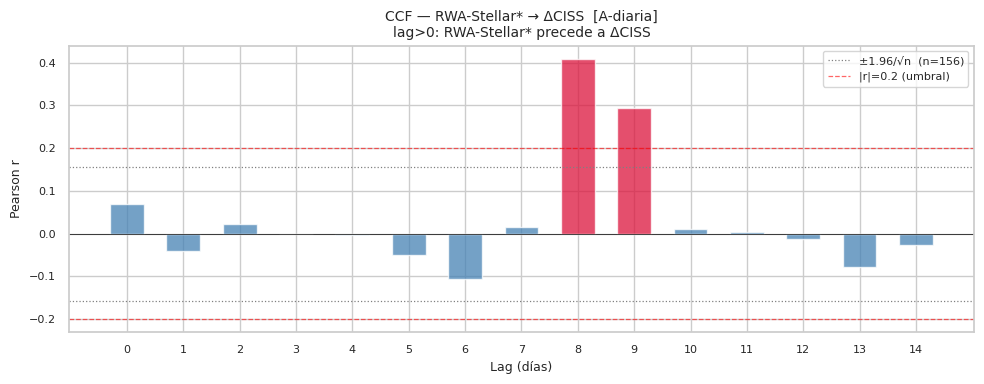

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_A_rwa_tipo_privatecredit.png


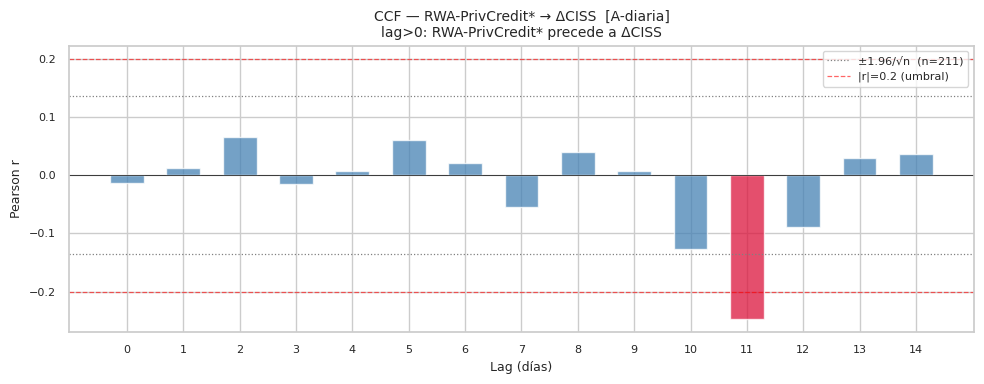

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_A_rwa_red_algorand.png


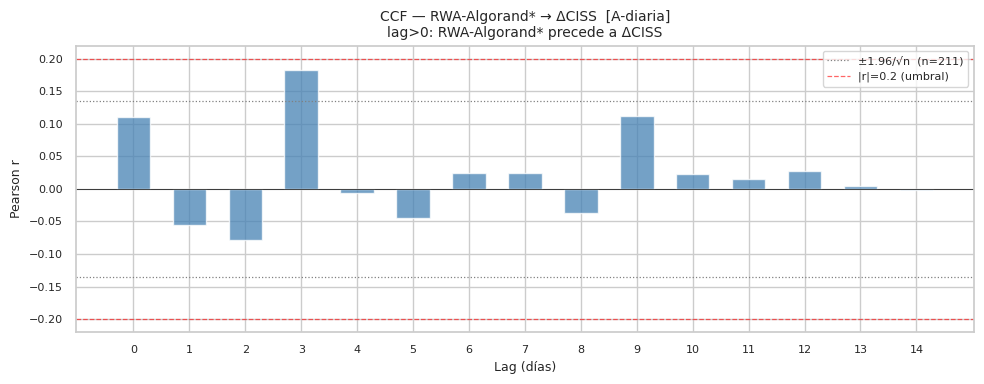

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_tipo_privatecredit.png


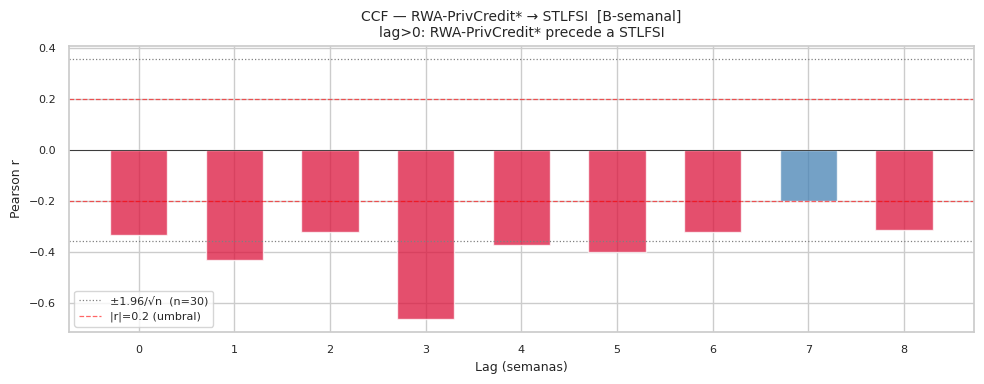

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_red_stellar.png


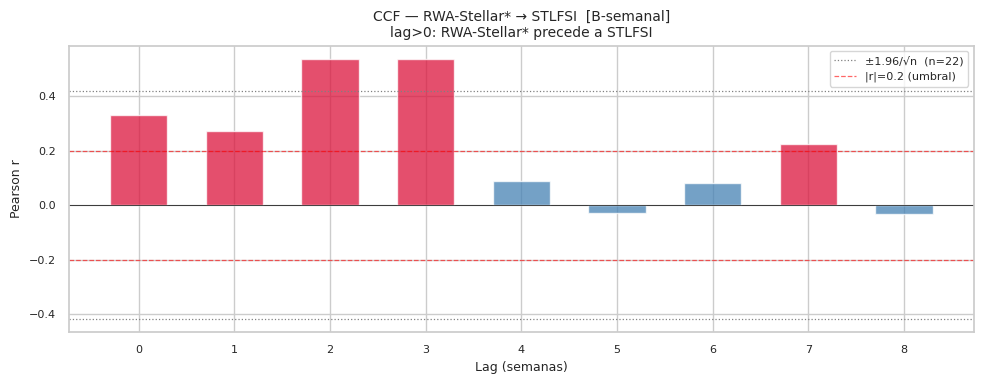

[DEBUG] figura: /content/drive/MyDrive/Tesis/expansion/outputs/reportes/figuras_relaciones_rwa/ccf_B_rwa_tipo_treasurybills.png


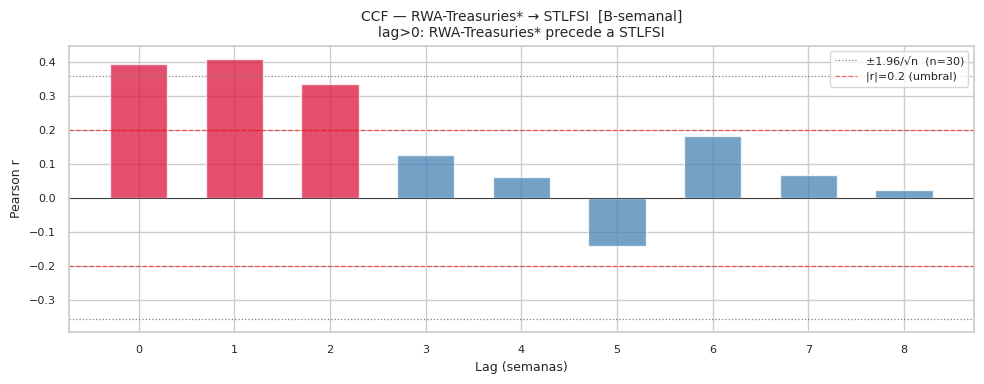


──────────────────────────────────────────────────────────────
RESUMEN — SEÑAL RWA → ESTRÉS
──────────────────────────────────────────────────────────────

Ventana analizada: 2026-01-01 → 2026-07-31 (recorte en 2026-07-31)

FDR (Benjamini-Hochberg) sobre el conjunto COMPLETO de tests — 2 pistas, todos los lags:
  168 tests totales | p<0.05 crudo: 12 | sobreviven BH global: 4

Pares PRECEDEN (lag>0, |r|>0.2, BH GLOBAL q<0.05): 3
    pista        etiqueta  macro  lag_optimo   r_max   bh_q   n
 A-diaria    RWA-Stellar*   CISS           8  0.4097 0.0000 148
 A-diaria RWA-PrivCredit*   CISS          11 -0.2472 0.0168 200
B-semanal RWA-PrivCredit* STLFSI           3 -0.6623 0.0168  27

Pares CONTEMPORÁNEOS (lag=0, |r|>0.2, p<0.05): 0
  → Ninguno contemporáneo.

INDICIOS NO CONFIRMADOS — dirección teórica previa (oro, treasuries), NO sobreviven el FDR global: 2
    pista         etiqueta  macro  lag_optimo  r_max  p_lag_opt   bh_q  n
B-semanal  RWA-Treasuries* STLFSI           1 0.4088     0

In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

"""# 2. Imports"""

import os
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_relaciones_rwa"
)

ARCHIVO_DIARIAS: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_RECORTADO: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext_31jul.csv"
)

# ── Recorte de ventana (artefacto de DeFiLlama en Ripple) ────
FECHA_CORTE: str = "2026-07-31"
COL_ARTEFACTO: str = "rwa_red_ripple"
UMBRAL_Z_ARTEFACTO: float = 5.0
VENTANA_ARTEFACTO: tuple[str, str] = ("2026-08-02", "2026-08-05")

# ── Series RWA: set final de 8 (12_inventario_rwa) ───────────
# Todas son STOCKS (TVL en USD): en el resample semanal se toma
# last(), nunca sum() — sumar un stock contaría siete veces el
# mismo capital.
COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

K_DIARIO: int = 14      # lags máximos Pista A (días)
K_SEMANAL: int = 8      # lags máximos Pista B (semanas)
UMBRAL_R: float = 0.20  # piso exploratorio |r|
ALFA_BH: float = 0.05   # nivel FDR Benjamini-Hochberg
N_MIN_SEMANAS: int = 40  # bajo esto se avisa potencia baja

# Etiquetas cortas (* = caveat de adopción incipiente)
ETIQUETAS: dict[str, str] = {
    "rwa_red_stellar": "RWA-Stellar*",
    "rwa_red_ripple": "RWA-Ripple*",
    "rwa_red_algorand": "RWA-Algorand*",
    "rwa_tipo_treasurybills": "RWA-Treasuries*",
    "rwa_tipo_commodities": "RWA-Commodities*",
    "rwa_tipo_privatecredit": "RWA-PrivCredit*",
    "rwa_tipo_stocksetfs": "RWA-StocksETFs*",
    "rwa_total_global": "RWA-Total*",
}

# Series cuya relación con el estrés tiene dirección teórica
# previa (activo refugio): en un episodio de estrés se espera
# flujo HACIA oro y deuda soberana tokenizados. Se las reporta
# aparte para trazabilidad, marcadas como indicio NO confirmado
# cuando no sobreviven el FDR global.
SERIES_DIRECCION_TEORICA: list[str] = [
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
]

# Nota de adopción (se añade a todas las filas RWA de los CSVs)
NOTA_ADOPCION: str = (
    "RWA de adopción incipiente (2025-2026): dinámica dominada "
    "por crecimiento estructural, no por respuesta a estrés. "
    "Relación posiblemente por tendencia común; exploratorio."
)

sns.set_theme(style="whitegrid", palette="muted")

"""# 4. Funciones"""


def cargar_series(ruta: str) -> pd.DataFrame:
    """
    Carga un CSV de series con índice fecha (DatetimeIndex).

    Args:
        ruta: Ruta del CSV.

    Returns:
        DataFrame indexado por fecha.
    """
    df = pd.read_csv(
        ruta, parse_dates=["fecha"], index_col="fecha"
    )
    if DEBUG:
        print(f"[DEBUG] cargado: {df.shape} — {ruta}")
    return df


def recortar_ventana(
    df: pd.DataFrame,
    fecha_corte: str,
) -> pd.DataFrame:
    """
    Recorta el dataset a fecha <= fecha_corte.

    El recorte se aplica a TODAS las columnas a la vez para que
    on-chain, macro y RWA cubran exactamente el mismo período.

    Args:
        df: Dataset diario indexado por fecha.
        fecha_corte: Última fecha incluida (ISO).

    Returns:
        DataFrame recortado.
    """
    corte = pd.Timestamp(fecha_corte)
    recortado = df.loc[df.index <= corte].copy()
    recortado.index.name = "fecha"
    if DEBUG:
        n_fuera = len(df) - len(recortado)
        print(
            f"[DEBUG] recorte <= {fecha_corte}: "
            f"{len(df)} → {len(recortado)} filas "
            f"({n_fuera} descartadas)"
        )
    return recortado


def _z_variacion(serie: pd.Series) -> pd.Series:
    """
    Z-score de la variación diaria absoluta de una serie.

    Mismo criterio de detección de saltos que 11_eda_rwa.

    Args:
        serie: Serie de nivel con DatetimeIndex.

    Returns:
        Serie de z-scores (float64); vacía si no es computable.
    """
    s = pd.to_numeric(serie, errors="coerce").dropna()
    s = s.astype("float64")
    if len(s) < 3:
        return pd.Series(dtype="float64")
    delta = s.diff()
    std_d = float(delta.std())
    if std_d == 0 or pd.isna(std_d):
        return pd.Series(dtype="float64")
    return (delta - float(delta.mean())) / std_d


def verificar_artefacto(
    serie: pd.Series,
    etiqueta: str,
    umbral_z: float = UMBRAL_Z_ARTEFACTO,
) -> pd.DataFrame:
    """
    Reporta los saltos |z| > umbral de una serie de nivel.

    Se usa para documentar el artefacto de DeFiLlama antes del
    recorte y para verificar que desapareció después.

    Args:
        serie: Serie de nivel con DatetimeIndex.
        etiqueta: Nombre legible para el log.
        umbral_z: Umbral de |z|.

    Returns:
        DataFrame con fecha, valor, valor_prev, delta_pct y z de
        los días que superan el umbral. Vacío si no hay ninguno.
    """
    s = pd.to_numeric(serie, errors="coerce").dropna()
    s = s.astype("float64")
    z = _z_variacion(s)
    if z.empty:
        return pd.DataFrame()
    mask = z.abs() > umbral_z
    if not bool(mask.any()):
        return pd.DataFrame()
    delta_pct = s.pct_change() * 100.0
    df_art = pd.DataFrame({
        "valor": s[mask].astype("float64"),
        "valor_prev": s.shift(1)[mask].astype("float64"),
        "delta_pct": delta_pct[mask].astype("float64"),
        "z_score": z[mask].astype("float64"),
    })
    df_art.index = pd.DatetimeIndex(df_art.index, name="fecha")
    df_art = df_art.reset_index()
    df_art.insert(1, "serie", etiqueta)
    return df_art


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: los valores <= 0 pasan a NaN antes
    del logaritmo, evitando -inf en el cálculo.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def _par_corr(
    x: pd.Series,
    y: pd.Series,
    lag: int,
    metodo: str = "pearson",
) -> tuple[float, float, int]:
    """
    Correlación de x adelantado `lag` períodos con y.

    lag>0: x[t-lag] correlaciona con y[t] → x precede a y.
    Alinea por índice (concat → dropna), así que funciona
    aunque x e y tengan ventanas distintas.

    Args:
        x: Serie explicativa (RWA transformada).
        y: Serie objetivo (índice de estrés transformado).
        lag: Desplazamiento en períodos.
        metodo: "pearson" o "spearman".

    Returns:
        (r, p, n). r y p son NaN si n < 10.
    """
    x_lead = x.shift(lag) if lag > 0 else x
    xy = pd.concat(
        [x_lead.rename("x"), y.rename("y")], axis=1
    ).dropna()
    n = len(xy)
    if n < 10:
        return float("nan"), float("nan"), n
    xi, yi = xy["x"].values, xy["y"].values
    try:
        if metodo == "pearson":
            r, p = pearsonr(xi, yi)
        else:
            r, p = spearmanr(xi, yi)
        return float(r), float(p), n
    except Exception:
        return float("nan"), float("nan"), n


def transformar_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista A — diaria:
      · Las 8 RWA → log-diferencia diaria.
      · CISS → primera diferencia diaria.

    Args:
        df: Dataset diario ya recortado.

    Returns:
        (series_x, serie_y) con las RWA transformadas y ΔCISS.
    """
    series_x: dict[str, pd.Series] = {}
    for col in COLS_RWA:
        if col not in df.columns:
            if DEBUG:
                print(f"[DEBUG] A: {col} ausente — se omite")
            continue
        series_x[col] = _log_diff(df[col]).dropna()

    if COL_CISS not in df.columns:
        raise ValueError(f"{COL_CISS} no está en el dataset")
    serie_y = df[COL_CISS].diff().dropna()

    if DEBUG:
        for col, s in series_x.items():
            print(
                f"[DEBUG] A-x {ETIQUETAS.get(col, col)}: "
                f"{len(s)} obs"
            )
        print(f"[DEBUG] A-y ΔCISS: {len(serie_y)} obs")
    return series_x, serie_y


def transformar_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame | None,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista B — semanal:
      · Las 8 RWA → resample W last() (son stocks: el TVL de
        cierre de la semana) → log-diferencia.
      · STLFSI → nivel semanal nativo (de series_largas_ext si
        está disponible; si no, del dataset diario).

    Args:
        df: Dataset diario ya recortado.
        df_lrg: Dataset de series largas (o None).

    Returns:
        (series_x, serie_y) semanales.
    """
    series_x: dict[str, pd.Series] = {}
    for col in COLS_RWA:
        if col not in df.columns:
            continue
        series_x[col] = _log_diff(
            df[col].resample("W").last()
        ).dropna()

    if df_lrg is not None and COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
        origen = "series_largas_ext"
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
        origen = "series_diarias_ext (ffill)"
    else:
        raise ValueError(f"{COL_STLFSI} no disponible")
    # El recorte también aplica al target, para comparar el
    # mismo período en ambas pistas.
    fuente = fuente.loc[fuente.index <= pd.Timestamp(FECHA_CORTE)]
    stlfsi_sem = fuente.resample("W").last().dropna()

    if DEBUG:
        for col, s in series_x.items():
            print(
                f"[DEBUG] B-x {ETIQUETAS.get(col, col)}: "
                f"{len(s)} obs"
            )
        print(
            f"[DEBUG] B-y STLFSI (nivel sem., {origen}): "
            f"{len(stlfsi_sem)} obs"
        )
    return series_x, stlfsi_sem


def analizar_contemporaneo(
    series_x: dict[str, pd.Series],
    serie_y: pd.Series,
    nombre_macro: str,
    pista: str,
) -> pd.DataFrame:
    """
    Correlación contemporánea (lag=0): Pearson y Spearman para
    cada par (RWA, macro).

    Args:
        series_x: Series RWA transformadas.
        serie_y: Serie macro transformada.
        nombre_macro: Nombre del índice ("CISS"/"STLFSI").
        pista: Etiqueta de pista.

    Returns:
        DataFrame con una fila por par.
    """
    filas: list[dict] = []
    for col, sx in series_x.items():
        rp, pp, n = _par_corr(sx, serie_y, 0, "pearson")
        rs, ps, _ = _par_corr(sx, serie_y, 0, "spearman")
        filas.append({
            "pista": pista,
            "serie_x": col,
            "etiqueta": ETIQUETAS.get(col, col),
            "macro": nombre_macro,
            "n": n,
            "pearson_r": (
                round(rp, 4) if np.isfinite(rp) else None
            ),
            "pearson_p": (
                round(pp, 4) if np.isfinite(pp) else None
            ),
            "spearman_r": (
                round(rs, 4) if np.isfinite(rs) else None
            ),
            "spearman_p": (
                round(ps, 4) if np.isfinite(ps) else None
            ),
            "nota": NOTA_ADOPCION,
        })
    return pd.DataFrame(filas)


def analizar_lags(
    series_x: dict[str, pd.Series],
    serie_y: pd.Series,
    nombre_macro: str,
    K: int,
    pista: str,
) -> pd.DataFrame:
    """
    Correlación cruzada Pearson para lag k=0..K.

    En cada fila: serie_x[t-k] correlaciona con macro[t]; k>0
    significa que la RWA precede al índice de estrés.

    Args:
        series_x: Series RWA transformadas.
        serie_y: Serie macro transformada.
        nombre_macro: Nombre del índice.
        K: Lag máximo.
        pista: Etiqueta de pista.

    Returns:
        DataFrame con una fila por (serie, lag).
    """
    filas: list[dict] = []
    for col, sx in series_x.items():
        for k in range(K + 1):
            r, p, n = _par_corr(sx, serie_y, k, "pearson")
            filas.append({
                "pista": pista,
                "serie_x": col,
                "etiqueta": ETIQUETAS.get(col, col),
                "macro": nombre_macro,
                "lag": k,
                "n": n,
                "pearson_r": (
                    round(r, 4) if np.isfinite(r) else None
                ),
                "pearson_p": (
                    round(p, 4) if np.isfinite(p) else None
                ),
                "nota": NOTA_ADOPCION,
            })
    return pd.DataFrame(filas)


def lag_optimo_por_par(df_lags: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada (pista, serie_x, macro): el lag de máxima |r| y
    sus estadísticos asociados.

    IMPORTANTE: debe recibir la tabla de lags YA CONSOLIDADA y
    con el FDR global aplicado. Las columnas bh_q y bh_rechaza
    del lag elegido se arrastran tal cual, de modo que la
    significancia de cada par es siempre la del ajuste sobre el
    conjunto completo de tests, nunca la de un subconjunto.

    Args:
        df_lags: Tabla consolidada de correlaciones por lag,
            con bh_q / bh_rechaza globales.

    Returns:
        DataFrame con una fila por par.
    """
    filas: list[dict] = []
    grupos = df_lags.groupby(
        ["pista", "serie_x", "macro"], sort=False
    )
    for (pista, sx, macro), grp in grupos:
        grp_v = grp.dropna(subset=["pearson_r"])
        if grp_v.empty:
            continue
        idx_max = grp_v["pearson_r"].abs().idxmax()
        fila = grp_v.loc[idx_max]
        filas.append({
            "pista": pista,
            "serie_x": sx,
            "etiqueta": ETIQUETAS.get(sx, sx),
            "macro": macro,
            "lag_optimo": int(fila["lag"]),
            "r_max": round(float(fila["pearson_r"]), 4),
            "p_lag_opt": round(float(fila["pearson_p"]), 4),
            "n": int(fila["n"]),
            # BH global del lag elegido (no se recalcula)
            "bh_q": fila.get("bh_q", np.nan),
            "bh_rechaza": bool(fila.get("bh_rechaza", False)),
            "ambito_bh": str(fila.get("ambito_bh", "")),
            "nota": str(fila.get("nota", "")),
        })
    return pd.DataFrame(filas)


def aplicar_bh(
    df: pd.DataFrame,
    col_p: str,
    alfa: float = ALFA_BH,
    col_q: str = "bh_q",
    col_rechaza: str = "bh_rechaza",
) -> pd.DataFrame:
    """
    Corrección Benjamini-Hochberg (FDR) sobre col_p.

    Los nombres de las columnas de salida son parametrizables
    para poder guardar en la misma tabla el ajuste por pista y
    el ajuste global sobre todos los tests.

    Args:
        df: Tabla con p-values.
        col_p: Columna de p-values.
        alfa: Nivel de FDR.
        col_q: Nombre de la columna de q-valores.
        col_rechaza: Nombre de la columna booleana.

    Returns:
        Copia del DataFrame con las dos columnas añadidas.
    """
    df = df.copy().reset_index(drop=True)
    df[col_q] = np.nan
    df[col_rechaza] = False
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, col_q] = np.round(adj, 4)
    df.loc[validos, col_rechaza] = rechaza
    return df


def clasificar_precedencia(df_opt: pd.DataFrame) -> pd.DataFrame:
    """
    Clasifica cada par según su señal de precedencia.

    La significancia se lee SIEMPRE de bh_rechaza, que proviene
    del FDR aplicado sobre el conjunto completo de tests de
    ambas pistas. Un par no puede clasificarse como señal por
    haber sobrevivido un ajuste sobre un subconjunto.

    Clases:
      · 'precede (sig BH global)' — lag>0, |r|>umbral y
        sobrevive el FDR global.
      · 'contemporaneo (sig)'     — lag=0, |r|>umbral, p crudo
        <alfa. Sin BH: es una única comparación por par.
      · 'indicio no confirmado'   — lag>0, |r|>umbral, en una
        serie con dirección teórica previa, pero NO sobrevive
        el FDR global. Se reporta para trazabilidad; NO es
        señal.
      · 'precede (no sig)'        — lag>0, |r|>umbral, sin
        significancia ni dirección teórica previa.
      · 'no_sig'                  — el resto.

    Args:
        df_opt: Tabla de lags óptimos con el BH global
            arrastrado desde la tabla de lags consolidada.

    Returns:
        DataFrame con la columna 'precedencia'.
    """
    df = df_opt.copy()
    lag = df["lag_optimo"]
    r_abs = df["r_max"].abs()
    bh_ok = df["bh_rechaza"].fillna(False).astype(bool)
    p_raw = pd.to_numeric(df["p_lag_opt"], errors="coerce")
    teorica = df["serie_x"].isin(SERIES_DIRECCION_TEORICA)

    cond_pre_sig = (lag > 0) & (r_abs > UMBRAL_R) & bh_ok
    cond_cont = (
        (lag == 0) & (r_abs > UMBRAL_R) & (p_raw < ALFA_BH)
    )
    cond_pre_deb = (lag > 0) & (r_abs > UMBRAL_R) & ~bh_ok
    cond_indicio = cond_pre_deb & teorica

    estado = pd.Series("no_sig", index=df.index)
    estado.loc[cond_pre_deb] = "precede (no sig)"
    estado.loc[cond_indicio] = "indicio no confirmado"
    estado.loc[cond_cont] = "contemporaneo (sig)"
    estado.loc[cond_pre_sig] = "precede (sig BH global)"
    df["precedencia"] = estado
    return df


def _top_pares(
    df_opt: pd.DataFrame,
    series_dict: dict[str, pd.Series],
    n: int = 3,
) -> list[str]:
    """
    Series RWA con mayor |r_max| entre las que tienen datos.

    Args:
        df_opt: Tabla de lags óptimos.
        series_dict: Series disponibles de esa pista.
        n: Cuántas devolver.

    Returns:
        Lista de nombres de columna.
    """
    if df_opt.empty:
        return []
    sub = (
        df_opt[df_opt["serie_x"].isin(series_dict)]
        .dropna(subset=["r_max"])
        .sort_values(
            "r_max", key=lambda x: x.abs(), ascending=False
        )
    )
    return sub["serie_x"].head(n).tolist()


def plot_ccf(
    serie_x: pd.Series,
    serie_y: pd.Series,
    K: int,
    nombre_x: str,
    nombre_y: str,
    pista: str,
    ruta: str,
) -> None:
    """
    Correlograma cruzado: r(k) para k=0..K.

    k>0 → serie_x precede a serie_y. Bandas: ±1.96/√n
    (asintótica) y ±UMBRAL_R (referencia exploratoria).

    Args:
        serie_x: Serie RWA transformada.
        serie_y: Serie macro transformada.
        K: Lag máximo.
        nombre_x: Etiqueta de la RWA.
        nombre_y: Etiqueta del macro.
        pista: Etiqueta de pista (define la unidad del eje).
        ruta: Ruta del PNG.
    """
    lags = list(range(K + 1))
    corrs: list[float] = []
    n0 = 0
    for k in lags:
        r, _, n = _par_corr(serie_x, serie_y, k, "pearson")
        corrs.append(r if np.isfinite(r) else 0.0)
        if k == 0:
            n0 = n

    conf = 1.96 / np.sqrt(max(n0, 1))
    unidad = "días" if pista.startswith("A") else "semanas"

    fig, ax = plt.subplots(figsize=(10, 4))
    colores = [
        "crimson" if abs(c) > UMBRAL_R else "steelblue"
        for c in corrs
    ]
    ax.bar(lags, corrs, color=colores, alpha=0.75, width=0.6)
    ax.axhline(
        conf, color="grey", lw=0.9, ls=":",
        label=f"±1.96/√n  (n={n0})",
    )
    ax.axhline(-conf, color="grey", lw=0.9, ls=":")
    ax.axhline(
        UMBRAL_R, color="red", lw=0.9, ls="--", alpha=0.6,
        label=f"|r|={UMBRAL_R} (umbral)",
    )
    ax.axhline(
        -UMBRAL_R, color="red", lw=0.9, ls="--", alpha=0.6
    )
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(
        f"CCF — {nombre_x} → {nombre_y}  [{pista}]\n"
        f"lag>0: {nombre_x} precede a {nombre_y}",
        fontsize=10,
    )
    ax.set_xlabel(f"Lag ({unidad})", fontsize=9)
    ax.set_ylabel("Pearson r", fontsize=9)
    ax.set_xticks(lags)
    ax.legend(fontsize=8)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    if SAVE_DATA:
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        plt.savefig(ruta, dpi=150, bbox_inches="tight")
        if DEBUG:
            print(f"[DEBUG] figura: {ruta}")
    plt.show()
    plt.close()


"""# 5. Proceso"""

# ── Carga de datos ──────────────────────────────────────────
try:
    df_full = cargar_series(ARCHIVO_DIARIAS)
except Exception as _exc:
    raise RuntimeError(
        f"Error cargando {ARCHIVO_DIARIAS}: {_exc}"
    ) from _exc

try:
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    df_lrg = None
    if DEBUG:
        print(f"[DEBUG] series_largas_ext no disponible: {_exc}")

# ── RECORTE DE VENTANA y verificación del artefacto ─────────
if DEBUG:
    print("\n[DEBUG] ══ RECORTE DE VENTANA ══")
    print(
        f"[DEBUG] motivo: artefacto de DeFiLlama en "
        f"{COL_ARTEFACTO} entre {VENTANA_ARTEFACTO[0]} y "
        f"{VENTANA_ARTEFACTO[1]} (protocolo que aparece y "
        "desaparece del reporte; no es actividad real)"
    )

art_antes: pd.DataFrame = pd.DataFrame()
art_despues: pd.DataFrame = pd.DataFrame()

if COL_ARTEFACTO in df_full.columns:
    art_antes = verificar_artefacto(
        df_full[COL_ARTEFACTO], COL_ARTEFACTO
    )
    if DEBUG:
        print(
            f"[DEBUG] ANTES del recorte — saltos "
            f"|z|>{UMBRAL_Z_ARTEFACTO} en {COL_ARTEFACTO}: "
            f"{len(art_antes)}"
        )
        if not art_antes.empty:
            print(art_antes.to_string(index=False))
elif DEBUG:
    print(f"[DEBUG] {COL_ARTEFACTO} ausente del dataset")

df: pd.DataFrame = recortar_ventana(df_full, FECHA_CORTE)

if DEBUG:
    print(
        f"[DEBUG] ventana de análisis: "
        f"{df.index.min().date()} → {df.index.max().date()} "
        f"({len(df)} días, {df.shape[1]} columnas)"
    )

if COL_ARTEFACTO in df.columns:
    art_despues = verificar_artefacto(
        df[COL_ARTEFACTO], COL_ARTEFACTO
    )
    if art_despues.empty:
        print(
            f"[RWA] VERIFICADO: tras el recorte a "
            f"{FECHA_CORTE}, {COL_ARTEFACTO} NO contiene "
            f"saltos |z|>{UMBRAL_Z_ARTEFACTO}. El artefacto "
            "quedó fuera de la ventana."
        )
    else:
        print(
            f"[RWA] ATENCIÓN: {COL_ARTEFACTO} conserva "
            f"{len(art_despues)} salto(s) |z|>"
            f"{UMBRAL_Z_ARTEFACTO} tras el recorte — revisar "
            "antes de interpretar los resultados:"
        )
        print(art_despues.to_string(index=False))

# Inicializar DataFrames por si una pista falla
df_cont_a = df_lags_a = df_opt_a = pd.DataFrame()
df_cont_b = df_lags_b = df_opt_b = pd.DataFrame()
sx_a: dict[str, pd.Series] = {}
sx_b: dict[str, pd.Series] = {}
sy_a: pd.Series = pd.Series(dtype=float)
sy_b: pd.Series = pd.Series(dtype=float)

# ── PISTA A: diaria — RWA log-dif vs ΔCISS ──────────────────
if DEBUG:
    print("\n[DEBUG] ══ PISTA A: DIARIA (RWA vs ΔCISS) ══")
try:
    sx_a, sy_a = transformar_pista_a(df)

    df_cont_a = analizar_contemporaneo(
        sx_a, sy_a, "CISS", "A-diaria"
    )
    df_lags_a = analizar_lags(
        sx_a, sy_a, "CISS", K_DIARIO, "A-diaria"
    )
    # El FDR NO se aplica acá: se aplica una sola vez, más
    # abajo, sobre las dos pistas juntas. Un ajuste por pista
    # sobreestimaría la significancia.
    if DEBUG:
        _cols = [
            "etiqueta", "n", "pearson_r", "pearson_p",
            "spearman_r", "spearman_p",
        ]
        print("\n[DEBUG] Contemporánea Pista A:")
        print(df_cont_a[_cols].to_string(index=False))
        print(
            f"[DEBUG] tests de lags Pista A: {len(df_lags_a)}"
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Pista A falló: {_exc}")

# ── PISTA B: semanal — RWA log-dif sem. vs STLFSI ───────────
if DEBUG:
    print("\n[DEBUG] ══ PISTA B: SEMANAL (RWA vs STLFSI) ══")
try:
    sx_b, sy_b = transformar_pista_b(df, df_lrg)

    _n_sem = len(sy_b)
    if _n_sem < N_MIN_SEMANAS:
        print(
            f"[RWA] AVISO: Pista B con {_n_sem} semanas "
            f"(< {N_MIN_SEMANAS}) — potencia estadística baja; "
            "resultados orientativos únicamente."
        )

    df_cont_b = analizar_contemporaneo(
        sx_b, sy_b, "STLFSI", "B-semanal"
    )
    df_lags_b = analizar_lags(
        sx_b, sy_b, "STLFSI", K_SEMANAL, "B-semanal"
    )
    # Igual que en la Pista A: el FDR es global, no por pista.
    if DEBUG:
        _cols = [
            "etiqueta", "n", "pearson_r", "pearson_p",
            "spearman_r", "spearman_p",
        ]
        print("\n[DEBUG] Contemporánea Pista B:")
        print(df_cont_b[_cols].to_string(index=False))
        print(
            f"[DEBUG] tests de lags Pista B: {len(df_lags_b)}"
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] Pista B falló: {_exc}")

# ── Tablas consolidadas y FDR GLOBAL (único ajuste) ─────────
# El universo de tests es: 8 RWA × 2 macro × (K+1) lags de cada
# pista. La corrección Benjamini-Hochberg se aplica UNA sola vez
# sobre ese conjunto completo. Aplicarla por pista (8 tests) o
# por par inflaría la significancia: con ~200 tests, varios
# p<0.05 aparecen por azar.
df_cont: pd.DataFrame = pd.concat(
    [df_cont_a, df_cont_b], ignore_index=True
)
if not df_cont.empty:
    df_cont = aplicar_bh(df_cont, "pearson_p")
    df_cont["ambito_bh"] = "contemporaneas (lag=0, 2 pistas)"

df_lags: pd.DataFrame = pd.concat(
    [df_lags_a, df_lags_b], ignore_index=True
)

n_tests_global: int = 0
n_sig_crudo: int = 0
n_sig_bh_global: int = 0

if not df_lags.empty:
    df_lags = aplicar_bh(df_lags, "pearson_p")
    df_lags["ambito_bh"] = (
        "global: 2 pistas × todos los lags"
    )
    _p = pd.to_numeric(df_lags["pearson_p"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh_global = int(
        df_lags["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    if DEBUG:
        print(
            f"\n[DEBUG] FDR GLOBAL — {n_tests_global} tests | "
            f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
            f"sobreviven BH: {n_sig_bh_global}"
        )

# Lag óptimo por par: arrastra el BH GLOBAL del lag elegido
df_opt: pd.DataFrame = pd.DataFrame()
if not df_lags.empty:
    df_opt = lag_optimo_por_par(df_lags)
    df_opt = clasificar_precedencia(df_opt)

df_opt_a = (
    df_opt[df_opt["pista"] == "A-diaria"]
    if not df_opt.empty else pd.DataFrame()
)
df_opt_b = (
    df_opt[df_opt["pista"] == "B-semanal"]
    if not df_opt.empty else pd.DataFrame()
)

if DEBUG and not df_opt.empty:
    _cols2 = [
        "pista", "etiqueta", "macro", "lag_optimo", "r_max",
        "p_lag_opt", "bh_q", "bh_rechaza", "precedencia",
    ]
    print("\n[DEBUG] Lag óptimo por par (BH global):")
    print(df_opt[_cols2].to_string(index=False))

# ── Figuras: CCF top-3 por pista ────────────────────────────
if DEBUG:
    print("\n[DEBUG] ══ FIGURAS CCF ══")

try:
    for _col in _top_pares(df_opt_a, sx_a, n=3):
        plot_ccf(
            sx_a[_col], sy_a, K_DIARIO,
            ETIQUETAS.get(_col, _col), "ΔCISS", "A-diaria",
            os.path.join(DIR_FIGURAS, f"ccf_A_{_col}.png"),
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] CCF Pista A falló: {_exc}")

try:
    for _col in _top_pares(df_opt_b, sx_b, n=3):
        plot_ccf(
            sx_b[_col], sy_b, K_SEMANAL,
            ETIQUETAS.get(_col, _col), "STLFSI", "B-semanal",
            os.path.join(DIR_FIGURAS, f"ccf_B_{_col}.png"),
        )
except Exception as _exc:
    if DEBUG:
        print(f"[DEBUG] CCF Pista B falló: {_exc}")

# ── RESUMEN — ¿las RWA entran al modelo? ────────────────────
print("\n" + "─" * 62)
print("RESUMEN — SEÑAL RWA → ESTRÉS")
print("─" * 62)
try:
    print(
        f"\nVentana analizada: {df.index.min().date()} → "
        f"{df.index.max().date()} (recorte en {FECHA_CORTE})"
    )
    # Línea de comparaciones múltiples: es el dato que decide.
    print(
        f"\nFDR (Benjamini-Hochberg) sobre el conjunto COMPLETO "
        f"de tests — 2 pistas, todos los lags:"
    )
    print(
        f"  {n_tests_global} tests totales | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"sobreviven BH global: {n_sig_bh_global}"
    )

    if df_opt.empty:
        print("  [!] Sin datos para resumir")
    else:
        _pre = df_opt[
            df_opt["precedencia"] == "precede (sig BH global)"
        ]
        _con = df_opt[
            df_opt["precedencia"] == "contemporaneo (sig)"
        ]
        _ind = df_opt[
            df_opt["precedencia"] == "indicio no confirmado"
        ]
        _deb = df_opt[
            df_opt["precedencia"] == "precede (no sig)"
        ]

        print(
            f"\nPares PRECEDEN (lag>0, |r|>{UMBRAL_R}, "
            f"BH GLOBAL q<{ALFA_BH}): {len(_pre)}"
        )
        if not _pre.empty:
            _c = [
                "pista", "etiqueta", "macro",
                "lag_optimo", "r_max", "bh_q", "n",
            ]
            print(_pre[_c].to_string(index=False))
        else:
            print(
                "  → Ninguno sobrevive la corrección global."
            )

        print(
            f"\nPares CONTEMPORÁNEOS (lag=0, |r|>{UMBRAL_R}, "
            f"p<{ALFA_BH}): {len(_con)}"
        )
        if not _con.empty:
            _c = [
                "pista", "etiqueta", "macro",
                "r_max", "p_lag_opt", "n",
            ]
            print(_con[_c].to_string(index=False))
        else:
            print("  → Ninguno contemporáneo.")

        # Trazabilidad: dirección teórica previa (refugio),
        # explícitamente NO presentados como señal.
        print(
            f"\nINDICIOS NO CONFIRMADOS — dirección teórica "
            f"previa (oro, treasuries), NO sobreviven el FDR "
            f"global: {len(_ind)}"
        )
        if not _ind.empty:
            _c = [
                "pista", "etiqueta", "macro", "lag_optimo",
                "r_max", "p_lag_opt", "bh_q", "n",
            ]
            print(_ind[_c].to_string(index=False))
            print(
                "  → Se registran para trazabilidad y para "
                "orientar el test de Granger. NO constituyen "
                "evidencia de señal."
            )
        else:
            print("  → Ninguno.")

        print(
            f"\nOtros pares con |r|>{UMBRAL_R} y lag>0, sin "
            f"significancia: {len(_deb)}"
        )
        if not _deb.empty:
            _c = [
                "pista", "etiqueta", "macro", "lag_optimo",
                "r_max", "p_lag_opt", "bh_q",
            ]
            print(_deb[_c].to_string(index=False))

        # ── VEREDICTO ───────────────────────────────────────
        # Se basa EXCLUSIVAMENTE en el FDR global. Si nada
        # sobrevive, no se afirma señal, por más que existan
        # pares con |r| alto o con dirección teórica esperada.
        print("\n" + "─" * 62)
        if n_sig_bh_global == 0 or _pre.empty:
            print(
                "VEREDICTO: no hay precedencia RWA→estrés que "
                "sobreviva la corrección por comparaciones "
                "múltiples."
            )
            print(
                f"De {n_tests_global} tests, {n_sig_crudo} dan "
                f"p<{ALFA_BH} crudo y {n_sig_bh_global} "
                "sobreviven el FDR global: lo esperable por azar "
                "con este volumen de tests."
            )
            if not _ind.empty:
                _etqs = ", ".join(sorted(set(_ind["etiqueta"])))
                print(
                    f"Los pares en dirección teórica ({_etqs}) "
                    "se reportan como INDICIOS NO CONFIRMADOS, a "
                    "validar con Granger; no como señal."
                )
            print(
                "Las RWA no aportan evidencia de precedencia "
                "que las on-chain no hubieran mostrado."
            )
        elif not _pre.empty:
            print(
                "VEREDICTO: hay precedencia RWA→estrés que "
                "sobrevive el FDR GLOBAL. Las RWA son "
                "candidatas a entrar al modelo final."
            )
            print(
                "AVISO: el lag óptimo se eligió post-hoc → los "
                "p-values están sesgados a la baja. Confirmar "
                "con Granger multivariado antes de concluir."
            )
        elif not _con.empty:
            print(
                "VEREDICTO: solo correlación contemporánea. Las "
                "RWA no anticipan el estrés; su aporte al modelo "
                "sería descriptivo, no predictivo."
            )
        print(
            "\nRECORDATORIO: series de adopción incipiente. Toda "
            "relación detectada puede reflejar tendencia común "
            "de crecimiento, no un mecanismo económico. "
            "Resultados EXPLORATORIOS."
        )
        print("─" * 62)
except Exception as _exc:
    print(f"  [DEBUG] Resumen falló: {_exc}")

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_FIGURAS, exist_ok=True)

    _guardados: list[str] = []

    if not df.empty:
        df.to_csv(ARCHIVO_RECORTADO)
        _guardados.append(ARCHIVO_RECORTADO)

    if not df_cont.empty:
        _r = os.path.join(
            DIR_REPORTES, "relaciones_rwa_contemporaneas.csv"
        )
        df_cont.to_csv(_r, index=False)
        _guardados.append(_r)

    if not df_lags.empty:
        _r = os.path.join(
            DIR_REPORTES, "relaciones_rwa_lags.csv"
        )
        df_lags.to_csv(_r, index=False)
        _guardados.append(_r)

    if not df_opt.empty:
        _r = os.path.join(
            DIR_REPORTES, "relaciones_rwa_lag_optimo.csv"
        )
        df_opt.to_csv(_r, index=False)
        _guardados.append(_r)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — datos solo en memoria")

# Job 5 - Modelos de Línea de Base FINAL (on-chain + RWA)

In [ ]:
# 1. Configuración
DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import os
import warnings

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_31JUL: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext_31jul.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_PRED: str = os.path.join(
    DIR_REPORTES, "predicciones_final.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_modelos_final.csv"
)
ARCHIVO_COEF: str = os.path.join(
    DIR_REPORTES, "coeficientes_lasso_final.csv"
)

# Recorte de ventana (artefacto DeFiLlama en Ripple, agosto)
FECHA_CORTE: str = "2026-07-31"

# ── Features ────────────────────────────────────────────────
COLS_FLUJO: list[str] = [
    "onchain_xlm_txcnt", "onchain_xlm_feetot",
    "onchain_xrp_txcnt", "onchain_xrp_feetot",
    "onchain_algo_txcnt", "onchain_algo_feetot",
]
COLS_STOCK: list[str] = [
    "onchain_xlm_adract",
    "onchain_xrp_adract",
    "onchain_algo_adract",
]
COLS_ONCHAIN: list[str] = COLS_FLUJO + COLS_STOCK
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

# Foco de interés: activo refugio (indicios NO confirmados)
COLS_RWA_FOCO: list[str] = [
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
]

# Bloque on-chain "histórico" = 9 métricas de red + USDY
COLS_BLOQUE_ONCHAIN: list[str] = COLS_ONCHAIN + [COL_USDY]
COLS_FEATURES: list[str] = COLS_BLOQUE_ONCHAIN + COLS_RWA

# Ablación: qué features entran en cada corrida
GRUPOS_FEATURES: dict[str, list[str]] = {
    "onchain": COLS_BLOQUE_ONCHAIN,
    "rwa": COLS_RWA,
    "todas": COLS_FEATURES,
}

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# Todas las RWA son STOCKS (TVL): resample semanal con last()
COLS_STOCK_SEMANAL: list[str] = (
    COLS_STOCK + [COL_USDY] + COLS_RWA
)

# Lags de features (K modesto por n corto)
K_FEAT_A: int = 7   # Pista A diaria
K_FEAT_B: int = 4   # Pista B semanal

# Tamaño del conjunto de test
N_TEST_DIAS: int = 56    # ~8 semanas
N_TEST_SEM: int = 8      # semanas

# Parámetros AR del target solo
AR_P_A: int = 3
AR_P_B: int = 2

# Ventana de la media móvil baseline
VENTANA_MA_A: int = 7
VENTANA_MA_B: int = 4

# Alphas de regularización
ALPHAS: list[float] = [
    0.01, 0.1, 1.0, 10.0, 100.0, 1000.0
]

# Umbral de aviso: features por observación de entrenamiento
RATIO_PN_AVISO: float = 0.5

NOTA_RWA: str = (
    "RWA de adopción incipiente (2025-2026): log-dif refleja "
    "crecimiento estructural, no respuesta a estrés."
)

"""# 4. Funciones"""


def cargar_series(
    ruta: str,
    col_fecha: str = "fecha",
) -> pd.DataFrame:
    """
    Carga un CSV de series con índice datetime.

    Args:
        ruta: Ruta del CSV.
        col_fecha: Nombre de la columna de fecha.

    Returns:
        DataFrame indexado por fecha y ordenado.
    """
    df = pd.read_csv(ruta, parse_dates=[col_fecha])
    df = df.set_index(col_fecha).sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_dataset_recortado() -> tuple[pd.DataFrame, bool]:
    """
    Carga el dataset recortado a FECHA_CORTE.

    Si series_diarias_ext_31jul.csv no existe, lo genera
    recortando series_diarias_ext.csv. El recorte se aplica a
    TODAS las columnas a la vez, para que on-chain, macro y RWA
    cubran el mismo período.

    Returns:
        (df, generado): el dataset y si hubo que generarlo.
    """
    if os.path.exists(ARCHIVO_31JUL):
        return cargar_series(ARCHIVO_31JUL), False
    if DEBUG:
        print(
            "[DEBUG] no existe series_diarias_ext_31jul.csv — "
            f"se genera recortando ext a <= {FECHA_CORTE}"
        )
    df_ext = cargar_series(ARCHIVO_EXT)
    corte = pd.Timestamp(FECHA_CORTE)
    df_cortado = df_ext.loc[df_ext.index <= corte].copy()
    df_cortado.index.name = "fecha"
    if DEBUG:
        print(
            f"[DEBUG] recorte: {len(df_ext)} → "
            f"{len(df_cortado)} filas"
        )
    return df_cortado, True


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: ln(x) solo donde x > 0.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def transformar_pista_a(
    df: pd.DataFrame,
    cols: list[str],
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Pista A (diaria):
      X → log-dif de las columnas pedidas.
      y → primera diferencia de CISS.

    Args:
        df: Dataset diario recortado.
        cols: Features a transformar.

    Returns:
        (df_x, ser_y) alineados, con NaN en las primeras filas.
    """
    partes: list[pd.Series] = []
    for col in cols:
        if col not in df.columns:
            if DEBUG:
                print(f"[DEBUG] col ausente Pista A: {col}")
            continue
        partes.append(_log_diff(df[col]).rename(col))
    if not partes:
        raise ValueError("Pista A sin features disponibles")
    df_x = pd.concat(partes, axis=1)

    if COL_CISS not in df.columns:
        raise KeyError(f"Target no encontrado: {COL_CISS}")
    ser_y = df[COL_CISS].diff().rename("delta_ciss")
    return df_x, ser_y


def transformar_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame,
    cols: list[str],
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Pista B (semanal):
      X → agregación semanal y log-dif. Los FLUJOS (txcnt,
          feetot) se suman; los STOCKS (adract, USDY y las 8
          RWA, que son TVL) se toman con last(): sumar un stock
          contaría siete veces el mismo capital.
      y → nivel STLFSI semanal (de series_largas_ext).

    Args:
        df: Dataset diario recortado.
        df_lrg: Dataset de series largas.
        cols: Features a transformar.

    Returns:
        (df_x, ser_y) en frecuencia semanal.
    """
    partes: list[pd.Series] = []
    for col in cols:
        if col not in df.columns:
            continue
        if col in COLS_FLUJO:
            serie_sem = df[col].resample("W").sum()
        elif col in COLS_STOCK_SEMANAL:
            serie_sem = df[col].resample("W").last()
        else:
            serie_sem = df[col].resample("W").mean()
        partes.append(_log_diff(serie_sem).rename(col))
    if not partes:
        raise ValueError("Pista B sin features disponibles")
    df_x = pd.concat(partes, axis=1)

    if COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
    else:
        raise KeyError(f"Target ausente: {COL_STLFSI}")
    # El target también se recorta: mismo período en ambas pistas
    fuente = fuente.loc[
        fuente.index <= pd.Timestamp(FECHA_CORTE)
    ]
    ser_y = (
        fuente.resample("W").last().dropna()
        .rename("stlfsi_nivel")
    )
    return df_x, ser_y


def construir_features_lag(
    df_x: pd.DataFrame,
    K: int,
) -> pd.DataFrame:
    """
    Crea features rezagadas lag 1..K.

    Cada columna 'c' en lag k pasa a 'c_lag{k}'. Las primeras K
    filas quedan NaN y se eliminan en el split.

    Args:
        df_x: Features contemporáneas.
        K: Lag máximo.

    Returns:
        DataFrame de features rezagadas.
    """
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    n_test: int,
) -> tuple[
    pd.DataFrame, pd.DataFrame, pd.Series, pd.Series
]:
    """
    División temporal: las últimas n_test observaciones son test.

    No hay barajado: el orden temporal se respeta, de modo que
    el modelo nunca ve el futuro durante el entrenamiento.

    Args:
        X_lag: Features rezagadas.
        ser_y: Target.
        n_test: Observaciones de test.

    Returns:
        (X_train, X_test, y_train, y_test).
    """
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    if n - n_test < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n - n_test} obs "
            f"(total={n}, n_test={n_test})"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    n_train = n - n_test
    if DEBUG:
        ratio = (
            X_all.shape[1] / n_train if n_train else float("inf")
        )
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}, "
            f"p/n={ratio:.2f}"
        )
        if ratio > RATIO_PN_AVISO:
            print(
                f"[DEBUG] AVISO: {X_all.shape[1]} features "
                f"para {n_train} obs de train (p/n="
                f"{ratio:.2f}). La regularización es "
                "imprescindible; resultados orientativos."
            )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    grupo: str,
) -> dict:
    """
    MSE, RMSE, MAE y R² OOS entre dos Series alineadas.

    R² OOS < 0 significa que el modelo predice peor que la media
    del test: es un resultado informativo, no un error.

    Args:
        y_true: Valores reales del test.
        y_pred: Predicciones.
        nombre: Nombre del modelo.
        pista: "A" o "B".
        grupo: Grupo de features usado.

    Returns:
        Dict de métricas.
    """
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "grupo_features": grupo,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "mse": None,
            "rmse": None, "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "mse": round(mse, 8),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series,
    y_test: pd.Series,
) -> pd.Series:
    """
    Persistencia: y_pred[t] = y_real[t-1].

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.

    Returns:
        Serie de predicciones sobre el índice de test.
    """
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.shift(1).loc[y_test.index].rename("persistencia")
    )


def baseline_media_movil(
    y_train: pd.Series,
    y_test: pd.Series,
    ventana: int,
) -> pd.Series:
    """
    Media móvil: y_pred[t] = media(y[t-ventana:t-1]).

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.
        ventana: Tamaño de la ventana.

    Returns:
        Serie de predicciones sobre el índice de test.
    """
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.rolling(ventana).mean().shift(1)
        .loc[y_test.index].rename(f"ma{ventana}")
    )


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    pista: str,
) -> tuple[pd.Series, object]:
    """
    AR(p) del target solo, ajustado sobre y_train.

    Es el baseline que los modelos con features deben superar
    para poder afirmar que las señales aportan algo.

    Args:
        y_train: Target de entrenamiento.
        y_test: Target de test.
        p: Orden autorregresivo.
        pista: Etiqueta de pista.

    Returns:
        (predicciones, modelo). Si falla, predice la media.
    """
    media = float(y_train.mean())
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = AutoReg(
                y_train, lags=p, old_names=False
            ).fit()
        pred = res.predict(
            start=len(y_train),
            end=len(y_train) + len(y_test) - 1,
        )
        pred.index = y_test.index
        pred.name = f"ar{p}"
        if DEBUG:
            print(f"[DEBUG] AR({p}) Pista {pista} OK")
        return pred, res
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] AR({p}) Pista {pista} falló: {exc}")
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name="ar_media",
            ),
            None,
        )


def _cv_splits(n_train: int) -> int:
    """
    Número de splits para la CV temporal según el tamaño.

    Args:
        n_train: Observaciones de entrenamiento.

    Returns:
        Número de splits, entre 2 y 5.
    """
    return max(2, min(5, n_train // 15))


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, object, StandardScaler]:
    """
    Ridge con CV temporal (TimeSeriesSplit) y estandarización.

    Args:
        X_train: Features de entrenamiento.
        y_train: Target de entrenamiento.
        X_test: Features de test.
        etiqueta: Etiqueta para el log.

    Returns:
        (predicciones, modelo, scaler).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, object, StandardScaler]:
    """
    Lasso con CV temporal y estandarización.

    Es el test central del notebook: si Lasso lleva todos los
    coeficientes a cero, la selección de features concluye que
    ninguna señal —on-chain ni RWA— aporta información sobre el
    target más allá del ruido. Ese descarte es el hallazgo.

    Args:
        X_train: Features de entrenamiento.
        y_train: Target de entrenamiento.
        X_test: Features de test.
        etiqueta: Etiqueta para el log.

    Returns:
        (predicciones, modelo, scaler).
    """
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=[a for a in ALPHAS if a >= 0.1],
                cv=cv, max_iter=5000, tol=1e-3,
            )
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler,
        )


def coeficientes_lasso(
    modelo: object,
    columnas: list[str],
    pista: str,
    grupo: str,
) -> pd.DataFrame:
    """
    Extrae los coeficientes no nulos de un Lasso ajustado.

    Args:
        modelo: LassoCV ajustado (o None).
        columnas: Nombres de las features.
        pista: Etiqueta de pista.
        grupo: Grupo de features.

    Returns:
        DataFrame con las features retenidas, ordenadas por
        |coef|. Vacío si el modelo descartó todas.
    """
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "grupo_features": grupo,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
            "bloque": (
                "rwa" if columnas[i].startswith("rwa_")
                else "onchain"
            ),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def armar_predicciones(
    y_test: pd.Series,
    predicciones: dict[str, pd.Series],
    pista: str,
    grupo: str,
    target_nombre: str,
) -> pd.DataFrame:
    """
    Consolida las predicciones de una corrida en un DataFrame.

    Args:
        y_test: Target real del test.
        predicciones: Dict nombre_modelo → predicciones.
        pista: Etiqueta de pista.
        grupo: Grupo de features.
        target_nombre: Nombre del target.

    Returns:
        DataFrame largo con una fila por fecha.
    """
    datos = {"target_actual": y_test}
    datos.update(predicciones)
    df_pred = pd.DataFrame(datos)
    df_pred.index.name = "fecha"
    df_pred.insert(0, "pista", pista)
    df_pred.insert(1, "grupo_features", grupo)
    df_pred.insert(2, "target", target_nombre)
    return df_pred.reset_index()


def correr_pista(
    X_base: pd.DataFrame,
    ser_y: pd.Series,
    cols_grupo: list[str],
    K: int,
    n_test: int,
    ar_p: int,
    ventana_ma: int,
    pista: str,
    grupo: str,
    target_nombre: str,
) -> dict:
    """
    Corre baselines y modelos con features para un grupo.

    Los baselines (persistencia, media móvil, AR) dependen solo
    del target, así que son idénticos entre grupos: se calculan
    igual en cada uno para que la comparación sea directa dentro
    de la misma tabla.

    Args:
        X_base: Features contemporáneas de la pista.
        ser_y: Target.
        cols_grupo: Columnas del grupo de ablación.
        K: Lags de features.
        n_test: Tamaño del test.
        ar_p: Orden AR.
        ventana_ma: Ventana de la media móvil.
        pista: "A" o "B".
        grupo: Nombre del grupo.
        target_nombre: Nombre del target.

    Returns:
        Dict con métricas, predicciones, coeficientes y modelos.
    """
    cols_ok = [c for c in cols_grupo if c in X_base.columns]
    etiqueta = f"{pista}/{grupo}"
    if not cols_ok:
        raise ValueError(f"{etiqueta}: sin features")

    X_lag = construir_features_lag(X_base[cols_ok], K)
    Xtr, Xts, ytr, yts = split_temporal(X_lag, ser_y, n_test)

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    preds[f"ma{ventana_ma}"] = baseline_media_movil(
        ytr, yts, ventana_ma
    )
    pred_ar, mdl_ar = modelo_ar(ytr, yts, ar_p, etiqueta)
    preds[f"ar{ar_p}"] = pred_ar
    pred_ridge, mdl_ridge, _ = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _ = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(yts, serie, nombre, pista, grupo)
        for nombre, serie in preds.items()
    ]
    for fila in metricas:
        fila["n_train"] = int(len(ytr))
        fila["n_features"] = int(Xtr.shape[1])
        fila["nota"] = NOTA_RWA if grupo != "onchain" else ""

    return {
        "metricas": metricas,
        "predicciones": armar_predicciones(
            yts, preds, pista, grupo, target_nombre
        ),
        "coeficientes": coeficientes_lasso(
            mdl_lasso, list(Xtr.columns), pista, grupo
        ),
        "modelos": {
            f"modelo_ar_{pista.lower()}_{grupo}": mdl_ar,
            f"modelo_ridge_{pista.lower()}_{grupo}": mdl_ridge,
            f"modelo_lasso_{pista.lower()}_{grupo}": mdl_lasso,
        },
    }


"""# 5. Proceso"""

print(
    "\n[LÍNEA DE BASE] Re-ejecución final (on-chain + RWA).\n"
    "[LÍNEA DE BASE] Es el punto cero: no se busca un predictor "
    "que funcione, se documenta el poder predictivo real.\n"
    "[LÍNEA DE BASE] Un resultado nulo o débil es válido."
)

# ── Carga de datos ──────────────────────────────────────────
try:
    df, _generado = cargar_dataset_recortado()
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    raise RuntimeError(f"Error al cargar datos: {_exc}") from _exc

if DEBUG:
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días, "
        f"{df.shape[1]} columnas)"
    )
    _falta = [c for c in COLS_FEATURES if c not in df.columns]
    if _falta:
        print(f"[DEBUG] features AUSENTES: {_falta}")
    _foco = [c for c in COLS_RWA_FOCO if c in df.columns]
    print(
        f"[DEBUG] foco RWA (refugio, indicios no "
        f"confirmados): {_foco}"
    )

resultados: list[dict] = []
modelos_guardar: dict[str, object] = {}

# ── PISTA A: ΔCISS (diaria) ─────────────────────────────────
print("\n[DEBUG] ── PISTA A: ΔCISS diaria ──")
try:
    X_a, y_a = transformar_pista_a(df, COLS_FEATURES)
    for _grupo, _cols in GRUPOS_FEATURES.items():
        try:
            _res = correr_pista(
                X_a, y_a, _cols, K_FEAT_A, N_TEST_DIAS,
                AR_P_A, VENTANA_MA_A, "A", _grupo,
                "delta_ciss",
            )
            resultados.append(_res)
            modelos_guardar.update(_res["modelos"])
        except Exception as _e:
            if DEBUG:
                print(f"[DEBUG] Pista A/{_grupo} falló: {_e}")
except Exception as _exc_a:
    if DEBUG:
        print(f"[DEBUG] Pista A falló: {_exc_a}")

# ── PISTA B: STLFSI semanal ─────────────────────────────────
print("\n[DEBUG] ── PISTA B: STLFSI semanal ──")
try:
    X_b, y_b = transformar_pista_b(df, df_lrg, COLS_FEATURES)
    print(
        f"[DEBUG] Pista B: {len(y_b)} semanas de target. "
        "Train muy corto: alta varianza, resultados "
        "orientativos."
    )
    for _grupo, _cols in GRUPOS_FEATURES.items():
        try:
            _res = correr_pista(
                X_b, y_b, _cols, K_FEAT_B, N_TEST_SEM,
                AR_P_B, VENTANA_MA_B, "B", _grupo,
                "stlfsi_nivel",
            )
            resultados.append(_res)
            modelos_guardar.update(_res["modelos"])
        except Exception as _e:
            if DEBUG:
                print(f"[DEBUG] Pista B/{_grupo} falló: {_e}")
except Exception as _exc_b:
    if DEBUG:
        print(f"[DEBUG] Pista B falló: {_exc_b}")

# ── Consolidación ───────────────────────────────────────────
df_metricas: pd.DataFrame = pd.DataFrame(
    [m for r in resultados for m in r["metricas"]]
)
df_pred_all: pd.DataFrame = (
    pd.concat(
        [r["predicciones"] for r in resultados],
        ignore_index=True,
    )
    if resultados else pd.DataFrame()
)
_coefs = [
    r["coeficientes"] for r in resultados
    if not r["coeficientes"].empty
]
df_coefs: pd.DataFrame = (
    pd.concat(_coefs, ignore_index=True)
    if _coefs else pd.DataFrame()
)

# ── Tabla comparativa y lectura ─────────────────────────────
if not df_metricas.empty:
    print("\n[LÍNEA DE BASE] Métricas por pista y grupo:")
    _cols_met = [
        "pista", "grupo_features", "modelo", "n_train",
        "n_features", "n_test", "rmse", "mae", "r2_oos",
    ]
    print(df_metricas[_cols_met].to_string(index=False))
    print(
        "\n[LÍNEA DE BASE] Lectura: R² OOS < 0 significa que el "
        "modelo predice peor que la media del test. Con este n "
        "es un resultado esperable, no un error de cómputo."
    )

    # ¿Algún modelo con features supera a los baselines?
    for _pista in ["A", "B"]:
        _sub = df_metricas[df_metricas["pista"] == _pista]
        if _sub.empty:
            continue
        _base = _sub[
            _sub["modelo"].str.startswith(("persistencia", "ar"))
        ]
        if _base.empty or _base["rmse"].isna().all():
            continue
        _rmse_base = float(_base["rmse"].min())
        _mejor_base = str(
            _base.loc[_base["rmse"].idxmin(), "modelo"]
        )
        _con_feat = _sub[
            _sub["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        _superan = _con_feat[_con_feat["rmse"] < _rmse_base]
        print(
            f"\n[LÍNEA DE BASE] Pista {_pista} — mejor baseline "
            f"sin features: {_mejor_base} (RMSE={_rmse_base:.6g})"
        )
        if _superan.empty:
            print(
                "  → Ningún modelo con features supera al "
                "baseline. Las señales no aportan poder "
                "predictivo en esta ventana."
            )
        else:
            for _, _f in _superan.iterrows():
                print(
                    f"  → {_f['modelo']} ({_f['grupo_features']})"
                    f" RMSE={_f['rmse']:.6g} < baseline. "
                    "Diferencia marginal puede ser ruido: "
                    "confirmar en 16_validacion_final."
                )

# ── Qué retuvo el Lasso (el test central) ───────────────────
print("\n[LÍNEA DE BASE] Features retenidas por Lasso:")
if df_coefs.empty:
    print(
        "  → Lasso descartó TODAS las features en todas las "
        "corridas (todos los coeficientes a cero), incluidas "
        "las 8 RWA. La selección concluye que ninguna señal "
        "aporta información sobre el target más allá del ruido. "
        "ESE DESCARTE ES EL HALLAZGO."
    )
else:
    print(df_coefs.to_string(index=False))
    _rwa_ret = df_coefs[df_coefs["bloque"] == "rwa"]
    print(
        f"  → features retenidas: {len(df_coefs)} "
        f"({len(_rwa_ret)} del bloque RWA)"
    )
    _foco_ret = df_coefs[
        df_coefs["feature"].str.startswith(
            tuple(COLS_RWA_FOCO)
        )
    ]
    if not _foco_ret.empty:
        print(
            "  → incluye features del foco de refugio "
            "(treasurybills/commodities): candidatas a "
            "confirmar en Granger, NO señal confirmada."
        )
print(f"\n[LÍNEA DE BASE] {NOTA_RWA}")
print(
    "[LÍNEA DE BASE] Limitaciones: ventana única recortada a "
    f"{FECHA_CORTE}, n corto, test de 56 días / 8 semanas, "
    "p/n alto y lag post-hoc en fases previas."
)

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_PROCESSED, exist_ok=True)
    os.makedirs(DIR_REPORTES, exist_ok=True)
    os.makedirs(DIR_MODELOS, exist_ok=True)

    _guardados: list[str] = []

    # Dataset recortado, si hubo que generarlo
    if _generado and not df.empty:
        df.to_csv(ARCHIVO_31JUL)
        _guardados.append(ARCHIVO_31JUL)

    if not df_pred_all.empty:
        df_pred_all.to_csv(ARCHIVO_PRED, index=False)
        _guardados.append(ARCHIVO_PRED)

    if not df_metricas.empty:
        df_metricas.to_csv(ARCHIVO_MET, index=False)
        _guardados.append(ARCHIVO_MET)

    if not df_coefs.empty:
        df_coefs.to_csv(ARCHIVO_COEF, index=False)
        _guardados.append(ARCHIVO_COEF)

    for _nombre, _modelo in modelos_guardar.items():
        if _modelo is None:
            continue
        _ruta = os.path.join(DIR_MODELOS, f"{_nombre}.joblib")
        joblib.dump(_modelo, _ruta)
        _guardados.append(_ruta)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print(
        "\n[DEBUG] SAVE_DATA=False — predicciones, métricas y "
        "modelos solo en memoria"
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[LÍNEA DE BASE] Re-ejecución final (on-chain + RWA).
[LÍNEA DE BASE] Es el punto cero: no se busca un predictor que funcione, se documenta el poder predictivo real.
[LÍNEA DE BASE] Un resultado nulo o débil es válido.
[DEBUG] series_diarias_ext_31jul.csv: (212, 19)
[DEBUG] series_largas_ext.csv: (2357, 10)
[DEBUG] ventana: 2026-01-01 → 2026-07-31 (212 días, 19 columnas)
[DEBUG] features AUSENTES: ['rwa_red_ripple']
[DEBUG] foco RWA (refugio, indicios no confirmados): ['rwa_tipo_treasurybills', 'rwa_tipo_commodities']

[DEBUG] ── PISTA A: ΔCISS diaria ──
[DEBUG] col ausente Pista A: rwa_red_ripple
[DEBUG] split: n=204, train=148, test=56, features=70, p/n=0.47
[DEBUG] AR(3) Pista A/onchain falló: AutoReg.__init__() got an unexpected keyword argument 'old_names'
[DEBUG] Ridge A/onchain: alpha=1000
[DEBUG] Lasso A/onchain: alpha=1000, coef_nz=0/70
[DEBUG] split

# Job 6 - Validación y Reporte de Línea de Base FINAL

In [ ]:
# 1. Configuración

DEBUG: bool = True
SAVE_DATA: bool = True

# 2. Imports

import contextlib
import io
import os
import warnings

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive

drive.mount("/content/drive")

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_EXT: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext.csv"
)
ARCHIVO_31JUL: str = os.path.join(
    DIR_PROCESSED, "series_diarias_ext_31jul.csv"
)
ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_PRED: str = os.path.join(
    DIR_REPORTES, "predicciones_final.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_modelos_final.csv"
)
ARCHIVO_COEF: str = os.path.join(
    DIR_REPORTES, "coeficientes_lasso_final.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_final.csv"
)
ARCHIVO_CONF: str = os.path.join(
    DIR_REPORTES, "granger_final_confirmacion.csv"
)
ARCHIVO_BT: str = os.path.join(
    DIR_REPORTES, "backtesting_final.csv"
)
ARCHIVO_EVENTOS: str = os.path.join(
    DIR_REPORTES, "eventos_estres_final.csv"
)
ARCHIVO_REPORTE: str = os.path.join(
    DIR_REPORTES, "reporte_linea_base_final.csv"
)

FECHA_CORTE: str = "2026-07-31"

# ── Features ────────────────────────────────────────────────
COLS_FLUJO: list[str] = [
    "onchain_xlm_txcnt", "onchain_xlm_feetot",
    "onchain_xrp_txcnt", "onchain_xrp_feetot",
    "onchain_algo_txcnt", "onchain_algo_feetot",
]
COLS_STOCK: list[str] = [
    "onchain_xlm_adract",
    "onchain_xrp_adract",
    "onchain_algo_adract",
]
COLS_ONCHAIN: list[str] = COLS_FLUJO + COLS_STOCK
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]
COLS_FEATURES: list[str] = (
    COLS_ONCHAIN + [COL_USDY] + COLS_RWA
)

# Todas las RWA y USDY son stocks: resample semanal con last()
COLS_STOCK_SEMANAL: list[str] = (
    COLS_STOCK + [COL_USDY] + COLS_RWA
)

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# Confirmación específica: indicios de 14_relaciones_rwa
# (activo refugio). Se testean para CONFIRMAR O REFUTAR.
CONFIRMACIONES: list[tuple[str, str]] = [
    ("rwa_tipo_treasurybills", "B"),
    ("rwa_tipo_commodities", "B"),
]

# Lags de Granger
K_GRANGER_D: int = 14   # Pista A diaria
K_GRANGER_S: int = 6    # Pista B semanal

ALFA_BH: float = 0.05
PERCENTIL_EVENTO: int = 80

# Bajo estos umbrales se advierte potencia/estabilidad
N_MIN_EVENTOS: int = 10
N_MIN_SEMANAS: int = 40

# Mejora mínima sobre el baseline (%) para considerarla algo
# más que ruido de un test corto. Por debajo de esto, la
# diferencia de RMSE no es distinguible de la variabilidad
# muestral con 56 días / 8 semanas de test.
UMBRAL_MEJORA_MATERIAL: float = 5.0

NOTA_RWA: str = (
    "RWA de adopción incipiente (2025-2026): dinámica dominada "
    "por crecimiento estructural, no por respuesta a estrés."
)

"""# 4. Funciones"""


def cargar_series(
    ruta: str,
    col_fecha: str = "fecha",
) -> pd.DataFrame:
    """
    Carga un CSV de series con índice datetime.

    Args:
        ruta: Ruta del CSV.
        col_fecha: Nombre de la columna de fecha.

    Returns:
        DataFrame indexado por fecha y ordenado.
    """
    df = pd.read_csv(ruta, parse_dates=[col_fecha])
    df = df.set_index(col_fecha).sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_dataset_recortado() -> pd.DataFrame:
    """
    Carga el dataset recortado a FECHA_CORTE.

    Si el archivo _31jul no existe, recorta el ext. El recorte
    se aplica a todas las columnas a la vez.

    Returns:
        DataFrame diario recortado.
    """
    if os.path.exists(ARCHIVO_31JUL):
        return cargar_series(ARCHIVO_31JUL)
    if DEBUG:
        print(
            "[DEBUG] sin _31jul: se recorta ext a "
            f"<= {FECHA_CORTE}"
        )
    df_ext = cargar_series(ARCHIVO_EXT)
    corte = pd.Timestamp(FECHA_CORTE)
    df_cortado = df_ext.loc[df_ext.index <= corte].copy()
    df_cortado.index.name = "fecha"
    return df_cortado


def _log_diff(serie: pd.Series) -> pd.Series:
    """
    Log-diferencia segura: ln(x) solo donde x > 0.

    Args:
        serie: Serie de nivel.

    Returns:
        Serie de log-diferencias.
    """
    return np.log(serie.where(serie > 0)).diff()


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    """
    Llama a grangercausalitytests de forma compatible y SILENTE.

    Dos problemas de la función de statsmodels que se resuelven
    acá:
      · `verbose` fue deprecado y luego eliminado según la
        versión, así que se prueba primero la firma nueva.
      · En statsmodels 0.14 la firma nueva IMPRIME el detalle de
        cada test por stdout. Con ~36 pares × hasta 14 lags eso
        inunda el log y tapa el reporte. Se redirige stdout a un
        buffer descartable: los p-values se leen del dict que
        devuelve, no de lo impreso.

    Args:
        data: DataFrame con columnas ["y", "x"].
        max_lag: Lag máximo.

    Returns:
        Dict de resultados de statsmodels.
    """
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def granger_par(
    y: pd.Series,
    x: pd.Series,
    max_lag: int,
    nombre_x: str,
    nombre_y: str,
    pista: str,
) -> list[dict]:
    """
    Test de Granger: ¿x ayuda a predecir y más allá de y_{t-k}?

    ESTADÍSTICO DE DECISIÓN: el test F (ssr_ftest), NO el chi².
    El chi² es asintótico y sobre-rechaza de forma severa con
    muestras chicas: verificado sobre 1200 tests de ruido puro
    independiente con n=30 y maxlag=6 (el tamaño de la Pista B),
    el chi² rechaza el 25.4% de las veces bajo la hipótesis nula
    —debería ser 5%— y 157 de esos tests sobreviven incluso la
    corrección BH. El test F, con corrección de muestra finita,
    rechaza el 6.0% y ninguno sobrevive BH. Corregir por FDR no
    arregla p-values inválidos de origen: por eso la decisión se
    toma con F. El p del chi² se guarda igual, como columna de
    trazabilidad y para comparar con la Fase 6 original.

    Un p bajo NO implica causalidad económica.

    Args:
        y: Target transformado.
        x: Feature transformada.
        max_lag: Lag máximo.
        nombre_x: Nombre de la feature.
        nombre_y: Nombre del target.
        pista: "A" o "B".

    Returns:
        Lista de dicts, uno por lag.
    """
    data = pd.concat(
        [y.rename("y"), x.rename("x")], axis=1
    ).dropna()
    n_min = max_lag + 10
    fila_base = {
        "pista": pista,
        "serie_x": nombre_x,
        "bloque": (
            "rwa" if nombre_x.startswith("rwa_") else "onchain"
        ),
        "target": nombre_y,
        "n": len(data),
    }
    if len(data) < n_min:
        return [
            {
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": f"n={len(data)}<{n_min} insuficiente",
            }
            for k in range(1, max_lag + 1)
        ]
    try:
        resultado = _granger_raw(data[["y", "x"]], max_lag)
    except Exception as exc:
        return [
            {
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": f"error: {str(exc)[:60]}",
            }
            for k in range(1, max_lag + 1)
        ]
    filas: list[dict] = []
    for k in range(1, max_lag + 1):
        try:
            pval_f = float(resultado[k][0]["ssr_ftest"][1])
            pval_chi2 = float(
                resultado[k][0]["ssr_chi2test"][1]
            )
        except Exception:
            filas.append({
                **fila_base, "lag": k,
                "pval_f": None, "pval_chi2": None,
                "nota": "sin estadístico ssr",
            })
            continue
        filas.append({
            **fila_base,
            "lag": k,
            "pval_f": round(pval_f, 6),
            "pval_chi2": round(pval_chi2, 6),
            "nota": (
                NOTA_RWA
                if fila_base["bloque"] == "rwa" else ""
            ),
        })
    return filas


def series_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Series transformadas de la Pista A (diaria).

    Args:
        df: Dataset diario recortado.

    Returns:
        (features log-dif, ΔCISS).
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_FEATURES:
        if col in df.columns:
            x[col] = _log_diff(df[col]).dropna()
    y = df[COL_CISS].diff().dropna()
    return x, y


def series_pista_b(
    df: pd.DataFrame,
    df_lrg: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Series transformadas de la Pista B (semanal).

    Flujos → sum semanal; stocks (adract, USDY, RWA) → last().

    Args:
        df: Dataset diario recortado.
        df_lrg: Dataset de series largas.

    Returns:
        (features log-dif semanales, STLFSI nivel semanal).
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_FEATURES:
        if col not in df.columns:
            continue
        if col in COLS_FLUJO:
            serie_sem = df[col].resample("W").sum()
        elif col in COLS_STOCK_SEMANAL:
            serie_sem = df[col].resample("W").last()
        else:
            serie_sem = df[col].resample("W").mean()
        x[col] = _log_diff(serie_sem).dropna()

    if COL_STLFSI in df_lrg.columns:
        fuente = df_lrg[COL_STLFSI]
    elif COL_STLFSI in df.columns:
        fuente = df[COL_STLFSI]
    else:
        return x, pd.Series(dtype=float)
    fuente = fuente.loc[
        fuente.index <= pd.Timestamp(FECHA_CORTE)
    ]
    return x, fuente.resample("W").last().dropna()


def tabla_granger(
    x_a: dict[str, pd.Series],
    y_a: pd.Series,
    x_b: dict[str, pd.Series],
    y_b: pd.Series,
) -> pd.DataFrame:
    """
    Corre Granger para todos los pares de ambas pistas.

    Args:
        x_a: Features diarias.
        y_a: ΔCISS.
        x_b: Features semanales.
        y_b: STLFSI nivel semanal.

    Returns:
        DataFrame con una fila por (par, lag).
    """
    filas: list[dict] = []
    for col, serie in x_a.items():
        filas.extend(
            granger_par(
                y_a, serie, K_GRANGER_D, col, "ΔCISS", "A"
            )
        )
    if not y_b.empty:
        for col, serie in x_b.items():
            filas.extend(
                granger_par(
                    y_b, serie, K_GRANGER_S, col, "STLFSI", "B"
                )
            )
    elif DEBUG:
        print("[DEBUG] Pista B sin target: Granger omitido")
    return pd.DataFrame(filas)


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    """
    Corrección Benjamini-Hochberg sobre el conjunto COMPLETO.

    Se aplica una sola vez sobre todos los p-values de la tabla
    (ambas pistas, todos los lags, todas las features). Un
    ajuste por subconjunto sobreestimaría la significancia.
    Las filas sin p-value quedan como no significativas.

    Corrige sobre pval_f (test F), no sobre el chi²: ver
    granger_par para por qué el chi² no es admisible con este n.

    Args:
        df: Tabla de resultados de Granger.
        col_p: Columna de p-values.
        alfa: Nivel de FDR.

    Returns:
        DataFrame con bh_q, bh_rechaza y ambito_bh.
    """
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = "global: 2 pistas × features × lags"
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada par, el lag de menor p-value (el caso más
    favorable), con su q global arrastrado.

    Args:
        df_granger: Tabla de Granger con BH global aplicado.

    Returns:
        DataFrame con una fila por par.
    """
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_x", "target"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


def tabla_confirmacion(
    df_granger: pd.DataFrame,
) -> pd.DataFrame:
    """
    Extrae los pares bajo confirmación específica.

    Son los indicios en dirección teórica de 14_relaciones_rwa
    (treasurybills y commodities → STLFSI). El objetivo es
    confirmarlos o refutarlos con Granger + FDR global.

    Args:
        df_granger: Tabla de Granger con BH global.

    Returns:
        DataFrame con una fila por par confirmado/refutado.
    """
    filas: list[dict] = []
    for serie_x, pista in CONFIRMACIONES:
        sub = df_granger[
            (df_granger["serie_x"] == serie_x)
            & (df_granger["pista"] == pista)
            & (df_granger["pval_f"].notna())
        ]
        if sub.empty:
            filas.append({
                "serie_x": serie_x,
                "pista": pista,
                "lag_mejor": None,
                "pval_min_f": None,
                "pval_min_chi2": None,
                "bh_q": None,
                "sobrevive_fdr_global": False,
                "veredicto": "sin resultados de Granger",
            })
            continue
        fila = sub.loc[sub["pval_f"].idxmin()]
        sobrevive = bool(fila["bh_rechaza"])
        filas.append({
            "serie_x": serie_x,
            "pista": pista,
            "target": str(fila["target"]),
            "lag_mejor": int(fila["lag"]),
            "pval_min_f": float(fila["pval_f"]),
            "pval_min_chi2": float(fila["pval_chi2"]),
            "bh_q": (
                float(fila["bh_q"])
                if pd.notna(fila["bh_q"]) else None
            ),
            "n": int(fila["n"]),
            "sobrevive_fdr_global": sobrevive,
            "veredicto": (
                "CONFIRMADO: resiste Granger + FDR global"
                if sobrevive else
                "REFUTADO: el indicio no resiste Granger con "
                "FDR global; era compatible con azar"
            ),
        })
    return pd.DataFrame(filas)


def comparar_backtesting(
    df_met: pd.DataFrame | None,
) -> pd.DataFrame:
    """
    Compara los modelos con features contra los baselines.

    Para cada (pista, grupo de features) toma el mejor baseline
    sin features (persistencia / media móvil / AR) y calcula
    cuánto mejora —o empeora— cada modelo con features.

    Args:
        df_met: Métricas de 15_modelado_final, o None.

    Returns:
        DataFrame con la comparación; vacío si no hay métricas.
    """
    if df_met is None or df_met.empty:
        return pd.DataFrame()
    es_baseline = df_met["modelo"].str.startswith(
        ("persistencia", "ma", "ar")
    )
    filas: list[dict] = []
    for (pista, grupo), sub in df_met.groupby(
        ["pista", "grupo_features"], sort=False
    ):
        base = sub[
            es_baseline.reindex(sub.index, fill_value=False)
        ].dropna(subset=["rmse"])
        if base.empty:
            continue
        idx_base = base["rmse"].idxmin()
        rmse_base = float(base.loc[idx_base, "rmse"])
        nombre_base = str(base.loc[idx_base, "modelo"])
        con_feat = sub[
            sub["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        for _, fila in con_feat.iterrows():
            rmse = float(fila["rmse"])
            mejora_pct = (
                100.0 * (rmse_base - rmse) / rmse_base
                if rmse_base > 0 else float("nan")
            )
            filas.append({
                "pista": pista,
                "grupo_features": grupo,
                "modelo": str(fila["modelo"]),
                "rmse": rmse,
                "mae": fila.get("mae"),
                "r2_oos": fila.get("r2_oos"),
                "baseline": nombre_base,
                "rmse_baseline": rmse_base,
                "mejora_pct_vs_baseline": round(mejora_pct, 2),
                "mejora": bool(rmse < rmse_base),
                "n_test": fila.get("n_test"),
            })
    return pd.DataFrame(filas)


def metricas_clasificacion(
    y_true_bin: np.ndarray,
    y_pred_bin: np.ndarray,
) -> dict:
    """
    Matriz de confusión y métricas de clasificación binaria.

    Args:
        y_true_bin: Verdad binaria (1 = evento de estrés).
        y_pred_bin: Predicción binaria.

    Returns:
        Dict con tp, fp, fn, tn, precision, recall y f1.
    """
    tp = int(np.sum((y_true_bin == 1) & (y_pred_bin == 1)))
    fp = int(np.sum((y_true_bin == 0) & (y_pred_bin == 1)))
    fn = int(np.sum((y_true_bin == 1) & (y_pred_bin == 0)))
    tn = int(np.sum((y_true_bin == 0) & (y_pred_bin == 0)))
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (
        2 * prec * rec / (prec + rec)
        if (prec + rec) > 0 else 0.0
    )
    return {
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision": round(prec, 4),
        "recall": round(rec, 4),
        "f1": round(f1, 4),
    }


def evaluar_eventos(
    df_pred: pd.DataFrame,
) -> pd.DataFrame:
    """
    Clasificación de eventos de estrés (target > percentil 80).

    El umbral se calcula sobre el target real del test de cada
    corrida. Se reporta el número de eventos: con pocos, las
    métricas son inestables y así queda registrado.

    Args:
        df_pred: Predicciones de 15_modelado_final.

    Returns:
        DataFrame con una fila por (pista, grupo, modelo).
    """
    filas: list[dict] = []
    modelos = [
        c for c in df_pred.columns
        if c not in (
            "fecha", "pista", "grupo_features", "target",
            "target_actual",
        )
    ]
    for (pista, grupo), sub in df_pred.groupby(
        ["pista", "grupo_features"], sort=False
    ):
        reales = pd.to_numeric(
            sub["target_actual"], errors="coerce"
        ).dropna()
        if reales.empty:
            continue
        umbral = float(
            np.nanpercentile(reales.to_numpy(), PERCENTIL_EVENTO)
        )
        y_bin = (reales.to_numpy() > umbral).astype(int)
        n_eventos = int(y_bin.sum())
        for modelo in modelos:
            pred = pd.to_numeric(
                sub[modelo], errors="coerce"
            ).reindex(reales.index)
            if pred.isna().all():
                continue
            pred_bin = (
                pred.fillna(-np.inf).to_numpy() > umbral
            ).astype(int)
            filas.append({
                "pista": pista,
                "grupo_features": grupo,
                "modelo": modelo,
                "percentil": PERCENTIL_EVENTO,
                "umbral": round(umbral, 8),
                "n_test": int(len(y_bin)),
                "n_eventos": n_eventos,
                **metricas_clasificacion(y_bin, pred_bin),
                "aviso": (
                    f"solo {n_eventos} eventos: métricas "
                    "inestables"
                    if n_eventos < N_MIN_EVENTOS else ""
                ),
            })
    return pd.DataFrame(filas)


def evaluar_corroboracion(
    n_sig_bh: int,
    n_tests: int,
    df_bt: pd.DataFrame,
    df_coefs: pd.DataFrame | None,
    df_conf: pd.DataFrame,
) -> dict:
    """
    Decide si una mejora sobre el baseline constituye evidencia.

    Una mejora de RMSE en un solo modelo, en una sola pista y
    con margen chico NO es señal: con 56 días de test, esa
    diferencia entra dentro de la variabilidad muestral, y un
    modelo con más features siempre puede ajustar ruido. Para
    que cuente como evidencia de poder predictivo debe estar
    CORROBORADA por criterios independientes:

      C1 selección  — Lasso retiene al menos una feature. Si la
        regularización las descarta todas, el propio
        procedimiento de selección concluye que no hay señal.
      C2 Granger    — al menos un test sobrevive el FDR global.
        Es el control de precedencia, independiente del ajuste.
      C3 replicación— la mejora aparece en AMBAS pistas para el
        mismo modelo. Si se invierte en la otra, es específica
        de una muestra, no una relación.
      C4 margen     — la mejora supera UMBRAL_MEJORA_MATERIAL.
        Un margen menor no se distingue del ruido.

    Solo se afirma evidencia si se cumplen los cuatro. Si hay
    mejora pero falla alguno, la conclusión es sobreajuste de
    ruido, no señal.

    Args:
        n_sig_bh: Tests de Granger que sobreviven el FDR global.
        n_tests: Total de tests de Granger corridos.
        df_bt: Comparación de backtesting contra baseline.
        df_coefs: Coeficientes retenidos por Lasso (o None).
        df_conf: Tabla de confirmación de los indicios refugio.

    Returns:
        Dict con los criterios, la mejor mejora observada y el
        diagnóstico agregado.
    """
    mejoras = (
        df_bt[df_bt["mejora"]].copy()
        if not df_bt.empty else pd.DataFrame()
    )
    hay_mejora = not mejoras.empty

    mejor: dict = {}
    if hay_mejora:
        idx = mejoras["mejora_pct_vs_baseline"].idxmax()
        fila = mejoras.loc[idx]
        mejor = {
            "modelo": str(fila["modelo"]),
            "pista": str(fila["pista"]),
            "grupo": str(fila["grupo_features"]),
            "margen_pct": float(
                fila["mejora_pct_vs_baseline"]
            ),
        }
        # Comportamiento del mismo modelo en la otra pista
        otra = df_bt[
            (df_bt["modelo"] == mejor["modelo"])
            & (df_bt["pista"] != mejor["pista"])
        ]
        if not otra.empty:
            mejor["otra_pista"] = str(otra.iloc[0]["pista"])
            mejor["otra_pista_margen_pct"] = float(
                otra["mejora_pct_vs_baseline"].max()
            )
            mejor["otra_pista_mejora"] = bool(
                otra["mejora"].any()
            )

    # C1 — ¿Lasso retuvo alguna feature?
    c_lasso = df_coefs is not None and not df_coefs.empty
    # C2 — ¿Granger sobrevive el FDR global?
    c_granger = n_sig_bh > 0
    # C3 — ¿la mejora se replica en ambas pistas?
    c_replica = False
    if not mejoras.empty:
        por_modelo = mejoras.groupby("modelo")["pista"].nunique()
        c_replica = bool((por_modelo >= 2).any())
    # C4 — ¿el margen es material?
    c_margen = bool(
        hay_mejora
        and mejor.get("margen_pct", 0.0)
        >= UMBRAL_MEJORA_MATERIAL
    )

    conf_ok = (
        bool(df_conf["sobrevive_fdr_global"].any())
        if not df_conf.empty else False
    )

    return {
        "hay_mejora": hay_mejora,
        "mejor": mejor,
        "c1_lasso_retiene": c_lasso,
        "c2_granger_fdr": c_granger,
        "c3_replica_pistas": c_replica,
        "c4_margen_material": c_margen,
        "corroborada": bool(
            hay_mejora
            and c_lasso and c_granger
            and c_replica and c_margen
        ),
        "confirmacion_refugio": conf_ok,
        "n_sig_bh": int(n_sig_bh),
        "n_tests": int(n_tests),
    }


def reporte_consolidado(
    df_granger: pd.DataFrame,
    df_bt: pd.DataFrame,
) -> pd.DataFrame:
    """
    Reporte final por pista: mejor modelo, mejora sobre
    baseline y veredicto de Granger con FDR global.

    Args:
        df_granger: Tabla de Granger con BH global.
        df_bt: Comparación de backtesting.

    Returns:
        DataFrame con una fila por pista.
    """
    filas: list[dict] = []
    for pista, target in [("A", "ΔCISS"), ("B", "STLFSI")]:
        sub_g = (
            df_granger[df_granger["pista"] == pista]
            if not df_granger.empty else pd.DataFrame()
        )
        n_tests = (
            int(sub_g["pval_f"].notna().sum())
            if not sub_g.empty else 0
        )
        sig = (
            sub_g[sub_g["bh_rechaza"]]
            if not sub_g.empty else pd.DataFrame()
        )
        pares_sig = (
            sorted(set(sig["serie_x"]))
            if not sig.empty else []
        )

        sub_b = (
            df_bt[df_bt["pista"] == pista]
            if not df_bt.empty else pd.DataFrame()
        )
        mejor_modelo = "n/a"
        mejor_rmse = None
        mejor_r2 = None
        mejora_alguna = False
        if not sub_b.empty:
            idx = sub_b["rmse"].idxmin()
            mejor_modelo = (
                f"{sub_b.loc[idx, 'modelo']}"
                f" ({sub_b.loc[idx, 'grupo_features']})"
            )
            mejor_rmse = float(sub_b.loc[idx, "rmse"])
            mejor_r2 = sub_b.loc[idx, "r2_oos"]
            mejora_alguna = bool(sub_b["mejora"].any())

        if pares_sig:
            conclusion = (
                f"{len(sig)} test(s) Granger sobreviven el FDR "
                f"global: {pares_sig}. Interpretar con cautela: "
                "n corto y lag post-hoc sesgan los p-values."
            )
        elif n_tests == 0:
            conclusion = "Sin tests de Granger disponibles."
        else:
            conclusion = (
                f"Ninguno de los {n_tests} tests de Granger "
                "sobrevive el FDR global: no hay precedencia "
                "estadísticamente sostenible."
            )
        if not sub_b.empty and not mejora_alguna:
            conclusion += (
                " Ningún modelo con features supera al baseline "
                "sin features."
            )

        filas.append({
            "pista": pista,
            "target": target,
            "n_tests_granger": n_tests,
            "n_granger_sig_fdr_global": (
                int(len(sig)) if not sig.empty else 0
            ),
            "features_sig": str(pares_sig),
            "mejor_modelo_rmse": mejor_modelo,
            "mejor_rmse": mejor_rmse,
            "mejor_r2_oos": mejor_r2,
            "mejora_sobre_baseline": mejora_alguna,
            "conclusion": conclusion,
        })
    return pd.DataFrame(filas)


"""# 5. Proceso"""

print(
    "\n[LÍNEA DE BASE] Validación final (on-chain + RWA).\n"
    "[LÍNEA DE BASE] Punto cero: se documenta el poder "
    "predictivo real, no se vende señal inexistente."
)

# ── Carga de datos ──────────────────────────────────────────
try:
    df = cargar_dataset_recortado()
    df_lrg = cargar_series(ARCHIVO_LARGAS)
except Exception as _exc:
    raise RuntimeError(f"Error al cargar datos: {_exc}") from _exc

if DEBUG:
    print(
        f"[DEBUG] ventana: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )

# ── Parte 1: Granger con FDR GLOBAL ─────────────────────────
print("\n[DEBUG] ── Parte 1: Granger + FDR global ──")
df_granger: pd.DataFrame = pd.DataFrame()
df_granger_opt: pd.DataFrame = pd.DataFrame()
n_tests_global: int = 0
n_sig_crudo: int = 0
n_sig_bh: int = 0
try:
    _x_a, _y_a = series_pista_a(df)
    _x_b, _y_b = series_pista_b(df, df_lrg)
    if len(_y_b) < N_MIN_SEMANAS:
        print(
            f"[LÍNEA DE BASE] AVISO: Pista B con {len(_y_b)} "
            f"semanas (< {N_MIN_SEMANAS}): potencia muy baja."
        )
    df_granger = tabla_granger(_x_a, _y_a, _x_b, _y_b)
    df_granger = aplicar_bh_global(df_granger)

    _p = pd.to_numeric(df_granger["pval_f"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    print(
        f"\n[LÍNEA DE BASE] Granger (test F, ssr_ftest) — "
        f"{n_tests_global} tests totales | p<{ALFA_BH} crudo: "
        f"{n_sig_crudo} | sobreviven FDR GLOBAL: {n_sig_bh}"
    )
    df_granger_opt = lag_minimo_pval(df_granger)
    if n_sig_bh == 0:
        print(
            "  → Ningún par Granger-causa al target tras la "
            "corrección global."
        )
    else:
        _cols_sig = [
            "pista", "serie_x", "bloque", "target",
            "lag", "pval_f", "pval_chi2", "bh_q", "n",
        ]
        print(
            df_granger[df_granger["bh_rechaza"]][_cols_sig]
            .to_string(index=False)
        )
except Exception as _exc_gr:
    if DEBUG:
        print(f"[DEBUG] Granger falló: {_exc_gr}")

# ── Parte 2: confirmación treasurybills / commodities ───────
print(
    "\n[DEBUG] ── Parte 2: confirmación de indicios "
    "(refugio) ──"
)
df_conf: pd.DataFrame = pd.DataFrame()
try:
    if df_granger.empty:
        print("[DEBUG] sin tabla de Granger: se omite")
    else:
        df_conf = tabla_confirmacion(df_granger)
        print(
            "[LÍNEA DE BASE] Indicios de 14_relaciones_rwa "
            "(dirección teórica de activo refugio), puestos a "
            "prueba con Granger + FDR global:"
        )
        for _, _f in df_conf.iterrows():
            print(
                f"  - {_f['serie_x']} → "
                f"{_f.get('target', 'STLFSI')}: "
                f"lag={_f['lag_mejor']}, "
                f"p_F={_f['pval_min_f']}, "
                f"q_global={_f['bh_q']} → {_f['veredicto']}"
            )
except Exception as _exc_cf:
    if DEBUG:
        print(f"[DEBUG] Confirmación falló: {_exc_cf}")

# ── Parte 3: backtesting ────────────────────────────────────
print("\n[DEBUG] ── Parte 3: backtesting ──")
df_met: pd.DataFrame | None = None
df_bt: pd.DataFrame = pd.DataFrame()
df_coefs: pd.DataFrame | None = None
try:
    # Qué retuvo el Lasso: si descartó todo, la selección de
    # features ya concluyó que no hay señal (criterio C1).
    if os.path.exists(ARCHIVO_COEF):
        df_coefs = pd.read_csv(ARCHIVO_COEF)
        print(
            f"[LÍNEA DE BASE] Lasso retuvo "
            f"{len(df_coefs)} feature(s):"
        )
        print(df_coefs.to_string(index=False))
    elif os.path.exists(ARCHIVO_MET):
        df_coefs = pd.DataFrame()
        print(
            "[LÍNEA DE BASE] coeficientes_lasso_final.csv no "
            "existe pero sí las métricas: Lasso descartó TODAS "
            "las features en todas las corridas."
        )
except Exception as _exc_cf2:
    if DEBUG:
        print(f"[DEBUG] carga de coeficientes falló: {_exc_cf2}")

try:
    if os.path.exists(ARCHIVO_MET):
        df_met = pd.read_csv(ARCHIVO_MET)
        if DEBUG:
            print(f"[DEBUG] métricas cargadas: {df_met.shape}")
        df_bt = comparar_backtesting(df_met)
        if df_bt.empty:
            print(
                "[DEBUG] sin comparación posible "
                "(faltan baselines o modelos con features)"
            )
        else:
            _cols_bt = [
                "pista", "grupo_features", "modelo", "rmse",
                "r2_oos", "baseline", "rmse_baseline",
                "mejora_pct_vs_baseline", "mejora",
            ]
            print(
                "\n[LÍNEA DE BASE] ¿Mejoran los modelos con "
                "features sobre el baseline sin features?"
            )
            print(df_bt[_cols_bt].to_string(index=False))
            if not df_bt["mejora"].any():
                print(
                    "  → NINGÚN modelo con features (on-chain, "
                    "RWA ni ambas) supera al baseline."
                )
    else:
        print(
            "[LÍNEA DE BASE] metricas_modelos_final.csv no "
            "encontrado: correr 15_modelado_final con "
            "SAVE_DATA=True. Backtesting N/A."
        )
except Exception as _exc_bt:
    if DEBUG:
        print(f"[DEBUG] Backtesting falló: {_exc_bt}")

# ── Parte 4: eventos de estrés ──────────────────────────────
print("\n[DEBUG] ── Parte 4: eventos de estrés ──")
df_eventos: pd.DataFrame = pd.DataFrame()
try:
    if os.path.exists(ARCHIVO_PRED):
        _df_pred = pd.read_csv(
            ARCHIVO_PRED, parse_dates=["fecha"]
        )
        df_eventos = evaluar_eventos(_df_pred)
        if df_eventos.empty:
            print("[DEBUG] sin eventos evaluables")
        else:
            _cols_ev = [
                "pista", "grupo_features", "modelo",
                "n_test", "n_eventos", "tp", "fp", "fn", "tn",
                "precision", "recall", "f1",
            ]
            print(
                f"\n[LÍNEA DE BASE] Eventos de estrés "
                f"(target > p{PERCENTIL_EVENTO}):"
            )
            print(df_eventos[_cols_ev].to_string(index=False))
            _n_ev = sorted(set(df_eventos["n_eventos"]))
            print(
                f"[LÍNEA DE BASE] nº de eventos por corrida: "
                f"{_n_ev} — con tan pocos, precision/recall/F1 "
                "son inestables y no soportan conclusiones."
            )
    else:
        print(
            "[LÍNEA DE BASE] predicciones_final.csv no "
            "encontrado: clasificación de eventos N/A."
        )
except Exception as _exc_ev:
    if DEBUG:
        print(f"[DEBUG] Eventos falló: {_exc_ev}")

# ── Parte 5: reporte consolidado y veredicto ────────────────
print("\n[DEBUG] ── Parte 5: reporte final ──")
df_reporte: pd.DataFrame = pd.DataFrame()
try:
    df_reporte = reporte_consolidado(df_granger, df_bt)
    print("\n" + "─" * 64)
    print("REPORTE FINAL — LÍNEA DE BASE (on-chain + RWA)")
    print("─" * 64)
    print(
        f"\nVentana: {df.index.min().date()} → "
        f"{df.index.max().date()} (recorte en {FECHA_CORTE})"
    )
    print(
        f"Granger (test F): {n_tests_global} tests | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"sobreviven FDR GLOBAL: {n_sig_bh}"
    )
    for _, _fila in df_reporte.iterrows():
        print(
            f"\n  Pista {_fila['pista']} ({_fila['target']}):"
        )
        print(
            f"    Mejor modelo con features: "
            f"{_fila['mejor_modelo_rmse']} | "
            f"RMSE={_fila['mejor_rmse']} | "
            f"R² OOS={_fila['mejor_r2_oos']}"
        )
        print(
            f"    ¿Mejora sobre baseline?: "
            f"{_fila['mejora_sobre_baseline']}"
        )
        print(
            f"    Granger sig. (FDR global): "
            f"{_fila['n_granger_sig_fdr_global']}"
        )
        print(f"    {_fila['conclusion']}")

    # ── VEREDICTO ───────────────────────────────────────────
    # Una mejora de RMSE NO alcanza por sí sola: debe estar
    # corroborada por selección (Lasso), control de precedencia
    # (Granger + FDR global), replicación entre pistas y margen
    # material. Ver evaluar_corroboracion.
    _ev = evaluar_corroboracion(
        n_sig_bh, n_tests_global, df_bt, df_coefs, df_conf
    )

    print("\n" + "─" * 64)
    print("CORROBORACIÓN DE LA EVIDENCIA")
    print("─" * 64)
    _criterios = [
        (
            "C1  Lasso retiene alguna feature",
            _ev["c1_lasso_retiene"],
            (
                f"{len(df_coefs)} retenidas"
                if df_coefs is not None and not df_coefs.empty
                else "Lasso descartó TODAS las features"
            ),
        ),
        (
            "C2  Granger sobrevive FDR global",
            _ev["c2_granger_fdr"],
            f"{n_sig_bh}/{n_tests_global} tests",
        ),
        (
            "C3  La mejora se replica en ambas pistas",
            _ev["c3_replica_pistas"],
            (
                "el mismo modelo mejora en A y en B"
                if _ev["c3_replica_pistas"]
                else "la mejora aparece en una sola pista"
            ),
        ),
        (
            "C4  Margen material "
            f"(>= {UMBRAL_MEJORA_MATERIAL}%)",
            _ev["c4_margen_material"],
            (
                f"mejor margen: "
                f"{_ev['mejor'].get('margen_pct', 0.0):.2f}%"
                if _ev["hay_mejora"] else "sin mejoras"
            ),
        ),
    ]
    for _nombre_c, _ok_c, _detalle_c in _criterios:
        print(
            f"  [{'SÍ' if _ok_c else 'NO'}] {_nombre_c}: "
            f"{_detalle_c}"
        )

    print("\n" + "─" * 64)
    if _ev["corroborada"]:
        _m = _ev["mejor"]
        print(
            "VEREDICTO: hay evidencia de aporte predictivo que "
            "supera el control aplicado."
        )
        print(
            f"La mejora ({_m['modelo']}, Pista {_m['pista']}, "
            f"grupo {_m['grupo']}, {_m['margen_pct']:.2f}%) está "
            "corroborada por los cuatro criterios: Lasso la "
            "retiene, Granger la respalda tras FDR global, se "
            "replica entre pistas y el margen es material."
        )
        print(
            "CAUTELA: n corto, ventana única y lag post-hoc en "
            "fases previas sesgan A FAVOR de encontrar señal. "
            "No se afirma causalidad económica."
        )
    elif _ev["hay_mejora"]:
        # Hay mejora pero no corrobora: sobreajuste de ruido.
        _m = _ev["mejor"]
        _fallos: list[str] = []
        if not _ev["c1_lasso_retiene"]:
            _fallos.append("no es retenida por Lasso")
        if not _ev["c2_granger_fdr"]:
            _fallos.append(
                "no supera el control de Granger "
                f"({n_sig_bh}/{n_tests_global} tras FDR global)"
            )
        if not _ev["c3_replica_pistas"]:
            _otra = _m.get("otra_pista")
            if _otra is not None:
                _pct_otra = _m.get(
                    "otra_pista_margen_pct", float("nan")
                )
                _fallos.append(
                    f"se invierte en la Pista {_otra} "
                    f"({_pct_otra:.2f}%)"
                )
            else:
                _fallos.append(
                    "no se replica en la otra pista"
                )
        if not _ev["c4_margen_material"]:
            _fallos.append(
                f"el margen ({_m['margen_pct']:.2f}%) está por "
                f"debajo de {UMBRAL_MEJORA_MATERIAL}% y no se "
                "distingue del ruido"
            )
        print(
            "VEREDICTO: no hay evidencia de poder predictivo "
            "robusto."
        )
        print(
            f"La única mejora ({_m['modelo']}, Pista "
            f"{_m['pista']}, grupo {_m['grupo']}, margen "
            f"{_m['margen_pct']:.2f}%) " + ", ".join(_fallos)
            + ", por lo que se atribuye a SOBREAJUSTE DE RUIDO "
            "y no a señal."
        )
        print("Punto 0 confirmado.")
    else:
        print(
            "VEREDICTO: ninguna señal —on-chain ni RWA— aporta "
            "poder predictivo sobre el estrés financiero tras "
            "el control riguroso."
        )
        print(
            f"De {n_tests_global} tests de Granger, "
            f"{n_sig_crudo} dan p<{ALFA_BH} crudo y {n_sig_bh} "
            "sobreviven el FDR global; y ningún modelo con "
            "features supera al baseline del target solo."
        )
        print("Punto 0 confirmado.")

    if not df_conf.empty and not _ev["confirmacion_refugio"]:
        print(
            "Los indicios de refugio (treasurybills, "
            "commodities) quedan REFUTADOS: no resisten Granger "
            "con corrección global."
        )
    print(
        "Este resultado acota con rigor lo que las señales "
        "on-chain y RWA pueden y no pueden decir sobre el "
        "estrés financiero en esta ventana: es el hallazgo de "
        "la línea de base, y es científicamente válido."
    )
    print(
        f"\n{NOTA_RWA}\n"
        "Limitaciones: ventana única recortada, ~30 semanas en "
        "Pista B, pocos eventos de estrés en el test y "
        "selección post-hoc en fases previas."
    )
    print("─" * 64)
except Exception as _exc_rep:
    if DEBUG:
        print(f"[DEBUG] Reporte falló: {_exc_rep}")

"""# 6. Save"""

if SAVE_DATA:
    os.makedirs(DIR_REPORTES, exist_ok=True)

    _guardados: list[str] = []

    if not df_granger.empty:
        df_granger.to_csv(ARCHIVO_GRANGER, index=False)
        _guardados.append(ARCHIVO_GRANGER)

    if not df_conf.empty:
        df_conf.to_csv(ARCHIVO_CONF, index=False)
        _guardados.append(ARCHIVO_CONF)

    if not df_bt.empty:
        df_bt.to_csv(ARCHIVO_BT, index=False)
        _guardados.append(ARCHIVO_BT)

    if not df_eventos.empty:
        df_eventos.to_csv(ARCHIVO_EVENTOS, index=False)
        _guardados.append(ARCHIVO_EVENTOS)

    if not df_reporte.empty:
        df_reporte.to_csv(ARCHIVO_REPORTE, index=False)
        _guardados.append(ARCHIVO_REPORTE)

    if DEBUG:
        for _g in _guardados:
            print(f"[DEBUG] guardado: {_g}")
elif DEBUG:
    print("\n[DEBUG] SAVE_DATA=False — reportes solo en memoria")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[LÍNEA DE BASE] Validación final (on-chain + RWA).
[LÍNEA DE BASE] Punto cero: se documenta el poder predictivo real, no se vende señal inexistente.
[DEBUG] series_diarias_ext_31jul.csv: (212, 19)
[DEBUG] series_largas_ext.csv: (2357, 10)
[DEBUG] ventana: 2026-01-01 → 2026-07-31 (212 días)

[DEBUG] ── Parte 1: Granger + FDR global ──

[LÍNEA DE BASE] Granger (test F, ssr_ftest) — 340 tests totales | p<0.05 crudo: 23 | sobreviven FDR GLOBAL: 7
pista         serie_x bloque target  lag   pval_f  pval_chi2     bh_q   n
    A rwa_red_stellar    rwa  ΔCISS    8 0.000249   0.000014 0.012094 156
    A rwa_red_stellar    rwa  ΔCISS    9 0.000001   0.000000 0.000340 156
    A rwa_red_stellar    rwa  ΔCISS   10 0.000004   0.000000 0.000680 156
    A rwa_red_stellar    rwa  ΔCISS   11 0.000012   0.000000 0.001088 156
    A rwa_red_stellar    rwa  ΔCISS   12 0.000016   0

# Job 7 - Modelo Bidireccional: RWA ↔ Estrés Financiero

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import io
import os
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount("/content/drive")

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

"""# 3. Paths y Constantes"""

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"

DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_LARGAS: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_bidireccional.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_bidireccional.csv"
)

# ── Features RWA ────────────────────────────────────────────
COL_USDY: str = "rwa_usdy_supply"

COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]

COLS_RWA_ALL: list[str] = [COL_USDY] + COLS_RWA

# ── Targets ─────────────────────────────────────────────────
COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# ── Granger ─────────────────────────────────────────────────
K_GRANGER_D: int = 14   # Pista A diaria
K_GRANGER_S: int = 8    # Pista B semanal

ALFA_BH: float = 0.05

# ── Modelo predictivo ──────────────────────────────────────
K_FEAT_A: int = 7    # Lags de features diarios
K_FEAT_B: int = 4    # Lags de features semanales
N_CV_SPLITS: int = 5

AR_P_A: int = 3
AR_P_B: int = 2

ALPHAS: list[float] = [
    0.01, 0.1, 1.0, 10.0, 100.0, 1000.0,
]

UMBRAL_MEJORA_MATERIAL: float = 5.0

NOTA_RWA: str = (
    "RWA de adopción incipiente: log-dif dominada por "
    "crecimiento estructural, no por respuesta a estrés."
)

# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y transformación
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def preparar_datos(
    df_raw: pd.DataFrame,
) -> pd.DataFrame:
    """
    Alinea a grilla diaria, recorta filas pre-RWA y aplica
    ffill (sin interpolar).
    """
    df = df_raw.asfreq("D")
    df = df.ffill()

    rwa_present = [c for c in COLS_RWA_ALL if c in df.columns]
    if rwa_present:
        mask_all_nan = df[rwa_present].isna().all(axis=1)
        first_valid = (~mask_all_nan).idxmax()
        df = df.loc[first_valid:].copy()
        if DEBUG:
            print(
                f"[DEBUG] recorte pre-RWA: desde "
                f"{first_valid.date()}, {len(df)} días"
            )
    return df


def series_pista_a(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista A (diaria): features RWA log-dif, target ΔCISS.
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_RWA_ALL:
        if col in df.columns:
            x[col] = _log_diff(df[col]).dropna()
    y = df[COL_CISS].diff().dropna()
    return x, y


def series_pista_b(
    df: pd.DataFrame,
) -> tuple[dict[str, pd.Series], pd.Series]:
    """
    Pista B (semanal): RWA W.last() → log-dif, STLFSI nivel
    W.last().
    """
    x: dict[str, pd.Series] = {}
    for col in COLS_RWA_ALL:
        if col not in df.columns:
            continue
        serie_sem = df[col].resample("W").last()
        x[col] = _log_diff(serie_sem).dropna()

    y = pd.Series(dtype=float)
    if COL_STLFSI in df.columns:
        y = df[COL_STLFSI].resample("W").last().dropna()
    return x, y


# ════════════════════════════════════════════════════════════
# 5. Funciones — Granger bidireccional
# ════════════════════════════════════════════════════════════


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def granger_par_bidir(
    serie_rwa: pd.Series,
    serie_estres: pd.Series,
    max_lag: int,
    nombre_rwa: str,
    nombre_estres: str,
    pista: str,
) -> list[dict]:
    """
    Granger bidireccional para un par (RWA, estrés).

    D1: RWA → estrés (x=RWA rezagada predice y=estrés).
    D2: estrés → RWA (x=estrés rezagado predice y=RWA).
    """
    filas: list[dict] = []

    pares = [
        ("D1_rwa→estres", serie_estres, serie_rwa),
        ("D2_estres→rwa", serie_rwa, serie_estres),
    ]

    for direccion, y, x in pares:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "pista": pista,
            "serie_rwa": nombre_rwa,
            "serie_estres": nombre_estres,
            "direccion": direccion,
            "n": len(data),
        }
        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"n={len(data)}<{n_min} insuficiente",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
                pval_chi2 = float(
                    resultado[k][0]["ssr_chi2test"][1]
                )
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": "sin estadístico ssr",
                })
                continue
            filas.append({
                **fila_base,
                "lag": k,
                "pval_f": round(pval_f, 6),
                "pval_chi2": round(pval_chi2, 6),
                "nota": "",
            })
    return filas


def tabla_granger_bidir(
    x_a: dict[str, pd.Series],
    y_a: pd.Series,
    x_b: dict[str, pd.Series],
    y_b: pd.Series,
) -> pd.DataFrame:
    filas: list[dict] = []
    for col, serie in x_a.items():
        filas.extend(
            granger_par_bidir(
                serie, y_a, K_GRANGER_D, col, "ΔCISS", "A"
            )
        )
    if not y_b.empty:
        for col, serie in x_b.items():
            filas.extend(
                granger_par_bidir(
                    serie, y_b, K_GRANGER_S, col, "STLFSI", "B"
                )
            )
    return pd.DataFrame(filas)


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 direcciones × 2 pistas × features × lags"
    )
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_rwa", "serie_estres", "direccion"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


# ════════════════════════════════════════════════════════════
# 6. Funciones — Modelo predictivo bidireccional
# ════════════════════════════════════════════════════════════


def construir_features_lag(
    df_x: pd.DataFrame, K: int,
) -> pd.DataFrame:
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    ratio_test: float = 0.2,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n_train} obs"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}"
        )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    direccion: str,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "direccion": direccion,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "rmse": None,
            "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series, y_test: pd.Series,
) -> pd.Series:
    y_all = pd.concat([y_train, y_test])
    return (
        y_all.shift(1).loc[y_test.index].rename("persistencia")
    )


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> tuple[pd.Series, Any]:
    media = float(y_train.mean())
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = AutoReg(
                y_train, lags=p, old_names=False
            ).fit()
        pred = res.predict(
            start=len(y_train),
            end=len(y_train) + len(y_test) - 1,
        )
        pred.index = y_test.index
        pred.name = f"ar{p}"
        if DEBUG:
            print(f"[DEBUG] AR({p}) {etiqueta} OK")
        return pred, res
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] AR({p}) {etiqueta} falló: {exc}")
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name=f"ar{p}",
            ),
            None,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(N_CV_SPLITS, n_train // 15))


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler]:
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler]:
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=[a for a in ALPHAS if a >= 0.1],
                cv=cv, max_iter=5000, tol=1e-3,
            )
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler,
        )


def coeficientes_lasso(
    modelo: Any,
    columnas: list[str],
    pista: str,
    direccion: str,
) -> pd.DataFrame:
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "direccion": direccion,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def correr_direccion(
    x_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
    target_nombre: str,
) -> dict:
    """
    Corre baselines y modelos para UNA dirección en UNA pista.

    En D1 (RWA→estrés): X = RWA rezagadas, y = estrés.
    En D2 (estrés→RWA): X = estrés rezagado, y = cada RWA
    individual. Se corre un modelo por cada RWA como target
    y se reporta el mejor.
    """
    if direccion.startswith("D1"):
        return _correr_d1(
            x_dict, y_series, K, ar_p, pista, direccion,
            target_nombre,
        )
    else:
        return _correr_d2(
            x_dict, y_series, K, ar_p, pista, direccion,
        )


def _correr_d1(
    x_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
    target_nombre: str,
) -> dict:
    """
    D1: múltiples RWA como features → un target de estrés.
    """
    cols_ok = list(x_dict.keys())
    if not cols_ok:
        raise ValueError(f"{pista}/{direccion}: sin features")

    df_x = pd.concat(
        [s.rename(n) for n, s in x_dict.items()], axis=1
    )
    X_lag = construir_features_lag(df_x, K)
    etiqueta = f"{pista}/{direccion}"

    try:
        Xtr, Xts, ytr, yts = split_temporal(X_lag, y_series)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split falló: {exc}")
        return {"metricas": [], "coeficientes": pd.DataFrame(),
                "modelos": {}}

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    pred_ar, _ = modelo_ar(ytr, yts, ar_p, etiqueta)
    preds[f"ar{ar_p}"] = pred_ar
    pred_ridge, mdl_ridge, _ = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _ = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(yts, serie, nombre, pista, direccion)
        for nombre, serie in preds.items()
    ]
    for m in metricas:
        m["n_train"] = int(len(ytr))
        m["n_features"] = int(Xtr.shape[1])
        m["target"] = target_nombre

    df_coef = coeficientes_lasso(
        mdl_lasso, list(Xtr.columns), pista, direccion,
    )

    return {
        "metricas": metricas,
        "coeficientes": df_coef,
        "modelos": {
            f"modelo_ridge_{pista.lower()}_{direccion.lower()}":
                mdl_ridge,
            f"modelo_lasso_{pista.lower()}_{direccion.lower()}":
                mdl_lasso,
        },
    }


def _correr_d2(
    x_dict_rwa: dict[str, pd.Series],
    y_estres: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    direccion: str,
) -> dict:
    """
    D2: estrés como feature → cada RWA individual como target.

    Se corre un modelo por cada variable RWA y se consolidan
    las métricas. Se reporta el mejor resultado.
    """
    all_metricas: list[dict] = []
    all_coefs: list[pd.DataFrame] = []
    all_modelos: dict[str, Any] = {}

    df_estres = y_estres.to_frame("estres")
    X_lag = construir_features_lag(df_estres, K)

    for nombre_rwa, serie_rwa in x_dict_rwa.items():
        etiqueta = f"{pista}/{direccion}/{nombre_rwa}"
        try:
            Xtr, Xts, ytr, yts = split_temporal(
                X_lag, serie_rwa
            )
        except ValueError as exc:
            if DEBUG:
                print(f"[DEBUG] {etiqueta} skip: {exc}")
            continue

        preds: dict[str, pd.Series] = {}
        preds["persistencia"] = baseline_persistencia(ytr, yts)
        pred_ar, _ = modelo_ar(ytr, yts, ar_p, etiqueta)
        preds[f"ar{ar_p}"] = pred_ar
        pred_ridge, mdl_ridge, _ = modelo_ridge(
            Xtr, ytr, Xts, etiqueta
        )
        preds["ridge"] = pred_ridge
        pred_lasso, mdl_lasso, _ = modelo_lasso(
            Xtr, ytr, Xts, etiqueta
        )
        preds["lasso"] = pred_lasso

        metricas = [
            metricas_regresion(
                yts, serie, nombre, pista, direccion,
            )
            for nombre, serie in preds.items()
        ]
        for m in metricas:
            m["n_train"] = int(len(ytr))
            m["n_features"] = int(Xtr.shape[1])
            m["target"] = nombre_rwa

        all_metricas.extend(metricas)

        df_coef = coeficientes_lasso(
            mdl_lasso, list(Xtr.columns), pista, direccion,
        )
        if not df_coef.empty:
            df_coef["target"] = nombre_rwa
            all_coefs.append(df_coef)

        sfx = nombre_rwa.replace("rwa_", "")
        tag = f"{pista.lower()}_{direccion.lower()}_{sfx}"
        if mdl_ridge is not None:
            all_modelos[f"modelo_ridge_{tag}"] = mdl_ridge
        if mdl_lasso is not None:
            all_modelos[f"modelo_lasso_{tag}"] = mdl_lasso

    df_coef_all = (
        pd.concat(all_coefs, ignore_index=True)
        if all_coefs else pd.DataFrame()
    )

    return {
        "metricas": all_metricas,
        "coeficientes": df_coef_all,
        "modelos": all_modelos,
    }


# ════════════════════════════════════════════════════════════
# 7. Funciones — Veredicto
# ════════════════════════════════════════════════════════════


def evaluar_corroboracion_direccion(
    direccion: str,
    df_granger: pd.DataFrame,
    df_met: pd.DataFrame,
    df_coefs: pd.DataFrame,
) -> dict:
    """
    Evalúa los 4 criterios de corroboración para UNA dirección.

    C1: Lasso retiene ≥1 feature.
    C2: ≥1 par sobrevive FDR global.
    C3: mejora >5% RMSE vs AR.
    C4: resultado consistente en ambas pistas.
    """
    sub_g = df_granger[df_granger["direccion"] == direccion]
    sub_m = df_met[df_met["direccion"] == direccion]
    sub_c = (
        df_coefs[df_coefs["direccion"] == direccion]
        if not df_coefs.empty else pd.DataFrame()
    )

    # C1
    c1 = not sub_c.empty

    # C2
    n_sig = 0
    n_tests = 0
    if not sub_g.empty:
        pvals = pd.to_numeric(sub_g["pval_f"], errors="coerce")
        n_tests = int(pvals.notna().sum())
        n_sig = int(
            sub_g["bh_rechaza"].fillna(False).astype(bool).sum()
        )
    c2 = n_sig > 0

    # C3
    mejora_max = 0.0
    mejor_modelo = "n/a"
    if not sub_m.empty:
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        if not ar_rows.empty and not feat_rows.empty:
            for pista_val in sub_m["pista"].unique():
                ar_p = ar_rows[ar_rows["pista"] == pista_val]
                ft_p = feat_rows[feat_rows["pista"] == pista_val]
                if ar_p.empty or ft_p.empty:
                    continue
                rmse_ar = float(ar_p["rmse"].min())
                if rmse_ar <= 0:
                    continue
                for _, fila in ft_p.iterrows():
                    rmse_f = float(fila["rmse"])
                    mejora = 100.0 * (rmse_ar - rmse_f) / rmse_ar
                    if mejora > mejora_max:
                        mejora_max = mejora
                        mejor_modelo = str(fila["modelo"])
    c3 = mejora_max >= UMBRAL_MEJORA_MATERIAL

    # C4
    c4 = False
    if not sub_m.empty:
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        mejora_por_pista: dict[str, bool] = {}
        for pista_val in sub_m["pista"].unique():
            ar_p = ar_rows[ar_rows["pista"] == pista_val]
            ft_p = feat_rows[feat_rows["pista"] == pista_val]
            if ar_p.empty or ft_p.empty:
                mejora_por_pista[pista_val] = False
                continue
            rmse_ar = float(ar_p["rmse"].min())
            rmse_best = float(ft_p["rmse"].min())
            mejora_por_pista[pista_val] = rmse_best < rmse_ar
        c4 = all(mejora_por_pista.values()) and len(
            mejora_por_pista
        ) >= 2

    return {
        "direccion": direccion,
        "c1_lasso_retiene": c1,
        "c2_granger_fdr": c2,
        "c3_mejora_material": c3,
        "c4_ambas_pistas": c4,
        "n_sig_bh": n_sig,
        "n_tests": n_tests,
        "mejora_max_pct": round(mejora_max, 2),
        "mejor_modelo": mejor_modelo,
        "corroborada": bool(c1 and c2 and c3 and c4),
    }


# ════════════════════════════════════════════════════════════
# 8. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 17 — Modelo Bidireccional: RWA ↔ Estrés "
        "Financiero"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # ── Carga ───────────────────────────────────────────────
    if not os.path.exists(ARCHIVO_LARGAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_LARGAS}. "
            "Correr los notebooks previos primero."
        )
    df_raw = cargar_series(ARCHIVO_LARGAS)
    df = preparar_datos(df_raw)

    print(
        f"[DEBUG] rango: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )

    # ── Transformaciones ────────────────────────────────────
    print("\n[DEBUG] ── Preparación Pista A (diaria) ──")
    x_a, y_a = series_pista_a(df)
    n_a_efect = min(
        len(y_a),
        min(len(s) for s in x_a.values()) if x_a else 0,
    )
    print(f"[DEBUG] Pista A: n efectivo ≈ {n_a_efect}")

    print("\n[DEBUG] ── Preparación Pista B (semanal) ──")
    x_b, y_b = series_pista_b(df)
    n_b_efect = min(
        len(y_b),
        min(len(s) for s in x_b.values()) if x_b else 0,
    )
    print(f"[DEBUG] Pista B: n efectivo ≈ {n_b_efect}")

    # ════════════════════════════════════════════════════════
    # BLOQUE 1 — Granger bidireccional
    # ════════════════════════════════════════════════════════
    print(
        "\n[DEBUG] ══ BLOQUE 1: Granger bidireccional + "
        "FDR global ══"
    )
    df_granger = tabla_granger_bidir(x_a, y_a, x_b, y_b)
    df_granger = aplicar_bh_global(df_granger)

    _p = pd.to_numeric(df_granger["pval_f"], errors="coerce")
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    )
    print(
        f"\n[DEBUG] Granger bidireccional (test F) — "
        f"{n_tests_global} tests totales | p<{ALFA_BH} crudo: "
        f"{n_sig_crudo} | sobreviven FDR GLOBAL: {n_sig_bh}"
    )

    df_granger_opt = lag_minimo_pval(df_granger)
    if not df_granger_opt.empty:
        _cols_show = [
            "pista", "serie_rwa", "serie_estres", "direccion",
            "lag", "pval_f", "bh_q", "bh_rechaza", "n",
        ]
        _cols_show = [
            c for c in _cols_show if c in df_granger_opt.columns
        ]
        print("\n[DEBUG] Lag óptimo por par y dirección:")
        print(df_granger_opt[_cols_show].to_string(index=False))

    if n_sig_bh > 0:
        print("\n[DEBUG] Pares que sobreviven FDR global:")
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols_sig = [
            "pista", "serie_rwa", "direccion",
            "lag", "pval_f", "bh_q", "n",
        ]
        _cols_sig = [
            c for c in _cols_sig if c in _sig.columns
        ]
        print(_sig[_cols_sig].to_string(index=False))
    else:
        print(
            "\n[DEBUG] → Ningún par sobrevive el FDR global "
            "en ninguna dirección."
        )

    # Por dirección
    for dir_label in ["D1_rwa→estres", "D2_estres→rwa"]:
        sub = df_granger[df_granger["direccion"] == dir_label]
        _pv = pd.to_numeric(sub["pval_f"], errors="coerce")
        _nt = int(_pv.notna().sum())
        _nc = int((_pv < ALFA_BH).sum())
        _ns = int(
            sub["bh_rechaza"].fillna(False).astype(bool).sum()
        )
        print(
            f"[DEBUG]   {dir_label}: {_nt} tests | "
            f"p<0.05 crudo: {_nc} | FDR: {_ns}"
        )

    # ════════════════════════════════════════════════════════
    # BLOQUE 2 — Modelos predictivos bidireccionales
    # ════════════════════════════════════════════════════════
    print(
        "\n[DEBUG] ══ BLOQUE 2: Modelos predictivos "
        "bidireccionales ══"
    )

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    # D1: RWA → estrés
    print("\n[DEBUG] ── D1: RWA → estrés ──")
    for pista, x_dict, y_ser, K, ar_p, target_n in [
        ("A", x_a, y_a, K_FEAT_A, AR_P_A, "ΔCISS"),
        ("B", x_b, y_b, K_FEAT_B, AR_P_B, "STLFSI"),
    ]:
        if y_ser.empty:
            if DEBUG:
                print(f"[DEBUG] Pista {pista} D1: sin target")
            continue
        try:
            res = correr_direccion(
                x_dict, y_ser, K, ar_p, pista,
                "D1_rwa→estres", target_n,
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D1 Pista {pista} falló: {exc}")

    # D2: estrés → RWA
    print("\n[DEBUG] ── D2: estrés → RWA ──")
    for pista, x_dict, y_ser, K, ar_p in [
        ("A", x_a, y_a, K_FEAT_A, AR_P_A),
        ("B", x_b, y_b, K_FEAT_B, AR_P_B),
    ]:
        if y_ser.empty:
            if DEBUG:
                print(f"[DEBUG] Pista {pista} D2: sin target")
            continue
        try:
            res = correr_direccion(
                x_dict, y_ser, K, ar_p, pista,
                "D2_estres→rwa", "",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D2 Pista {pista} falló: {exc}")

    # ── Consolidar métricas y coeficientes ──────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    _coefs = [
        r["coeficientes"] for r in resultados
        if not r["coeficientes"].empty
    ]
    df_coefs = (
        pd.concat(_coefs, ignore_index=True)
        if _coefs else pd.DataFrame()
    )

    if not df_metricas.empty:
        print("\n[DEBUG] Métricas por dirección y pista:")
        _cols_met = [
            "direccion", "pista", "modelo", "target",
            "n_train", "n_features", "n_test",
            "rmse", "mae", "r2_oos",
        ]
        _cols_met = [
            c for c in _cols_met if c in df_metricas.columns
        ]
        print(df_metricas[_cols_met].to_string(index=False))

    print("\n[DEBUG] Features retenidas por Lasso:")
    if df_coefs.empty:
        print(
            "  → Lasso descartó TODAS las features en todas "
            "las corridas y direcciones."
        )
    else:
        print(df_coefs.to_string(index=False))

    # ════════════════════════════════════════════════════════
    # REPORTE FINAL
    # ════════════════════════════════════════════════════════
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELO BIDIRECCIONAL "
        "(RWA ↔ ESTRÉS FINANCIERO)"
    )
    print("═" * 64)
    print(
        f"\nRango: {df.index.min().date()} → "
        f"{df.index.max().date()}"
    )
    print(
        f"Pista A: n ≈ {n_a_efect} diario | "
        f"Pista B: n ≈ {n_b_efect} semanal"
    )
    print(
        f"Granger bidireccional (test F): "
        f"{n_tests_global} tests | p<{ALFA_BH} crudo: "
        f"{n_sig_crudo} | FDR GLOBAL: {n_sig_bh}"
    )

    for dir_label in ["D1_rwa→estres", "D2_estres→rwa"]:
        ev = evaluar_corroboracion_direccion(
            dir_label, df_granger, df_metricas, df_coefs,
        )
        print(f"\n{'─' * 64}")
        print(f"DIRECCIÓN: {dir_label}")
        print(f"{'─' * 64}")
        criterios = [
            (
                "C1  Lasso retiene ≥1 feature",
                ev["c1_lasso_retiene"],
            ),
            (
                f"C2  Granger sobrevive FDR global "
                f"({ev['n_sig_bh']}/{ev['n_tests']})",
                ev["c2_granger_fdr"],
            ),
            (
                f"C3  Mejora material ≥{UMBRAL_MEJORA_MATERIAL}% "
                f"({ev['mejora_max_pct']:.2f}%)",
                ev["c3_mejora_material"],
            ),
            (
                "C4  Consistente en ambas pistas",
                ev["c4_ambas_pistas"],
            ),
        ]
        for nombre_c, ok_c in criterios:
            print(
                f"  [{'SÍ' if ok_c else 'NO'}] {nombre_c}"
            )

        if ev["corroborada"]:
            print(
                f"\nVEREDICTO {dir_label}: hay evidencia de "
                "aporte predictivo corroborada por los 4 "
                "criterios."
            )
            print(
                "CAUTELA: historia larga incluye tendencias "
                "comunes (macro global), adopción incipiente "
                "de RWA y posible correlación espuria. "
                "No se afirma causalidad económica."
            )
        else:
            print(
                f"\nVEREDICTO {dir_label}: sin poder predictivo "
                "robusto en esta dirección."
            )

    print(f"\n{'═' * 64}")
    print(f"{NOTA_RWA}")
    print(
        "Tendencias comunes (macro global) pueden generar "
        "correlación espuria en ambas direcciones."
    )
    print("═" * 64)

    # ════════════════════════════════════════════════════════
    # Guardar
    # ════════════════════════════════════════════════════════
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        guardados: list[str] = []

        if not df_granger.empty:
            df_granger.to_csv(ARCHIVO_GRANGER, index=False)
            guardados.append(ARCHIVO_GRANGER)

        if not df_metricas.empty:
            df_metricas.to_csv(ARCHIVO_MET, index=False)
            guardados.append(ARCHIVO_MET)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(DIR_MODELOS, f"{nombre}.joblib")
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 17 — Modelo Bidireccional: RWA ↔ Estrés Financiero
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_largas_ext.csv: (2357, 10)
[DEBUG] recorte pre-RWA: desde 2021-04-22, 2013 días
[DEBUG] rango: 2021-04-22 → 2026-10-25 (2013 días)

[DEBUG] ── Preparación Pista A (diaria) ──
[DEBUG] Pista A: n efectivo ≈ 242

[DEBUG] ── Preparación Pista B (semanal) ──
[DEBUG] Pista B: n efectivo ≈ 34

[DEBUG] ══ BLOQUE 1: Granger bidireccional + FDR global ══

[DEBUG] Granger bidireccional (test F) — 352 tests totales | p<0.05 crudo: 56 | sobreviven FDR GLOBAL: 27

[DEBUG] Lag óptimo por par y dirección:
pista              serie_rwa serie_estres     direccion  lag   pval_f     bh_q  bh_rechaza    n
    A       rwa_red_algorand        ΔCISS D1_rwa→estres    1 0.000179 0

# Job 8 - Modelo Completo: Variables Macro + RWA ↔ Estrés Financiero

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import datetime
import io
import os
import time
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
import requests
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_LARGAS_EXT: str = os.path.join(
    DIR_PROCESSED, "series_largas_ext.csv"
)
ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_completo.csv"
)
ARCHIVO_TOP: str = os.path.join(
    DIR_REPORTES, "top_señales.csv"
)

# ── FRED ────────────────────────────────────────────────────

FRED_OBS: str = (
    "https://api.stlouisfed.org/fred/series/observations"
)
TIMEOUT: int = 30
PAUSA: float = 1.5
HISTORIA_INICIO: str = "2021-01-01"
HOY: str = datetime.date.today().isoformat()

try:
    from google.colab import userdata as _ud  # type: ignore
    FRED_API_KEY: str = _ud.get("FRED_API_KEY") or ""
except Exception:
    FRED_API_KEY = "32ab6111bfa93ef07bf8a6379503c80d"

# Series FRED a descargar: {series_id: nombre_columna}
FRED_SERIES: dict[str, str] = {
    "DFF": "macro_fed_funds",
    "SOFR": "macro_sofr",
    "DGS1MO": "macro_tsy_1m",
    "DGS3MO": "macro_tsy_3m",
    "DGS2": "macro_tsy_2y",
    "DGS10": "macro_tsy_10y",
    "T10Y2Y": "macro_spread_10y2y",
    "T10YIE": "macro_infl_exp_10y",
    "RRPONTSYD": "macro_rrp_overnight",
    "NFCI": "macro_nfci",
    "BAMLH0A0HYM2": "macro_spread_hy",
    "BAMLC0A0CM": "macro_spread_ig",
    "INDPRO": "macro_indpro",
    "UMCSENT": "macro_umcsent",
}

# ── Columnas existentes en series_largas_ext ────────────────

COL_USDY: str = "rwa_usdy_supply"
COLS_RWA: list[str] = [
    "rwa_red_stellar",
    "rwa_red_ripple",
    "rwa_red_algorand",
    "rwa_tipo_treasurybills",
    "rwa_tipo_commodities",
    "rwa_tipo_privatecredit",
    "rwa_tipo_stocksetfs",
    "rwa_total_global",
]
COLS_RWA_ALL: list[str] = [COL_USDY] + COLS_RWA

COL_CISS: str = "macro_euro_ciss"
COL_STLFSI: str = "macro_eeuu_stlfsi"

# ── Transformaciones por columna ────────────────────────────
# "log_diff", "diff", "nivel"
TRANSFORM: dict[str, str] = {}

for _c in COLS_RWA_ALL:
    TRANSFORM[_c] = "log_diff"

TRANSFORM["macro_fed_funds"] = "diff"
TRANSFORM["macro_sofr"] = "diff"
TRANSFORM["macro_tsy_1m"] = "diff"
TRANSFORM["macro_tsy_3m"] = "diff"
TRANSFORM["macro_tsy_2y"] = "diff"
TRANSFORM["macro_tsy_10y"] = "diff"
TRANSFORM["macro_spread_10y2y"] = "diff"
TRANSFORM["macro_infl_exp_10y"] = "diff"
TRANSFORM["macro_rrp_overnight"] = "log_diff"
TRANSFORM["macro_nfci"] = "nivel"
TRANSFORM["macro_spread_hy"] = "diff"
TRANSFORM["macro_spread_ig"] = "diff"
TRANSFORM["macro_indpro"] = "log_diff"
TRANSFORM["macro_umcsent"] = "diff"
TRANSFORM[COL_CISS] = "diff"
TRANSFORM[COL_STLFSI] = "nivel"

# ── Features macro (para predecir RWA) ──────────────────────
COLS_MACRO_FEAT: list[str] = [
    "macro_fed_funds", "macro_sofr",
    "macro_tsy_1m", "macro_tsy_3m",
    "macro_tsy_2y", "macro_tsy_10y",
    "macro_spread_10y2y", "macro_infl_exp_10y",
    "macro_rrp_overnight", "macro_nfci",
    "macro_spread_hy", "macro_spread_ig",
    "macro_indpro", "macro_umcsent",
    COL_CISS, COL_STLFSI,
]

# ── Granger ─────────────────────────────────────────────────
K_GRANGER_D: int = 14
K_GRANGER_S: int = 8
ALFA_BH: float = 0.05

# ── Modelo predictivo ──────────────────────────────────────
K_FEAT_A: int = 7
K_FEAT_B: int = 4
AR_P_A: int = 3
AR_P_B: int = 2

ALPHAS: list[float] = [
    0.01, 0.1, 1.0, 10.0, 100.0, 1000.0,
]
UMBRAL_MEJORA_MATERIAL: float = 5.0
TOP_N_SEÑALES: int = 5

NOTA_RWA: str = (
    "RWA de adopción incipiente: log-dif dominada por "
    "crecimiento estructural, no por respuesta a estrés."
)

# ════════════════════════════════════════════════════════════
# 4. Funciones — Descarga FRED
# ════════════════════════════════════════════════════════════


def get_json(
    url: str,
    params: dict[str, Any] | None = None,
    timeout: int = TIMEOUT,
) -> Any:
    try:
        r = requests.get(url, params=params, timeout=timeout)
        if r.status_code == 200:
            return r.json()
        if DEBUG:
            print(f"[DEBUG] HTTP {r.status_code}: {url[:55]}")
        return None
    except requests.Timeout:
        if DEBUG:
            print(f"[DEBUG] timeout: {url[:55]}")
        return None
    except requests.RequestException as e:
        if DEBUG:
            print(f"[DEBUG] request error: {e}")
        return None


def adquirir_fred(
    series_id: str,
    inicio: str = HISTORIA_INICIO,
) -> pd.DataFrame:
    if not FRED_API_KEY:
        if DEBUG:
            print("[DEBUG] FRED: FRED_API_KEY no configurada")
        return pd.DataFrame()

    params: dict[str, Any] = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": inicio,
    }
    data = get_json(FRED_OBS, params)
    if data is None:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: request fallida")
        return pd.DataFrame()

    obs: list[dict] = data.get("observations", [])
    if not obs:
        if DEBUG:
            print(f"[DEBUG] FRED {series_id}: sin observaciones")
        return pd.DataFrame()

    filas: list[dict] = []
    for o in obs:
        val = o.get("value", ".")
        try:
            fval = float(val) if val not in (".", "") else None
        except (ValueError, TypeError):
            fval = None
        filas.append({
            "fecha": o.get("date", ""),
            "value": fval,
        })

    df = pd.DataFrame(filas)
    df["fecha"] = pd.to_datetime(df["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        n_ok = int(df["value"].notna().sum())
        print(
            f"[DEBUG] FRED {series_id}: {n_ok} obs "
            f"({df.index.min().date()} → "
            f"{df.index.max().date()})"
        )
    return df


def descargar_todas_fred() -> dict[str, pd.Series]:
    """
    Descarga todas las series FRED definidas en FRED_SERIES.
    Cada serie falla aislada; no tumba el resto.
    """
    resultado: dict[str, pd.Series] = {}
    for series_id, col_name in FRED_SERIES.items():
        try:
            df = adquirir_fred(series_id)
            if not df.empty and df["value"].notna().any():
                resultado[col_name] = df["value"].rename(
                    col_name
                )
                if DEBUG:
                    print(f"  → {col_name}: OK")
            else:
                if DEBUG:
                    print(f"  → {col_name}: sin datos")
        except Exception as exc:
            if DEBUG:
                print(
                    f"  → {col_name}: FALLÓ ({str(exc)[:50]})"
                )
        time.sleep(PAUSA)
    return resultado


# ════════════════════════════════════════════════════════════
# 5. Funciones — Carga, unión y transformación
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def construir_dataset_unificado(
    df_base: pd.DataFrame,
    series_fred: dict[str, pd.Series],
) -> pd.DataFrame:
    """
    Une series_largas_ext con las series FRED descargadas.
    Alinea a grilla diaria con ffill (sin interpolación).
    """
    df = df_base.copy()

    for col_name, serie in series_fred.items():
        if col_name in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {col_name} ya existe en base, "
                    "se sobreescribe con FRED"
                )
        df = df.join(
            serie.to_frame(col_name), how="outer"
        )

    df = df.asfreq("D")
    df = df.ffill()

    rwa_cols = [c for c in COLS_RWA_ALL if c in df.columns]
    if rwa_cols:
        mask_all_nan = df[rwa_cols].isna().all(axis=1)
        first_valid = (~mask_all_nan).idxmax()
        df = df.loc[first_valid:].copy()

    return df


def reportar_cobertura(df: pd.DataFrame) -> pd.DataFrame:
    filas: list[dict] = []
    for col in df.columns:
        serie = df[col]
        n_total = len(serie)
        n_nulo = int(serie.isna().sum())
        n_val = n_total - n_nulo
        fechas_val = serie.dropna()
        if len(fechas_val) > 0:
            min_f = fechas_val.index.min().date().isoformat()
            max_f = fechas_val.index.max().date().isoformat()
        else:
            min_f, max_f = "s/d", "s/d"
        filas.append({
            "columna": col,
            "n_total": n_total,
            "n_con_valor": n_val,
            "n_nulo": n_nulo,
            "pct_cobertura": round(
                n_val / n_total * 100, 1
            ) if n_total > 0 else 0.0,
            "min_fecha": min_f,
            "max_fecha": max_f,
        })
    return pd.DataFrame(filas)


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar_columna(
    serie: pd.Series, tipo: str,
) -> pd.Series:
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    else:
        return serie.diff()


def transformar_pista_a(
    df: pd.DataFrame,
    cols: list[str],
) -> dict[str, pd.Series]:
    """
    Pista A (diaria): transforma cada columna según TRANSFORM.
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(df[col], tipo).dropna()
        if len(s) > 10:
            resultado[col] = s
    return resultado


def transformar_pista_b(
    df: pd.DataFrame,
    cols: list[str],
) -> dict[str, pd.Series]:
    """
    Pista B (semanal): resample W.last() → transformar.
    """
    resultado: dict[str, pd.Series] = {}
    for col in cols:
        if col not in df.columns:
            continue
        serie_sem = df[col].resample("W").last()
        tipo = TRANSFORM.get(col, "diff")
        s = transformar_columna(serie_sem, tipo).dropna()
        if len(s) > 10:
            resultado[col] = s
    return resultado


# ════════════════════════════════════════════════════════════
# 6. Funciones — Granger bidireccional
# ════════════════════════════════════════════════════════════


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def granger_par_bidir(
    serie_feat: pd.Series,
    serie_target: pd.Series,
    max_lag: int,
    nombre_feat: str,
    nombre_target: str,
    pista: str,
) -> list[dict]:
    filas: list[dict] = []

    pares = [
        ("D1_feat→target", serie_target, serie_feat),
        ("D2_target→feat", serie_feat, serie_target),
    ]

    for direccion, y, x in pares:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "pista": pista,
            "serie_feat": nombre_feat,
            "serie_target": nombre_target,
            "direccion": direccion,
            "n": len(data),
        }
        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"n={len(data)}<{n_min}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
                pval_chi2 = float(
                    resultado[k][0]["ssr_chi2test"][1]
                )
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None, "pval_chi2": None,
                    "nota": "sin estadístico ssr",
                })
                continue
            filas.append({
                **fila_base,
                "lag": k,
                "pval_f": round(pval_f, 6),
                "pval_chi2": round(pval_chi2, 6),
                "nota": "",
            })
    return filas


def aplicar_bh_global(
    df: pd.DataFrame,
    col_p: str = "pval_f",
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 dir × 2 pistas × todos los pares × lags"
    )
    pvals = pd.to_numeric(df[col_p], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def lag_minimo_pval(df_granger: pd.DataFrame) -> pd.DataFrame:
    validos = df_granger[df_granger["pval_f"].notna()]
    if validos.empty:
        return pd.DataFrame()
    idx = validos.groupby(
        ["pista", "serie_feat", "serie_target", "direccion"]
    )["pval_f"].idxmin()
    return df_granger.loc[idx].copy()


def top_señales(
    df_granger: pd.DataFrame, n: int = TOP_N_SEÑALES,
) -> pd.DataFrame:
    """
    Los N pares con menor bh_q, aunque no sobrevivan el FDR.
    """
    df_opt = lag_minimo_pval(df_granger)
    if df_opt.empty:
        return pd.DataFrame()
    validos = df_opt[df_opt["bh_q"].notna()].copy()
    if validos.empty:
        return pd.DataFrame()
    return (
        validos
        .sort_values("bh_q")
        .head(n)
        .reset_index(drop=True)
    )


# ════════════════════════════════════════════════════════════
# 7. Funciones — Modelo predictivo
# ════════════════════════════════════════════════════════════


def construir_features_lag(
    df_x: pd.DataFrame, K: int,
) -> pd.DataFrame:
    partes: list[pd.DataFrame] = []
    for k in range(1, K + 1):
        shifted = df_x.shift(k)
        shifted.columns = [
            f"{c}_lag{k}" for c in shifted.columns
        ]
        partes.append(shifted)
    return pd.concat(partes, axis=1)


def split_temporal(
    X_lag: pd.DataFrame,
    ser_y: pd.Series,
    ratio_test: float = 0.2,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    combinado = pd.concat(
        [ser_y.rename("__y"), X_lag], axis=1
    ).dropna()
    n = len(combinado)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(
            f"Train demasiado pequeño: {n_train} obs"
        )
    y_all = combinado.pop("__y")
    X_all = combinado
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X_all.shape[1]}"
        )
    return (
        X_all.iloc[:n_train],
        X_all.iloc[n_train:],
        y_all.iloc[:n_train],
        y_all.iloc[n_train:],
    )


def metricas_regresion(
    y_true: pd.Series,
    y_pred: pd.Series,
    nombre: str,
    pista: str,
    target: str,
    direccion: str,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = y_pred.to_numpy(dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "pista": pista,
        "target": target,
        "direccion": direccion,
        "modelo": nombre,
    }
    if len(yt) == 0:
        return {
            **base, "n_test": 0, "n_train": 0,
            "n_features": 0,
            "rmse": None, "mae": None, "r2_oos": None,
        }
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "n_test": int(len(yt)),
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def baseline_persistencia(
    y_train: pd.Series, y_test: pd.Series,
) -> pd.Series:
    y_all = pd.concat([y_train, y_test])
    return y_all.shift(1).loc[y_test.index].rename("persistencia")


def modelo_ar(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> tuple[pd.Series, Any]:
    media = float(y_train.mean())
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = AutoReg(
                y_train, lags=p, old_names=False
            ).fit()
        pred = res.predict(
            start=len(y_train),
            end=len(y_train) + len(y_test) - 1,
        )
        pred.index = y_test.index
        pred.name = f"ar{p}"
        return pred, res
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] AR({p}) {etiqueta} falló: {exc}")
        return (
            pd.Series(
                [media] * len(y_test),
                index=y_test.index, name=f"ar{p}",
            ),
            None,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(5, n_train // 15))


def modelo_ridge(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler]:
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = RidgeCV(alphas=ALPHAS, cv=cv)
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="ridge"
        )
        if DEBUG:
            print(
                f"[DEBUG] Ridge {etiqueta}: "
                f"alpha={model.alpha_:.4g}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Ridge {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="ridge",
            ),
            None, scaler,
        )


def modelo_lasso(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    etiqueta: str,
) -> tuple[pd.Series, Any, StandardScaler]:
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(X_train)
    Xts = scaler.transform(X_test)
    cv = TimeSeriesSplit(n_splits=_cv_splits(len(X_train)))
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = LassoCV(
                alphas=[a for a in ALPHAS if a >= 0.1],
                cv=cv, max_iter=5000, tol=1e-3,
            )
            model.fit(Xtr, y_train)
        pred = pd.Series(
            model.predict(Xts), index=X_test.index, name="lasso"
        )
        if DEBUG:
            n_nz = int(np.sum(model.coef_ != 0))
            print(
                f"[DEBUG] Lasso {etiqueta}: "
                f"alpha={model.alpha_:.4g}, coef_nz={n_nz}"
                f"/{X_train.shape[1]}"
            )
        return pred, model, scaler
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")
        media = float(y_train.mean())
        return (
            pd.Series(
                [media] * len(X_test),
                index=X_test.index, name="lasso",
            ),
            None, scaler,
        )


def coeficientes_lasso(
    modelo: Any,
    columnas: list[str],
    pista: str,
    target: str,
    direccion: str,
) -> pd.DataFrame:
    if modelo is None or not hasattr(modelo, "coef_"):
        return pd.DataFrame()
    coefs = np.asarray(modelo.coef_, dtype=float)
    no_nulos = np.flatnonzero(coefs != 0)
    if no_nulos.size == 0:
        return pd.DataFrame()
    filas = [
        {
            "pista": pista,
            "target": target,
            "direccion": direccion,
            "feature": columnas[i],
            "coef": round(float(coefs[i]), 8),
        }
        for i in no_nulos
    ]
    df_coef = pd.DataFrame(filas)
    return df_coef.reindex(
        df_coef["coef"].abs().sort_values(ascending=False).index
    ).reset_index(drop=True)


def correr_modelo_target(
    feat_dict: dict[str, pd.Series],
    y_series: pd.Series,
    K: int,
    ar_p: int,
    pista: str,
    target_name: str,
    direccion: str,
) -> dict:
    """
    Corre baselines + Ridge + Lasso para un target dado.
    feat_dict contiene las features transformadas.
    """
    cols_ok = [
        c for c in feat_dict
        if len(feat_dict[c]) > 10
    ]
    etiqueta = f"{pista}/{direccion}/{target_name}"

    if not cols_ok:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: sin features")
        return {
            "metricas": [], "coeficientes": pd.DataFrame(),
            "modelos": {},
        }

    df_x = pd.concat(
        [feat_dict[c].rename(c) for c in cols_ok], axis=1
    )
    X_lag = construir_features_lag(df_x, K)

    try:
        Xtr, Xts, ytr, yts = split_temporal(X_lag, y_series)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split falló: {exc}")
        return {
            "metricas": [], "coeficientes": pd.DataFrame(),
            "modelos": {},
        }

    preds: dict[str, pd.Series] = {}
    preds["persistencia"] = baseline_persistencia(ytr, yts)
    pred_ar, _ = modelo_ar(ytr, yts, ar_p, etiqueta)
    preds[f"ar{ar_p}"] = pred_ar
    pred_ridge, mdl_ridge, _ = modelo_ridge(
        Xtr, ytr, Xts, etiqueta
    )
    preds["ridge"] = pred_ridge
    pred_lasso, mdl_lasso, _ = modelo_lasso(
        Xtr, ytr, Xts, etiqueta
    )
    preds["lasso"] = pred_lasso

    metricas = [
        metricas_regresion(
            yts, serie, nombre, pista,
            target_name, direccion,
        )
        for nombre, serie in preds.items()
    ]
    for m in metricas:
        m["n_train"] = int(len(ytr))
        m["n_features"] = int(Xtr.shape[1])

    df_coef = coeficientes_lasso(
        mdl_lasso, list(Xtr.columns),
        pista, target_name, direccion,
    )

    tag = (
        f"{pista.lower()}_{direccion.lower()}_"
        f"{target_name.replace('macro_', '').replace('rwa_', '')}"
    )[:60]
    modelos: dict[str, Any] = {}
    if mdl_ridge is not None:
        modelos[f"modelo_ridge_{tag}"] = mdl_ridge
    if mdl_lasso is not None:
        modelos[f"modelo_lasso_{tag}"] = mdl_lasso

    return {
        "metricas": metricas,
        "coeficientes": df_coef,
        "modelos": modelos,
    }


# ════════════════════════════════════════════════════════════
# 8. Funciones — Veredicto
# ════════════════════════════════════════════════════════════


def evaluar_corroboracion_direccion(
    direccion: str,
    df_granger: pd.DataFrame,
    df_met: pd.DataFrame,
    df_coefs: pd.DataFrame,
) -> dict:
    sub_g = df_granger[df_granger["direccion"] == direccion]
    sub_m = df_met[df_met["direccion"] == direccion]
    sub_c = (
        df_coefs[df_coefs["direccion"] == direccion]
        if not df_coefs.empty else pd.DataFrame()
    )

    c1 = not sub_c.empty

    n_sig = 0
    n_tests = 0
    if not sub_g.empty:
        pvals = pd.to_numeric(sub_g["pval_f"], errors="coerce")
        n_tests = int(pvals.notna().sum())
        n_sig = int(
            sub_g["bh_rechaza"].fillna(False).astype(bool).sum()
        )
    c2 = n_sig > 0

    mejora_max = 0.0
    mejor_modelo = "n/a"
    if not sub_m.empty:
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        if not ar_rows.empty and not feat_rows.empty:
            for (pista_val, tgt), grp_ar in ar_rows.groupby(
                ["pista", "target"]
            ):
                grp_ft = feat_rows[
                    (feat_rows["pista"] == pista_val)
                    & (feat_rows["target"] == tgt)
                ]
                if grp_ft.empty:
                    continue
                rmse_ar = float(grp_ar["rmse"].min())
                if rmse_ar <= 0:
                    continue
                for _, fila in grp_ft.iterrows():
                    rmse_f = float(fila["rmse"])
                    mejora = 100.0 * (rmse_ar - rmse_f) / rmse_ar
                    if mejora > mejora_max:
                        mejora_max = mejora
                        mejor_modelo = (
                            f"{fila['modelo']} "
                            f"({pista_val}/{tgt})"
                        )
    c3 = mejora_max >= UMBRAL_MEJORA_MATERIAL

    c4 = False
    if not sub_m.empty:
        pistas_con_mejora: set[str] = set()
        feat_rows = sub_m[
            sub_m["modelo"].isin(["ridge", "lasso"])
        ].dropna(subset=["rmse"])
        ar_rows = sub_m[
            sub_m["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        for pista_val in sub_m["pista"].unique():
            ar_p = ar_rows[ar_rows["pista"] == pista_val]
            ft_p = feat_rows[feat_rows["pista"] == pista_val]
            if ar_p.empty or ft_p.empty:
                continue
            rmse_ar = float(ar_p["rmse"].min())
            rmse_best = float(ft_p["rmse"].min())
            if rmse_best < rmse_ar:
                pistas_con_mejora.add(pista_val)
        c4 = len(pistas_con_mejora) >= 2

    return {
        "direccion": direccion,
        "c1_lasso_retiene": c1,
        "c2_granger_fdr": c2,
        "c3_mejora_material": c3,
        "c4_ambas_pistas": c4,
        "n_sig_bh": n_sig,
        "n_tests": n_tests,
        "mejora_max_pct": round(mejora_max, 2),
        "mejor_modelo": mejor_modelo,
        "corroborada": bool(c1 and c2 and c3 and c4),
    }


def features_mas_retenidas(
    df_coefs: pd.DataFrame, n: int = 10,
) -> pd.DataFrame:
    """
    Features más frecuentemente retenidas por Lasso across
    todos los modelos.
    """
    if df_coefs.empty:
        return pd.DataFrame()
    conteo = (
        df_coefs.groupby("feature")
        .agg(
            veces_retenida=("coef", "size"),
            coef_medio_abs=("coef", lambda x: np.mean(np.abs(x))),
        )
        .sort_values("veces_retenida", ascending=False)
        .head(n)
        .reset_index()
    )
    conteo["coef_medio_abs"] = conteo["coef_medio_abs"].round(8)
    return conteo


# ════════════════════════════════════════════════════════════
# 9. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 18 — Modelo Completo: Macro + RWA ↔ Estrés"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    # ════════════════════════════════════════════════════════
    # PASO 1 — Descargar variables macro de FRED
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 1: Descarga FRED ══")
    series_fred = descargar_todas_fred()
    print(
        f"\n[DEBUG] Series FRED descargadas: "
        f"{len(series_fred)}/{len(FRED_SERIES)}"
    )

    # ════════════════════════════════════════════════════════
    # PASO 2 — Construir dataset unificado
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 2: Dataset unificado ══")

    if not os.path.exists(ARCHIVO_LARGAS_EXT):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_LARGAS_EXT}"
        )
    df_base = cargar_series(ARCHIVO_LARGAS_EXT)
    df = construir_dataset_unificado(df_base, series_fred)

    print(
        f"[DEBUG] Dataset unificado: {df.shape} | "
        f"{df.index.min().date()} → {df.index.max().date()}"
    )

    cobertura = reportar_cobertura(df)
    if DEBUG:
        _cob_cols = [
            "columna", "n_con_valor", "n_nulo",
            "pct_cobertura", "min_fecha", "max_fecha",
        ]
        print("\n[DEBUG] Cobertura:")
        print(cobertura[_cob_cols].to_string(index=False))

    if SAVE_DATA:
        os.makedirs(DIR_PROCESSED, exist_ok=True)
        df.index.name = "fecha"
        df.to_csv(ARCHIVO_COMPLETAS)
        if DEBUG:
            print(f"\n[DEBUG] guardado: {ARCHIVO_COMPLETAS}")

    # ════════════════════════════════════════════════════════
    # PASO 3 — Transformaciones
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 3: Transformaciones ══")

    all_cols = (
        COLS_RWA_ALL + COLS_MACRO_FEAT
    )
    all_cols = list(dict.fromkeys(all_cols))

    feat_a = transformar_pista_a(df, all_cols)
    feat_b = transformar_pista_b(df, all_cols)

    # Targets diarios
    y_ciss_a = df[COL_CISS].diff().dropna() if (
        COL_CISS in df.columns
    ) else pd.Series(dtype=float)

    # Target semanal
    y_stlfsi_b = pd.Series(dtype=float)
    if COL_STLFSI in df.columns:
        y_stlfsi_b = (
            df[COL_STLFSI].resample("W").last().dropna()
        )

    print(f"[DEBUG] Pista A: {len(feat_a)} features transformadas")
    print(f"[DEBUG] Pista B: {len(feat_b)} features transformadas")
    if not y_ciss_a.empty:
        print(f"[DEBUG] ΔCISS: {len(y_ciss_a)} obs diarias")
    if not y_stlfsi_b.empty:
        print(
            f"[DEBUG] STLFSI: {len(y_stlfsi_b)} obs semanales"
        )

    # ════════════════════════════════════════════════════════
    # PASO 4 — Modelos predictivos bidireccionales
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 4: Modelos predictivos ══")

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    # ── D1: macro/RWA features → estrés ─────────────────────
    print("\n[DEBUG] ── D1: features → estrés ──")

    # Pista A: todas las features → ΔCISS
    if not y_ciss_a.empty:
        try:
            res = correr_modelo_target(
                feat_a, y_ciss_a, K_FEAT_A, AR_P_A,
                "A", "ΔCISS", "D1_feat→target",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D1 A/ΔCISS falló: {exc}")

    # Pista B: todas las features → STLFSI
    if not y_stlfsi_b.empty:
        try:
            res = correr_modelo_target(
                feat_b, y_stlfsi_b, K_FEAT_B, AR_P_B,
                "B", "STLFSI", "D1_feat→target",
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] D1 B/STLFSI falló: {exc}")

    # ── D2: estrés → cada RWA individual ────────────────────
    print("\n[DEBUG] ── D2: estrés → RWA ──")

    macro_feat_a = {
        c: feat_a[c] for c in COLS_MACRO_FEAT
        if c in feat_a
    }
    macro_feat_b = {
        c: feat_b[c] for c in COLS_MACRO_FEAT
        if c in feat_b
    }

    for rwa_col in COLS_RWA_ALL:
        # Pista A
        if rwa_col in feat_a and len(feat_a[rwa_col]) > 20:
            try:
                res = correr_modelo_target(
                    macro_feat_a, feat_a[rwa_col],
                    K_FEAT_A, AR_P_A,
                    "A", rwa_col, "D2_target→feat",
                )
                resultados.append(res)
                modelos_guardar.update(res["modelos"])
            except Exception as exc:
                if DEBUG:
                    print(
                        f"[DEBUG] D2 A/{rwa_col} falló: {exc}"
                    )

        # Pista B
        if rwa_col in feat_b and len(feat_b[rwa_col]) > 10:
            try:
                res = correr_modelo_target(
                    macro_feat_b, feat_b[rwa_col],
                    K_FEAT_B, AR_P_B,
                    "B", rwa_col, "D2_target→feat",
                )
                resultados.append(res)
                modelos_guardar.update(res["modelos"])
            except Exception as exc:
                if DEBUG:
                    print(
                        f"[DEBUG] D2 B/{rwa_col} falló: {exc}"
                    )

    # ── Consolidar métricas y coeficientes ──────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    _coefs_list = [
        r["coeficientes"] for r in resultados
        if not r["coeficientes"].empty
    ]
    df_coefs = (
        pd.concat(_coefs_list, ignore_index=True)
        if _coefs_list else pd.DataFrame()
    )

    if not df_metricas.empty and DEBUG:
        print("\n[DEBUG] Métricas (resumen):")
        _cols_met = [
            "direccion", "pista", "target", "modelo",
            "n_train", "n_features", "n_test",
            "rmse", "r2_oos",
        ]
        _cols_met = [
            c for c in _cols_met if c in df_metricas.columns
        ]
        print(df_metricas[_cols_met].to_string(index=False))

    print("\n[DEBUG] Features retenidas por Lasso:")
    if df_coefs.empty:
        print(
            "  → Lasso descartó TODAS las features en todas "
            "las corridas."
        )
    else:
        print(df_coefs.to_string(index=False))
        print(
            f"\n  → {len(df_coefs)} features retenidas en "
            f"total across {len(resultados)} modelos"
        )

    df_top_feat = features_mas_retenidas(df_coefs)
    if not df_top_feat.empty:
        print("\n[DEBUG] Features más retenidas por Lasso:")
        print(df_top_feat.to_string(index=False))

    # ════════════════════════════════════════════════════════
    # PASO 5 — Granger bidireccional + FDR global
    # ════════════════════════════════════════════════════════
    print("\n[DEBUG] ══ PASO 5: Granger bidireccional ══")

    filas_granger: list[dict] = []

    # RWA vs estrés (ambas pistas)
    rwa_feat_a = {
        c: feat_a[c] for c in COLS_RWA_ALL if c in feat_a
    }
    rwa_feat_b = {
        c: feat_b[c] for c in COLS_RWA_ALL if c in feat_b
    }

    # Pista A: cada RWA vs ΔCISS
    if not y_ciss_a.empty:
        for col, serie in rwa_feat_a.items():
            filas_granger.extend(
                granger_par_bidir(
                    serie, y_ciss_a, K_GRANGER_D,
                    col, "ΔCISS", "A",
                )
            )

    # Pista B: cada RWA vs STLFSI
    if not y_stlfsi_b.empty:
        for col, serie in rwa_feat_b.items():
            filas_granger.extend(
                granger_par_bidir(
                    serie, y_stlfsi_b, K_GRANGER_S,
                    col, "STLFSI", "B",
                )
            )

    # Macro features vs cada RWA (ambas pistas)
    for rwa_col in COLS_RWA_ALL:
        # Pista A
        if rwa_col in feat_a:
            for macro_col, macro_s in macro_feat_a.items():
                filas_granger.extend(
                    granger_par_bidir(
                        macro_s, feat_a[rwa_col], K_GRANGER_D,
                        macro_col, rwa_col, "A",
                    )
                )
        # Pista B
        if rwa_col in feat_b:
            for macro_col, macro_s in macro_feat_b.items():
                filas_granger.extend(
                    granger_par_bidir(
                        macro_s, feat_b[rwa_col], K_GRANGER_S,
                        macro_col, rwa_col, "B",
                    )
                )

    df_granger = pd.DataFrame(filas_granger)
    if not df_granger.empty:
        df_granger = aplicar_bh_global(df_granger)

    _p = pd.to_numeric(
        df_granger["pval_f"], errors="coerce"
    ) if not df_granger.empty else pd.Series(dtype=float)
    n_tests_global = int(_p.notna().sum())
    n_sig_crudo = int((_p < ALFA_BH).sum())
    n_sig_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    ) if not df_granger.empty else 0

    print(
        f"\n[DEBUG] Granger bidireccional — "
        f"{n_tests_global} tests | p<{ALFA_BH} crudo: "
        f"{n_sig_crudo} | FDR GLOBAL: {n_sig_bh}"
    )

    for dir_label in ["D1_feat→target", "D2_target→feat"]:
        if df_granger.empty:
            break
        sub = df_granger[df_granger["direccion"] == dir_label]
        _pv = pd.to_numeric(sub["pval_f"], errors="coerce")
        _nt = int(_pv.notna().sum())
        _nc = int((_pv < ALFA_BH).sum())
        _ns = int(
            sub["bh_rechaza"].fillna(False).astype(bool).sum()
        )
        print(
            f"[DEBUG]   {dir_label}: {_nt} tests | "
            f"p<0.05 crudo: {_nc} | FDR: {_ns}"
        )

    if n_sig_bh > 0:
        print("\n[DEBUG] Pares que sobreviven FDR global:")
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols_sig = [
            "pista", "serie_feat", "serie_target",
            "direccion", "lag", "pval_f", "bh_q", "n",
        ]
        _cols_sig = [
            c for c in _cols_sig if c in _sig.columns
        ]
        print(_sig[_cols_sig].to_string(index=False))

    # TOP señales
    df_top = top_señales(df_granger)
    if not df_top.empty:
        print(f"\n[DEBUG] TOP {TOP_N_SEÑALES} señales (menor bh_q):")
        _cols_top = [
            "pista", "serie_feat", "serie_target",
            "direccion", "lag", "pval_f", "bh_q",
            "bh_rechaza", "n",
        ]
        _cols_top = [
            c for c in _cols_top if c in df_top.columns
        ]
        print(df_top[_cols_top].to_string(index=False))

    # ════════════════════════════════════════════════════════
    # PASO 6 — Reporte final
    # ════════════════════════════════════════════════════════
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELO COMPLETO "
        "(MACRO + RWA ↔ ESTRÉS)"
    )
    print("═" * 64)
    print(
        f"\nRango: {df.index.min().date()} → "
        f"{df.index.max().date()} ({len(df)} días)"
    )
    print(f"Columnas: {df.shape[1]}")
    print(
        f"Series FRED descargadas: "
        f"{len(series_fred)}/{len(FRED_SERIES)}"
    )
    print(
        f"Granger: {n_tests_global} tests | "
        f"p<{ALFA_BH} crudo: {n_sig_crudo} | "
        f"FDR GLOBAL: {n_sig_bh}"
    )

    for dir_label in ["D1_feat→target", "D2_target→feat"]:
        ev = evaluar_corroboracion_direccion(
            dir_label, df_granger, df_metricas, df_coefs,
        )
        print(f"\n{'─' * 64}")
        print(f"DIRECCIÓN: {dir_label}")
        print(f"{'─' * 64}")
        criterios = [
            (
                "C1  Lasso retiene ≥1 feature",
                ev["c1_lasso_retiene"],
            ),
            (
                f"C2  Granger sobrevive FDR global "
                f"({ev['n_sig_bh']}/{ev['n_tests']})",
                ev["c2_granger_fdr"],
            ),
            (
                f"C3  Mejora material ≥{UMBRAL_MEJORA_MATERIAL}% "
                f"({ev['mejora_max_pct']:.2f}%)",
                ev["c3_mejora_material"],
            ),
            (
                "C4  Consistente en ambas pistas",
                ev["c4_ambas_pistas"],
            ),
        ]
        for nombre_c, ok_c in criterios:
            print(f"  [{'SÍ' if ok_c else 'NO'}] {nombre_c}")

        if ev["corroborada"]:
            print(
                f"\n{dir_label}: hay evidencia de "
                "aporte predictivo corroborada."
            )

        else:
            print(
                f"\n{dir_label}: sin poder predictivo "
                "robusto."
            )

    # TOP señales aunque no sobrevivan FDR
    if not df_top.empty:
        print(f"\n{'─' * 64}")
        print(
            f"TOP {TOP_N_SEÑALES} INDICIOS (menor bh_q, "
            "aunque no sobrevivan FDR):"
        )
        print("─" * 64)
        for _, row in df_top.iterrows():
            sobrevive = "SÍ" if row.get(
                "bh_rechaza", False
            ) else "NO"
            print(
                f"  {row['serie_feat']} → {row['serie_target']} "
                f"({row['direccion']}, Pista {row['pista']}): "
                f"lag={row['lag']}, p={row['pval_f']:.6f}, "
                f"q={row['bh_q']:.6f}, FDR: {sobrevive}"
            )

    if not df_top_feat.empty:
        print(f"\n{'─' * 64}")
        print("FEATURES MÁS RETENIDAS POR LASSO:")
        print("─" * 64)
        print(df_top_feat.to_string(index=False))

    print(f"\n{'═' * 64}")
    print(f"{NOTA_RWA}")
    print(
        "Tendencias comunes (macro global) pueden generar "
        "correlación espuria en ambas direcciones."
    )
    print(
        "FDR global sobre un universo muy grande de tests: "
        "potencia baja para señales débiles reales."
    )
    print("═" * 64)

    # ════════════════════════════════════════════════════════
    # Guardar
    # ════════════════════════════════════════════════════════
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        guardados: list[str] = []

        if not df_granger.empty:
            df_granger.to_csv(ARCHIVO_GRANGER, index=False)
            guardados.append(ARCHIVO_GRANGER)

        if not df_metricas.empty:
            df_metricas.to_csv(ARCHIVO_MET, index=False)
            guardados.append(ARCHIVO_MET)

        if not df_top.empty:
            df_top.to_csv(ARCHIVO_TOP, index=False)
            guardados.append(ARCHIVO_TOP)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(
                DIR_MODELOS, f"{nombre}.joblib"
            )
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 18 — Modelo Completo: Macro + RWA ↔ Estrés
[DEBUG] ══════════════════════════════════════════════════════════

[DEBUG] ══ PASO 1: Descarga FRED ══
[DEBUG] FRED DFF: 2121 obs (2021-01-01 → 2026-10-22)
  → macro_fed_funds: OK
[DEBUG] FRED SOFR: 1449 obs (2021-01-01 → 2026-10-22)
  → macro_sofr: OK
[DEBUG] FRED DGS1MO: 1452 obs (2021-01-01 → 2026-10-22)
  → macro_tsy_1m: OK
[DEBUG] FRED DGS3MO: 1452 obs (2021-01-01 → 2026-10-22)
  → macro_tsy_3m: OK
[DEBUG] FRED DGS2: 1452 obs (2021-01-01 → 2026-10-22)
  → macro_tsy_2y: OK
[DEBUG] FRED DGS10: 1452 obs (2021-01-01 → 2026-10-22)
  → macro_tsy_10y: OK
[DEBUG] FRED T10Y2Y: 1453 obs (2021-01-01 → 2026-10-23)
  → macro_spread_10y2y: OK
[DEBUG] FRED T10YIE: 1453 obs (2021-01-01 → 2026-10-23)
  → macro_infl_exp_10y: OK
[DEBUG] FRED RRPONTSYD: 14

# Job 9 - Modelos No Lineales sobre Pares Validados por Granger

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
import warnings
from typing import Any

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

try:
    from xgboost import XGBRegressor
    _HAS_XGB = True
except ImportError:
    _HAS_XGB = False

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_MODELOS: str = os.path.join(BASE_DIR, "outputs", "modelos")

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
ARCHIVO_MET: str = os.path.join(
    DIR_REPORTES, "metricas_nolineal.csv"
)
ARCHIVO_FI: str = os.path.join(
    DIR_REPORTES, "feature_importance_rf.csv"
)

# ── Transformaciones (mismas que notebook 18) ───────────────
TRANSFORM: dict[str, str] = {
    "rwa_usdy_supply": "log_diff",
    "rwa_red_stellar": "log_diff",
    "rwa_red_ripple": "log_diff",
    "rwa_red_algorand": "log_diff",
    "rwa_tipo_treasurybills": "log_diff",
    "rwa_tipo_commodities": "log_diff",
    "rwa_tipo_privatecredit": "log_diff",
    "rwa_tipo_stocksetfs": "log_diff",
    "rwa_total_global": "log_diff",
    "macro_fed_funds": "diff",
    "macro_sofr": "diff",
    "macro_tsy_1m": "diff",
    "macro_tsy_3m": "diff",
    "macro_tsy_2y": "diff",
    "macro_tsy_10y": "diff",
    "macro_spread_10y2y": "diff",
    "macro_infl_exp_10y": "diff",
    "macro_rrp_overnight": "log_diff",
    "macro_nfci": "nivel",
    "macro_spread_hy": "diff",
    "macro_spread_ig": "diff",
    "macro_indpro": "log_diff",
    "macro_umcsent": "diff",
    "macro_euro_ciss": "diff",
    "macro_eeuu_stlfsi": "nivel",
}

# ── Modelo ──────────────────────────────────────────────────
N_CV_SPLITS: int = 5
AR_LAGS_CONTROL: int = 2
RATIO_TEST: float = 0.2
UMBRAL_MEJORA: float = 5.0

RF_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 5,
    "random_state": 42,
    "n_jobs": -1,
}

XGB_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "random_state": 42,
}

LASSO_ALPHAS: list[float] = [0.1, 1.0, 10.0, 100.0, 1000.0]


# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y selección de pares
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def cargar_pares_validados(ruta: str) -> pd.DataFrame:
    """
    Carga granger_completo.csv, filtra bh_rechaza == True,
    y se queda con el lag de menor bh_q por par.
    """
    df = pd.read_csv(ruta)
    if DEBUG:
        print(
            f"[DEBUG] granger_completo: {len(df)} filas, "
            f"{df['bh_rechaza'].sum()} sobreviven FDR"
        )

    sig = df[df["bh_rechaza"] == True].copy()
    if sig.empty:
        return pd.DataFrame()

    idx = sig.groupby(
        ["serie_feat", "serie_target", "direccion", "pista"]
    )["bh_q"].idxmin()
    pares = sig.loc[idx].reset_index(drop=True)

    if DEBUG:
        print(f"[DEBUG] {len(pares)} pares validados:")
        _cols = [
            "serie_feat", "serie_target", "direccion",
            "pista", "lag", "pval_f", "bh_q",
        ]
        _cols = [c for c in _cols if c in pares.columns]
        print(pares[_cols].to_string(index=False))

    return pares


# ════════════════════════════════════════════════════════════
# 5. Funciones — Transformación y features
# ════════════════════════════════════════════════════════════


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar(serie: pd.Series, col: str) -> pd.Series:
    tipo = TRANSFORM.get(col, "diff")
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    return serie.diff()


def construir_features_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Construye X e y para un par validado.

    X = [feature_lag1 .. feature_lag{lag_optimo},
         target_lag1, target_lag2] (control AR).
    y = target en t.

    Pista B: resample a W.last() antes de transformar.
    """
    if pista == "B":
        s_feat = df[feat_col].resample("W").last()
        s_target = df[target_col].resample("W").last()
    else:
        s_feat = df[feat_col].copy()
        s_target = df[target_col].copy()

    s_feat_t = transformar(s_feat, feat_col).dropna()
    s_target_t = transformar(s_target, target_col).dropna()

    partes: list[pd.Series] = []
    for k in range(1, lag_optimo + 1):
        partes.append(
            s_feat_t.shift(k).rename(f"{feat_col}_lag{k}")
        )
    for k in range(1, AR_LAGS_CONTROL + 1):
        partes.append(
            s_target_t.shift(k).rename(f"{target_col}_lag{k}")
        )

    df_x = pd.concat(partes, axis=1)
    combinado = pd.concat(
        [s_target_t.rename("__y"), df_x], axis=1
    ).dropna()

    y = combinado.pop("__y")
    X = combinado
    return X, y


# ════════════════════════════════════════════════════════════
# 6. Funciones — Modelos
# ════════════════════════════════════════════════════════════


def split_temporal(
    X: pd.DataFrame,
    y: pd.Series,
    ratio_test: float = RATIO_TEST,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    n = len(X)
    n_test = max(2, int(n * ratio_test))
    n_train = n - n_test
    if n_train < 10:
        raise ValueError(f"Train demasiado pequeño: {n_train}")
    if DEBUG:
        print(
            f"[DEBUG] split: n={n}, train={n_train}, "
            f"test={n_test}, features={X.shape[1]}"
        )
    return (
        X.iloc[:n_train], X.iloc[n_train:],
        y.iloc[:n_train], y.iloc[n_train:],
    )


def metricas(
    y_true: pd.Series,
    y_pred: np.ndarray,
    nombre: str,
    par_tag: str,
    pista: str,
    direccion: str,
    n_train: int,
    n_features: int,
) -> dict:
    yt = y_true.to_numpy(dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    mask = ~(np.isnan(yt) | np.isnan(yp))
    yt, yp = yt[mask], yp[mask]
    base = {
        "par": par_tag,
        "pista": pista,
        "direccion": direccion,
        "modelo": nombre,
        "n_train": n_train,
        "n_test": len(yt),
        "n_features": n_features,
    }
    if len(yt) == 0:
        return {**base, "rmse": None, "mae": None, "r2_oos": None}
    err = yt - yp
    mse = float(np.mean(err ** 2))
    ss_tot = float(np.sum((yt - yt.mean()) ** 2))
    r2 = (
        1.0 - float(np.sum(err ** 2)) / ss_tot
        if ss_tot > 1e-12 else float("nan")
    )
    return {
        **base,
        "rmse": round(float(np.sqrt(mse)), 8),
        "mae": round(float(np.mean(np.abs(err))), 8),
        "r2_oos": round(r2, 4),
    }


def modelo_ar_baseline(
    y_train: pd.Series,
    y_test: pd.Series,
    p: int,
    etiqueta: str,
) -> pd.Series:
    media = float(y_train.mean())
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = AutoReg(
                y_train, lags=p, old_names=False
            ).fit()
        pred = res.predict(
            start=len(y_train),
            end=len(y_train) + len(y_test) - 1,
        )
        pred.index = y_test.index
        return pred
    except Exception:
        return pd.Series(
            [media] * len(y_test), index=y_test.index,
        )


def _cv_splits(n_train: int) -> int:
    return max(2, min(N_CV_SPLITS, n_train // 15))


def entrenar_rf(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    etiqueta: str,
) -> tuple[np.ndarray, Any]:
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(Xtr, ytr)
    pred = model.predict(Xts)
    if DEBUG:
        print(f"[DEBUG] RF {etiqueta}: OK")
    return pred, model


def entrenar_xgb(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    etiqueta: str,
) -> tuple[np.ndarray, Any]:
    if _HAS_XGB:
        model = XGBRegressor(**XGB_PARAMS)
    else:
        model = GradientBoostingRegressor(
            n_estimators=XGB_PARAMS["n_estimators"],
            max_depth=XGB_PARAMS["max_depth"],
            learning_rate=XGB_PARAMS["learning_rate"],
            random_state=XGB_PARAMS["random_state"],
        )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(Xtr, ytr)
    pred = model.predict(Xts)
    tag = "XGB" if _HAS_XGB else "GBR"
    if DEBUG:
        print(f"[DEBUG] {tag} {etiqueta}: OK")
    return pred, model


def entrenar_lasso(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    Xts: np.ndarray,
    n_train: int,
    etiqueta: str,
) -> tuple[np.ndarray, Any]:
    cv = TimeSeriesSplit(n_splits=_cv_splits(n_train))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = LassoCV(
            alphas=LASSO_ALPHAS, cv=cv,
            max_iter=5000, tol=1e-3,
        )
        model.fit(Xtr, ytr)
    pred = model.predict(Xts)
    if DEBUG:
        n_nz = int(np.sum(model.coef_ != 0))
        print(
            f"[DEBUG] Lasso {etiqueta}: "
            f"alpha={model.alpha_:.4g}, "
            f"coef_nz={n_nz}/{Xtr.shape[1]}"
        )
    return pred, model


def feature_importance_rf(
    model: RandomForestRegressor,
    columnas: list[str],
    par_tag: str,
    pista: str,
    direccion: str,
) -> pd.DataFrame:
    imp = model.feature_importances_
    filas = [
        {
            "par": par_tag,
            "pista": pista,
            "direccion": direccion,
            "feature": columnas[i],
            "importance": round(float(imp[i]), 6),
        }
        for i in range(len(columnas))
        if imp[i] > 0.01
    ]
    df = pd.DataFrame(filas)
    if not df.empty:
        df = df.sort_values(
            "importance", ascending=False
        ).reset_index(drop=True)
    return df


# ════════════════════════════════════════════════════════════
# 7. Función — Pipeline por par
# ════════════════════════════════════════════════════════════


def correr_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
    direccion: str,
) -> dict:
    """
    Pipeline completo para un par validado:
    construir features → split → AR baseline → RF → XGB → Lasso.
    """
    par_tag = f"{feat_col}→{target_col}"
    etiqueta = f"{pista}/{direccion}/{par_tag}"

    if feat_col not in df.columns:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: {feat_col} ausente")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }
    if target_col not in df.columns:
        if DEBUG:
            print(f"[DEBUG] {etiqueta}: {target_col} ausente")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    try:
        X, y = construir_features_par(
            df, feat_col, target_col, lag_optimo, pista,
        )
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} features falló: {exc}")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    if len(X) < 20:
        if DEBUG:
            print(
                f"[DEBUG] {etiqueta}: n={len(X)} < 20, skip"
            )
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    if DEBUG:
        print(
            f"\n[DEBUG] ── Par: {par_tag} | Pista {pista} | "
            f"{direccion} | n={len(X)} ──"
        )

    try:
        Xtr, Xts, ytr, yts = split_temporal(X, y)
    except ValueError as exc:
        if DEBUG:
            print(f"[DEBUG] {etiqueta} split: {exc}")
        return {
            "metricas": [], "fi": pd.DataFrame(),
            "modelos": {},
        }

    columnas = list(X.columns)
    n_train = len(Xtr)
    n_feat = Xtr.shape[1]

    scaler = StandardScaler()
    Xtr_sc = scaler.fit_transform(Xtr)
    Xts_sc = scaler.transform(Xts)

    all_metricas: list[dict] = []
    all_modelos: dict[str, Any] = {}

    # AR baseline
    ar_p = AR_LAGS_CONTROL
    pred_ar = modelo_ar_baseline(ytr, yts, ar_p, etiqueta)
    all_metricas.append(
        metricas(
            yts, pred_ar.values, f"ar{ar_p}",
            par_tag, pista, direccion, n_train, 0,
        )
    )

    # Random Forest
    try:
        pred_rf, mdl_rf = entrenar_rf(
            Xtr_sc, ytr.values, Xts_sc, etiqueta,
        )
        all_metricas.append(
            metricas(
                yts, pred_rf, "random_forest",
                par_tag, pista, direccion, n_train, n_feat,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_rf_{tag}"] = mdl_rf
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] RF {etiqueta} falló: {exc}")
        mdl_rf = None

    # XGBoost / GradientBoosting
    try:
        pred_xgb, mdl_xgb = entrenar_xgb(
            Xtr_sc, ytr.values, Xts_sc, etiqueta,
        )
        xgb_name = "xgboost" if _HAS_XGB else "gradient_boost"
        all_metricas.append(
            metricas(
                yts, pred_xgb, xgb_name,
                par_tag, pista, direccion, n_train, n_feat,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_xgb_{tag}"] = mdl_xgb
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] XGB {etiqueta} falló: {exc}")

    # Lasso
    try:
        pred_lasso, mdl_lasso = entrenar_lasso(
            Xtr_sc, ytr.values, Xts_sc, n_train, etiqueta,
        )
        all_metricas.append(
            metricas(
                yts, pred_lasso, "lasso",
                par_tag, pista, direccion, n_train, n_feat,
            )
        )
        tag = _par_tag_short(par_tag, pista, direccion)
        all_modelos[f"modelo_lasso_{tag}"] = mdl_lasso
    except Exception as exc:
        if DEBUG:
            print(f"[DEBUG] Lasso {etiqueta} falló: {exc}")

    # Feature importance RF
    df_fi = pd.DataFrame()
    if mdl_rf is not None:
        df_fi = feature_importance_rf(
            mdl_rf, columnas, par_tag, pista, direccion,
        )

    return {
        "metricas": all_metricas,
        "fi": df_fi,
        "modelos": all_modelos,
    }


def _par_tag_short(
    par_tag: str, pista: str, direccion: str,
) -> str:
    clean = (
        par_tag
        .replace("macro_", "")
        .replace("rwa_", "")
        .replace("→", "_")
        .replace("tipo_", "")
        .replace("red_", "")
    )
    d = "d1" if "D1" in direccion else "d2"
    return f"{pista.lower()}_{d}_{clean}"[:60]


# ════════════════════════════════════════════════════════════
# 8. Funciones — Reporte
# ════════════════════════════════════════════════════════════


def calcular_mejora_vs_ar(df_met: pd.DataFrame) -> pd.DataFrame:
    """
    Para cada par, calcula mejora % RMSE de cada modelo vs AR.
    """
    df = df_met.copy()
    df["mejora_vs_ar_pct"] = np.nan

    for par in df["par"].unique():
        sub = df[df["par"] == par]
        ar_rows = sub[sub["modelo"].str.startswith("ar")]
        if ar_rows.empty or ar_rows["rmse"].isna().all():
            continue
        rmse_ar = float(ar_rows["rmse"].min())
        if rmse_ar <= 0:
            continue
        mask_par = df["par"] == par
        for idx in df[mask_par].index:
            rmse_m = df.loc[idx, "rmse"]
            if pd.notna(rmse_m):
                mejora = 100.0 * (rmse_ar - rmse_m) / rmse_ar
                df.loc[idx, "mejora_vs_ar_pct"] = round(
                    mejora, 2
                )
    return df


# ════════════════════════════════════════════════════════════
# 9. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 19 — Modelos No Lineales sobre Pares "
        "Validados"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if _HAS_XGB:
        print("[DEBUG] xgboost disponible")
    else:
        print(
            "[DEBUG] xgboost no disponible, "
            "usando GradientBoostingRegressor"
        )

    # ── Cargar datos ────────────────────────────────────────
    if not os.path.exists(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_COMPLETAS}. "
            "Correr 18_modelo_completo primero."
        )
    if not os.path.exists(ARCHIVO_GRANGER):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_GRANGER}. "
            "Correr 18_modelo_completo primero."
        )

    df = cargar_series(ARCHIVO_COMPLETAS)
    pares = cargar_pares_validados(ARCHIVO_GRANGER)

    if pares.empty:
        print(
            "\n[DEBUG] Ningún par sobrevivió el FDR global. "
            "No hay nada que modelar."
        )
        return

    # ── Correr modelos por par ──────────────────────────────
    print(
        f"\n[DEBUG] ══ Modelado no lineal: "
        f"{len(pares)} pares ══"
    )

    resultados: list[dict] = []
    modelos_guardar: dict[str, Any] = {}

    for _, row in pares.iterrows():
        feat_col = str(row["serie_feat"])
        target_col = str(row["serie_target"])
        lag_opt = int(row["lag"])
        pista = str(row["pista"])
        direccion = str(row["direccion"])

        try:
            res = correr_par(
                df, feat_col, target_col, lag_opt,
                pista, direccion,
            )
            resultados.append(res)
            modelos_guardar.update(res["modelos"])
        except Exception as exc:
            if DEBUG:
                print(
                    f"[DEBUG] Par {feat_col}→{target_col} "
                    f"falló: {exc}"
                )

    # ── Consolidar ──────────────────────────────────────────
    df_metricas = pd.DataFrame(
        [m for r in resultados for m in r["metricas"]]
    )
    _fi_list = [
        r["fi"] for r in resultados if not r["fi"].empty
    ]
    df_fi = (
        pd.concat(_fi_list, ignore_index=True)
        if _fi_list else pd.DataFrame()
    )

    if df_metricas.empty:
        print("\n[DEBUG] Sin métricas — ningún par modelable.")
        return

    df_metricas = calcular_mejora_vs_ar(df_metricas)

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — MODELOS NO LINEALES "
        "SOBRE PARES VALIDADOS"
    )
    print("═" * 64)

    _cols_met = [
        "par", "pista", "direccion", "modelo",
        "n_train", "n_test", "rmse", "r2_oos",
        "mejora_vs_ar_pct",
    ]
    _cols_met = [
        c for c in _cols_met if c in df_metricas.columns
    ]
    print("\n[DEBUG] Tabla de métricas completa:")
    print(df_metricas[_cols_met].to_string(index=False))

    # TOP pares con mejora material
    feat_models = df_metricas[
        df_metricas["modelo"].isin([
            "random_forest", "xgboost", "gradient_boost",
            "lasso",
        ])
    ].dropna(subset=["mejora_vs_ar_pct"])
    mejora_material = feat_models[
        feat_models["mejora_vs_ar_pct"] >= UMBRAL_MEJORA
    ]

    print(f"\n{'─' * 64}")
    if not mejora_material.empty:
        print(
            f"PARES CON MEJORA MATERIAL (>{UMBRAL_MEJORA}% "
            "RMSE vs AR):"
        )
        print("─" * 64)
        print(
            mejora_material[_cols_met].to_string(index=False)
        )
    else:
        print(
            "Ningún modelo no lineal supera al AR baseline "
            f"en más de {UMBRAL_MEJORA}% de RMSE."
        )

    # Feature importance RF
    if not df_fi.empty:
        print(f"\n{'─' * 64}")
        print("FEATURE IMPORTANCE (Random Forest, top por par):")
        print("─" * 64)
        print(df_fi.to_string(index=False))

    # VEREDICTO: ¿no lineal agrega sobre lineal?
    print(f"\n{'═' * 64}")
    print("VEREDICTO")
    print("═" * 64)

    nl_models = ["random_forest", "xgboost", "gradient_boost"]
    nl_rows = df_metricas[
        df_metricas["modelo"].isin(nl_models)
    ].dropna(subset=["r2_oos"])
    lasso_rows = df_metricas[
        df_metricas["modelo"] == "lasso"
    ].dropna(subset=["r2_oos"])

    nl_supera_lasso = False
    pares_nl_mejor: list[str] = []

    for par in df_metricas["par"].unique():
        nl_par = nl_rows[nl_rows["par"] == par]
        ls_par = lasso_rows[lasso_rows["par"] == par]
        if nl_par.empty or ls_par.empty:
            continue
        best_nl_r2 = float(nl_par["r2_oos"].max())
        best_ls_r2 = float(ls_par["r2_oos"].max())
        if best_nl_r2 > best_ls_r2:
            nl_supera_lasso = True
            pares_nl_mejor.append(par)

    if nl_supera_lasso:
        print(
            "El modelo no lineal supera al Lasso en R² OOS "
            f"en {len(pares_nl_mejor)} par(es):"
        )
        for p in pares_nl_mejor:
            print(f"  - {p}")
        print(
            "\nCAUTELA: con pocas features y n limitado, "
            "la mejora no lineal puede ser sobreajuste. "
            "Estos son indicios, no confirmación."
        )
    else:
        print(
            "Ningún modelo no lineal supera al Lasso en "
            "R² OOS fuera de muestra. La relación lineal "
            "captura la estructura disponible; no hay "
            "evidencia de no linealidad explotable."
        )

    # Mejora sobre AR
    any_mejora = not mejora_material.empty
    if any_mejora:
        print(
            f"\n{len(mejora_material)} modelo(s) superan al "
            f"AR en >{UMBRAL_MEJORA}% RMSE. Las features "
            "macro validadas por Granger aportan poder "
            "predictivo sobre los RWA correspondientes."
        )
    else:
        print(
            "\nNingún modelo supera al AR en más de "
            f"{UMBRAL_MEJORA}% RMSE."
        )

    print(
        "\nPrecedencia estadística (Granger + FDR global) "
        "validada en el notebook 18. No se afirma causalidad "
        "económica."
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_MODELOS, exist_ok=True)

        guardados: list[str] = []

        if not df_metricas.empty:
            df_metricas.to_csv(ARCHIVO_MET, index=False)
            guardados.append(ARCHIVO_MET)

        if not df_fi.empty:
            df_fi.to_csv(ARCHIVO_FI, index=False)
            guardados.append(ARCHIVO_FI)

        for nombre, modelo in modelos_guardar.items():
            if modelo is None:
                continue
            ruta = os.path.join(
                DIR_MODELOS, f"{nombre}.joblib"
            )
            joblib.dump(modelo, ruta)
            guardados.append(ruta)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 19 — Modelos No Lineales sobre Pares Validados
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] xgboost disponible
[DEBUG] series_completas.csv: (2013, 24)
[DEBUG] granger_completo: 5984 filas, 159 sobreviven FDR
[DEBUG] 35 pares validados:
         serie_feat           serie_target      direccion pista  lag   pval_f     bh_q
  macro_eeuu_stlfsi       rwa_red_algorand D2_target→feat     A    1 0.000052 0.003536
    macro_euro_ciss       rwa_red_algorand D2_target→feat     A    1 0.000179 0.010711
    macro_euro_ciss        rwa_red_stellar D1_feat→target     A    8 0.000000 0.000000
    macro_euro_ciss        rwa_red_stellar D2_target→feat     A   13 0.000001 0.000130
    macro_euro_ciss        rwa_usdy_supply D1_feat→target     A    8 0.000000 0.000000
    ma

# Job 10 - Validación Walk-Forward de Pares Convergentes

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
import warnings
from typing import Any

import numpy as np
import pandas as pd
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.ar_model import AutoReg

from google.colab import drive

drive.mount("/content/drive")

try:
    from xgboost import XGBRegressor
    _HAS_XGB = True
except ImportError:
    _HAS_XGB = False

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_completo.csv"
)
ARCHIVO_MET_NL: str = os.path.join(
    DIR_REPORTES, "metricas_nolineal.csv"
)
ARCHIVO_WF_MET: str = os.path.join(
    DIR_REPORTES, "walkforward_metricas.csv"
)
ARCHIVO_WF_PRED: str = os.path.join(
    DIR_REPORTES, "walkforward_predicciones.csv"
)
ARCHIVO_CONV: str = os.path.join(
    DIR_REPORTES, "convergencia_niveles.csv"
)

# ── Pares validados (convergieron en niveles 1-3) ──────────

PARES: list[dict[str, Any]] = [
    {
        "feat": "macro_rrp_overnight",
        "target": "rwa_tipo_commodities",
        "lag": 1, "pista": "A",
    },
    {
        "feat": "macro_rrp_overnight",
        "target": "rwa_total_global",
        "lag": 1, "pista": "A",
    },
    {
        "feat": "macro_indpro",
        "target": "rwa_tipo_treasurybills",
        "lag": 4, "pista": "A",
    },
    {
        "feat": "macro_indpro",
        "target": "rwa_total_global",
        "lag": 4, "pista": "A",
    },
    {
        "feat": "macro_nfci",
        "target": "rwa_usdy_supply",
        "lag": 1, "pista": "A",
    },
    {
        "feat": "macro_sofr",
        "target": "rwa_tipo_treasurybills",
        "lag": 7, "pista": "B",
    },
    {
        "feat": "macro_fed_funds",
        "target": "rwa_tipo_treasurybills",
        "lag": 7, "pista": "B",
    },
    {
        "feat": "macro_tsy_3m",
        "target": "rwa_tipo_treasurybills",
        "lag": 7, "pista": "B",
    },
    {
        "feat": "macro_umcsent",
        "target": "rwa_tipo_treasurybills",
        "lag": 4, "pista": "A",
    },
    {
        "feat": "macro_tsy_2y",
        "target": "rwa_red_stellar",
        "lag": 2, "pista": "A",
    },
]

# ── Transformaciones (mismas que notebooks 18/19) ──────────

TRANSFORM: dict[str, str] = {
    "rwa_usdy_supply": "log_diff",
    "rwa_red_stellar": "log_diff",
    "rwa_red_ripple": "log_diff",
    "rwa_red_algorand": "log_diff",
    "rwa_tipo_treasurybills": "log_diff",
    "rwa_tipo_commodities": "log_diff",
    "rwa_tipo_privatecredit": "log_diff",
    "rwa_tipo_stocksetfs": "log_diff",
    "rwa_total_global": "log_diff",
    "macro_fed_funds": "diff",
    "macro_sofr": "diff",
    "macro_tsy_1m": "diff",
    "macro_tsy_3m": "diff",
    "macro_tsy_2y": "diff",
    "macro_tsy_10y": "diff",
    "macro_spread_10y2y": "diff",
    "macro_infl_exp_10y": "diff",
    "macro_rrp_overnight": "log_diff",
    "macro_nfci": "nivel",
    "macro_spread_hy": "diff",
    "macro_spread_ig": "diff",
    "macro_indpro": "log_diff",
    "macro_umcsent": "diff",
    "macro_euro_ciss": "diff",
    "macro_eeuu_stlfsi": "nivel",
}

# ── Walk-forward ────────────────────────────────────────────
RATIO_TRAIN_INICIAL: float = 0.60
AR_LAGS_CONTROL: int = 2
UMBRAL_MEJORA: float = 5.0

RF_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 5,
    "random_state": 42,
    "n_jobs": -1,
}

XGB_PARAMS: dict[str, Any] = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "random_state": 42,
}

RIDGE_ALPHA: float = 100.0


# ════════════════════════════════════════════════════════════
# 4. Funciones — Carga y transformación
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def transformar(serie: pd.Series, col: str) -> pd.Series:
    tipo = TRANSFORM.get(col, "diff")
    if tipo == "log_diff":
        return _log_diff(serie)
    elif tipo == "diff":
        return serie.diff()
    elif tipo == "nivel":
        return serie.copy()
    return serie.diff()


def construir_xy_par(
    df: pd.DataFrame,
    feat_col: str,
    target_col: str,
    lag_optimo: int,
    pista: str,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Construye X e y para un par. Misma lógica que notebook 19:
    X = [feature_lag1..lag_optimo, target_lag1, target_lag2].
    y = target en t.
    """
    if pista == "B":
        s_feat = df[feat_col].resample("W").last()
        s_target = df[target_col].resample("W").last()
    else:
        s_feat = df[feat_col].copy()
        s_target = df[target_col].copy()

    s_feat_t = transformar(s_feat, feat_col).dropna()
    s_target_t = transformar(s_target, target_col).dropna()

    partes: list[pd.Series] = []
    for k in range(1, lag_optimo + 1):
        partes.append(
            s_feat_t.shift(k).rename(f"{feat_col}_lag{k}")
        )
    for k in range(1, AR_LAGS_CONTROL + 1):
        partes.append(
            s_target_t.shift(k).rename(f"{target_col}_lag{k}")
        )

    df_x = pd.concat(partes, axis=1)
    combinado = pd.concat(
        [s_target_t.rename("__y"), df_x], axis=1
    ).dropna()

    y = combinado.pop("__y")
    X = combinado
    return X, y


# ════════════════════════════════════════════════════════════
# 5. Funciones — Walk-forward
# ════════════════════════════════════════════════════════════


def _fit_predict_ar(
    y_train: pd.Series, p: int,
) -> float:
    """
    Ajusta AR(p) sobre y_train y devuelve predicción 1 paso.
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = AutoReg(
                y_train, lags=p, old_names=False
            ).fit()
        pred = res.predict(
            start=len(y_train), end=len(y_train),
        )
        return float(pred.iloc[0])
    except Exception:
        return float(y_train.mean())


def _fit_predict_ridge(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    model = Ridge(alpha=RIDGE_ALPHA)
    model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def _fit_predict_rf(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    model = RandomForestRegressor(**RF_PARAMS)
    model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def _fit_predict_xgb(
    Xtr: np.ndarray,
    ytr: np.ndarray,
    x_new: np.ndarray,
) -> float:
    if _HAS_XGB:
        model = XGBRegressor(**XGB_PARAMS)
    else:
        model = GradientBoostingRegressor(
            n_estimators=XGB_PARAMS["n_estimators"],
            max_depth=XGB_PARAMS["max_depth"],
            learning_rate=XGB_PARAMS["learning_rate"],
            random_state=XGB_PARAMS["random_state"],
        )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(Xtr, ytr)
    return float(model.predict(x_new.reshape(1, -1))[0])


def walkforward_par(
    X: pd.DataFrame,
    y: pd.Series,
    par_tag: str,
    pista: str,
) -> tuple[pd.DataFrame, dict]:
    """
    Walk-forward expandente para un par.

    Entrena con los primeros K obs, predice K+1, avanza 1 paso.
    Ventana inicial: 60% de la serie.

    Returns:
        (df_predicciones, dict_metricas)
    """
    n = len(X)
    n_init = max(20, int(n * RATIO_TRAIN_INICIAL))

    if n_init >= n - 1:
        raise ValueError(
            f"Serie demasiado corta: n={n}, init={n_init}"
        )

    n_wf = n - n_init
    if DEBUG:
        print(
            f"[DEBUG] WF {par_tag}: n={n}, init={n_init}, "
            f"pasos={n_wf}"
        )

    fechas: list = []
    reales: list[float] = []
    pred_ar: list[float] = []
    pred_ridge: list[float] = []
    pred_rf: list[float] = []
    pred_xgb: list[float] = []

    X_arr = X.values
    y_arr = y.values
    y_series = y.copy()

    scaler = StandardScaler()

    for t in range(n_init, n):
        Xtr_raw = X_arr[:t]
        ytr = y_arr[:t]
        x_new_raw = X_arr[t]
        y_real = float(y_arr[t])

        scaler.fit(Xtr_raw)
        Xtr = scaler.transform(Xtr_raw)
        x_new = scaler.transform(
            x_new_raw.reshape(1, -1)
        ).flatten()

        fechas.append(y.index[t])
        reales.append(y_real)

        # AR baseline
        pred_ar.append(
            _fit_predict_ar(y_series.iloc[:t], AR_LAGS_CONTROL)
        )

        # Ridge
        try:
            pred_ridge.append(
                _fit_predict_ridge(Xtr, ytr, x_new)
            )
        except Exception:
            pred_ridge.append(float(ytr.mean()))

        # Random Forest
        try:
            pred_rf.append(
                _fit_predict_rf(Xtr, ytr, x_new)
            )
        except Exception:
            pred_rf.append(float(ytr.mean()))

        # XGBoost / GradientBoosting
        try:
            pred_xgb.append(
                _fit_predict_xgb(Xtr, ytr, x_new)
            )
        except Exception:
            pred_xgb.append(float(ytr.mean()))

    xgb_label = "xgboost" if _HAS_XGB else "gradient_boost"

    df_pred = pd.DataFrame({
        "fecha": fechas,
        "par": par_tag,
        "pista": pista,
        "real": reales,
        f"ar{AR_LAGS_CONTROL}": pred_ar,
        "ridge": pred_ridge,
        "random_forest": pred_rf,
        xgb_label: pred_xgb,
    })

    # Métricas acumuladas
    modelos = [
        f"ar{AR_LAGS_CONTROL}", "ridge",
        "random_forest", xgb_label,
    ]
    metricas_dict: list[dict] = []
    y_real_arr = np.array(reales)

    for modelo in modelos:
        y_pred_arr = np.array(df_pred[modelo].tolist())
        mask = ~(np.isnan(y_real_arr) | np.isnan(y_pred_arr))
        yt = y_real_arr[mask]
        yp = y_pred_arr[mask]
        if len(yt) == 0:
            metricas_dict.append({
                "par": par_tag, "pista": pista,
                "modelo": modelo, "n_wf": 0,
                "rmse": None, "mae": None, "r2_oos": None,
            })
            continue
        err = yt - yp
        mse = float(np.mean(err ** 2))
        ss_tot = float(np.sum((yt - yt.mean()) ** 2))
        r2 = (
            1.0 - float(np.sum(err ** 2)) / ss_tot
            if ss_tot > 1e-12 else float("nan")
        )
        metricas_dict.append({
            "par": par_tag,
            "pista": pista,
            "modelo": modelo,
            "n_wf": int(len(yt)),
            "rmse": round(float(np.sqrt(mse)), 8),
            "mae": round(float(np.mean(np.abs(err))), 8),
            "r2_oos": round(r2, 4),
        })

    return df_pred, {"metricas": metricas_dict}


# ════════════════════════════════════════════════════════════
# 6. Funciones — Convergencia de niveles
# ════════════════════════════════════════════════════════════


def cargar_nivel1(ruta_granger: str) -> pd.DataFrame:
    """Carga los mejores p-values de Granger por par."""
    if not os.path.exists(ruta_granger):
        return pd.DataFrame()
    df = pd.read_csv(ruta_granger)
    sig = df[df["bh_rechaza"] == True].copy()
    if sig.empty:
        return pd.DataFrame()
    idx = sig.groupby(
        ["serie_feat", "serie_target", "pista"]
    )["bh_q"].idxmin()
    return sig.loc[idx][
        ["serie_feat", "serie_target", "pista",
         "lag", "pval_f", "bh_q"]
    ].reset_index(drop=True)


def cargar_nivel3(ruta_met_nl: str) -> pd.DataFrame:
    """Carga métricas del notebook 19."""
    if not os.path.exists(ruta_met_nl):
        return pd.DataFrame()
    return pd.read_csv(ruta_met_nl)


def tabla_convergencia(
    pares_config: list[dict[str, Any]],
    df_nivel1: pd.DataFrame,
    df_nivel3: pd.DataFrame,
    df_wf_met: pd.DataFrame,
) -> pd.DataFrame:
    """
    Tabla de convergencia de los 4 niveles por par.
    """
    filas: list[dict] = []

    for par in pares_config:
        feat = par["feat"]
        target = par["target"]
        pista = par["pista"]
        lag = par["lag"]
        par_tag = f"{feat}→{target}"

        fila: dict[str, Any] = {
            "par": par_tag,
            "pista": pista,
            "lag": lag,
        }

        # Nivel 1: Granger
        if not df_nivel1.empty:
            n1 = df_nivel1[
                (df_nivel1["serie_feat"] == feat)
                & (df_nivel1["serie_target"] == target)
                & (df_nivel1["pista"] == pista)
            ]
            if not n1.empty:
                fila["n1_bh_q"] = float(n1.iloc[0]["bh_q"])
                fila["n1_pval_f"] = float(n1.iloc[0]["pval_f"])
                fila["n1_sobrevive"] = True
            else:
                fila["n1_bh_q"] = None
                fila["n1_pval_f"] = None
                fila["n1_sobrevive"] = False
        else:
            fila["n1_bh_q"] = None
            fila["n1_pval_f"] = None
            fila["n1_sobrevive"] = False

        # Nivel 3: modelo no lineal
        if not df_nivel3.empty:
            n3 = df_nivel3[
                (df_nivel3["par"] == par_tag)
                & (df_nivel3["pista"] == pista)
            ]
            if not n3.empty:
                nl_models = n3[
                    n3["modelo"].isin([
                        "random_forest", "xgboost",
                        "gradient_boost",
                    ])
                ].dropna(subset=["r2_oos"])
                ar_models = n3[
                    n3["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])

                if not nl_models.empty:
                    fila["n3_best_r2"] = float(
                        nl_models["r2_oos"].max()
                    )
                    fila["n3_best_modelo"] = str(
                        nl_models.loc[
                            nl_models["r2_oos"].idxmax(),
                            "modelo",
                        ]
                    )
                else:
                    fila["n3_best_r2"] = None
                    fila["n3_best_modelo"] = "n/a"

                if (
                    not ar_models.empty
                    and not nl_models.empty
                ):
                    rmse_ar = float(ar_models["rmse"].min())
                    rmse_nl = float(nl_models["rmse"].min())
                    if rmse_ar > 0:
                        fila["n3_mejora_pct"] = round(
                            100.0 * (rmse_ar - rmse_nl)
                            / rmse_ar, 2,
                        )
                    else:
                        fila["n3_mejora_pct"] = None
                else:
                    fila["n3_mejora_pct"] = None
            else:
                fila["n3_best_r2"] = None
                fila["n3_best_modelo"] = "n/a"
                fila["n3_mejora_pct"] = None
        else:
            fila["n3_best_r2"] = None
            fila["n3_best_modelo"] = "n/a"
            fila["n3_mejora_pct"] = None

        # Nivel 4: walk-forward
        if not df_wf_met.empty:
            n4 = df_wf_met[
                (df_wf_met["par"] == par_tag)
                & (df_wf_met["pista"] == pista)
            ]
            if not n4.empty:
                feat_models = n4[
                    ~n4["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])
                ar_models = n4[
                    n4["modelo"].str.startswith("ar")
                ].dropna(subset=["rmse"])

                if not feat_models.empty:
                    best_idx = feat_models["rmse"].idxmin()
                    fila["n4_best_rmse"] = float(
                        feat_models.loc[best_idx, "rmse"]
                    )
                    fila["n4_best_r2"] = (
                        float(feat_models.loc[best_idx, "r2_oos"])
                        if pd.notna(
                            feat_models.loc[best_idx, "r2_oos"]
                        ) else None
                    )
                    fila["n4_best_modelo"] = str(
                        feat_models.loc[best_idx, "modelo"]
                    )
                    fila["n4_n_wf"] = int(
                        feat_models.loc[best_idx, "n_wf"]
                    )
                else:
                    fila["n4_best_rmse"] = None
                    fila["n4_best_r2"] = None
                    fila["n4_best_modelo"] = "n/a"
                    fila["n4_n_wf"] = 0

                if not ar_models.empty and not feat_models.empty:
                    rmse_ar = float(ar_models["rmse"].min())
                    rmse_best = float(feat_models["rmse"].min())
                    if rmse_ar > 0:
                        mejora = (
                            100.0 * (rmse_ar - rmse_best)
                            / rmse_ar
                        )
                        fila["n4_mejora_pct"] = round(mejora, 2)
                        fila["n4_supera_ar"] = mejora > 0
                        fila["n4_mejora_material"] = (
                            mejora >= UMBRAL_MEJORA
                        )
                    else:
                        fila["n4_mejora_pct"] = None
                        fila["n4_supera_ar"] = False
                        fila["n4_mejora_material"] = False
                else:
                    fila["n4_mejora_pct"] = None
                    fila["n4_supera_ar"] = False
                    fila["n4_mejora_material"] = False
            else:
                fila["n4_best_rmse"] = None
                fila["n4_best_r2"] = None
                fila["n4_best_modelo"] = "n/a"
                fila["n4_n_wf"] = 0
                fila["n4_mejora_pct"] = None
                fila["n4_supera_ar"] = False
                fila["n4_mejora_material"] = False
        else:
            fila["n4_best_rmse"] = None
            fila["n4_best_r2"] = None
            fila["n4_best_modelo"] = "n/a"
            fila["n4_n_wf"] = 0
            fila["n4_mejora_pct"] = None
            fila["n4_supera_ar"] = False
            fila["n4_mejora_material"] = False

        # Convergencia total
        fila["converge_4_niveles"] = bool(
            fila.get("n1_sobrevive", False)
            and fila.get("n4_supera_ar", False)
        )

        filas.append(fila)

    return pd.DataFrame(filas)


# ════════════════════════════════════════════════════════════
# 7. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 20 — Validación Walk-Forward de Pares "
        "Convergentes"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if _HAS_XGB:
        print("[DEBUG] xgboost disponible")
    else:
        print(
            "[DEBUG] xgboost no disponible, "
            "usando GradientBoostingRegressor"
        )

    # ── Cargar datos ────────────────────────────────────────
    if not os.path.exists(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_COMPLETAS}. "
            "Correr 18_modelo_completo primero."
        )
    df = cargar_series(ARCHIVO_COMPLETAS)

    # ── Walk-forward por par ────────────────────────────────
    print(
        f"\n[DEBUG] ══ Walk-forward: {len(PARES)} pares ══"
    )

    all_pred: list[pd.DataFrame] = []
    all_met: list[dict] = []

    for par in PARES:
        feat_col = par["feat"]
        target_col = par["target"]
        lag_opt = par["lag"]
        pista = par["pista"]
        par_tag = f"{feat_col}→{target_col}"

        if feat_col not in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: {feat_col} ausente, "
                    "skip"
                )
            continue
        if target_col not in df.columns:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: {target_col} ausente, "
                    "skip"
                )
            continue

        try:
            X, y = construir_xy_par(
                df, feat_col, target_col, lag_opt, pista,
            )
        except Exception as exc:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag} features falló: {exc}"
                )
            continue

        if len(X) < 30:
            if DEBUG:
                print(
                    f"[DEBUG] {par_tag}: n={len(X)} < 30, skip"
                )
            continue

        try:
            df_pred, res = walkforward_par(
                X, y, par_tag, pista,
            )
            all_pred.append(df_pred)
            all_met.extend(res["metricas"])
        except Exception as exc:
            if DEBUG:
                print(f"[DEBUG] WF {par_tag} falló: {exc}")

    # ── Consolidar ──────────────────────────────────────────
    df_wf_met = pd.DataFrame(all_met)
    df_wf_pred = (
        pd.concat(all_pred, ignore_index=True)
        if all_pred else pd.DataFrame()
    )

    if df_wf_met.empty:
        print("\n[DEBUG] Sin resultados de walk-forward.")
        return

    # Agregar mejora vs AR
    df_wf_met["mejora_vs_ar_pct"] = np.nan
    for par_tag in df_wf_met["par"].unique():
        sub = df_wf_met[df_wf_met["par"] == par_tag]
        ar_row = sub[
            sub["modelo"].str.startswith("ar")
        ].dropna(subset=["rmse"])
        if ar_row.empty:
            continue
        rmse_ar = float(ar_row["rmse"].min())
        if rmse_ar <= 0:
            continue
        mask = df_wf_met["par"] == par_tag
        for idx in df_wf_met[mask].index:
            rmse_m = df_wf_met.loc[idx, "rmse"]
            if pd.notna(rmse_m):
                df_wf_met.loc[idx, "mejora_vs_ar_pct"] = round(
                    100.0 * (rmse_ar - rmse_m) / rmse_ar, 2,
                )

    # ── Convergencia de niveles ─────────────────────────────
    print("\n[DEBUG] ══ Convergencia de niveles ══")

    df_nivel1 = cargar_nivel1(ARCHIVO_GRANGER)
    df_nivel3 = cargar_nivel3(ARCHIVO_MET_NL)

    df_conv = tabla_convergencia(
        PARES, df_nivel1, df_nivel3, df_wf_met,
    )

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — VALIDACIÓN WALK-FORWARD"
    )
    print("═" * 64)

    print("\n[DEBUG] Métricas walk-forward por par:")
    _cols_met = [
        "par", "pista", "modelo", "n_wf",
        "rmse", "r2_oos", "mejora_vs_ar_pct",
    ]
    _cols_met = [
        c for c in _cols_met if c in df_wf_met.columns
    ]
    print(df_wf_met[_cols_met].to_string(index=False))

    # Pares con mejora material en WF
    feat_wf = df_wf_met[
        ~df_wf_met["modelo"].str.startswith("ar")
    ].dropna(subset=["mejora_vs_ar_pct"])
    mejora_material = feat_wf[
        feat_wf["mejora_vs_ar_pct"] >= UMBRAL_MEJORA
    ]

    print(f"\n{'─' * 64}")
    if not mejora_material.empty:
        print(
            f"PARES CON MEJORA MATERIAL EN WALK-FORWARD "
            f"(>{UMBRAL_MEJORA}% RMSE vs AR):"
        )
        print("─" * 64)
        print(mejora_material[_cols_met].to_string(index=False))
    else:
        print(
            "Ningún modelo supera al AR en más de "
            f"{UMBRAL_MEJORA}% en walk-forward."
        )

    # Tabla de convergencia
    print(f"\n{'═' * 64}")
    print("CONVERGENCIA DE LOS 4 NIVELES DE EVIDENCIA")
    print("═" * 64)

    _cols_conv = [
        "par", "pista", "lag",
        "n1_bh_q", "n1_sobrevive",
        "n3_best_r2", "n3_mejora_pct",
        "n4_best_r2", "n4_mejora_pct", "n4_supera_ar",
        "converge_4_niveles",
    ]
    _cols_conv = [
        c for c in _cols_conv if c in df_conv.columns
    ]
    print(df_conv[_cols_conv].to_string(index=False))

    n_converge = int(df_conv["converge_4_niveles"].sum())
    print(
        f"\n{n_converge}/{len(PARES)} pares convergen en los "
        "4 niveles de evidencia."
    )

    # VEREDICTO
    print(f"\n{'═' * 64}")
    print("VEREDICTO FINAL")
    print("═" * 64)

    if n_converge > 0:
        pares_ok = df_conv[df_conv["converge_4_niveles"]]
        print(
            f"{n_converge} par(es) superan los 4 niveles "
            "de validación:"
        )
        for _, row in pares_ok.iterrows():
            print(
                f"  - {row['par']} (Pista {row['pista']}, "
                f"lag {row['lag']}): "
                f"Granger q={row.get('n1_bh_q', 'n/a')}, "
                f"WF mejora={row.get('n4_mejora_pct', 'n/a')}%"
            )
        print(
            "\nEstos pares muestran precedencia temporal "
            "robusta: la variable macro anticipa movimientos "
            "en el RWA correspondiente, validado por Granger "
            "+ FDR global, modelo lineal, modelo no lineal y "
            "walk-forward expandente."
        )
        print(
            "\nCAUTELA: precedencia temporal ≠ causalidad "
            "económica. Tendencias comunes (política monetaria "
            "global), adopción incipiente de RWA y ffill de "
            "series mensuales pueden inflar la señal. Los "
            "resultados son hallazgos de línea de base, no "
            "predicciones operativas."
        )
    else:
        print(
            "Ningún par mantiene mejora material en "
            "walk-forward. Los niveles previos (Granger, "
            "modelos estáticos) pueden reflejar sobreajuste "
            "o estructura in-sample que no generaliza."
        )

    # Pares que no convergen
    no_conv = df_conv[~df_conv["converge_4_niveles"]]
    if not no_conv.empty:
        print(
            f"\n{len(no_conv)} par(es) no convergen — la señal "
            "de niveles previos no se sostiene en walk-forward:"
        )
        for _, row in no_conv.iterrows():
            mejora = row.get("n4_mejora_pct")
            mejora_str = (
                f"{mejora:.2f}%" if pd.notna(mejora) else "n/a"
            )
            print(
                f"  - {row['par']} (Pista {row['pista']}): "
                f"WF mejora={mejora_str}"
            )

    print(f"\n{'═' * 64}")
    print(
        "RWA de adopción incipiente: log-dif dominada por "
        "crecimiento estructural, no por respuesta a estrés."
    )
    print(
        "No se afirma causalidad económica; se reporta "
        "precedencia estadística validada en 4 niveles."
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)

        guardados: list[str] = []

        if not df_wf_met.empty:
            df_wf_met.to_csv(ARCHIVO_WF_MET, index=False)
            guardados.append(ARCHIVO_WF_MET)

        if not df_wf_pred.empty:
            df_wf_pred.to_csv(ARCHIVO_WF_PRED, index=False)
            guardados.append(ARCHIVO_WF_PRED)

        if not df_conv.empty:
            df_conv.to_csv(ARCHIVO_CONV, index=False)
            guardados.append(ARCHIVO_CONV)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 20 — Validación Walk-Forward de Pares Convergentes
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] xgboost disponible
[DEBUG] series_completas.csv: (2013, 24)

[DEBUG] ══ Walk-forward: 10 pares ══
[DEBUG] WF macro_rrp_overnight→rwa_tipo_commodities: n=1523, init=913, pasos=610
[DEBUG] WF macro_rrp_overnight→rwa_total_global: n=2010, init=1206, pasos=804
[DEBUG] WF macro_indpro→rwa_tipo_treasurybills: n=2008, init=1204, pasos=804
[DEBUG] WF macro_indpro→rwa_total_global: n=2008, init=1204, pasos=804
[DEBUG] WF macro_nfci→rwa_usdy_supply: n=362, init=217, pasos=145
[DEBUG] WF macro_sofr→rwa_tipo_treasurybills: n=280, init=168, pasos=112
[DEBUG] WF macro_fed_funds→rwa_tipo_treasurybills: n=280, init=168, pasos=112
[DEBUG] WF macro_tsy_3m→rwa_tipo_treasurybills:

# Job 11 - RWA vs. Activo Tradicional: ¿Seguidor, Simultáneo o Adelantado?

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import contextlib
import io
import os
import warnings
from typing import Any

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import grangercausalitytests

from google.colab import drive
drive.mount("/content/drive")

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_XCORR: str = os.path.join(
    DIR_REPORTES, "rwa_vs_tradicional.csv"
)
ARCHIVO_GRANGER: str = os.path.join(
    DIR_REPORTES, "granger_rwa_tradicional.csv"
)

# Pares a comparar: (tradicional, tokenizado, etiqueta)
PARES: list[tuple[str, str, str]] = [
    (
        "macro_tsy_1m",
        "rwa_tipo_treasurybills",
        "DGS1MO vs treasurybills",
    ),
    (
        "macro_tsy_3m",
        "rwa_tipo_treasurybills",
        "DGS3MO vs treasurybills",
    ),
    (
        "macro_tsy_1m",
        "rwa_usdy_supply",
        "DGS1MO vs USDY",
    ),
]

MAX_LAG: int = 14
ALFA_BH: float = 0.05


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def _log_diff(serie: pd.Series) -> pd.Series:
    return np.log(serie.where(serie > 0)).diff()


def correlacion_cruzada(
    s_trad: pd.Series,
    s_rwa: pd.Series,
    max_lag: int,
    etiqueta: str,
) -> pd.DataFrame:
    """
    Correlación cruzada entre tradicional y tokenizado.

    Lag negativo: el tradicional adelanta al tokenizado.
    Lag cero: simultáneos.
    Lag positivo: el tokenizado adelanta al tradicional.

    La convención es: corr(trad[t], rwa[t + lag]).
    """
    filas: list[dict] = []

    for lag in range(-max_lag, max_lag + 1):
        if lag < 0:
            x = s_trad.iloc[:lag]
            y = s_rwa.iloc[-lag:]
        elif lag > 0:
            x = s_trad.iloc[lag:]
            y = s_rwa.iloc[:-lag]
        else:
            x = s_trad
            y = s_rwa

        idx_comun = x.index.intersection(y.index)
        if len(idx_comun) < 10:
            filas.append({
                "par": etiqueta,
                "lag": lag,
                "n": len(idx_comun),
                "correlacion": None,
                "pvalue": None,
                "interpretacion": "n insuficiente",
            })
            continue

        xv = x.reindex(idx_comun).dropna()
        yv = y.reindex(idx_comun).dropna()
        idx_ok = xv.index.intersection(yv.index)
        if len(idx_ok) < 10:
            filas.append({
                "par": etiqueta,
                "lag": lag,
                "n": len(idx_ok),
                "correlacion": None,
                "pvalue": None,
                "interpretacion": "n insuficiente",
            })
            continue

        r, p = stats.pearsonr(
            xv.reindex(idx_ok).values,
            yv.reindex(idx_ok).values,
        )

        if lag < 0:
            interp = "tradicional adelanta"
        elif lag > 0:
            interp = "tokenizado adelanta"
        else:
            interp = "simultáneo"

        filas.append({
            "par": etiqueta,
            "lag": lag,
            "n": len(idx_ok),
            "correlacion": round(float(r), 6),
            "pvalue": round(float(p), 6),
            "interpretacion": interp,
        })

    return pd.DataFrame(filas)


def _granger_raw(data: pd.DataFrame, max_lag: int) -> dict:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with contextlib.redirect_stdout(io.StringIO()):
            try:
                return grangercausalitytests(
                    data, maxlag=max_lag
                )
            except TypeError:
                return grangercausalitytests(
                    data, maxlag=max_lag, verbose=False
                )


def granger_bidir(
    s_trad: pd.Series,
    s_rwa: pd.Series,
    max_lag: int,
    nombre_trad: str,
    nombre_rwa: str,
    etiqueta: str,
) -> list[dict]:
    """
    Granger bidireccional:
      D1: tradicional → tokenizado (trad rezagado predice rwa).
      D2: tokenizado → tradicional (rwa rezagado predice trad).
    """
    filas: list[dict] = []

    direcciones = [
        ("trad→token", s_rwa, s_trad, nombre_trad, nombre_rwa),
        ("token→trad", s_trad, s_rwa, nombre_rwa, nombre_trad),
    ]

    for dir_label, y, x, x_name, y_name in direcciones:
        data = pd.concat(
            [y.rename("y"), x.rename("x")], axis=1
        ).dropna()
        n_min = max_lag + 10
        fila_base = {
            "par": etiqueta,
            "serie_x": x_name,
            "serie_y": y_name,
            "direccion": dir_label,
            "n": len(data),
        }

        if len(data) < n_min:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": f"n={len(data)}<{n_min}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        try:
            resultado = _granger_raw(data[["y", "x"]], max_lag)
        except Exception as exc:
            filas.extend([
                {
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": f"error: {str(exc)[:60]}",
                }
                for k in range(1, max_lag + 1)
            ])
            continue

        for k in range(1, max_lag + 1):
            try:
                pval_f = float(resultado[k][0]["ssr_ftest"][1])
            except Exception:
                filas.append({
                    **fila_base, "lag": k,
                    "pval_f": None,
                    "nota": "sin estadístico",
                })
                continue
            filas.append({
                **fila_base, "lag": k,
                "pval_f": round(pval_f, 6),
                "nota": "",
            })

    return filas


def aplicar_bh_global(
    df: pd.DataFrame,
    alfa: float = ALFA_BH,
) -> pd.DataFrame:
    df = df.copy().reset_index(drop=True)
    df["bh_q"] = np.nan
    df["bh_rechaza"] = False
    df["ambito_bh"] = (
        "global: 2 dir × todos los pares × lags"
    )
    pvals = pd.to_numeric(df["pval_f"], errors="coerce")
    validos = pvals.notna()
    if validos.sum() < 2:
        return df
    rechaza, adj, _, _ = multipletests(
        pvals[validos].values, alpha=alfa, method="fdr_bh"
    )
    df.loc[validos, "bh_q"] = np.round(adj, 6)
    df.loc[validos, "bh_rechaza"] = rechaza
    return df


def diagnosticar_escenario(
    df_xcorr_par: pd.DataFrame,
    df_granger_par: pd.DataFrame,
    etiqueta: str,
) -> dict:
    """
    Determina el escenario (A, B o C) para un par.

    A) Seguidor lento: tradicional Granger-causa tokenizado,
       correlación máxima en lag negativo.
    B) Simultáneo: máxima correlación en lag 0, sin Granger
       significativo en ninguna dirección.
    C) Adelantado: tokenizado Granger-causa tradicional,
       correlación máxima en lag positivo.
    """
    resultado: dict[str, Any] = {"par": etiqueta}

    # Correlación cruzada
    validos = df_xcorr_par[
        df_xcorr_par["correlacion"].notna()
    ]
    if validos.empty:
        resultado["escenario"] = "indeterminado"
        resultado["razon"] = "sin correlaciones válidas"
        return resultado

    idx_max = validos["correlacion"].abs().idxmax()
    lag_max = int(validos.loc[idx_max, "lag"])
    corr_max = float(validos.loc[idx_max, "correlacion"])
    resultado["lag_max_corr"] = lag_max
    resultado["corr_max"] = round(corr_max, 6)

    # Granger
    sig_trad_token = pd.DataFrame()
    sig_token_trad = pd.DataFrame()
    if not df_granger_par.empty:
        sig = df_granger_par[
            df_granger_par["bh_rechaza"] == True
        ]
        sig_trad_token = sig[
            sig["direccion"] == "trad→token"
        ]
        sig_token_trad = sig[
            sig["direccion"] == "token→trad"
        ]

    resultado["granger_trad_token"] = len(sig_trad_token) > 0
    resultado["granger_token_trad"] = len(sig_token_trad) > 0

    if not sig_trad_token.empty:
        best = sig_trad_token.loc[
            sig_trad_token["bh_q"].idxmin()
        ]
        resultado["granger_trad_token_lag"] = int(best["lag"])
        resultado["granger_trad_token_q"] = float(best["bh_q"])

    if not sig_token_trad.empty:
        best = sig_token_trad.loc[
            sig_token_trad["bh_q"].idxmin()
        ]
        resultado["granger_token_trad_lag"] = int(best["lag"])
        resultado["granger_token_trad_q"] = float(best["bh_q"])

    # Diagnóstico
    g_tt = resultado["granger_trad_token"]
    g_tk = resultado["granger_token_trad"]

    if g_tt and not g_tk:
        resultado["escenario"] = "A"
        resultado["descripcion"] = (
            "SEGUIDOR LENTO: el tradicional Granger-causa al "
            "tokenizado. El RWA sigue al Treasury con rezago."
        )
    elif g_tk and not g_tt:
        resultado["escenario"] = "C"
        resultado["descripcion"] = (
            "ADELANTADO: el tokenizado Granger-causa al "
            "tradicional. El RWA se mueve antes que el "
            "Treasury."
        )
    elif g_tt and g_tk:
        resultado["escenario"] = "bidireccional"
        resultado["descripcion"] = (
            "BIDIRECCIONAL: ambas direcciones son "
            "significativas. Retroalimentación mutua o "
            "factor común."
        )
    elif lag_max == 0:
        resultado["escenario"] = "B"
        resultado["descripcion"] = (
            "SIMULTÁNEO: sin Granger significativo, máxima "
            "correlación en lag 0. Mismo activo, distinto "
            "envase."
        )
    elif lag_max < 0:
        resultado["escenario"] = "A (débil)"
        resultado["descripcion"] = (
            "SEGUIDOR LENTO (débil): Granger no significativo "
            "pero máxima correlación con el tradicional "
            "adelantando. Sin validación formal."
        )
    elif lag_max > 0:
        resultado["escenario"] = "C (débil)"
        resultado["descripcion"] = (
            "ADELANTADO (débil): Granger no significativo "
            "pero máxima correlación con el tokenizado "
            "adelantando. Sin validación formal."
        )
    else:
        resultado["escenario"] = "B"
        resultado["descripcion"] = (
            "SIMULTÁNEO: sin evidencia clara de precedencia."
        )

    # Salvedades
    resultado["salvedades"] = (
        "Mercado RWA chico y de adopción incipiente "
        "(2025-2026). Treasury yield es un mercado profundo "
        "y líquido; RWA TVL refleja entradas/salidas netas "
        "de un mercado naciente. Muestra 2021-2026."
    )

    return resultado


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 21 — RWA vs. Activo Tradicional"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if not os.path.exists(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_COMPLETAS}. "
            "Correr 18_modelo_completo primero."
        )
    df = cargar_series(ARCHIVO_COMPLETAS)

    all_xcorr: list[pd.DataFrame] = []
    all_granger: list[dict] = []
    diagnosticos: list[dict] = []

    for col_trad, col_rwa, etiqueta in PARES:
        print(f"\n[DEBUG] ── {etiqueta} ──")

        if col_trad not in df.columns:
            if DEBUG:
                print(f"[DEBUG] {col_trad} ausente, skip")
            continue
        if col_rwa not in df.columns:
            if DEBUG:
                print(f"[DEBUG] {col_rwa} ausente, skip")
            continue

        s_trad = _log_diff(df[col_trad]).dropna()
        s_rwa = _log_diff(df[col_rwa]).dropna()

        if DEBUG:
            print(
                f"[DEBUG] {col_trad}: {len(s_trad)} obs | "
                f"{col_rwa}: {len(s_rwa)} obs"
            )

        # 1. Correlación cruzada
        df_xcorr = correlacion_cruzada(
            s_trad, s_rwa, MAX_LAG, etiqueta,
        )
        all_xcorr.append(df_xcorr)

        validos = df_xcorr[df_xcorr["correlacion"].notna()]
        if not validos.empty:
            idx_max = validos["correlacion"].abs().idxmax()
            print(
                f"[DEBUG] Máx |corr|: lag="
                f"{validos.loc[idx_max, 'lag']}, "
                f"r={validos.loc[idx_max, 'correlacion']:.4f}, "
                f"p={validos.loc[idx_max, 'pvalue']:.4f} "
                f"({validos.loc[idx_max, 'interpretacion']})"
            )
            corr_0 = validos[validos["lag"] == 0]
            if not corr_0.empty:
                print(
                    f"[DEBUG] Corr lag=0: "
                    f"r={corr_0.iloc[0]['correlacion']:.4f}, "
                    f"p={corr_0.iloc[0]['pvalue']:.4f}"
                )

        # 2. Granger bidireccional
        filas_g = granger_bidir(
            s_trad, s_rwa, MAX_LAG,
            col_trad, col_rwa, etiqueta,
        )
        all_granger.extend(filas_g)

    # FDR global sobre todos los Granger
    df_granger = pd.DataFrame(all_granger)
    if not df_granger.empty:
        df_granger = aplicar_bh_global(df_granger)

    df_xcorr_all = (
        pd.concat(all_xcorr, ignore_index=True)
        if all_xcorr else pd.DataFrame()
    )

    # Resumen Granger
    _p = pd.to_numeric(
        df_granger["pval_f"], errors="coerce"
    ) if not df_granger.empty else pd.Series(dtype=float)
    n_tests = int(_p.notna().sum())
    n_crudo = int((_p < ALFA_BH).sum())
    n_bh = int(
        df_granger["bh_rechaza"].fillna(False).astype(bool).sum()
    ) if not df_granger.empty else 0

    print(
        f"\n[DEBUG] Granger bidireccional: {n_tests} tests | "
        f"p<{ALFA_BH} crudo: {n_crudo} | FDR GLOBAL: {n_bh}"
    )

    if n_bh > 0:
        _sig = df_granger[df_granger["bh_rechaza"]]
        _cols = [
            "par", "direccion", "lag",
            "pval_f", "bh_q", "n",
        ]
        _cols = [c for c in _cols if c in _sig.columns]
        print("[DEBUG] Pares significativos:")
        print(_sig[_cols].to_string(index=False))

    # Diagnóstico por par
    for _, _, etiqueta in PARES:
        xcorr_par = (
            df_xcorr_all[df_xcorr_all["par"] == etiqueta]
            if not df_xcorr_all.empty else pd.DataFrame()
        )
        granger_par = (
            df_granger[df_granger["par"] == etiqueta]
            if not df_granger.empty else pd.DataFrame()
        )
        diag = diagnosticar_escenario(
            xcorr_par, granger_par, etiqueta,
        )
        diagnosticos.append(diag)

    # ── Reporte final ───────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "REPORTE FINAL — RWA vs. ACTIVO TRADICIONAL"
    )
    print("═" * 64)

    for diag in diagnosticos:
        print(f"\n{'─' * 64}")
        print(f"PAR: {diag['par']}")
        print(f"{'─' * 64}")
        print(
            f"  Escenario: {diag.get('escenario', '?')}"
        )
        print(
            f"  {diag.get('descripcion', '')}"
        )
        lag_mc = diag.get("lag_max_corr")
        corr_mc = diag.get("corr_max")
        if lag_mc is not None:
            print(
                f"  Correlación cruzada: máx |r| en lag="
                f"{lag_mc} (r={corr_mc})"
            )
        if diag.get("granger_trad_token"):
            print(
                f"  Granger trad→token: lag="
                f"{diag.get('granger_trad_token_lag')}, "
                f"q={diag.get('granger_trad_token_q')}"
            )
        if diag.get("granger_token_trad"):
            print(
                f"  Granger token→trad: lag="
                f"{diag.get('granger_token_trad_lag')}, "
                f"q={diag.get('granger_token_trad_q')}"
            )
        print(f"  {diag.get('salvedades', '')}")

    # Veredicto consolidado
    print(f"\n{'═' * 64}")
    print("VEREDICTO CONSOLIDADO")
    print("═" * 64)

    escenarios = {
        d["par"]: d.get("escenario", "?")
        for d in diagnosticos
    }
    for par, esc in escenarios.items():
        print(f"  {par}: Escenario {esc}")

    tiene_c = any(
        "C" in str(esc) for esc in escenarios.values()
    )
    tiene_a = any(
        "A" in str(esc) for esc in escenarios.values()
    )

    if tiene_c:
        print(
            "\nEVIDENCIA DE ESCENARIO C (tokenizado adelanta "
            "al tradicional) en al menos un par."
        )
        print(
            "SALVEDADES IMPORTANTES: mercado RWA chico y de "
            "adopción incipiente, Treasury es un mercado "
            "profundo y líquido, muestra limitada a "
            "2021-2026, no se afirma causalidad — la "
            "precedencia temporal puede reflejar flujos de "
            "capital hacia/desde protocolos DeFi que "
            "responden a las mismas señales macro con "
            "distinto timing, no necesariamente que el "
            "token 'causa' movimientos en el Treasury."
        )
    elif tiene_a:
        print(
            "\nEscenario A dominante: el RWA sigue al "
            "tradicional. El token replica la dinámica del "
            "activo subyacente con rezago, consistente con "
            "un mercado de adopción incipiente que responde "
            "a las mismas señales macro con mayor latencia."
        )
    else:
        print(
            "\nEscenario B dominante: movimiento simultáneo "
            "o sin precedencia detectable. El tokenizado y "
            "el tradicional se mueven juntos o sin relación "
            "temporal explotable."
        )

    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        guardados: list[str] = []

        if not df_xcorr_all.empty:
            df_xcorr_all.to_csv(ARCHIVO_XCORR, index=False)
            guardados.append(ARCHIVO_XCORR)

        if not df_granger.empty:
            df_granger.to_csv(ARCHIVO_GRANGER, index=False)
            guardados.append(ARCHIVO_GRANGER)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 21 — RWA vs. Activo Tradicional
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2013, 24)

[DEBUG] ── DGS1MO vs treasurybills ──
[DEBUG] macro_tsy_1m: 1997 obs | rwa_tipo_treasurybills: 2012 obs
[DEBUG] Máx |corr|: lag=-4, r=-0.1331, p=0.0000 (tradicional adelanta)
[DEBUG] Corr lag=0: r=-0.1303, p=0.0000

[DEBUG] ── DGS3MO vs treasurybills ──
[DEBUG] macro_tsy_3m: 2012 obs | rwa_tipo_treasurybills: 2012 obs
[DEBUG] Máx |corr|: lag=-4, r=-0.3955, p=0.0000 (tradicional adelanta)
[DEBUG] Corr lag=0: r=-0.3954, p=0.0000

[DEBUG] ── DGS1MO vs USDY ──
[DEBUG] macro_tsy_1m: 1997 obs | rwa_usdy_supply: 364 obs
[DEBUG] Máx |corr|: lag=-10, r=-0.0102, p=0.8499 (tradicional adelanta)
[DEBUG] Corr lag=0: r=-0.0075, p=0.8868

[DEBUG] Granger bidire

# Job 12 - Curva de Dilución: Rendimiento Efectivo de USDY vs. Timing de Entrada

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes"
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_walkforward"
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv"
)
ARCHIVO_DILUCION: str = os.path.join(
    DIR_REPORTES, "curva_dilucion.csv"
)
ARCHIVO_PNG: str = os.path.join(
    DIR_FIGURAS, "curva_dilucion.png"
)

COL_TSY: str = "macro_tsy_1m"
COL_TVL: str = "rwa_usdy_supply"

CAPITAL: float = 1_000_000.0
VENTANA_DIAS: int = 50         # 7 semanas ≈ 49 días + día 0
DIAS_ENTRADA: list[int] = [0, 7, 14, 21, 28, 35, 42, 49]
MA_VENTANA: int = 30           # Media móvil para detectar señal
UMBRAL_SIGMA: float = 1.0      # Desvíos sobre la MA
COOLDOWN_EVENTOS: int = 14     # Días entre eventos


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def detectar_eventos(
    tsy: pd.Series,
    ma_ventana: int = MA_VENTANA,
    umbral_sigma: float = UMBRAL_SIGMA,
    cooldown: int = COOLDOWN_EVENTOS,
) -> list[int]:
    """
    Detecta eventos de señal: días donde macro_tsy_1m sube
    más de umbral_sigma desvíos sobre su media móvil.

    Aplica cooldown para no contar el mismo shock dos veces.

    Returns:
        Lista de posiciones (iloc) de los eventos.
    """
    ma = tsy.rolling(ma_ventana).mean()
    std = tsy.rolling(ma_ventana).std()

    diff = tsy - ma
    umbral = umbral_sigma * std

    candidatos = diff > umbral
    candidatos = candidatos.fillna(False)

    eventos: list[int] = []
    ultimo: int = -cooldown - 1

    for i in range(ma_ventana, len(tsy)):
        if candidatos.iloc[i] and (i - ultimo) > cooldown:
            eventos.append(i)
            ultimo = i

    return eventos


def ganancia_acumulada_desde(
    tasa_anual: np.ndarray,
    tvl: np.ndarray,
    inicio: int,
    ventana: int,
    capital: float,
) -> float | None:
    """
    Ganancia acumulada en USD de invertir capital desde
    posición inicio durante ventana días.

    Fórmula:
        ganancia_base_diaria(t) = capital × (tasa_anual(t) / 100 / 365)
        factor_dilucion(t)      = TVL(inicio) / TVL(t)
        ganancia = Σ ganancia_base_diaria(t) × factor_dilucion(t)

    Returns:
        Ganancia en USD, o None si hay datos faltantes.
    """
    fin = inicio + ventana
    if fin > len(tasa_anual):
        return None

    tvl_dia0 = tvl[inicio]
    if np.isnan(tvl_dia0) or tvl_dia0 <= 0:
        return None

    ganancia = 0.0
    for t in range(inicio, fin):
        ta = tasa_anual[t]
        tv = tvl[t]
        if np.isnan(ta) or np.isnan(tv) or tv <= 0:
            continue
        base_diaria = capital * (ta / 100.0 / 365.0)
        factor_dilucion = tvl_dia0 / tv
        ganancia += base_diaria * factor_dilucion

    return ganancia


def simular_evento(
    tasa_anual: np.ndarray,
    tvl: np.ndarray,
    pos_evento: int,
    dias_entrada: list[int],
    ventana: int,
    capital: float,
) -> dict[int, float | None]:
    """
    Para un evento, calcula la ganancia acumulada por cada
    día de entrada relativo al evento.
    """
    resultados: dict[int, float | None] = {}
    for d in dias_entrada:
        pos_inicio = pos_evento + d
        if pos_inicio < 0 or pos_inicio >= len(tasa_anual):
            resultados[d] = None
            continue
        resultados[d] = ganancia_acumulada_desde(
            tasa_anual, tvl, pos_inicio, ventana, capital,
        )
    return resultados


def curva_dilucion_promedio(
    eventos_ganancias: list[dict[int, float | None]],
    dias_entrada: list[int],
) -> pd.DataFrame:
    """
    Calcula la curva de dilución promedio across todos los
    eventos.
    """
    filas: list[dict] = []

    for d in dias_entrada:
        valores = [
            eg[d] for eg in eventos_ganancias
            if eg.get(d) is not None
        ]
        if not valores:
            filas.append({
                "dia_entrada": d,
                "n_eventos": 0,
                "ganancia_media_usd": None,
                "ganancia_std_usd": None,
                "ganancia_p25_usd": None,
                "ganancia_p75_usd": None,
            })
            continue

        arr = np.array(valores)
        filas.append({
            "dia_entrada": d,
            "n_eventos": len(arr),
            "ganancia_media_usd": round(float(np.mean(arr)), 2),
            "ganancia_std_usd": round(float(np.std(arr)), 2),
            "ganancia_p25_usd": round(
                float(np.percentile(arr, 25)), 2,
            ),
            "ganancia_p75_usd": round(
                float(np.percentile(arr, 75)), 2,
            ),
        })

    return pd.DataFrame(filas)


def ganancia_diferencial(
    df_curva: pd.DataFrame,
) -> dict[str, Any]:
    """
    Calcula la ventaja media de entrar en día 0 vs día 49.
    """
    row_0 = df_curva[df_curva["dia_entrada"] == 0]
    row_49 = df_curva[df_curva["dia_entrada"] == 49]

    if row_0.empty or row_49.empty:
        return {"diferencial_media_usd": None}

    g0 = row_0.iloc[0]["ganancia_media_usd"]
    g49 = row_49.iloc[0]["ganancia_media_usd"]

    if g0 is None or g49 is None:
        return {"diferencial_media_usd": None}

    return {
        "ganancia_dia0_usd": g0,
        "ganancia_dia49_usd": g49,
        "diferencial_media_usd": round(g0 - g49, 2),
        "diferencial_pct": round(
            100.0 * (g0 - g49) / abs(g49), 2,
        ) if abs(g49) > 0.01 else None,
    }


def graficar_curva(
    df_curva: pd.DataFrame,
    ruta_png: str,
) -> None:
    """
    Grafica la curva de dilución con banda ±1 desvío.
    """
    validos = df_curva[
        df_curva["ganancia_media_usd"].notna()
    ].copy()
    if validos.empty:
        if DEBUG:
            print("[DEBUG] Sin datos para graficar")
        return

    x = validos["dia_entrada"].values
    y = validos["ganancia_media_usd"].values
    std = validos["ganancia_std_usd"].fillna(0).values

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        x, y, "o-", color="#2563eb", linewidth=2,
        markersize=8, label="Ganancia media",
    )
    ax.fill_between(
        x, y - std, y + std,
        alpha=0.2, color="#2563eb",
        label="±1 desvío",
    )
    ax.set_xlabel(
        "Día de entrada (relativo al evento de señal)",
        fontsize=12,
    )
    ax.set_ylabel(
        "Ganancia acumulada (USD por $1M invertido)",
        fontsize=12,
    )
    ax.set_title(
        "Curva de Dilución: Rendimiento Efectivo USDY\n"
        "según timing de entrada post-señal",
        fontsize=14,
    )
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

    ax.annotate(
        "Proxy: DGS1MO (tasa Treasury 1 mes)\n"
        "No es recomendación de inversión",
        xy=(0.02, 0.02),
        xycoords="axes fraction",
        fontsize=8,
        color="gray",
        style="italic",
    )

    fig.tight_layout()
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG] Gráfico guardado: {ruta_png}")


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 22 — Curva de Dilución: USDY vs. Timing"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if not os.path.exists(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_COMPLETAS}. "
            "Correr 18_modelo_completo primero."
        )
    df = cargar_series(ARCHIVO_COMPLETAS)

    if COL_TSY not in df.columns:
        raise KeyError(f"{COL_TSY} ausente en el dataset")
    if COL_TVL not in df.columns:
        raise KeyError(f"{COL_TVL} ausente en el dataset")

    # Alinear y limpiar
    tsy = df[COL_TSY].copy()
    tvl = df[COL_TVL].copy()

    mask_valid = tsy.notna() & tvl.notna() & (tvl > 0)
    n_valid = int(mask_valid.sum())
    if DEBUG:
        print(
            f"[DEBUG] {COL_TSY}: {tsy.notna().sum()} obs | "
            f"{COL_TVL}: {tvl.notna().sum()} obs | "
            f"ambos válidos: {n_valid}"
        )

    # DGS1MO viene en porcentaje anual — pasar tal cual;
    # la conversión a diaria se hace dentro de ganancia_acumulada_desde
    tasa_anual = tsy.values
    tvl_arr = tvl.values

    # Detectar eventos
    eventos = detectar_eventos(tsy)
    if DEBUG:
        print(f"[DEBUG] Eventos detectados: {len(eventos)}")
        for i, pos in enumerate(eventos):
            print(
                f"  evento {i+1}: {tsy.index[pos].date()} "
                f"(pos={pos}, tsy={tsy.iloc[pos]:.4f}%)"
            )

    if not eventos:
        print(
            "\n[DEBUG] Sin eventos de señal. "
            "No se puede calcular la curva."
        )
        return

    # Simular ganancia por evento y día de entrada
    eventos_ganancias: list[dict[int, float | None]] = []
    eventos_validos: int = 0

    for pos in eventos:
        resultado = simular_evento(
            tasa_anual, tvl_arr, pos,
            DIAS_ENTRADA, VENTANA_DIAS, CAPITAL,
        )
        if resultado.get(0) is not None:
            eventos_ganancias.append(resultado)
            eventos_validos += 1
        elif DEBUG:
            print(
                f"[DEBUG] Evento en pos={pos} descartado "
                "(datos insuficientes en la ventana)"
            )

    if DEBUG:
        print(
            f"[DEBUG] Eventos con datos completos: "
            f"{eventos_validos}/{len(eventos)}"
        )

    if not eventos_ganancias:
        print("[DEBUG] Sin eventos simulables.")
        return

    # Curva de dilución promedio
    df_curva = curva_dilucion_promedio(
        eventos_ganancias, DIAS_ENTRADA,
    )

    # Ganancia diferencial
    dif = ganancia_diferencial(df_curva)

    # ── Reporte ─────────────────────────────────────────────
    print("\n" + "═" * 64)
    print(
        "CURVA DE DILUCIÓN — RENDIMIENTO EFECTIVO USDY"
    )
    print("═" * 64)

    print(f"\nCapital simulado: ${CAPITAL:,.0f}")
    print(f"Ventana post-señal: {VENTANA_DIAS} días (7 semanas)")
    print(f"Eventos de señal: {eventos_validos}")
    print(
        f"Proxy de rendimiento: {COL_TSY} (DGS1MO, "
        "tasa anual Treasury 1 mes)"
    )

    print(f"\n{'─' * 64}")
    print(
        "Ganancia acumulada por día de entrada "
        f"(USD por ${CAPITAL/1e6:.0f}M):"
    )
    print("─" * 64)
    print(df_curva.to_string(index=False))

    print(f"\n{'─' * 64}")
    print("GANANCIA DIFERENCIAL (día 0 vs día 49):")
    print("─" * 64)
    if dif.get("diferencial_media_usd") is not None:
        print(
            f"  Ganancia día 0:  ${dif['ganancia_dia0_usd']:,.2f}"
        )
        print(
            f"  Ganancia día 49: ${dif['ganancia_dia49_usd']:,.2f}"
        )
        print(
            f"  Ventaja de entrar en día 0: "
            f"${dif['diferencial_media_usd']:,.2f}"
        )
        if dif.get("diferencial_pct") is not None:
            print(
                f"  Ventaja relativa: "
                f"{dif['diferencial_pct']:.1f}%"
            )
    else:
        print("  Datos insuficientes para calcular.")

    print(f"\n{'═' * 64}")
    print("SALVEDADES:")
    print(
        "  - Rendimiento proxy: DGS1MO (tasa Treasury 1 mes). "
        "El APY real de USDY puede diferir por fees y "
        "estructura del protocolo."
    )
    print(
        "  - La fracción capital/TVL es una simplificación: "
        "asume que el rendimiento se distribuye pro-rata "
        "entre todo el TVL."
    )
    print(
        "  - Mercado USDY de adopción incipiente (2025-2026): "
        "pocos eventos, alta varianza."
    )
    print(
        "  - NO es recomendación de inversión."
    )
    print("═" * 64)

    # ── Guardar ─────────────────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_FIGURAS, exist_ok=True)

        guardados: list[str] = []

        if not df_curva.empty:
            df_curva.to_csv(ARCHIVO_DILUCION, index=False)
            guardados.append(ARCHIVO_DILUCION)

        graficar_curva(df_curva, ARCHIVO_PNG)
        guardados.append(ARCHIVO_PNG)

        if DEBUG:
            print("\n[DEBUG] Archivos guardados:")
            for g in guardados:
                print(f"  {g}")
    elif DEBUG:
        print("\n[DEBUG] SAVE_DATA=False — nada guardado")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 22 — Curva de Dilución: USDY vs. Timing
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2013, 24)
[DEBUG] macro_tsy_1m: 2013 obs | rwa_usdy_supply: 365 obs | ambos válidos: 365
[DEBUG] Eventos detectados: 64
  evento 1: 2021-06-15 (pos=54, tsy=0.0200%)
  evento 2: 2021-06-30 (pos=69, tsy=0.0500%)
  evento 3: 2021-09-02 (pos=133, tsy=0.0500%)
  evento 4: 2021-09-17 (pos=148, tsy=0.0600%)
  evento 5: 2021-10-02 (pos=163, tsy=0.0800%)
  evento 6: 2021-11-18 (pos=210, tsy=0.1200%)
  evento 7: 2021-12-30 (pos=252, tsy=0.0600%)
  evento 8: 2022-01-26 (pos=279, tsy=0.0600%)
  evento 9: 2022-02-17 (pos=301, tsy=0.0600%)
  evento 10: 2022-03-04 (pos=316, tsy=0.1500%)
  evento 11: 2022-03-21 (pos=333, tsy=0.2200%)
  evento 12: 2022-04-06 (pos=34

# Job 13 - Event Study: Señales de Tasa → TVL de Tokenized Treasuries

In [ ]:
# ════════════════════════════════════════════════════════════
# 1. Configuración
# ════════════════════════════════════════════════════════════

DEBUG: bool = True
SAVE_DATA: bool = True

# ════════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════════

import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════
# 3. Paths y Constantes
# ════════════════════════════════════════════════════════════

BASE_DIR: str = "/content/drive/MyDrive/Tesis/expansion"
DIR_PROCESSED: str = os.path.join(BASE_DIR, "data", "processed")
DIR_REPORTES: str = os.path.join(
    BASE_DIR, "outputs", "reportes",
)
DIR_FIGURAS: str = os.path.join(
    DIR_REPORTES, "figuras_walkforward",
)

ARCHIVO_COMPLETAS: str = os.path.join(
    DIR_PROCESSED, "series_completas.csv",
)
ARCHIVO_CSV: str = os.path.join(
    DIR_REPORTES, "event_study.csv",
)
ARCHIVO_PNG: str = os.path.join(
    DIR_FIGURAS, "event_study_top3.png",
)

COLS_SIGNAL: list[str] = [
    "macro_sofr",
    "macro_fed_funds",
    "macro_tsy_3m",
]
COL_TVL: str = "rwa_tipo_treasurybills"

VENTANA_DIAS: int = 49
MA_VENTANA: int = 30
UMBRAL_SIGMA: float = 1.0
COOLDOWN_EVENTOS: int = 14


# ════════════════════════════════════════════════════════════
# 4. Funciones
# ════════════════════════════════════════════════════════════


def cargar_series(ruta: str) -> pd.DataFrame:
    df = pd.read_csv(ruta, parse_dates=["fecha"])
    df = df.set_index("fecha").sort_index()
    if DEBUG:
        print(f"[DEBUG] {os.path.basename(ruta)}: {df.shape}")
    return df


def detectar_eventos(
    serie: pd.Series,
    ma_ventana: int = MA_VENTANA,
    umbral_sigma: float = UMBRAL_SIGMA,
    cooldown: int = COOLDOWN_EVENTOS,
) -> list[int]:
    """
    Detecta eventos de señal: días donde la serie sube más de
    umbral_sigma desvíos sobre su media móvil de ma_ventana días.
    Cooldown para no contar el mismo shock dos veces.
    """
    ma = serie.rolling(ma_ventana).mean()
    std = serie.rolling(ma_ventana).std()

    diff = serie - ma
    umbral = umbral_sigma * std

    candidatos = diff > umbral
    candidatos = candidatos.fillna(False)

    eventos: list[int] = []
    ultimo: int = -cooldown - 1

    for i in range(ma_ventana, len(serie)):
        if candidatos.iloc[i] and (i - ultimo) > cooldown:
            eventos.append(i)
            ultimo = i

    return eventos


def evaluar_eventos(
    df: pd.DataFrame,
    col_signal: str,
    eventos: list[int],
    ventana: int = VENTANA_DIAS,
) -> pd.DataFrame:
    """
    Para cada evento, calcula la variación de TVL entre el día
    del evento y ventana días después.

    Descarta eventos sin historia posterior completa.
    """
    tvl = df[COL_TVL]
    signal = df[col_signal]
    idx = df.index

    filas: list[dict] = []

    for pos in eventos:
        pos_fin = pos + ventana
        if pos_fin >= len(df):
            continue

        tvl_inicio = tvl.iloc[pos]
        tvl_fin = tvl.iloc[pos_fin]
        tasa_valor = signal.iloc[pos]

        if (
            pd.isna(tvl_inicio)
            or pd.isna(tvl_fin)
            or pd.isna(tasa_valor)
            or tvl_inicio <= 0
        ):
            continue

        delta_usd = tvl_fin - tvl_inicio
        delta_pct = 100.0 * delta_usd / tvl_inicio

        filas.append({
            "variable_signal": col_signal,
            "fecha_evento": idx[pos],
            "tasa_valor": round(float(tasa_valor), 4),
            "tvl_inicio": round(float(tvl_inicio), 2),
            "tvl_fin": round(float(tvl_fin), 2),
            "delta_usd": round(float(delta_usd), 2),
            "delta_pct": round(float(delta_pct), 2),
            "pos_evento": pos,
        })

    return pd.DataFrame(filas)


def resumen_por_variable(
    df_eventos: pd.DataFrame,
) -> pd.DataFrame:
    """
    Calcula media, desvío y % de eventos positivos por variable.
    """
    filas: list[dict] = []

    for var, grp in df_eventos.groupby("variable_signal"):
        n = len(grp)
        media = grp["delta_pct"].mean()
        std = grp["delta_pct"].std()
        pct_positivo = 100.0 * (grp["delta_pct"] > 0).sum() / n

        filas.append({
            "variable_signal": var,
            "n_eventos": n,
            "delta_pct_media": round(float(media), 2),
            "delta_pct_std": round(float(std), 2),
            "pct_eventos_positivos": round(float(pct_positivo), 1),
        })

    return pd.DataFrame(filas)


def top_bottom(
    df_eventos: pd.DataFrame,
    n: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Devuelve los n mejores y n peores ejemplos por delta_pct.
    """
    ordenado = df_eventos.sort_values(
        "delta_pct", ascending=False,
    )
    top = ordenado.head(n).copy()
    bottom = ordenado.tail(n).copy()
    return top, bottom


def graficar_top3(
    df: pd.DataFrame,
    top3: pd.DataFrame,
    ruta_png: str,
    ventana: int = VENTANA_DIAS,
) -> None:
    """
    Grafica la trayectoria del TVL de treasurybills en los
    49 días post-señal para los 3 mejores ejemplos.
    """
    tvl = df[COL_TVL]

    fig, ax = plt.subplots(figsize=(12, 6))
    colores = ["#2563eb", "#dc2626", "#16a34a"]

    for i, (_, row) in enumerate(top3.iterrows()):
        pos = int(row["pos_evento"])
        pos_fin = pos + ventana + 1
        if pos_fin > len(tvl):
            continue

        segmento = tvl.iloc[pos:pos_fin].values
        if len(segmento) == 0:
            continue

        normalizado = 100.0 * segmento / segmento[0]
        dias = list(range(len(normalizado)))

        fecha_str = str(row["fecha_evento"].date())
        label = (
            f"{fecha_str} "
            f"({row['variable_signal'].replace('macro_', '')}, "
            f"Δ={row['delta_pct']:+.1f}%)"
        )

        ax.plot(
            dias, normalizado,
            color=colores[i % len(colores)],
            linewidth=2,
            marker="o",
            markersize=3,
            label=label,
        )

    ax.axhline(
        100, color="gray", linestyle="--",
        linewidth=1, alpha=0.5,
    )
    ax.set_xlabel(
        "Días desde el evento de señal", fontsize=12,
    )
    ax.set_ylabel(
        "TVL treasurybills (base 100 = día del evento)",
        fontsize=12,
    )
    ax.set_title(
        "Event Study: TVL de Tokenized Treasuries\n"
        "post-señal de tasa (3 mejores ejemplos)",
        fontsize=14,
    )
    ax.legend(fontsize=9, loc="best")
    ax.grid(True, alpha=0.3)

    ax.annotate(
        "Señal: subida > 1σ sobre MA(30) en SOFR / Fed Funds / TSY_3M\n"
        "No es recomendación de inversión",
        xy=(0.02, 0.02),
        xycoords="axes fraction",
        fontsize=8,
        color="gray",
        style="italic",
    )

    fig.tight_layout()
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.close(fig)
    if DEBUG:
        print(f"[DEBUG] Gráfico guardado: {ruta_png}")


# ════════════════════════════════════════════════════════════
# 5. Proceso principal
# ════════════════════════════════════════════════════════════


def main() -> None:
    print(
        "\n[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )
    print(
        "[DEBUG] 23 — Event Study: Señales de Tasa → TVL "
        "Treasuries"
    )
    print(
        "[DEBUG] ═══════════════════════════════════════════"
        "═══════════════"
    )

    if not os.path.exists(ARCHIVO_COMPLETAS):
        raise FileNotFoundError(
            f"No se encuentra {ARCHIVO_COMPLETAS}. "
            "Correr 18_modelo_completo primero."
        )
    df = cargar_series(ARCHIVO_COMPLETAS)

    for col in COLS_SIGNAL + [COL_TVL]:
        if col not in df.columns:
            raise KeyError(f"{col} ausente en el dataset")

    # ── Detectar y evaluar eventos por variable ────────────
    todos_eventos: list[pd.DataFrame] = []

    for col_signal in COLS_SIGNAL:
        serie = df[col_signal].copy()
        n_validos = int(serie.notna().sum())
        if DEBUG:
            print(
                f"\n[DEBUG] {col_signal}: {n_validos} obs válidas"
            )

        eventos = detectar_eventos(serie)
        if DEBUG:
            print(
                f"[DEBUG]   Eventos detectados: {len(eventos)}"
            )

        if not eventos:
            print(f"[DEBUG]   Sin eventos para {col_signal}")
            continue

        df_ev = evaluar_eventos(df, col_signal, eventos)
        if DEBUG:
            print(
                f"[DEBUG]   Eventos con 49 días completos: "
                f"{len(df_ev)}"
            )

        if not df_ev.empty:
            todos_eventos.append(df_ev)

    if not todos_eventos:
        print("\n[DEBUG] Sin eventos evaluables en ninguna variable.")
        return

    df_all = pd.concat(todos_eventos, ignore_index=True)
    if DEBUG:
        print(f"\n[DEBUG] Total eventos evaluados: {len(df_all)}")

    # ── Resumen por variable ───────────────────────────────
    df_resumen = resumen_por_variable(df_all)

    print("\n" + "═" * 64)
    print("RESUMEN POR VARIABLE DE SEÑAL")
    print("═" * 64)
    for _, row in df_resumen.iterrows():
        print(
            f"\n  {row['variable_signal']}:"
        )
        print(
            f"    N eventos:       {row['n_eventos']}"
        )
        print(
            f"    ΔTVL media:      {row['delta_pct_media']:+.2f}% "
            f"(σ = {row['delta_pct_std']:.2f}%)"
        )
        print(
            f"    % con ΔTVL > 0:  {row['pct_eventos_positivos']:.1f}%"
        )

    # ── Resumen global ─────────────────────────────────────
    media_global = df_all["delta_pct"].mean()
    std_global = df_all["delta_pct"].std()
    pct_positivo_global = (
        100.0 * (df_all["delta_pct"] > 0).sum() / len(df_all)
    )

    print("\n" + "═" * 64)
    print("RESUMEN GLOBAL (todos los eventos)")
    print("═" * 64)
    print(
        f"  Total eventos:     {len(df_all)}"
    )
    print(
        f"  ΔTVL media:        {media_global:+.2f}% "
        f"(σ = {std_global:.2f}%)"
    )
    print(
        f"  % con ΔTVL > 0:   {pct_positivo_global:.1f}%"
    )
    print(
        f"\n  → {'Sí' if pct_positivo_global > 50 else 'No'}, "
        f"en la mayoría de los eventos "
        f"({'sí' if pct_positivo_global > 50 else 'no'} "
        f"se cumplió la señal): "
        f"{pct_positivo_global:.1f}% de los eventos "
        f"tuvieron ΔTVL positivo en 7 semanas."
    )

    # ── Top 3 y Bottom 3 ──────────────────────────────────
    top3, bottom3 = top_bottom(df_all, n=3)

    print("\n" + "═" * 64)
    print("TOP 3 MEJORES EJEMPLOS (mayor ΔTVL %)")
    print("═" * 64)
    for _, row in top3.iterrows():
        print(
            f"  {row['fecha_evento'].date()} "
            f"| {row['variable_signal']:20s} "
            f"| tasa={row['tasa_valor']:.4f} "
            f"| TVL: {row['tvl_inicio']:,.0f} → "
            f"{row['tvl_fin']:,.0f} "
            f"| Δ={row['delta_pct']:+.2f}%"
        )

    print("\n" + "═" * 64)
    print("BOTTOM 3 PEORES EJEMPLOS (menor ΔTVL %)")
    print("═" * 64)
    for _, row in bottom3.iterrows():
        print(
            f"  {row['fecha_evento'].date()} "
            f"| {row['variable_signal']:20s} "
            f"| tasa={row['tasa_valor']:.4f} "
            f"| TVL: {row['tvl_inicio']:,.0f} → "
            f"{row['tvl_fin']:,.0f} "
            f"| Δ={row['delta_pct']:+.2f}%"
        )

    # ── Guardar resultados ─────────────────────────────────
    if SAVE_DATA:
        os.makedirs(DIR_REPORTES, exist_ok=True)
        os.makedirs(DIR_FIGURAS, exist_ok=True)

        cols_out = [
            "variable_signal", "fecha_evento", "tasa_valor",
            "tvl_inicio", "tvl_fin", "delta_usd", "delta_pct",
        ]
        df_all[cols_out].to_csv(ARCHIVO_CSV, index=False)
        print(f"\n[DEBUG] CSV guardado: {ARCHIVO_CSV}")

        graficar_top3(df, top3, ARCHIVO_PNG)

    print("\n[DEBUG] Notebook 23 completado.\n")


if __name__ == "__main__":
    main()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] 23 — Event Study: Señales de Tasa → TVL Treasuries
[DEBUG] ══════════════════════════════════════════════════════════
[DEBUG] series_completas.csv: (2013, 24)

[DEBUG] macro_sofr: 2013 obs válidas
[DEBUG]   Eventos detectados: 65
[DEBUG]   Eventos con 49 días completos: 63

[DEBUG] macro_fed_funds: 2013 obs válidas
[DEBUG]   Eventos detectados: 16
[DEBUG]   Eventos con 49 días completos: 15

[DEBUG] macro_tsy_3m: 2013 obs válidas
[DEBUG]   Eventos detectados: 72
[DEBUG]   Eventos con 49 días completos: 69

[DEBUG] Total eventos evaluados: 147

════════════════════════════════════════════════════════════════
RESUMEN POR VARIABLE DE SEÑAL
════════════════════════════════════════════════════════════════

  macro_fed_funds:
    N eventos:       15
    ΔTVL media:      +51.73% (σ = 78.64%)